In [ ]:
# Pengelolaan data
import pandas as pd
import numpy as np
import os
import re

# Pencocokan teks
from difflib import get_close_matches

# Visualisasi
import matplotlib.pyplot as plt
import seaborn as sns

# Preprocessing dan pembagian data
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder

# Algoritma Machine Learning
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC

# Evaluasi Model
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)


In [ ]:
from google.colab import files

uploaded = files.upload()

Saving Data Siswa dan Nilai 2021-2022.xlsx to Data Siswa dan Nilai 2021-2022 (3).xlsx
Saving Data Siswa dan Nilai 2022-2023.xlsx to Data Siswa dan Nilai 2022-2023 (3).xlsx
Saving Data Siswa dan Nilai 2023-2024.xlsx to Data Siswa dan Nilai 2023-2024 (3).xlsx
Saving Data Siswa dan Nilai 2024-2025.xlsx to Data Siswa dan Nilai 2024-2025 (3).xlsx
Saving Data Siswa dan Nilai 2025-2026.xlsx to Data Siswa dan Nilai 2025-2026 (3).xlsx


In [ ]:
# Melihat file yang berhasil di-upload
print("File yang berhasil di-upload:")
for file in uploaded.keys():
    print("-", file)

File yang berhasil di-upload:
- Data Siswa dan Nilai 2021-2022 (3).xlsx
- Data Siswa dan Nilai 2022-2023 (3).xlsx
- Data Siswa dan Nilai 2023-2024 (3).xlsx
- Data Siswa dan Nilai 2024-2025 (3).xlsx
- Data Siswa dan Nilai 2025-2026 (3).xlsx


In [ ]:
dataframes = []

for file in uploaded.keys():
    if file.endswith('.xlsx'):

        # Membaca Excel dengan header pada baris ke-3
        df = pd.read_excel(file, header=2)

        # Mengambil tahun ajaran dari nama file
        tahun_ajaran = (
            file.replace("Data Siswa dan Nilai ", "")
                .replace(".xlsx", "")
        )

        # Menambahkan tahun ajaran
        df["Tahun Ajaran"] = tahun_ajaran

        dataframes.append(df)

# Menggabungkan seluruh dataset
data = pd.concat(dataframes, ignore_index=True)

print("Jumlah data:", len(data))

Jumlah data: 2332


# EDA New

Pemeriksaan awal data


In [ ]:
print("Jumlah data:", len(data))
print("Jumlah baris dan kolom:", data.shape)

print("\nNama kolom:")
print(data.columns.tolist())

print("\nTipe data:")
print(data.dtypes)

Jumlah data: 2332
Jumlah baris dan kolom: (2332, 45)

Nama kolom:
['No.', 'NIS', 'NISN', 'Nama Siswa', 'Jenis Kelamin', 'Kelas', 'Tingkat', 'Wali Kelas', 'Rata-rata (Semester 1)', 'Rata-rata (Semester 2)', 'Rata-rata (Semester 3)', 'Rata-rata (Semester 4)', 'Rata-rata (Semester 5)', 'Rata-rata (Semester 6)', 'Rata-rata (Keseluruhan)', 'Rangking (per jurusan)', 'Rangking (keseluruhan)', 'Alamat', 'Asal Sekolah', 'Ketgori Capaian Siswa', 'Nilai Kelas 8 Semester 1', 'Nilai Kelas 8 Semester 2', 'Nilai Kelas 9 Semester 1', 'Nilai Teori Agama', 'Nilai Praktik Agama', 'Nilai PKN', 'Nilai IPS', 'Nilai Teori Kesenian', 'Nilai Praktik Kesenian', 'Nilai Teori TIK', 'Nilai Praktik TIK', 'Nilai Teori Budaya', 'Nilai Praktik Budaya', 'Nilai Bahasa Indonesia', 'Nilai Matematika', 'Nilai Bahasa Inggris', 'Nilai IPA', 'Rata-rata Mapel Masuk', 'Rangking Mapel Masuk', 'Pekerjaan Ayah', 'Pekerjaan Ibu', 'Jarak ()', 'Ekstrakurikuler', 'Kokurikuler', 'Tahun Ajaran']

Tipe data:
No.                          

In [ ]:
# Pemeriksaan missing value
missing_value = data.isnull().sum()

print("Jumlah missing value:")
print(missing_value)

Jumlah missing value:
No.                            0
NIS                            0
NISN                           0
Nama Siswa                     0
Jenis Kelamin                  0
Kelas                          0
Tingkat                        0
Wali Kelas                     0
Rata-rata (Semester 1)        14
Rata-rata (Semester 2)        11
Rata-rata (Semester 3)        75
Rata-rata (Semester 4)       146
Rata-rata (Semester 5)       444
Rata-rata (Semester 6)       444
Rata-rata (Keseluruhan)        0
Rangking (per jurusan)         0
Rangking (keseluruhan)         0
Alamat                         0
Asal Sekolah                   0
Ketgori Capaian Siswa          0
Nilai Kelas 8 Semester 1    1835
Nilai Kelas 8 Semester 2    1837
Nilai Kelas 9 Semester 1    1834
Nilai Teori Agama              4
Nilai Praktik Agama            5
Nilai PKN                      4
Nilai IPS                     12
Nilai Teori Kesenian          21
Nilai Praktik Kesenian        21
Nilai Teori TIK      

In [ ]:
# Pemeriksaan data duplikat
jumlah_duplikat = data.duplicated().sum()

print("Jumlah data duplikat:", jumlah_duplikat)

Jumlah data duplikat: 0


In [ ]:
# Menampilkan statistik deskriptif
data.describe().T

,count,mean,std,min,25%,50%,75%,max
No.,2332.0,2.355729e+02,1.378546e+02,1.00,1.170000e+02,2.340000e+02,3.500000e+02,5.280000e+02
NIS,2332.0,2.211532e+05,1.641410e+04,192037.00,2.124470e+05,2.226620e+05,2.328882e+05,2.532330e+05
NISN,2332.0,1.404460e+08,5.494737e+08,3.00,5.384365e+07,6.795277e+07,8.279793e+07,9.996905e+09
Tingkat,2332.0,1.102787e+01,8.152315e-01,10.00,1.000000e+01,1.100000e+01,1.200000e+01,1.200000e+01
Rata-rata (Semester 1),2318.0,8.094369e+01,5.838324e+00,1.19,7.959000e+01,8.141000e+01,8.318000e+01,9.063000e+01
Rata-rata (Semester 2),2321.0,8.071249e+01,9.053580e+00,0.00,7.958000e+01,8.159000e+01,8.357000e+01,9.171000e+01
Rata-rata (Semester 3),2257.0,8.298071e+01,9.182088e+00,0.00,8.200000e+01,8.418000e+01,8.648000e+01,1.000000e+02
Rata-rata (Semester 4),2186.0,8.326819e+01,1.101490e+01,0.00,8.267000e+01,8.505000e+01,8.715000e+01,9.257000e+01
Rata-rata (Semester 5),1888.0,8.448476e+01,7.936230e+00,0.00,8.307000e+01,8.536000e+01,8.746000e+01,9.320000e+01
Rata-rata (Semester 6),1888.0,8.514780e+01,7.528214e+00,0.00,8.369000e+01,8.594000e+01,8.825000e+01,9.562000e+01


In [ ]:
# Pemeriksaan data kategorikal

print("Jenis Kelamin:")
print(data["Jenis Kelamin"].value_counts())

print("\nAsal Sekolah:")
print(data["Asal Sekolah"].value_counts())

print("\nAlamat:")
print(data["Alamat"].value_counts())

print("\nPekerjaan Ayah:")
print(data["Pekerjaan Ayah"].value_counts())

print("\nPekerjaan Ibu:")
print(data["Pekerjaan Ibu"].value_counts())

print("\nEkstrakurikuler:")
print(data["Ekstrakurikuler"].value_counts())

print("\nKokurikuler:")
print(data["Kokurikuler"].value_counts())


Jenis Kelamin:
Jenis Kelamin
Laki-laki    1208
Perempuan    1124
Name: count, dtype: int64

Asal Sekolah:
Asal Sekolah
SMPN 7 Pekanbaru                                          121
SMPN 11 Pekanbaru                                          93
SMPN 14 Pekanbaru                                          85
SMPN 10 Pekanbaru                                          79
SMPN 13 Pekanbaru                                          70
                                                         ... 
MTsS Al Marzuqin Pekanbaru                                  1
SMP Negeri 27 Pekanbaru                                     1
Pondok Pesantren Salafiyyah Syekh Muhammad Djamil Jaho      1
UPT SMPN 1 Perhentian Raja                                  1
SMP IT Al- Hafit                                            1
Name: count, Length: 433, dtype: int64

Alamat:
Alamat
JL. SUMATRA RT.04 RW.12 KEL. SIALANG SAKTI KEC. TENAYAN RAYA                                      6
Jl. Singgalang VII                          

DISTRIBUSI ATRIBUT NUMERIK
Memeriksa kolom: Rata-rata (Semester 1)


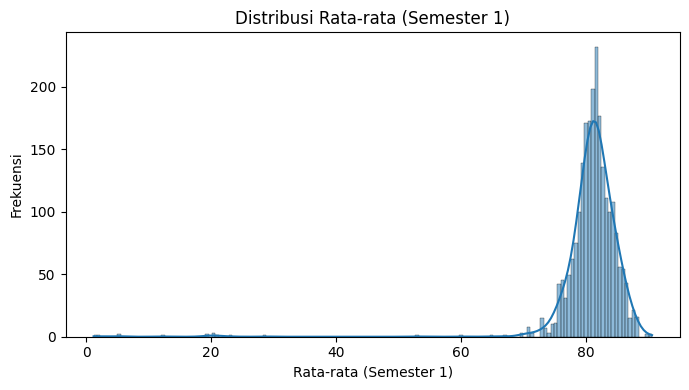

Memeriksa kolom: Rata-rata (Semester 2)


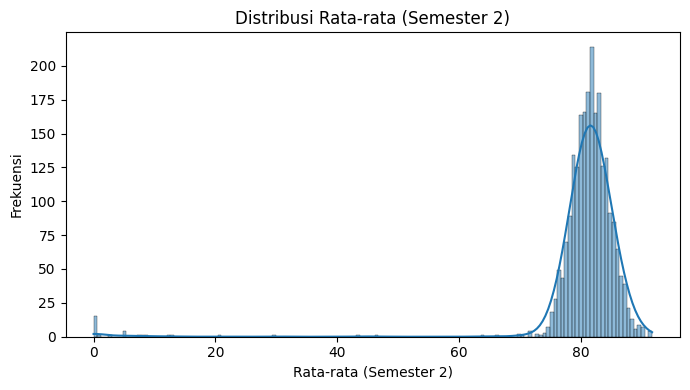

Memeriksa kolom: Rata-rata (Semester 3)


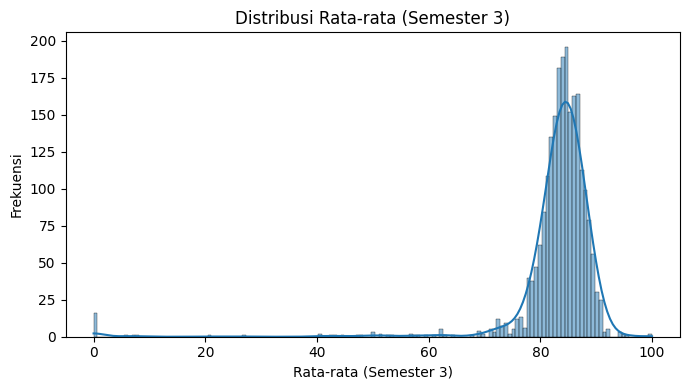

Memeriksa kolom: Rata-rata (Semester 4)


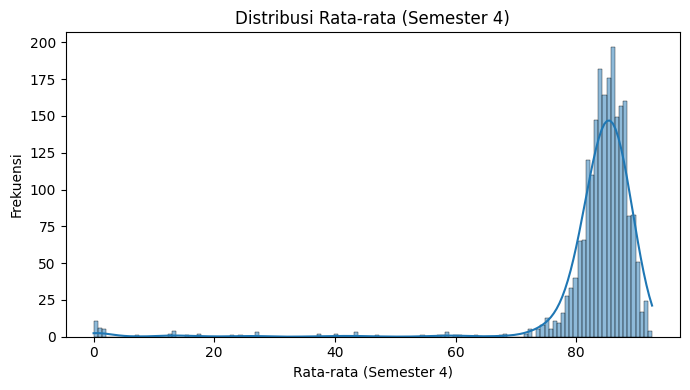

Memeriksa kolom: Rata-rata (Semester 5)


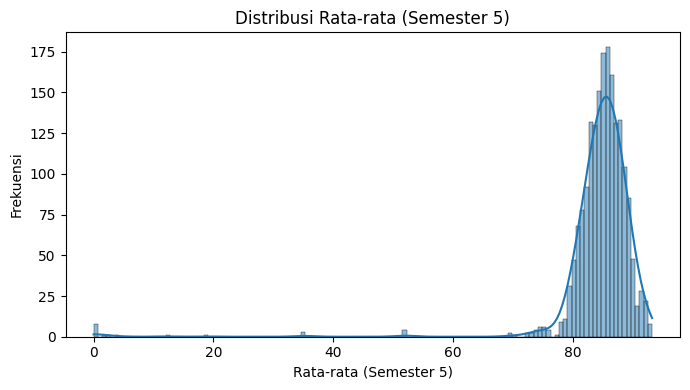

Memeriksa kolom: Rata-rata (Semester 6)


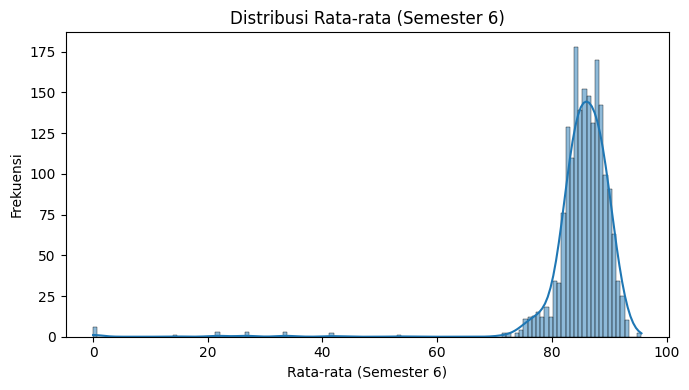

Memeriksa kolom: Rata-rata (Keseluruhan)


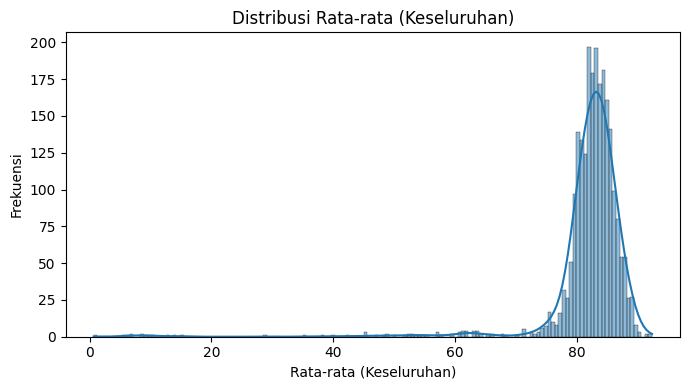

Memeriksa kolom: Rangking (per jurusan)


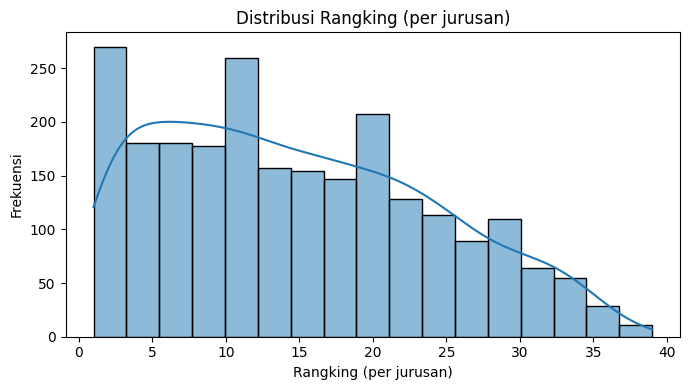

Memeriksa kolom: Rangking (keseluruhan)


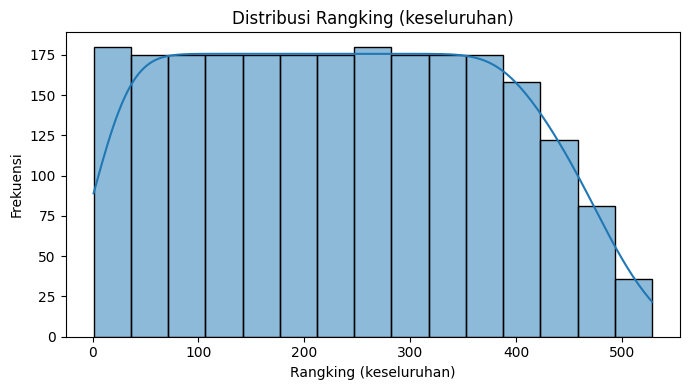

Memeriksa kolom: Nilai Kelas 8 Semester 1


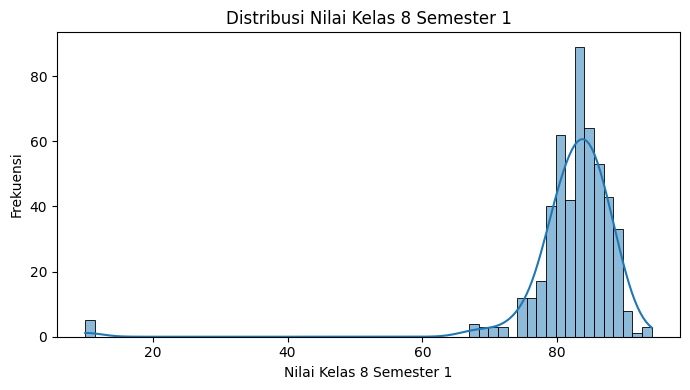

Memeriksa kolom: Nilai Kelas 8 Semester 2


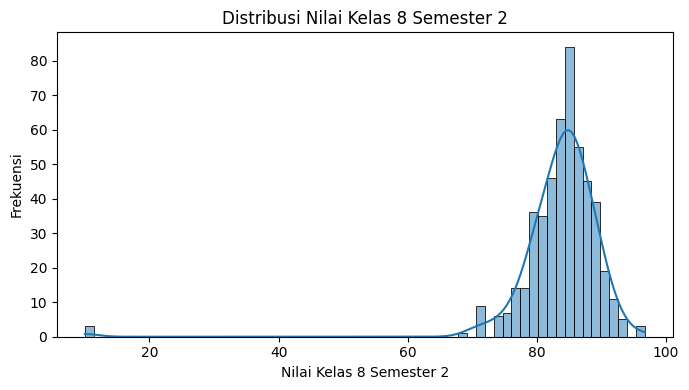

Memeriksa kolom: Nilai Kelas 9 Semester 1


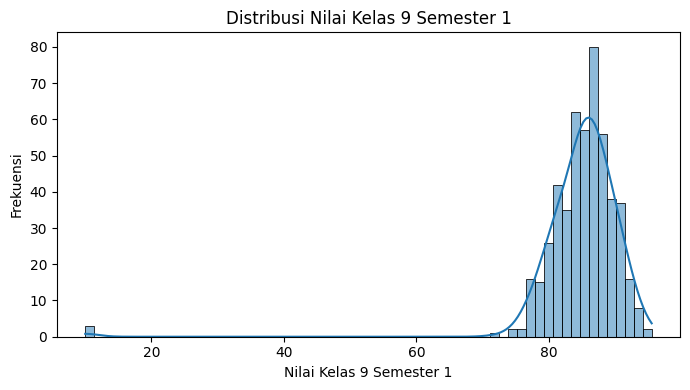

Memeriksa kolom: Nilai Teori Agama


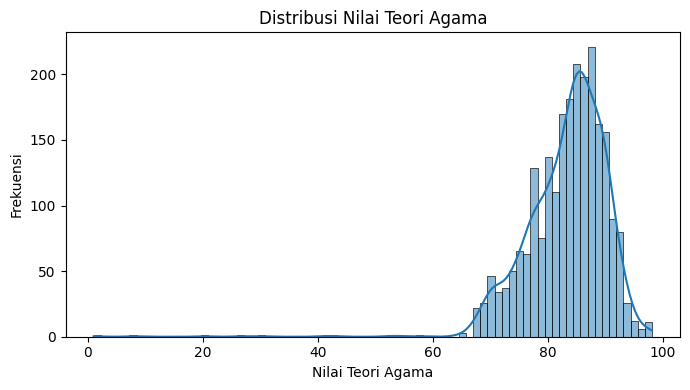

Memeriksa kolom: Nilai Praktik Agama


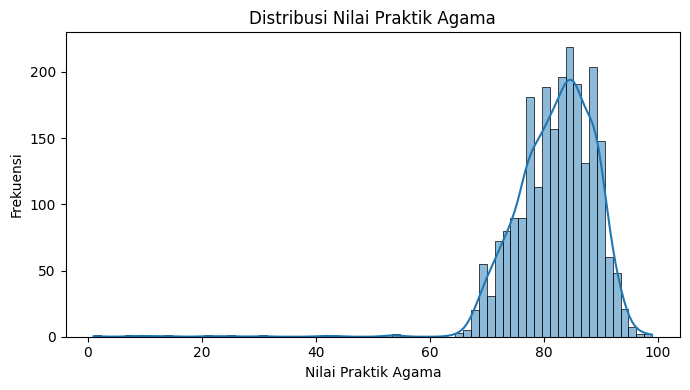

Memeriksa kolom: Nilai PKN


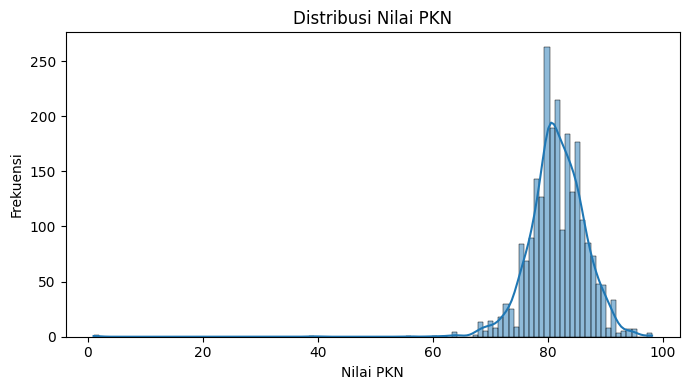

Memeriksa kolom: Nilai IPS


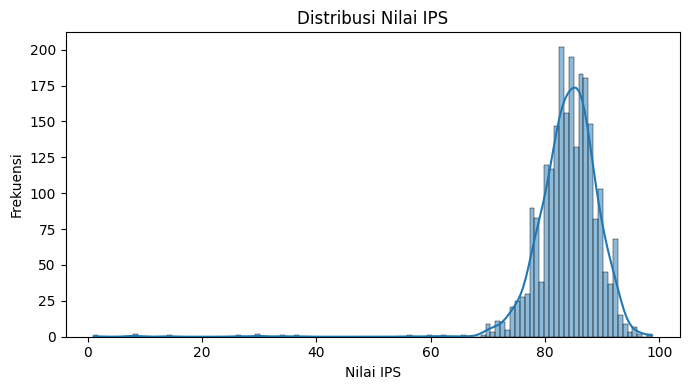

Memeriksa kolom: Nilai Teori Kesenian


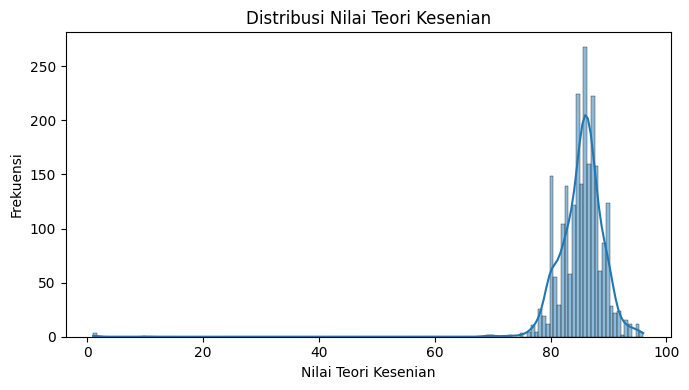

Memeriksa kolom: Nilai Praktik Kesenian


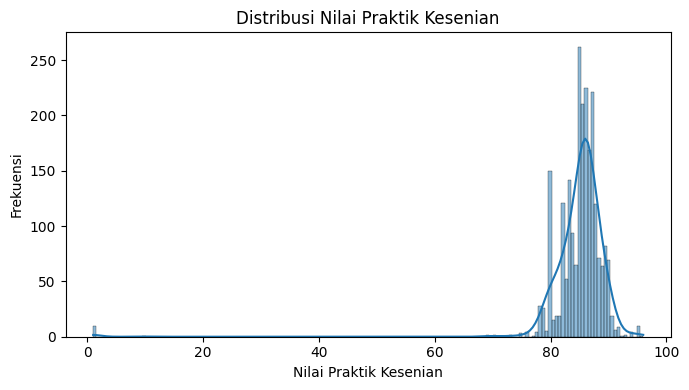

Memeriksa kolom: Nilai Teori TIK


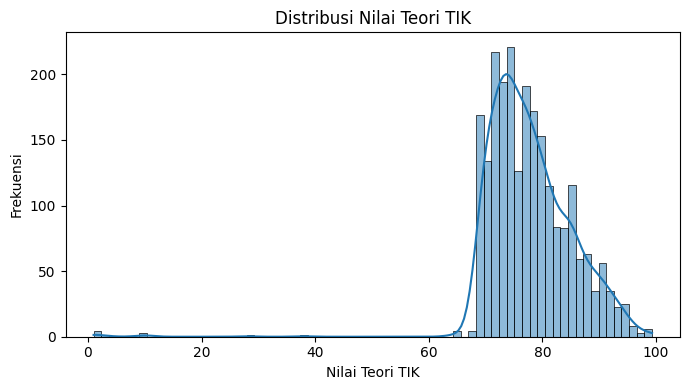

Memeriksa kolom: Nilai Praktik TIK


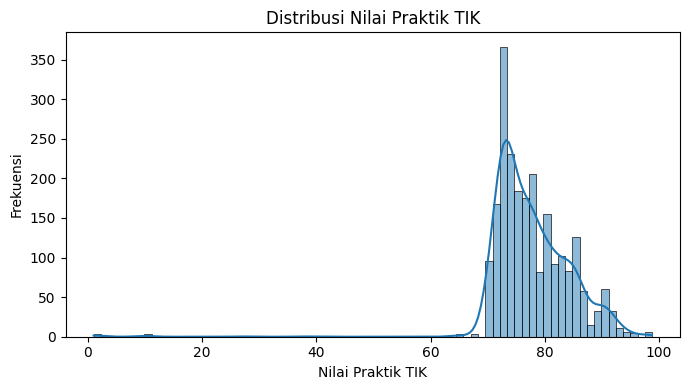

Memeriksa kolom: Nilai Teori Budaya


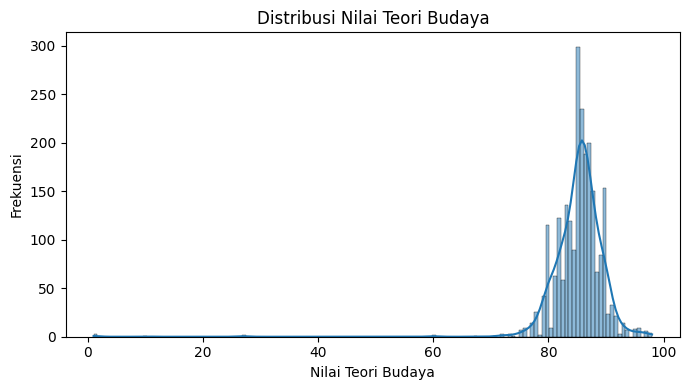

Memeriksa kolom: Nilai Praktik Budaya


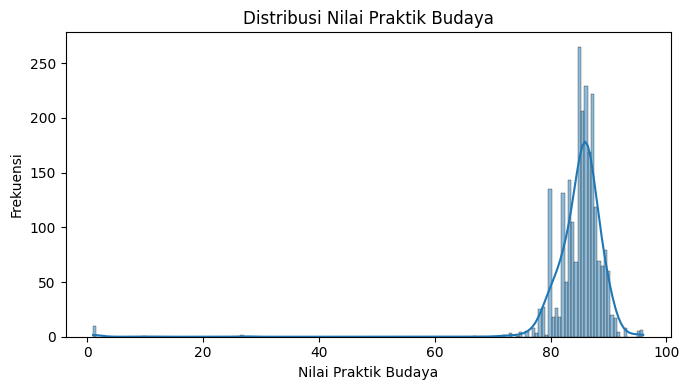

Memeriksa kolom: Nilai Bahasa Indonesia


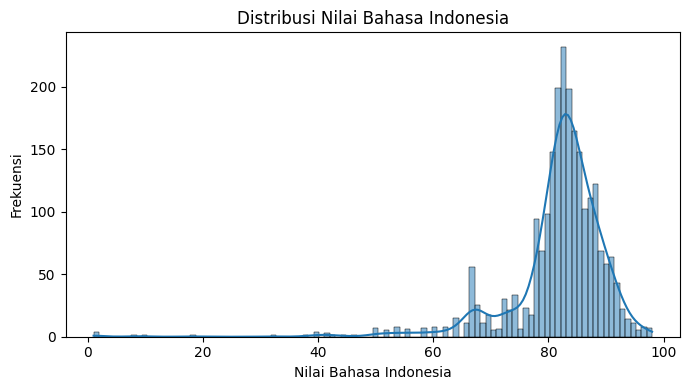

Memeriksa kolom: Nilai Matematika


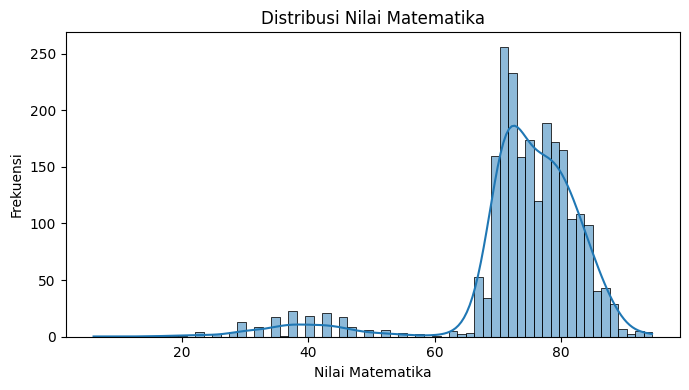

Memeriksa kolom: Nilai Bahasa Inggris


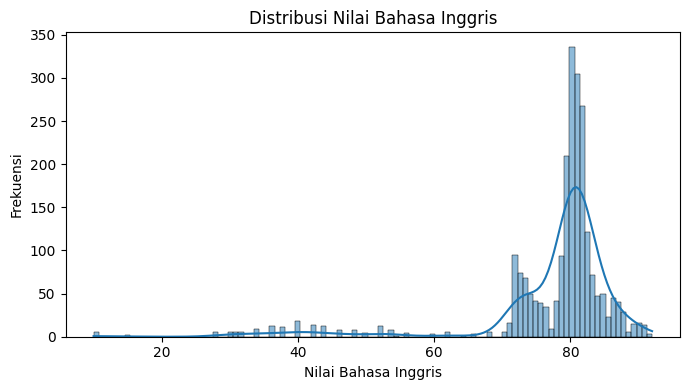

Memeriksa kolom: Nilai IPA


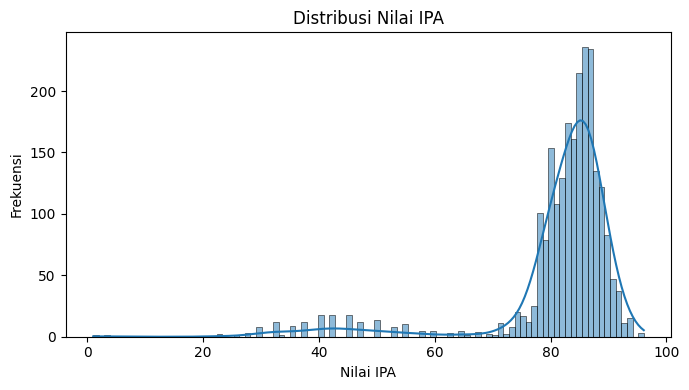

Memeriksa kolom: Rata-rata Mapel Masuk


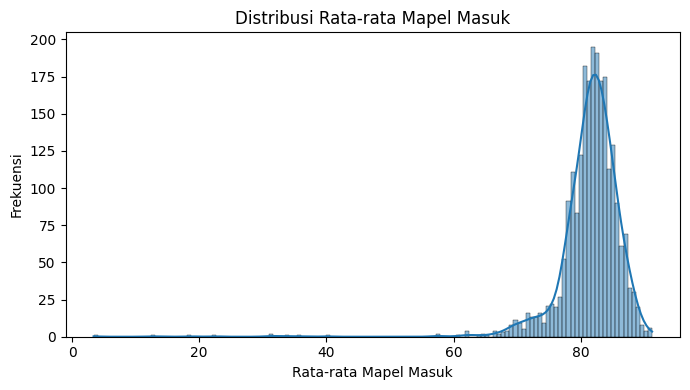

Memeriksa kolom: Rangking Mapel Masuk


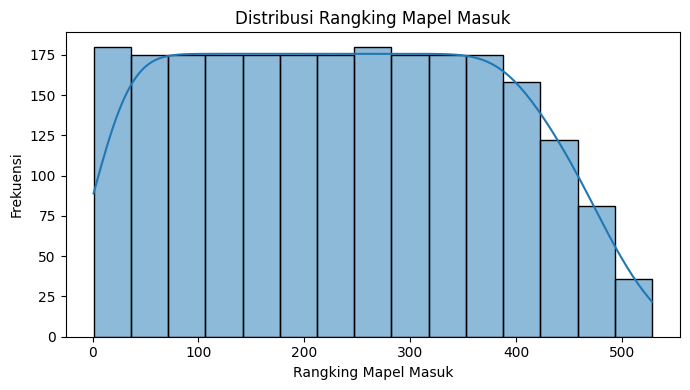

Memeriksa kolom: Jarak ()


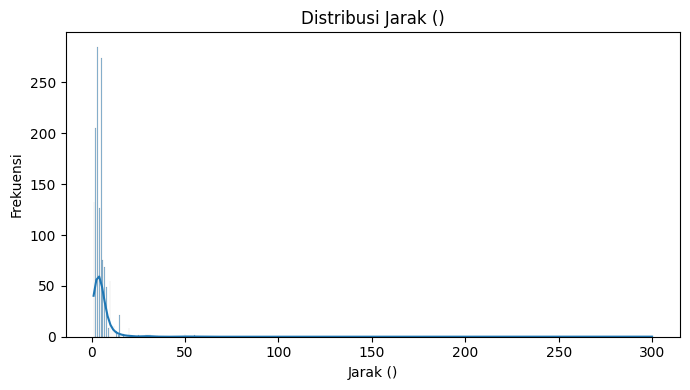

DISTRIBUSI ATRIBUT KATEGORIKAL

Distribusi Jenis Kelamin


,Jenis Kelamin,Jumlah
0,Laki-laki,1208
1,Perempuan,1124


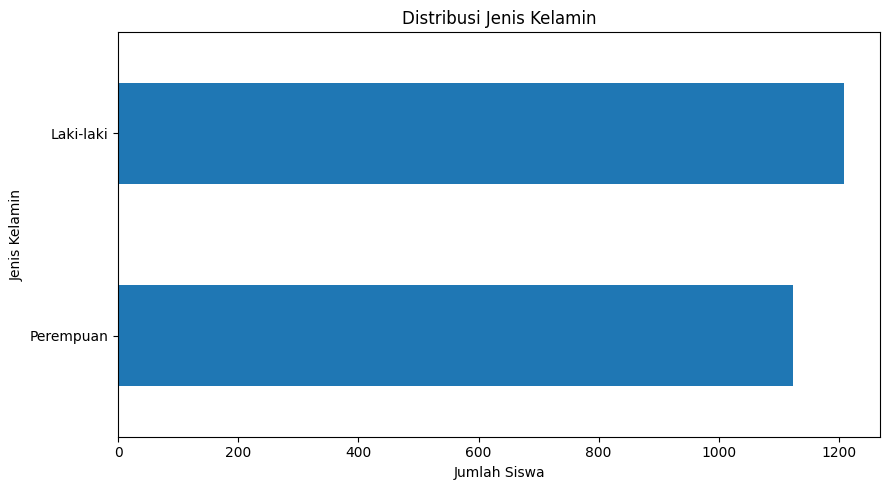


Distribusi Kelas


,Kelas,Jumlah
0,10 Akuntansi dan Keuangan Lembaga,159
1,11 Rekayasa Perangkat Lunak,149
2,12 Rekayasa Perangkat Lunak,149
3,10 Pengembangan Perangkat Lunak dan Gim,110
4,10 Manajemen Perkantoran dan Layanan Bisnis,109
5,11 Akuntansi,94
6,12 Teknik Komputer dan Jaringan,93
7,11 Manajemen Perkantoran,72
8,11 Akuntansi dan Keuangan Lembaga,71
9,11 Teknik Komputer dan Jaringan,71


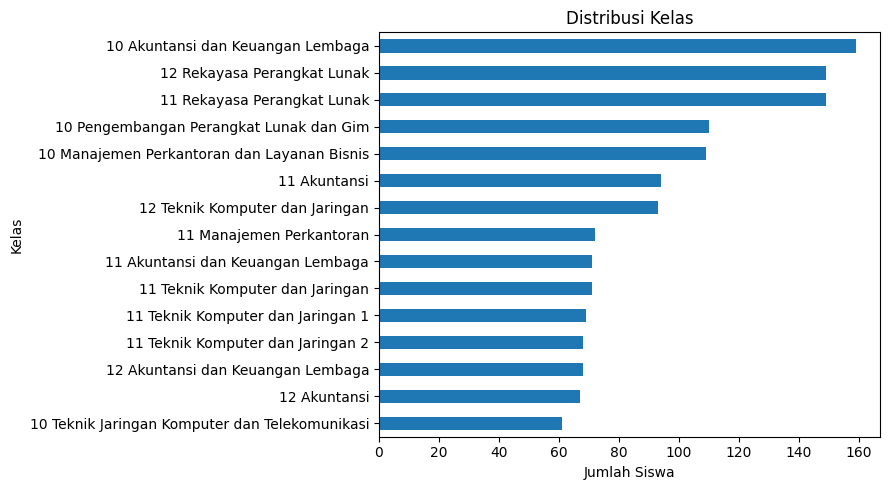


Distribusi Tingkat


,Tingkat,Jumlah
0,12,808
1,11,781
2,10,743


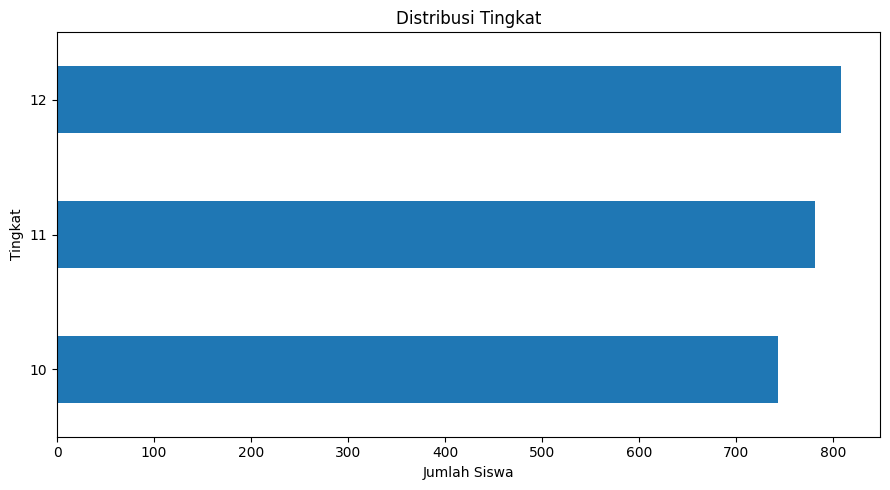


Distribusi Asal Sekolah


,Asal Sekolah,Jumlah
0,SMPN 7 Pekanbaru,121
1,SMPN 11 Pekanbaru,93
2,SMPN 14 Pekanbaru,85
3,SMPN 10 Pekanbaru,79
4,SMPN 13 Pekanbaru,70
...,...,...
428,MTsS Al Marzuqin Pekanbaru,1
429,SMP Negeri 27 Pekanbaru,1
430,Pondok Pesantren Salafiyyah Syekh Muhammad Djamil Jaho,1
431,UPT SMPN 1 Perhentian Raja,1


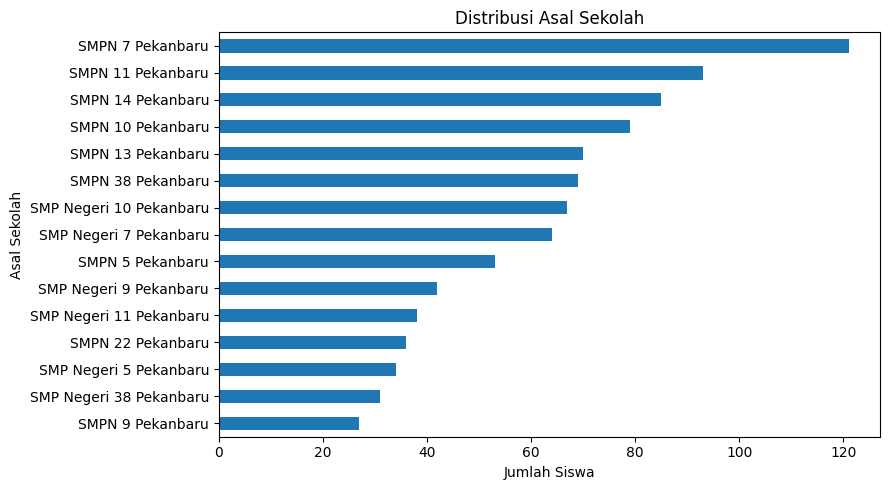


Distribusi Pekerjaan Ayah


,Pekerjaan Ayah,Jumlah
0,Wiraswasta,536
1,Karyawan Swasta,517
2,Buruh,298
3,Lain - lain,266
4,Dosen PNS,224
5,Pedagang,129
6,PNS PEMDA,69
7,Petani,68
8,-,68
9,Wirausaha,39


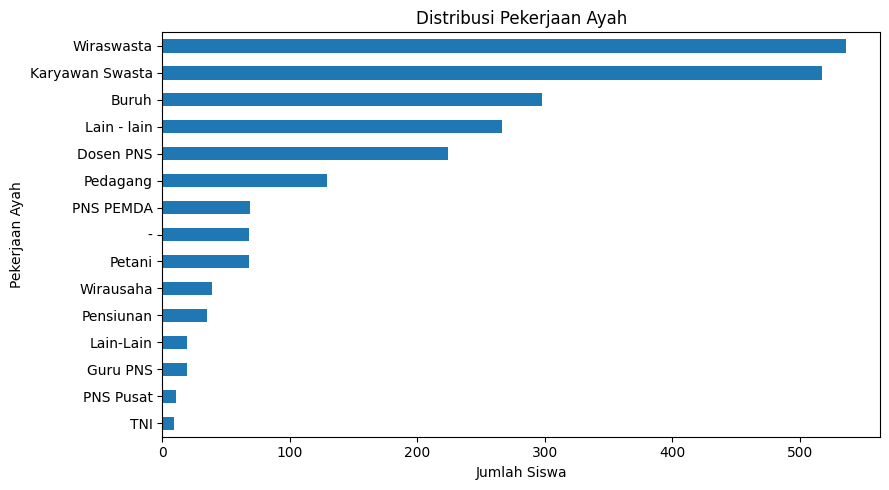


Distribusi Pekerjaan Ibu


,Pekerjaan Ibu,Jumlah
0,IRT,966
1,Dosen PNS,625
2,Karyawan Swasta,125
3,Pedagang,120
4,Lain-Lain,112
5,Lain - lain,101
6,Wiraswasta,75
7,Guru PNS,43
8,-,35
9,Guru Swasta,31


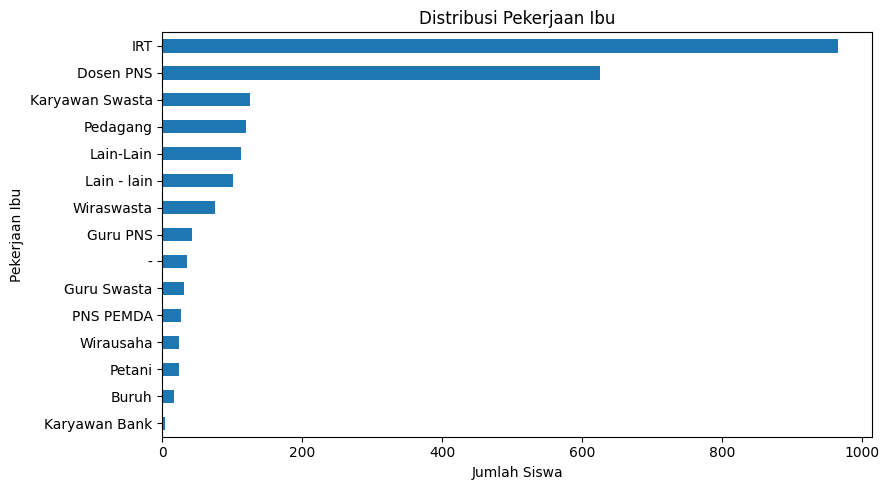


Distribusi Ekstrakurikuler


,Ekstrakurikuler,Jumlah
0,Sangat Baik,855
1,Baik,748
2,-,680
3,Cukup,49


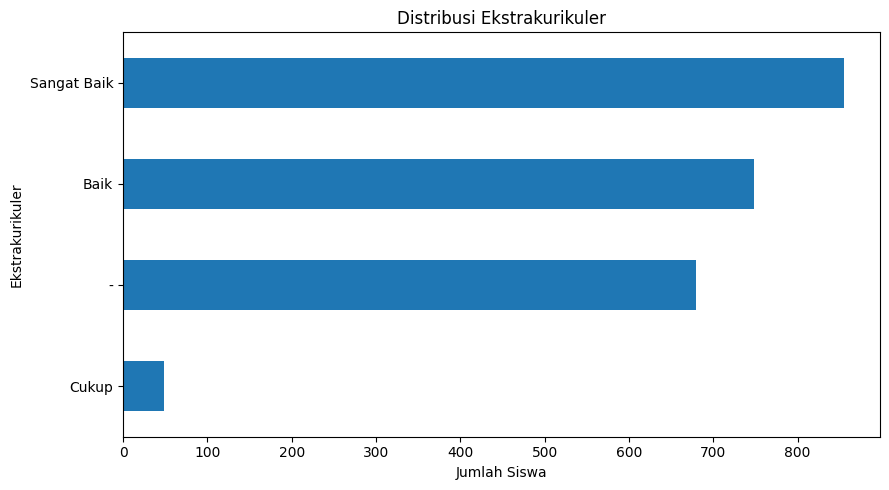


Distribusi Kokurikuler


,Kokurikuler,Jumlah
0,-,1027
1,Mahir,844
2,Cakap,410
3,Berkembang,50
4,Baik,1


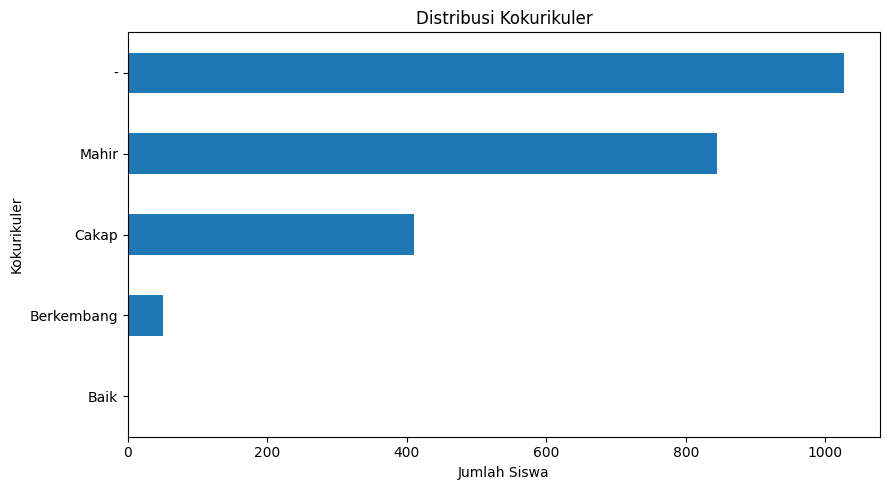


Distribusi Tahun Ajaran


,Tahun Ajaran,Jumlah
0,2021-2022 (3),528
1,2022-2023 (3),485
2,2023-2024 (3),475
3,2024-2025 (3),439
4,2025-2026 (3),405


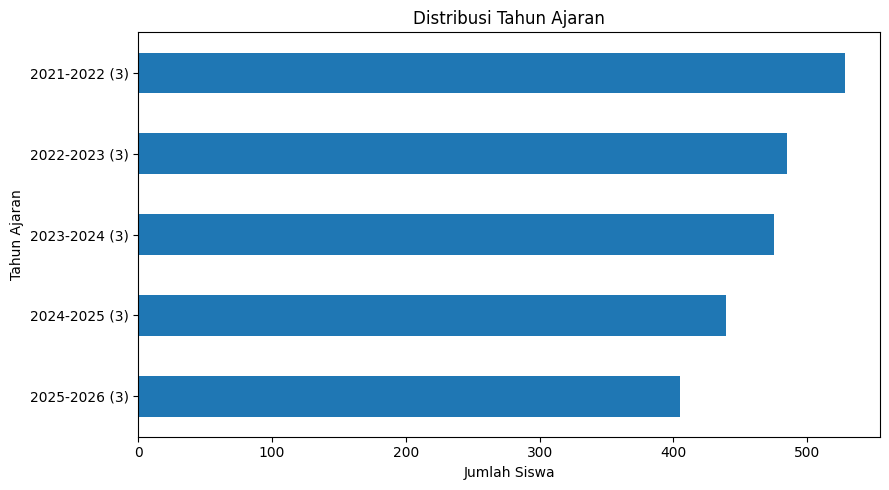

In [ ]:
#Distibusi atribut

import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Semua atribut yang akan dianalisis distribusinya
kolom_numerik = [
    "Rata-rata (Semester 1)",
    "Rata-rata (Semester 2)",
    "Rata-rata (Semester 3)",
    "Rata-rata (Semester 4)",
    "Rata-rata (Semester 5)",
    "Rata-rata (Semester 6)",
    "Rata-rata (Keseluruhan)",
    "Rangking (per jurusan)",
    "Rangking (keseluruhan)",
    "Nilai Kelas 8 Semester 1",
    "Nilai Kelas 8 Semester 2",
    "Nilai Kelas 9 Semester 1",
    "Nilai Teori Agama",
    "Nilai Praktik Agama",
    "Nilai PKN",
    "Nilai IPS",
    "Nilai Teori Kesenian",
    "Nilai Praktik Kesenian",
    "Nilai Teori TIK",
    "Nilai Praktik TIK",
    "Nilai Teori Budaya",
    "Nilai Praktik Budaya",
    "Nilai Bahasa Indonesia",
    "Nilai Matematika",
    "Nilai Bahasa Inggris",
    "Nilai IPA",
    "Rata-rata Mapel Masuk",
    "Rangking Mapel Masuk",
    "Jarak ()"
]

kolom_kategorikal = [
    "Jenis Kelamin",
    "Kelas",
    "Tingkat",
    "Asal Sekolah",
    "Pekerjaan Ayah",
    "Pekerjaan Ibu",
    "Ekstrakurikuler",
    "Kokurikuler",
    "Tahun Ajaran"
]

# Hanya menggunakan kolom yang tersedia
kolom_numerik = [
    k for k in kolom_numerik if k in data.columns
]
kolom_kategorikal = [
    k for k in kolom_kategorikal if k in data.columns
]

# 1. Distribusi seluruh atribut numerik
print("DISTRIBUSI ATRIBUT NUMERIK")

for kolom in kolom_numerik:
    print(f"Memeriksa kolom: {kolom}")

    # Konversi nilai menjadi numerik untuk keperluan grafik
    nilai = pd.to_numeric(data[kolom], errors="coerce").dropna()

    if nilai.empty:
        print(f"Kolom {kolom} tidak memiliki nilai numerik.")
        continue

    plt.figure(figsize=(7, 4))
    sns.histplot(x=nilai, kde=True)
    plt.title(f"Distribusi {kolom}")
    plt.xlabel(str(kolom))
    plt.ylabel("Frekuensi")
    plt.tight_layout()
    plt.show()


# 2. Distribusi seluruh atribut kategorikal
print("DISTRIBUSI ATRIBUT KATEGORIKAL")

for kolom in kolom_kategorikal:
    print(f"\nDistribusi {kolom}")

    frekuensi = (
        data[kolom]
        .fillna("Data kosong")
        .value_counts()
    )

    display(
        frekuensi.rename_axis(kolom)
        .reset_index(name="Jumlah")
    )

    # Maksimal 15 kategori pada grafik agar tetap terbaca
    frekuensi_plot = frekuensi.head(15).sort_values()

    plt.figure(figsize=(9, 5))
    frekuensi_plot.plot(kind="barh")
    plt.title(f"Distribusi {kolom}")
    plt.xlabel("Jumlah Siswa")
    plt.ylabel(kolom)
    plt.tight_layout()
    plt.show()


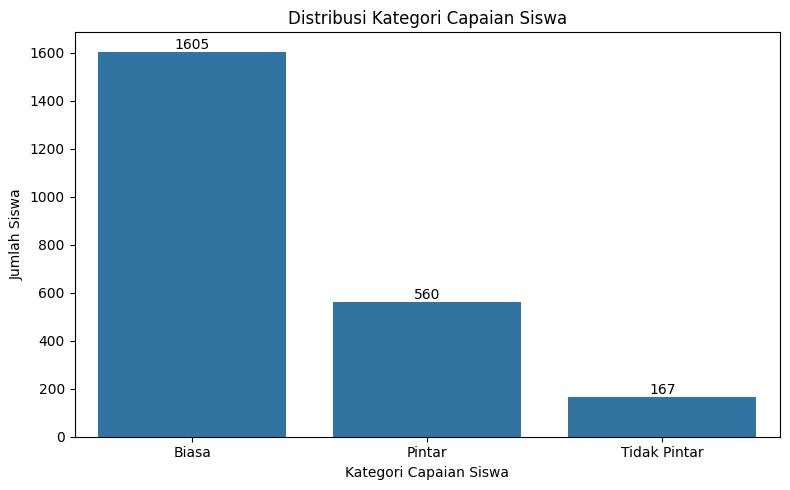

In [ ]:
# Visualisasi distribusi kategori capaian siswa

plt.figure(figsize=(8, 5))

ax = sns.countplot(
    data=data,
    x="Ketgori Capaian Siswa",
    order=["Biasa", "Pintar", "Tidak Pintar"]
)

# Menampilkan jumlah siswa di atas setiap batang
for batang in ax.patches:
    tinggi = batang.get_height()
    if tinggi > 0:
        ax.annotate(
            f"{int(tinggi)}",
            (batang.get_x() + batang.get_width() / 2, tinggi),
            ha="center",
            va="bottom",
            fontsize=10
        )

plt.title("Distribusi Kategori Capaian Siswa")
plt.xlabel("Kategori Capaian Siswa")
plt.ylabel("Jumlah Siswa")
plt.tight_layout()
plt.show()


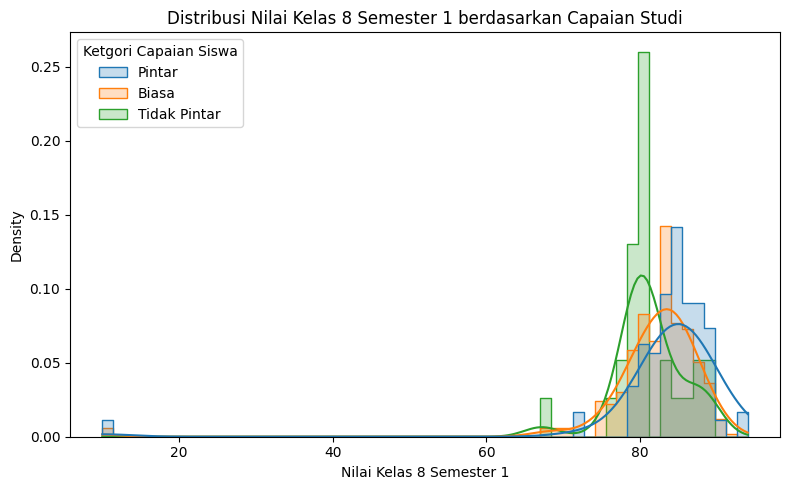

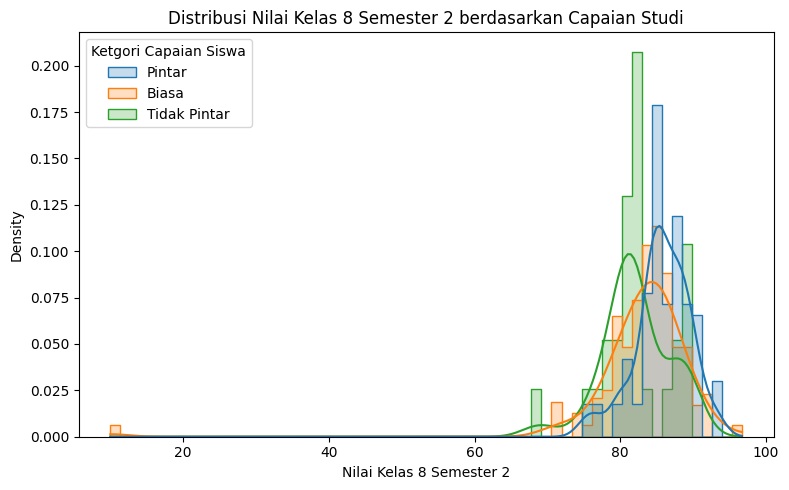

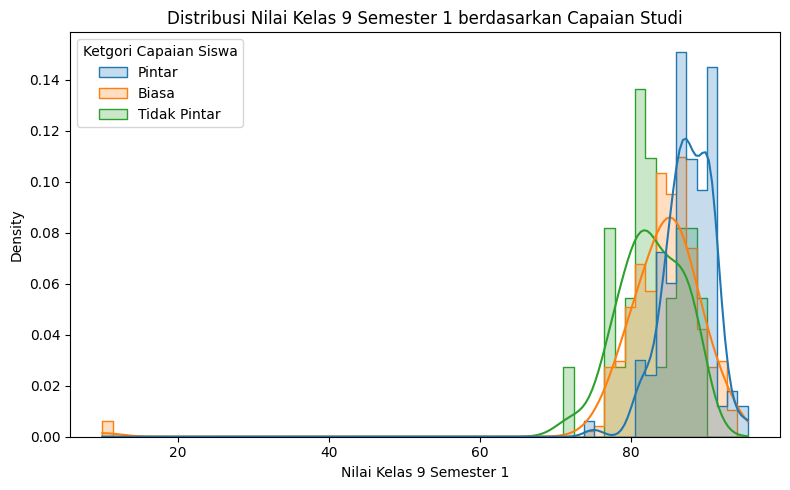

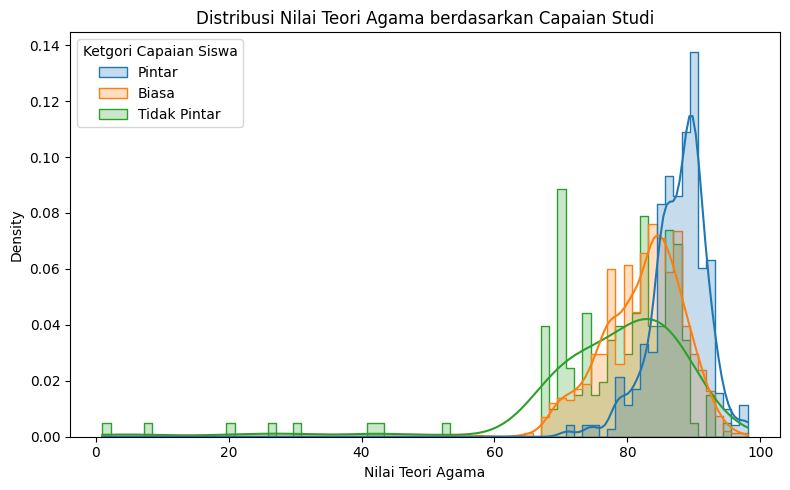

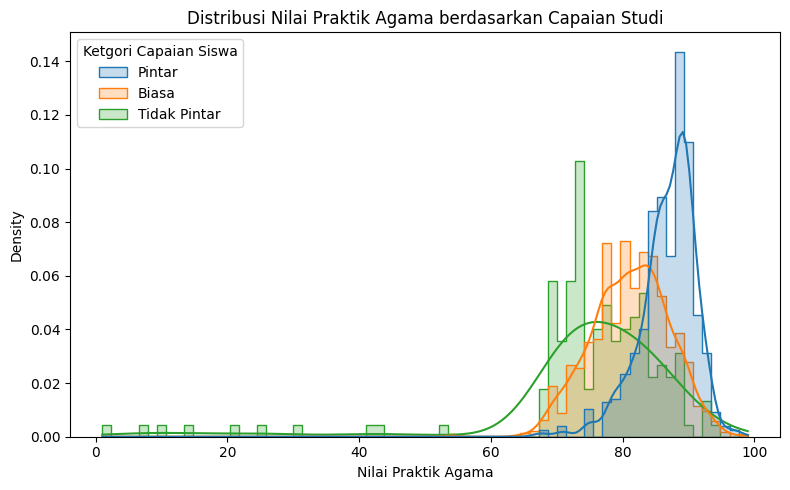

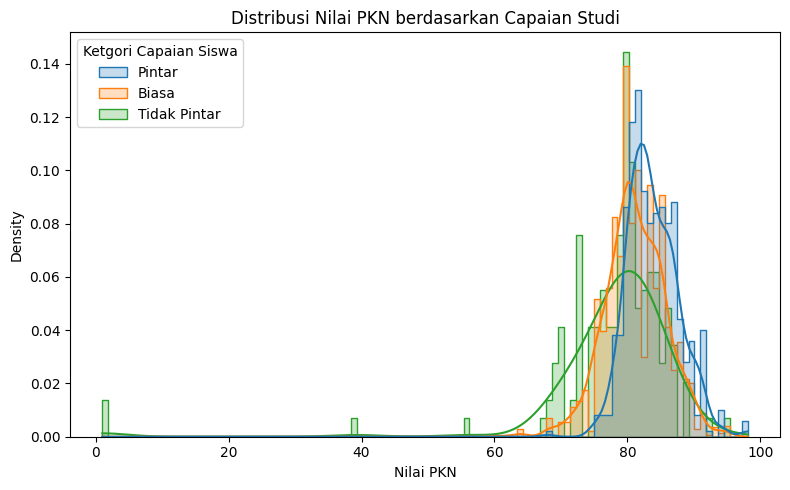

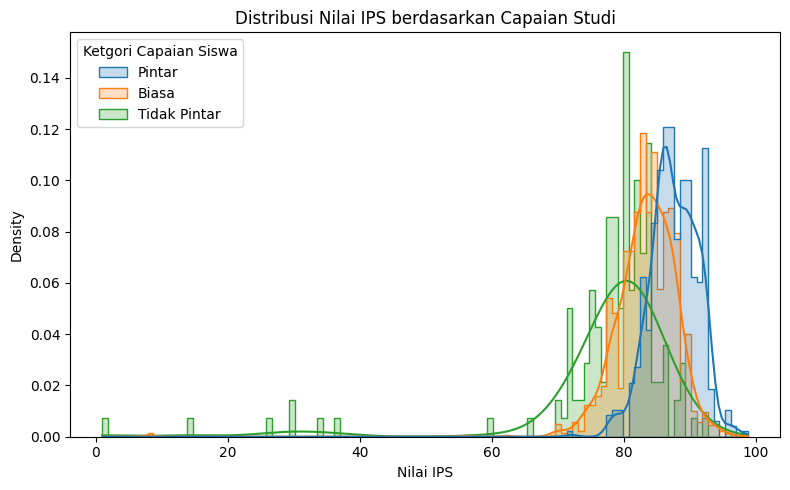

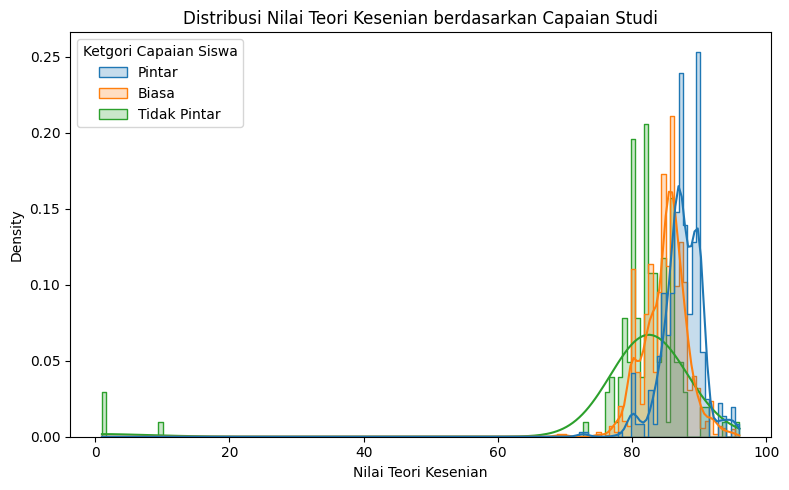

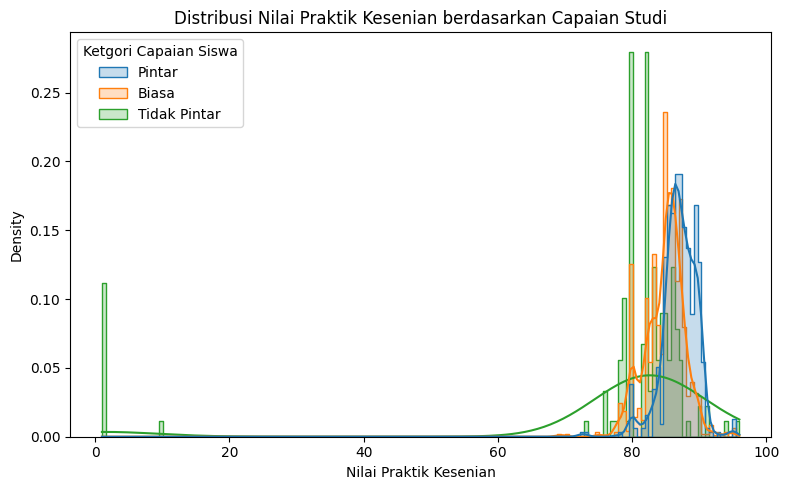

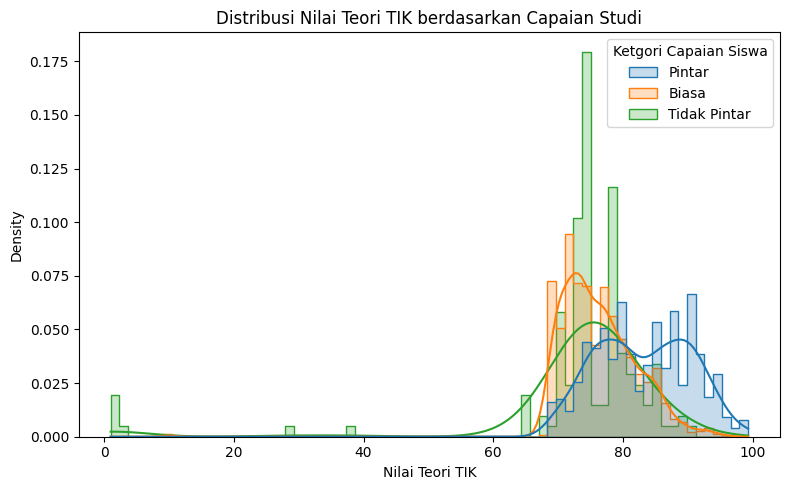

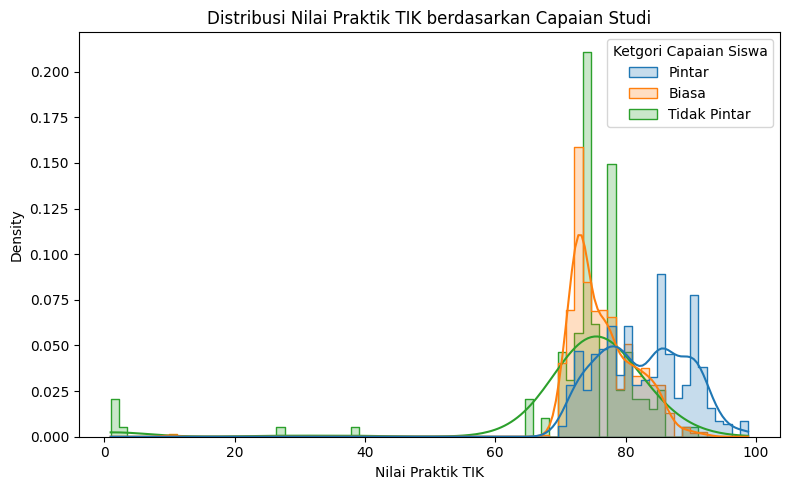

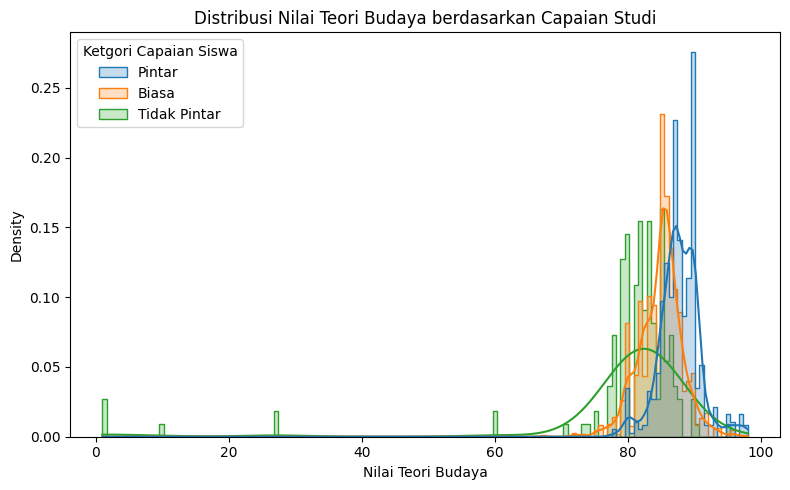

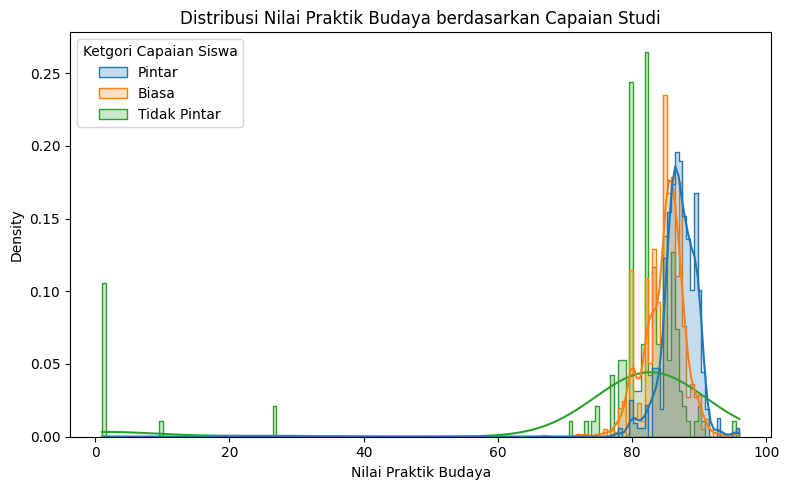

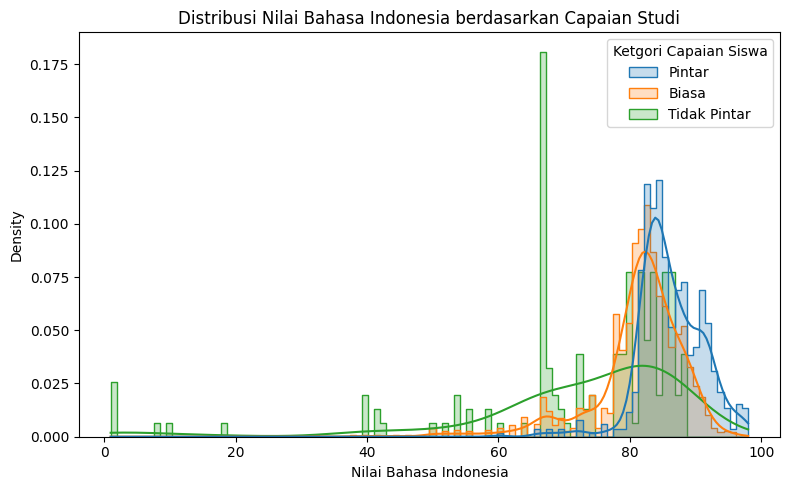

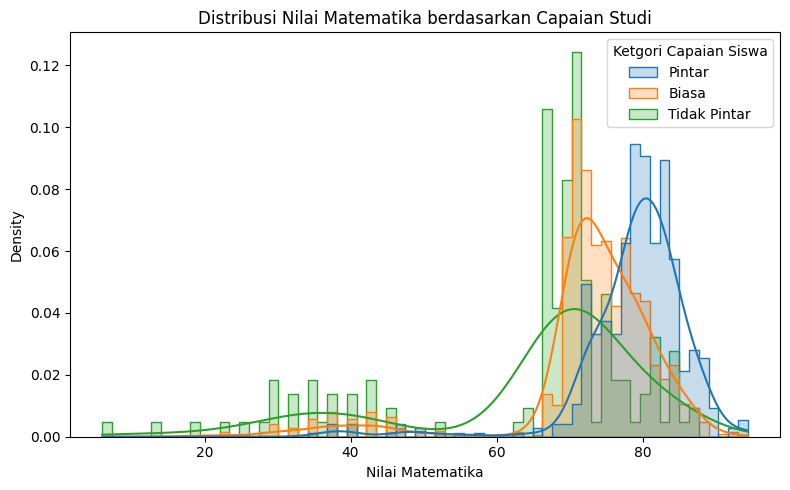

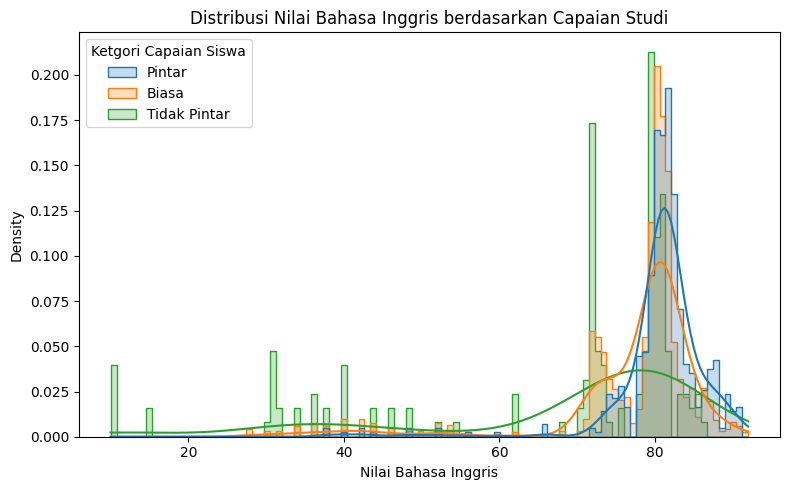

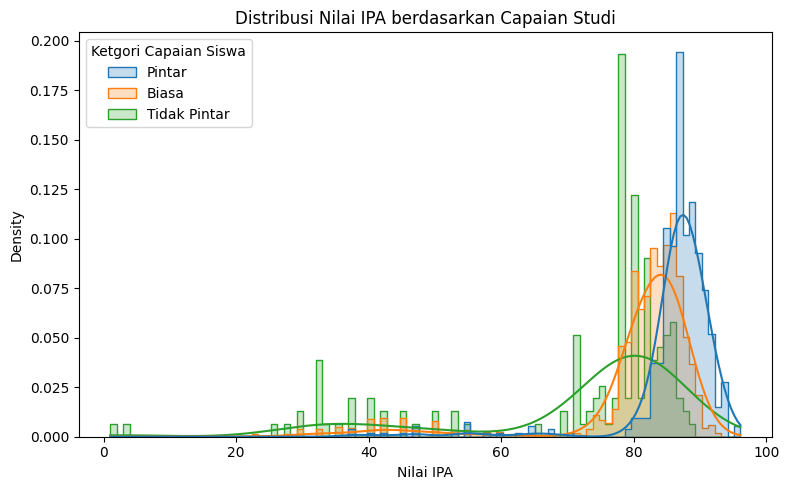

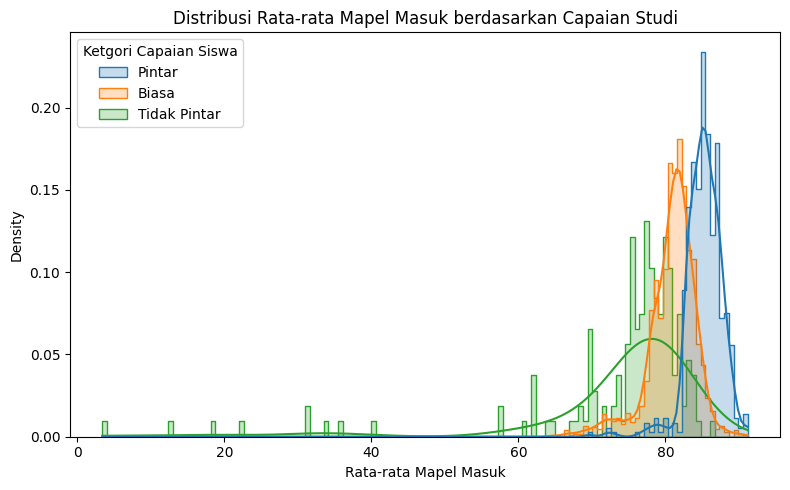

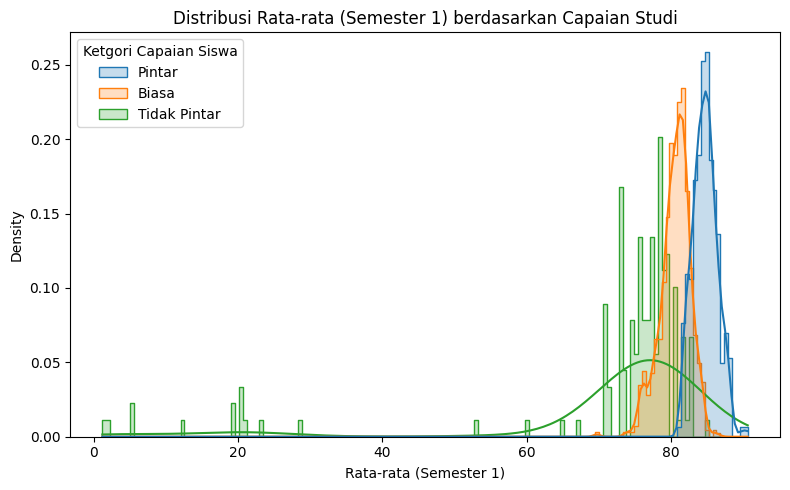

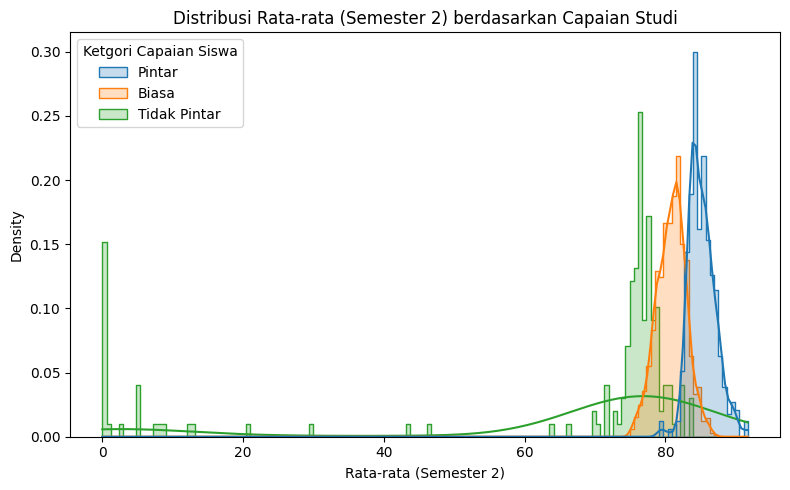

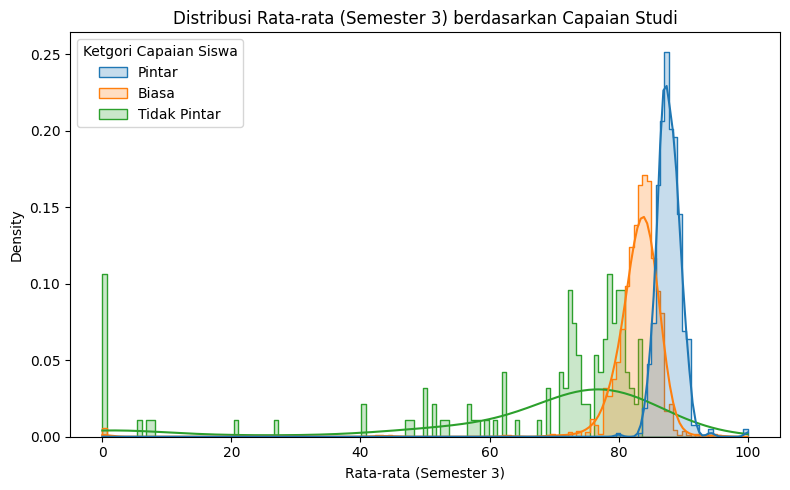

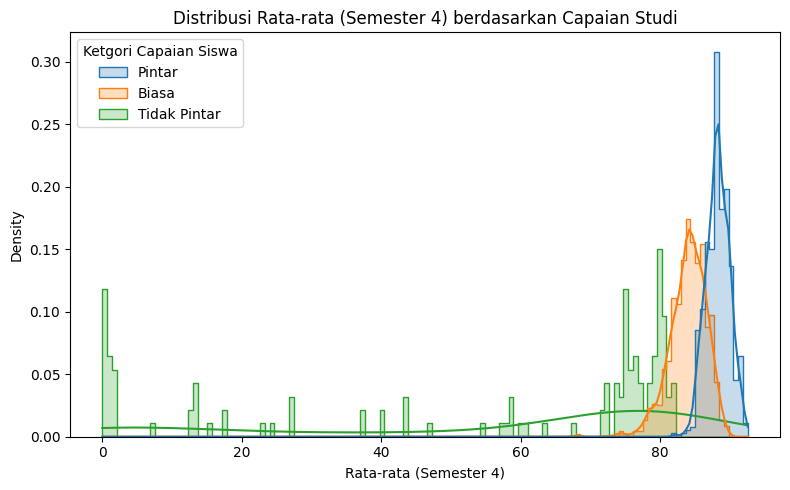

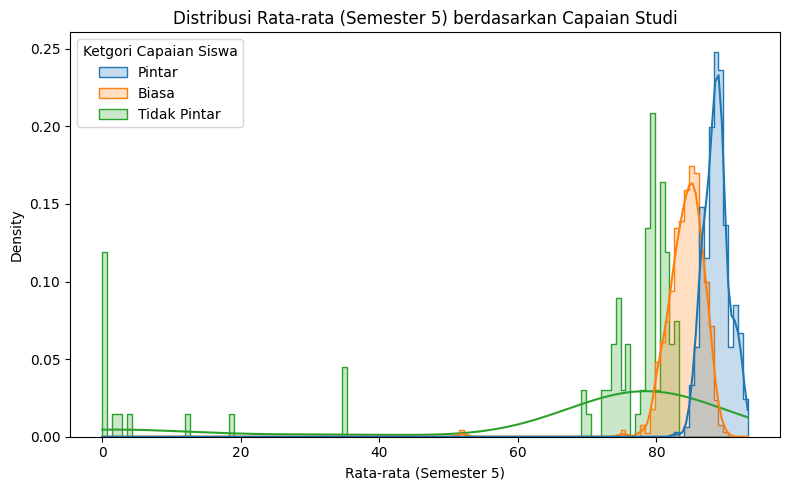

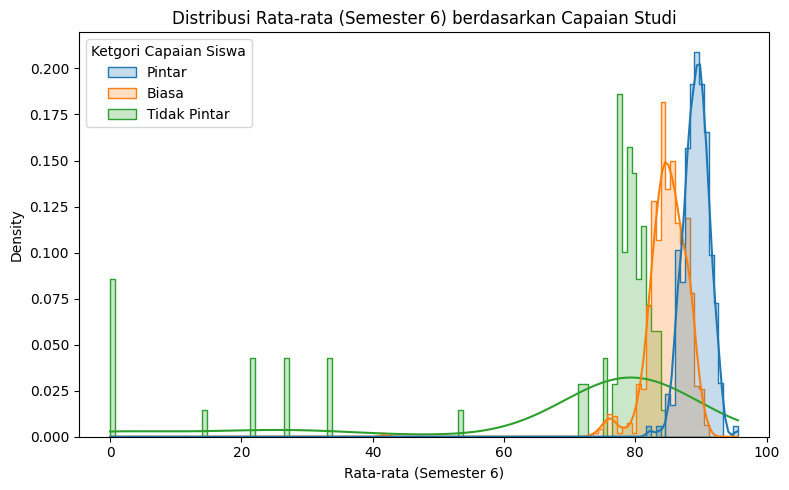

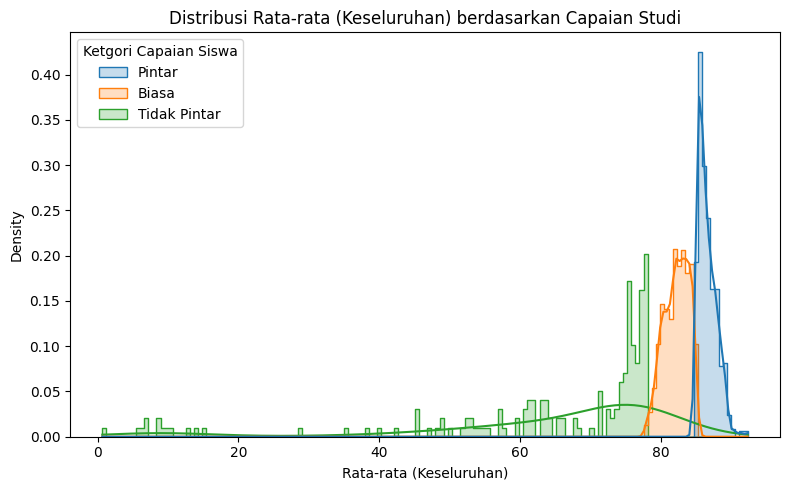

,Atribut,Kelas Capaian,Jumlah Data,Skewness,Kurtosis
0,Nilai Kelas 8 Semester 1,Pintar,124,-6.262,44.070
1,Nilai Kelas 8 Semester 1,Biasa,346,-6.482,55.865
2,Nilai Kelas 8 Semester 1,Tidak Pintar,27,-0.652,2.997
3,Nilai Kelas 8 Semester 2,Pintar,122,-0.637,0.679
4,Nilai Kelas 8 Semester 2,Biasa,345,-6.270,54.126
5,Nilai Kelas 8 Semester 2,Tidak Pintar,28,-0.448,1.311
6,Nilai Kelas 9 Semester 1,Pintar,122,-0.568,1.303
7,Nilai Kelas 9 Semester 1,Biasa,349,-7.033,64.177
8,Nilai Kelas 9 Semester 1,Tidak Pintar,27,-0.389,-0.173
9,Nilai Teori Agama,Pintar,560,-0.765,1.603


In [ ]:
# Distribusi atribut numerik terhadap kategori capaian studi

kolom_target = "Ketgori Capaian Siswa"

# Atribut numerik yang dianalisis
kolom_numerik = [
    "Nilai Kelas 8 Semester 1",
    "Nilai Kelas 8 Semester 2",
    "Nilai Kelas 9 Semester 1",
    "Nilai Teori Agama",
    "Nilai Praktik Agama",
    "Nilai PKN",
    "Nilai IPS",
    "Nilai Teori Kesenian",
    "Nilai Praktik Kesenian",
    "Nilai Teori TIK",
    "Nilai Praktik TIK",
    "Nilai Teori Budaya",
    "Nilai Praktik Budaya",
    "Nilai Bahasa Indonesia",
    "Nilai Matematika",
    "Nilai Bahasa Inggris",
    "Nilai IPA",
    "Rata-rata Mapel Masuk",
    "Rata-rata (Semester 1)",
    "Rata-rata (Semester 2)",
    "Rata-rata (Semester 3)",
    "Rata-rata (Semester 4)",
    "Rata-rata (Semester 5)",
    "Rata-rata (Semester 6)",
    "Rata-rata (Keseluruhan)",
    "Jarak ()"
]

# Hanya gunakan kolom yang tersedia di dataset
kolom_numerik = [
    k for k in kolom_numerik
    if k in data.columns
    and pd.api.types.is_numeric_dtype(data[k])
]

# Urutan kategori sesuai label asli dataset
urutan_target = ["Pintar", "Biasa", "Tidak Pintar"]

# Pastikan kolom target tersedia
if kolom_target not in data.columns:
    raise ValueError(f"Kolom '{kolom_target}' tidak ditemukan dalam data.")

# 1. Histogram dan KDE setiap atribut berdasarkan kategori capaian studi
for kolom in kolom_numerik:
    df_plot = data[[kolom, kolom_target]].dropna()

    if df_plot.empty:
        continue

    plt.figure(figsize=(8, 5))
    sns.histplot(
        data=df_plot,
        x=kolom,
        hue=kolom_target,
        hue_order=urutan_target,
        kde=True,
        stat="density",
        common_norm=False,
        element="step",
        alpha=0.25
    )

    plt.title(f"Distribusi {kolom} berdasarkan Capaian Studi")
    plt.xlabel(kolom)
    plt.ylabel("Density")
    plt.tight_layout()
    plt.show()

# 2. Menghitung skewness dan kurtosis setiap kelas
hasil_bentuk_distribusi = []

for kolom in kolom_numerik:
    for kategori in urutan_target:
        nilai = data.loc[
            data[kolom_target] == kategori, kolom
        ].dropna()

        hasil_bentuk_distribusi.append({
            "Atribut": kolom,
            "Kelas Capaian": kategori,
            "Jumlah Data": len(nilai),
            "Skewness": nilai.skew() if len(nilai) >= 3 else None,
            "Kurtosis": nilai.kurt() if len(nilai) >= 4 else None
        })

tabel_bentuk_distribusi = pd.DataFrame(hasil_bentuk_distribusi)

display(tabel_bentuk_distribusi.round(3))

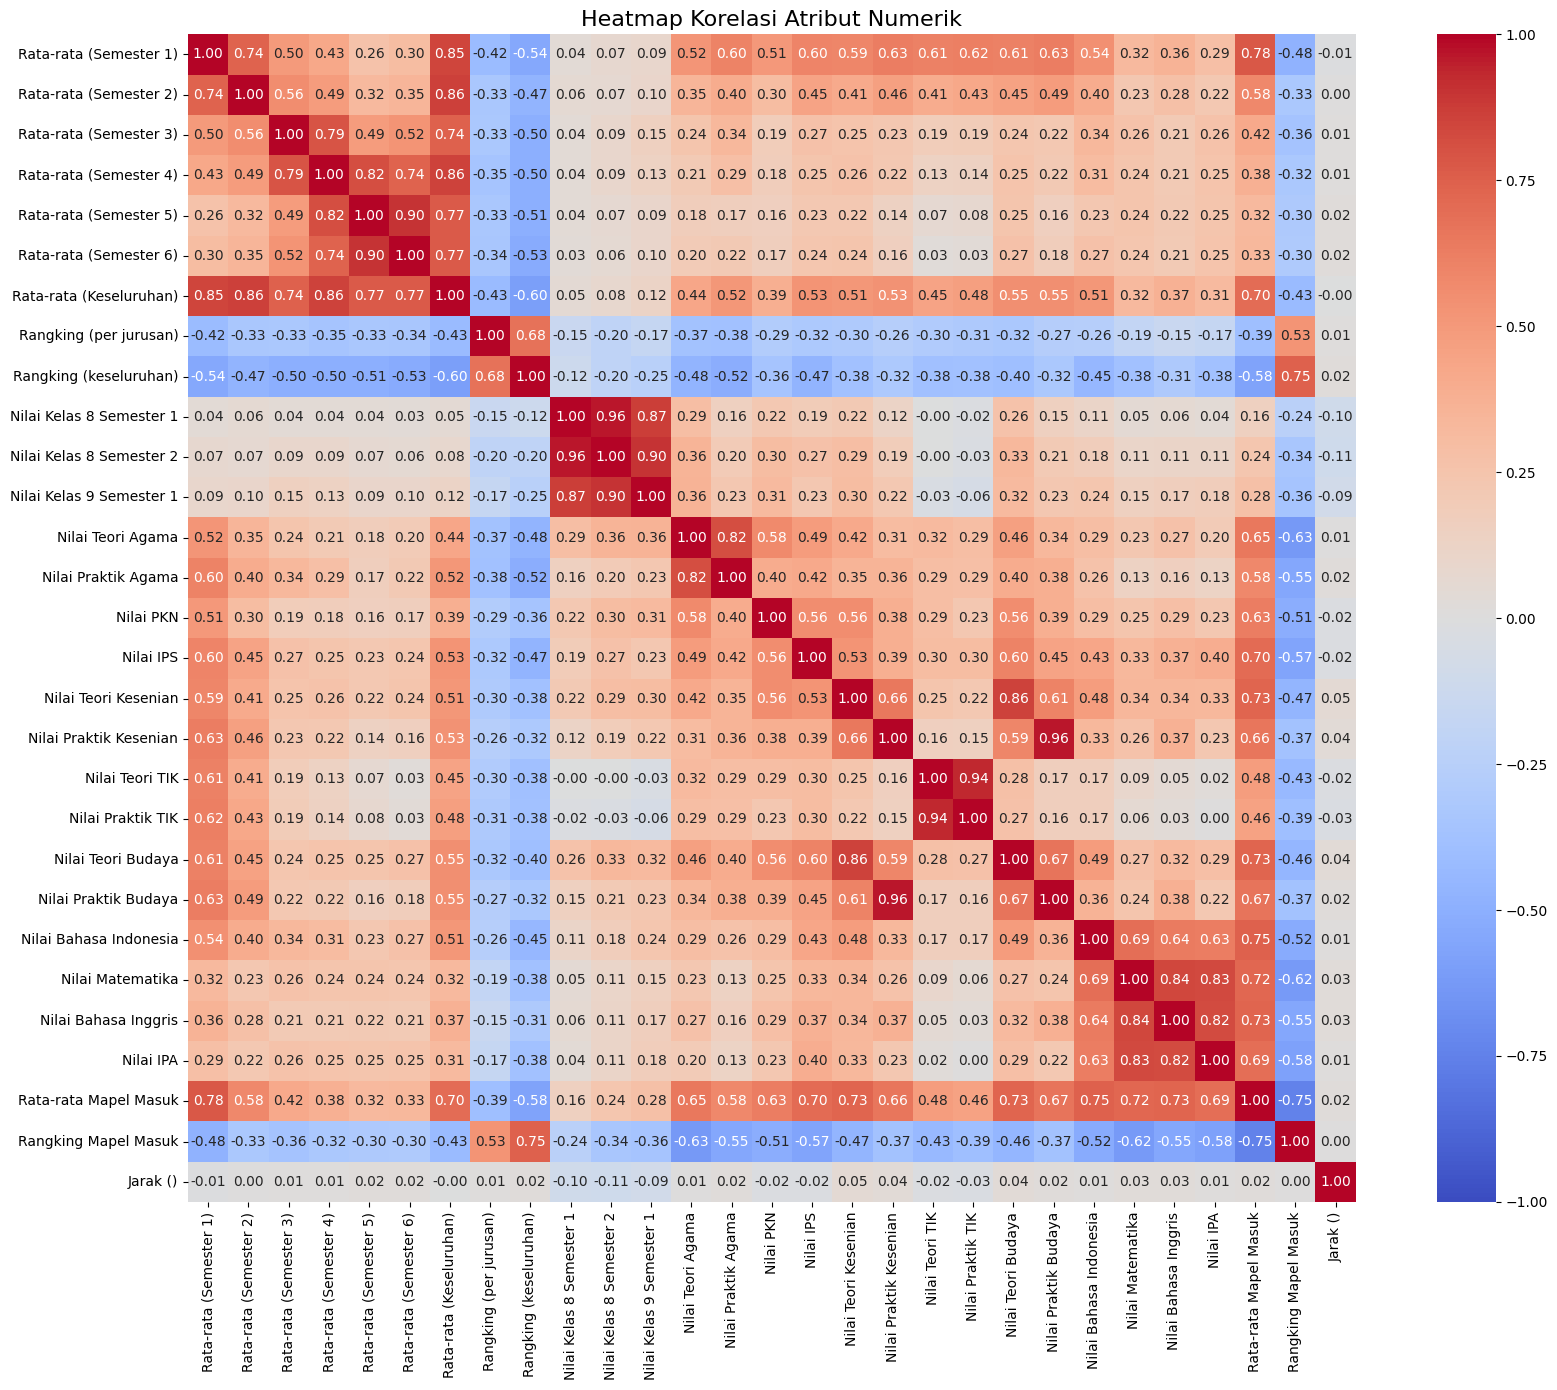

In [ ]:
#heatmap korelasi atribut numerik siswa

import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

# Atribut numerik untuk analisis korelasi
kolom_numerik = [
    "Rata-rata (Semester 1)",
    "Rata-rata (Semester 2)",
    "Rata-rata (Semester 3)",
    "Rata-rata (Semester 4)",
    "Rata-rata (Semester 5)",
    "Rata-rata (Semester 6)",
    "Rata-rata (Keseluruhan)",
    "Rangking (per jurusan)",
    "Rangking (keseluruhan)",
    "Nilai Kelas 8 Semester 1",
    "Nilai Kelas 8 Semester 2",
    "Nilai Kelas 9 Semester 1",
    "Nilai Teori Agama",
    "Nilai Praktik Agama",
    "Nilai PKN",
    "Nilai IPS",
    "Nilai Teori Kesenian",
    "Nilai Praktik Kesenian",
    "Nilai Teori TIK",
    "Nilai Praktik TIK",
    "Nilai Teori Budaya",
    "Nilai Praktik Budaya",
    "Nilai Bahasa Indonesia",
    "Nilai Matematika",
    "Nilai Bahasa Inggris",
    "Nilai IPA",
    "Rata-rata Mapel Masuk",
    "Rangking Mapel Masuk",
    "Jarak ()"
]

# Pilih kolom yang benar-benar tersedia
kolom_numerik = [
    kolom for kolom in kolom_numerik
    if kolom in data.columns
]

# Heatmap korelasi atribut numerik siswa

# Mengubah data menjadi numerik; tanda '-' menjadi NaN
data_korelasi = data[kolom_numerik].copy()

for kolom in kolom_numerik:
    data_korelasi[kolom] = pd.to_numeric(
        data_korelasi[kolom], errors="coerce"
    )

# Menghapus kolom yang seluruh nilainya kosong
data_korelasi = data_korelasi.dropna(axis=1, how="all")

# Hitung korelasi Pearson
korelasi = data_korelasi.corr(method="pearson")

# Visualisasi heatmap
plt.figure(figsize=(18, 14))
sns.heatmap(
    korelasi,
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    annot=True,
    fmt=".2f",
    square=True
)

plt.title("Heatmap Korelasi Atribut Numerik", fontsize=16)
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()




Distribusi Jenis Kelamin terhadap Capaian Studi (%)


Ketgori Capaian Siswa,Pintar,Biasa,Tidak Pintar
Jenis Kelamin,,,
Laki-laki,16.72,72.76,10.51
Perempuan,31.85,64.59,3.56


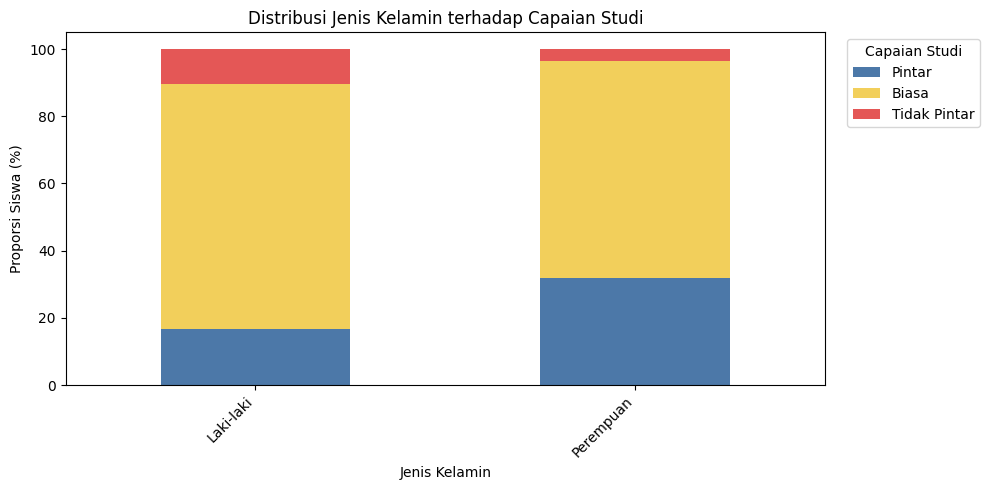


Distribusi Kelas terhadap Capaian Studi (%)


Ketgori Capaian Siswa,Pintar,Biasa,Tidak Pintar
Kelas,,,
10 Akuntansi dan Keuangan Lembaga,42.14,50.94,6.92
10 Bisnis Daring dan Pemasaran,33.33,46.67,20.00
10 Manajemen Perkantoran dan Layanan Bisnis,14.68,78.90,6.42
10 Manajemen Perkantoran dan Layanan Bisnis 1,11.54,84.62,3.85
10 Manajemen Perkantoran dan Layanan Bisnis 2,27.78,61.11,11.11
10 Otomatisasi Tata Kelola Perkantoran,27.78,69.44,2.78
10 Pemasaran,14.58,79.17,6.25
10 Pengembangan Perangkat Lunak dan Gim,25.45,69.09,5.45
10 Rekayasa Perangkat Lunak,22.86,71.43,5.71


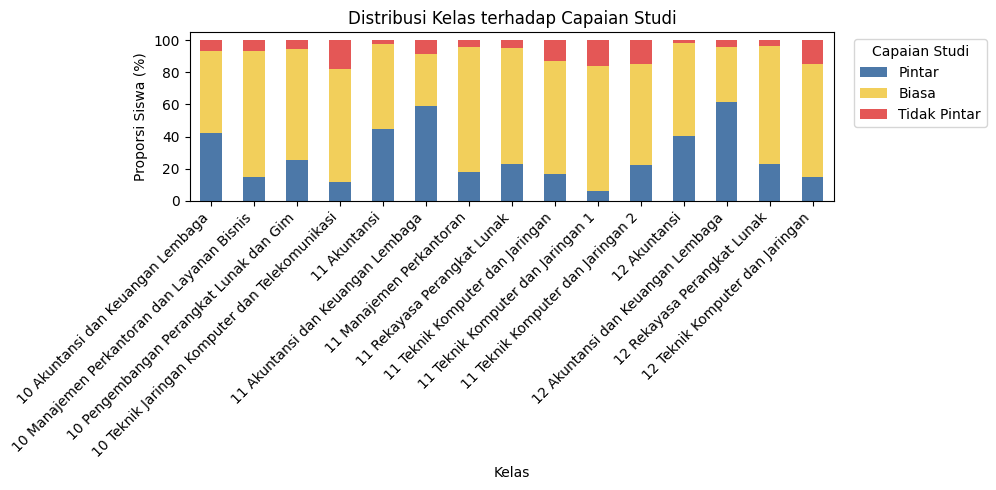


Distribusi Tingkat terhadap Capaian Studi (%)


Ketgori Capaian Siswa,Pintar,Biasa,Tidak Pintar
Tingkat,,,
10,23.55,68.78,7.67
11,25.35,67.35,7.30
12,23.14,70.30,6.56


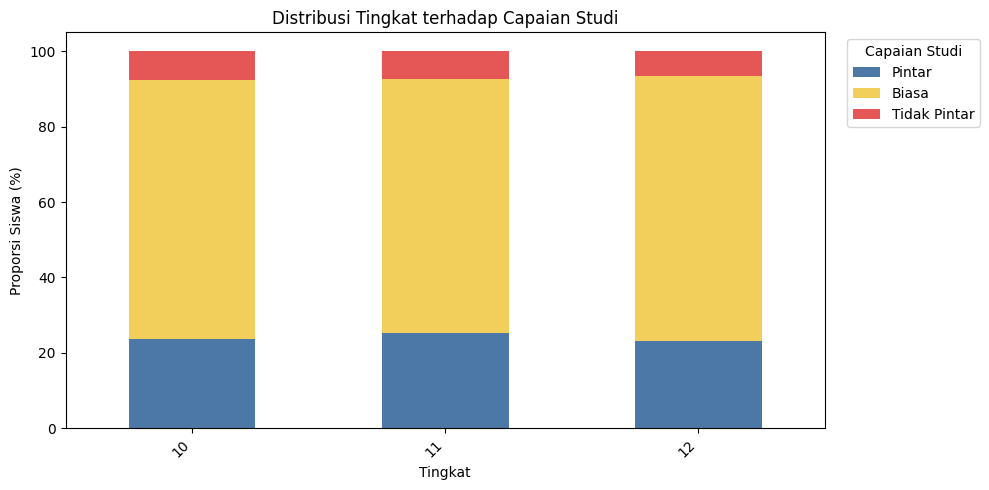


Distribusi Asal Sekolah terhadap Capaian Studi (%)


Ketgori Capaian Siswa,Pintar,Biasa,Tidak Pintar
Asal Sekolah,,,
-,0.0,28.57,71.43
CENDIKIA ALHARAMAIN INDONESIA,0.0,100.00,0.00
Kalam Kudus,100.0,0.00,0.00
MTS AL-FAJAR,0.0,100.00,0.00
MTS AN-NAJAH,0.0,100.00,0.00
...,...,...,...
UPT SMP Negeri 3 Kuok,0.0,100.00,0.00
UPT SMPN 1 Perhentian Raja,0.0,100.00,0.00
UPT SMPN 4 Siak Hulu,100.0,0.00,0.00


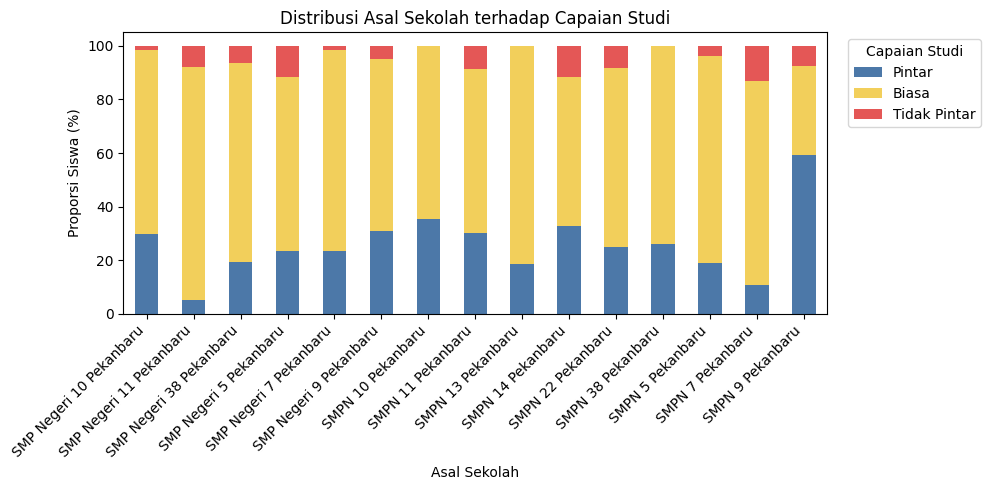


Distribusi Pekerjaan Ayah terhadap Capaian Studi (%)


Ketgori Capaian Siswa,Pintar,Biasa,Tidak Pintar
Pekerjaan Ayah,,,
-,7.35,91.18,1.47
BUMD,0.00,100.00,0.00
BUMN,100.00,0.00,0.00
Buruh,18.12,75.50,6.38
Dosen PNS,24.11,66.07,9.82
Guru PNS,26.32,52.63,21.05
Guru Swasta,42.86,42.86,14.29
IRT,0.00,100.00,0.00
Karyawan Bank,0.00,33.33,66.67


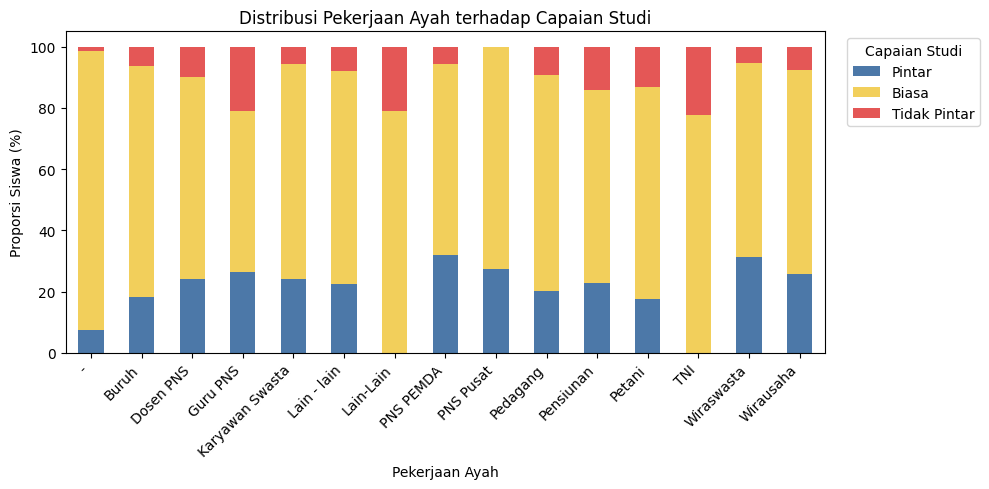


Distribusi Pekerjaan Ibu terhadap Capaian Studi (%)


Ketgori Capaian Siswa,Pintar,Biasa,Tidak Pintar
Pekerjaan Ibu,,,
-,8.57,91.43,0.00
BUMN,0.00,100.00,0.00
Buruh,23.53,76.47,0.00
Dosen PNS,25.44,68.48,6.08
Guru PNS,25.58,62.79,11.63
Guru Swasta,25.81,64.52,9.68
IRT,24.53,67.70,7.76
Karyawan Bank,0.00,100.00,0.00
Karyawan Swasta,28.00,64.80,7.20


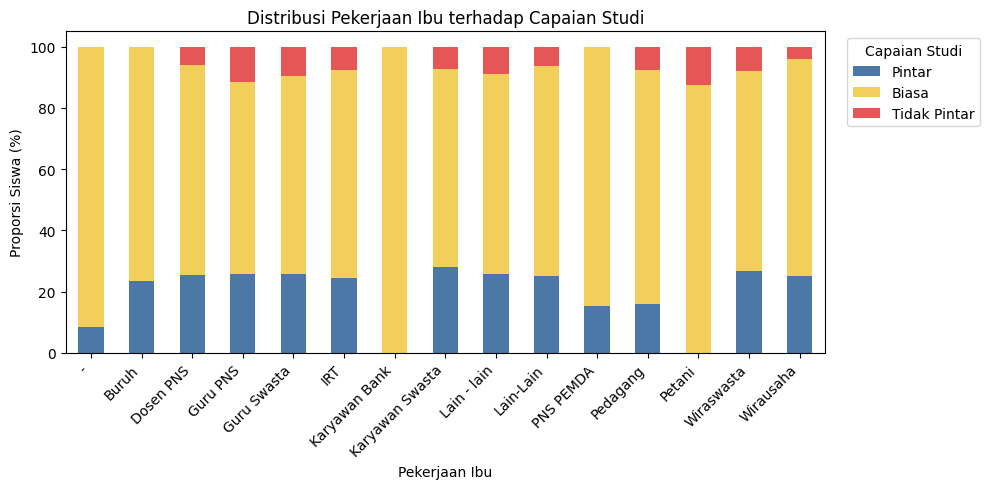


Distribusi Ekstrakurikuler terhadap Capaian Studi (%)


Ketgori Capaian Siswa,Pintar,Biasa,Tidak Pintar
Ekstrakurikuler,,,
-,14.85,70.44,14.71
Baik,23.40,71.12,5.48
Cukup,2.04,85.71,12.24
Sangat Baik,33.10,64.56,2.34


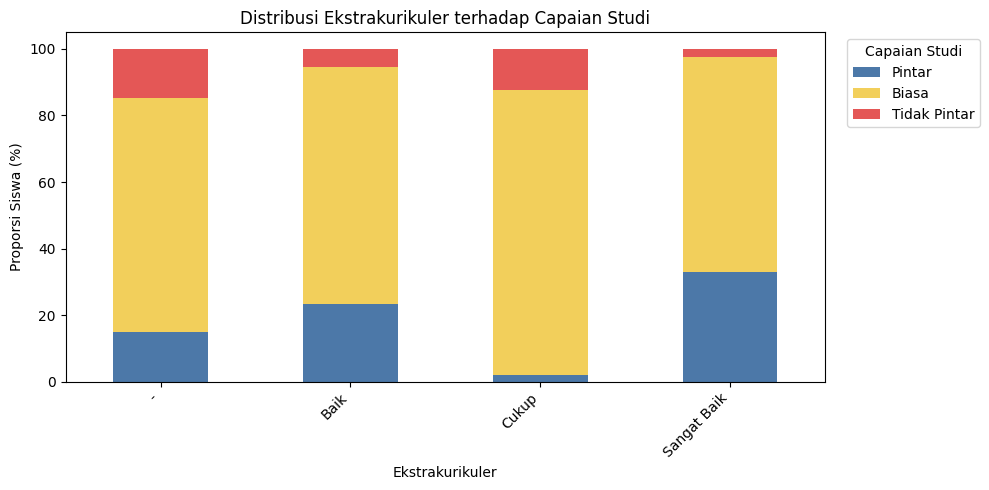


Distribusi Kokurikuler terhadap Capaian Studi (%)


Ketgori Capaian Siswa,Pintar,Biasa,Tidak Pintar
Kokurikuler,,,
-,24.15,66.50,9.35
Baik,0.00,100.00,0.00
Berkembang,2.00,76.00,22.00
Cakap,16.83,75.37,7.80
Mahir,28.67,68.01,3.32


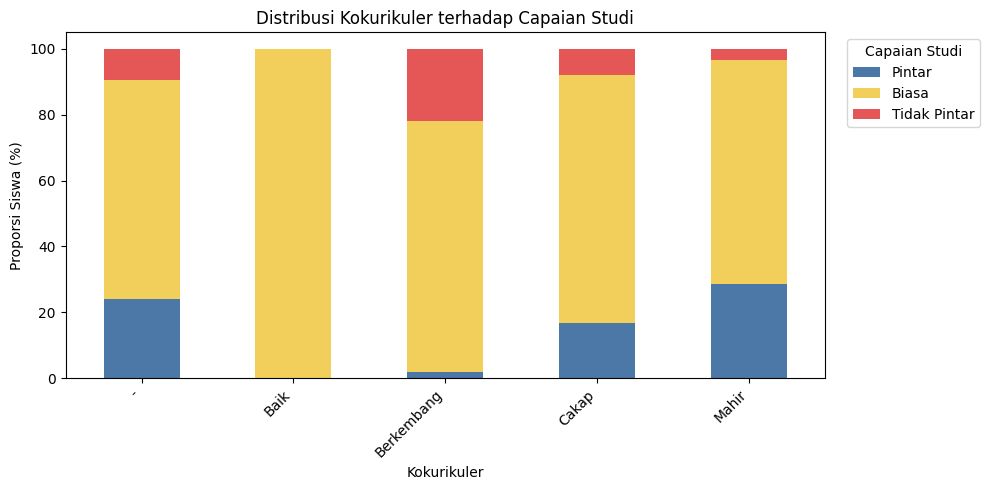


Distribusi Tahun Ajaran terhadap Capaian Studi (%)


Ketgori Capaian Siswa,Pintar,Biasa,Tidak Pintar
Tahun Ajaran,,,
2021-2022 (3),21.40,66.29,12.31
2022-2023 (3),23.92,68.45,7.63
2023-2024 (3),25.68,68.21,6.11
2024-2025 (3),25.51,69.70,4.78
2025-2026 (3),23.95,72.35,3.70


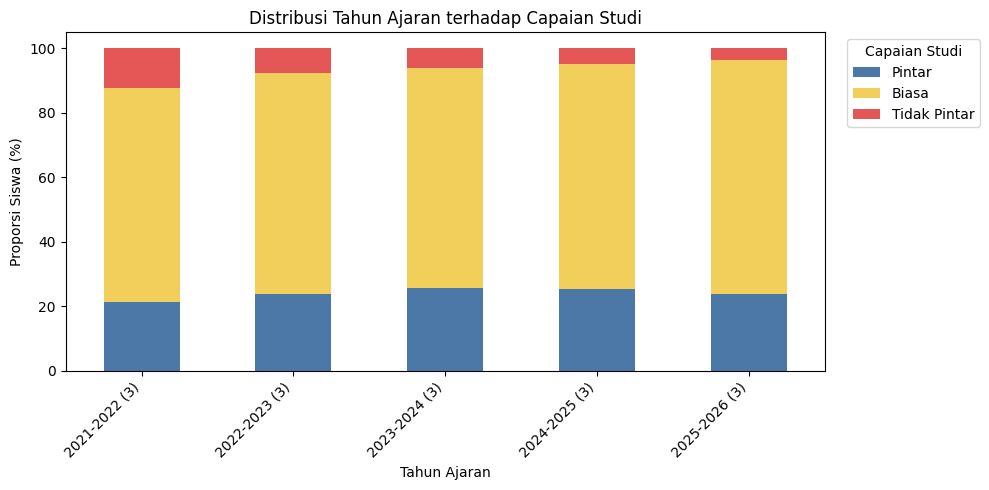

In [ ]:
#Distribusi atribut kategorikal terhadap capaian studi
target = "Ketgori Capaian Siswa"

kolom_kategorikal = [
    "Jenis Kelamin",
    "Kelas",
    "Tingkat",
    "Asal Sekolah",
    "Pekerjaan Ayah",
    "Pekerjaan Ibu",
    "Ekstrakurikuler",
    "Kokurikuler",
    "Tahun Ajaran"
]

urutan_target = ["Pintar", "Biasa", "Tidak Pintar"]

# Memastikan kolom tersedia
kolom_kategorikal = [
    kolom for kolom in kolom_kategorikal
    if kolom in data.columns
]

# Distribusi atribut terhadap kelas capaian studi
for kolom in kolom_kategorikal:

    tabel = pd.crosstab(
        data[kolom].fillna("Data kosong"),
        data[target],
        normalize="index"
    ) * 100

    # Urutan kolom target
    tabel = tabel.reindex(
        columns=urutan_target,
        fill_value=0
    )

    print(f"\nDistribusi {kolom} terhadap Capaian Studi (%)")
    display(tabel.round(2))

    # Batasi grafik pada 15 kategori terbanyak jika kategori banyak
    jumlah = data[kolom].fillna("Data kosong").value_counts()
    kategori_plot = jumlah.head(15).index
    tabel_plot = tabel.loc[
        tabel.index.intersection(kategori_plot)
    ]

    ax = tabel_plot.plot(
        kind="bar",
        stacked=True,
        figsize=(10, 5),
        color=["#4C78A8", "#F2CF5B", "#E45756"]
    )

    ax.set_title(f"Distribusi {kolom} terhadap Capaian Studi")
    ax.set_xlabel(kolom)
    ax.set_ylabel("Proporsi Siswa (%)")
    ax.legend(title="Capaian Studi", bbox_to_anchor=(1.02, 1))
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()


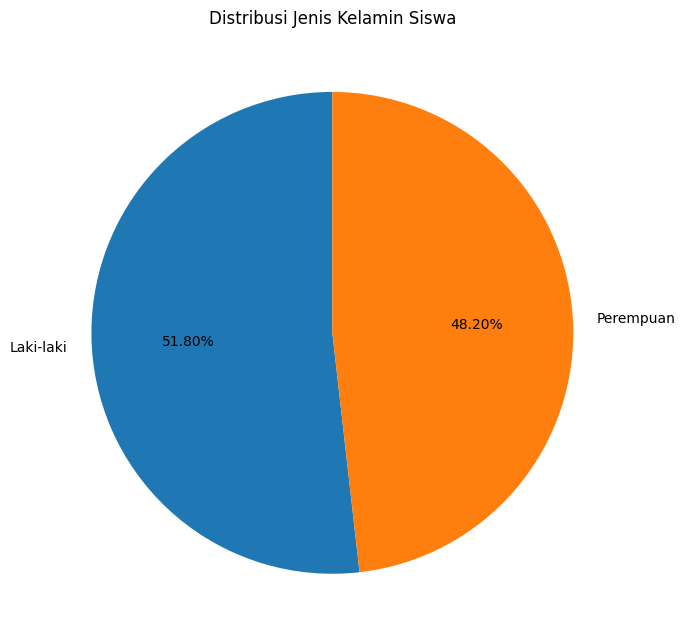

In [ ]:
#Distribusi jenis kelamin
distribusi_jk = data["Jenis Kelamin"].value_counts()

plt.figure(figsize=(7, 7))

plt.pie(
    distribusi_jk.values,
    labels=distribusi_jk.index,
    autopct="%1.2f%%",
    startangle=90
)

plt.title("Distribusi Jenis Kelamin Siswa")
plt.tight_layout()
plt.show()

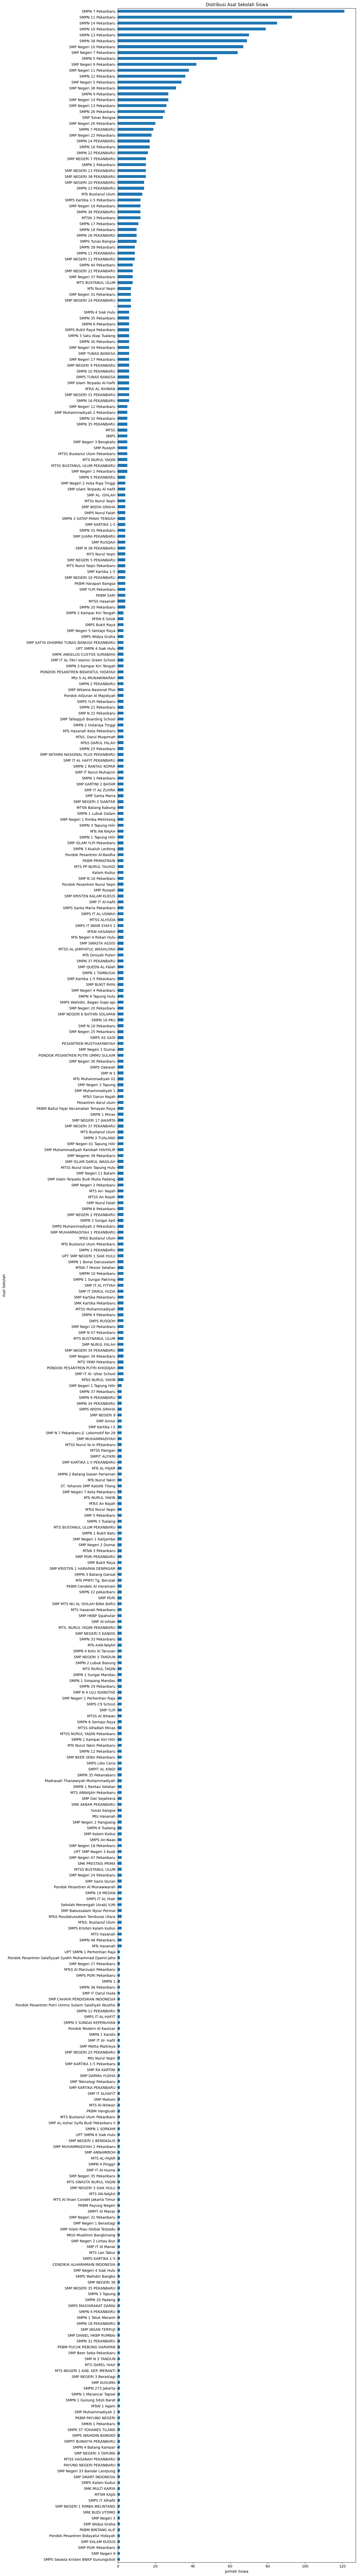

In [ ]:
#Distibusi asal sekolah
distribusi_sekolah = data["Asal Sekolah"].value_counts()

plt.figure(figsize=(14, 100))

distribusi_sekolah.sort_values().plot(
    kind="barh"
)

plt.title("Distribusi Asal Sekolah Siswa")
plt.xlabel("Jumlah Siswa")
plt.ylabel("Asal Sekolah")
plt.tight_layout()
plt.show()

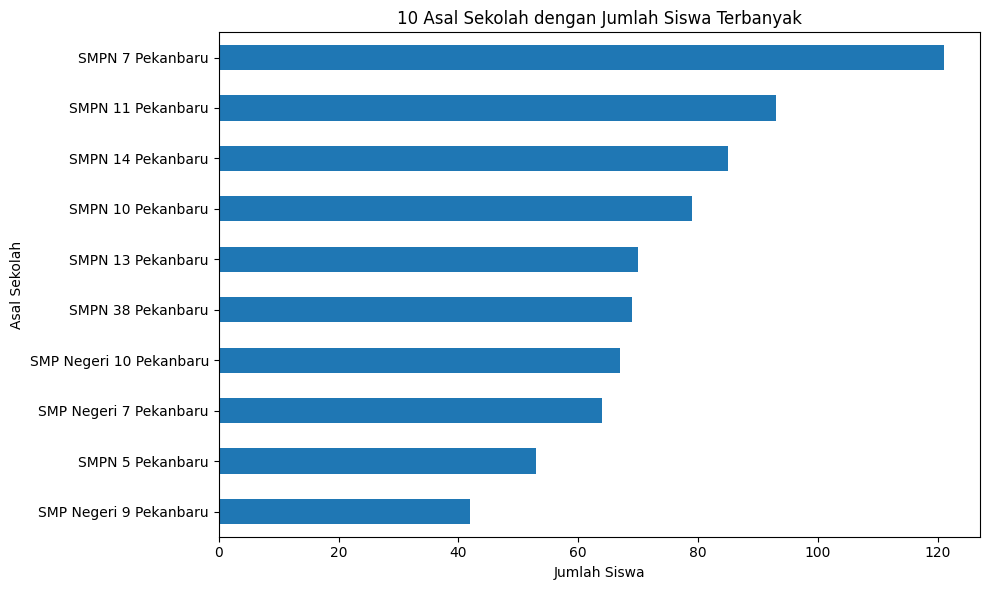

In [ ]:
top_10_sekolah = data["Asal Sekolah"].value_counts().head(10)

plt.figure(figsize=(10, 6))

top_10_sekolah.sort_values().plot(
    kind="barh"
)

plt.title("10 Asal Sekolah dengan Jumlah Siswa Terbanyak")
plt.xlabel("Jumlah Siswa")
plt.ylabel("Asal Sekolah")
plt.tight_layout()
plt.show()

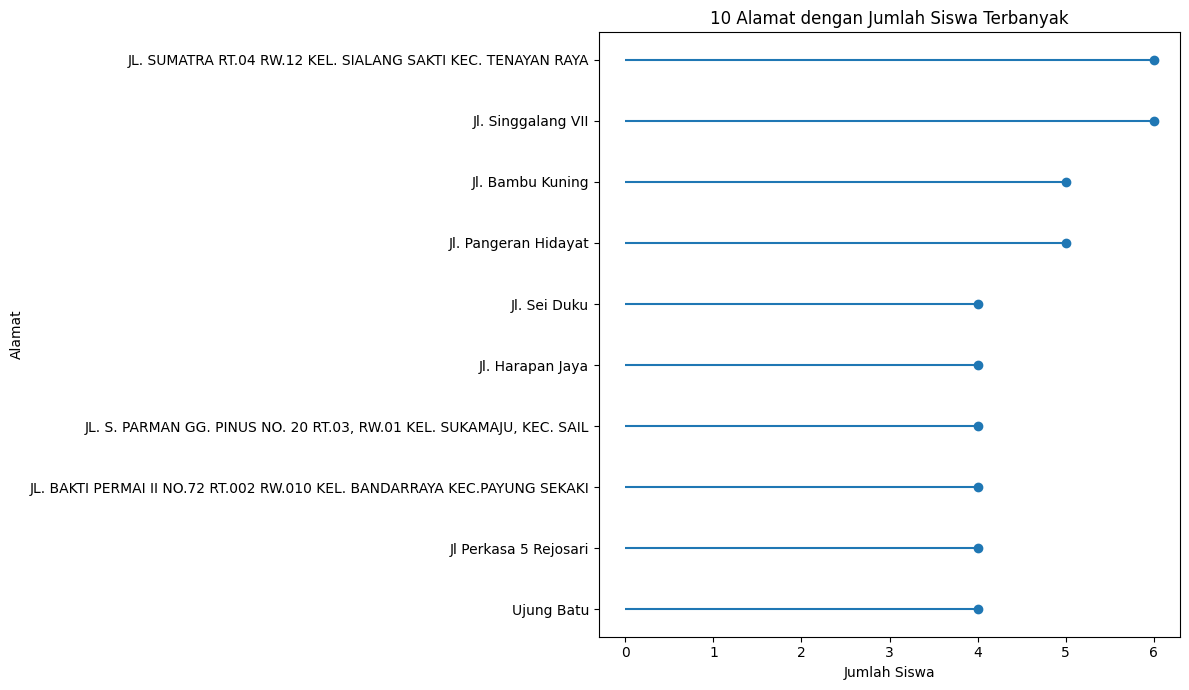

In [ ]:
top_10_alamat = data["Alamat"].value_counts().head(10).sort_values()

plt.figure(figsize=(12, 7))

y = range(len(top_10_alamat))

plt.hlines(
    y=y,
    xmin=0,
    xmax=top_10_alamat.values
)

plt.plot(
    top_10_alamat.values,
    y,
    "o"
)

plt.yticks(
    y,
    top_10_alamat.index
)

plt.xlabel("Jumlah Siswa")
plt.ylabel("Alamat")
plt.title("10 Alamat dengan Jumlah Siswa Terbanyak")

plt.tight_layout()
plt.show()

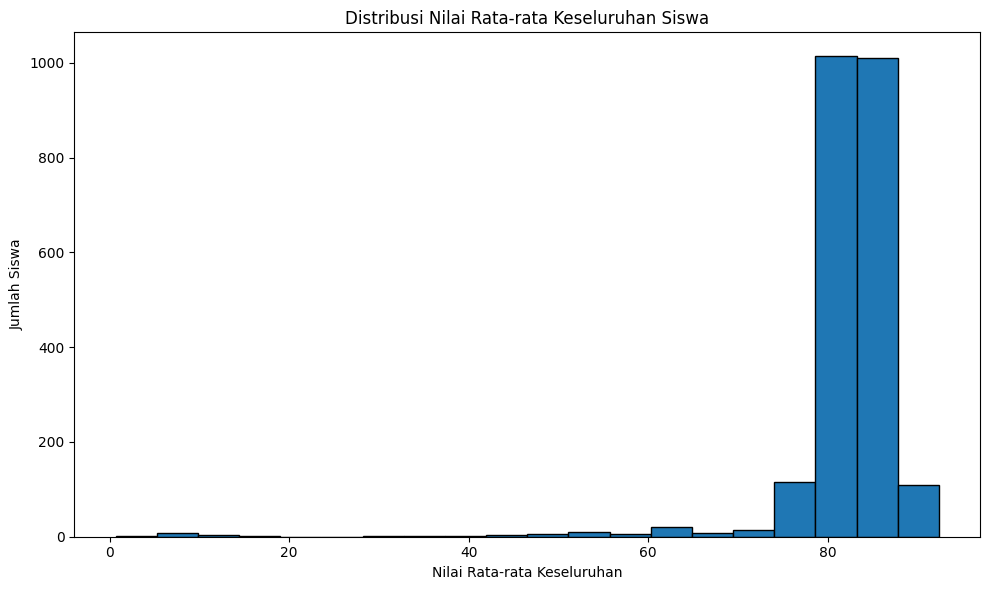

In [ ]:
#Distribusi nilai rata-rata keseluruhan
plt.figure(figsize=(10, 6))

plt.hist(
    data["Rata-rata (Keseluruhan)"].dropna(),
    bins=20,
    edgecolor="black"
)

plt.title("Distribusi Nilai Rata-rata Keseluruhan Siswa")
plt.xlabel("Nilai Rata-rata Keseluruhan")
plt.ylabel("Jumlah Siswa")

plt.tight_layout()
plt.show()

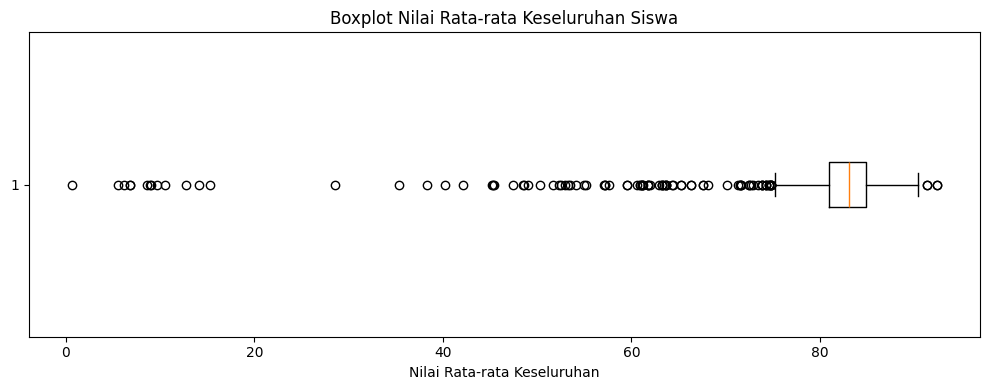

In [ ]:
#Outlier nilai rata-rata
plt.figure(figsize=(10, 4))

plt.boxplot(
    data["Rata-rata (Keseluruhan)"].dropna(),
    vert=False
)

plt.title("Boxplot Nilai Rata-rata Keseluruhan Siswa")
plt.xlabel("Nilai Rata-rata Keseluruhan")

plt.tight_layout()
plt.show()

/tmp/ipykernel_2999/1391865648.py:13: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(


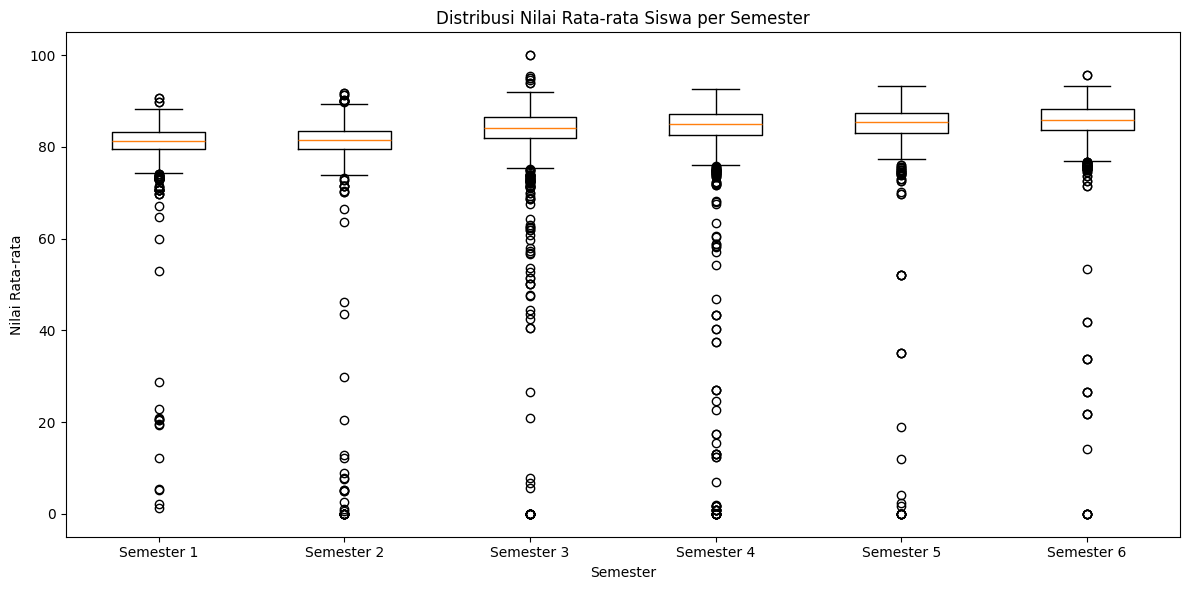

In [ ]:
#Distribusi nilai rata-rata semester 1-6
kolom_semester = [
    "Rata-rata (Semester 1)",
    "Rata-rata (Semester 2)",
    "Rata-rata (Semester 3)",
    "Rata-rata (Semester 4)",
    "Rata-rata (Semester 5)",
    "Rata-rata (Semester 6)"
]

plt.figure(figsize=(12, 6))

plt.boxplot(
    [data[kolom].dropna() for kolom in kolom_semester],
    labels=["Semester 1", "Semester 2", "Semester 3",
            "Semester 4", "Semester 5", "Semester 6"]
)

plt.title("Distribusi Nilai Rata-rata Siswa per Semester")
plt.xlabel("Semester")
plt.ylabel("Nilai Rata-rata")

plt.tight_layout()
plt.show()

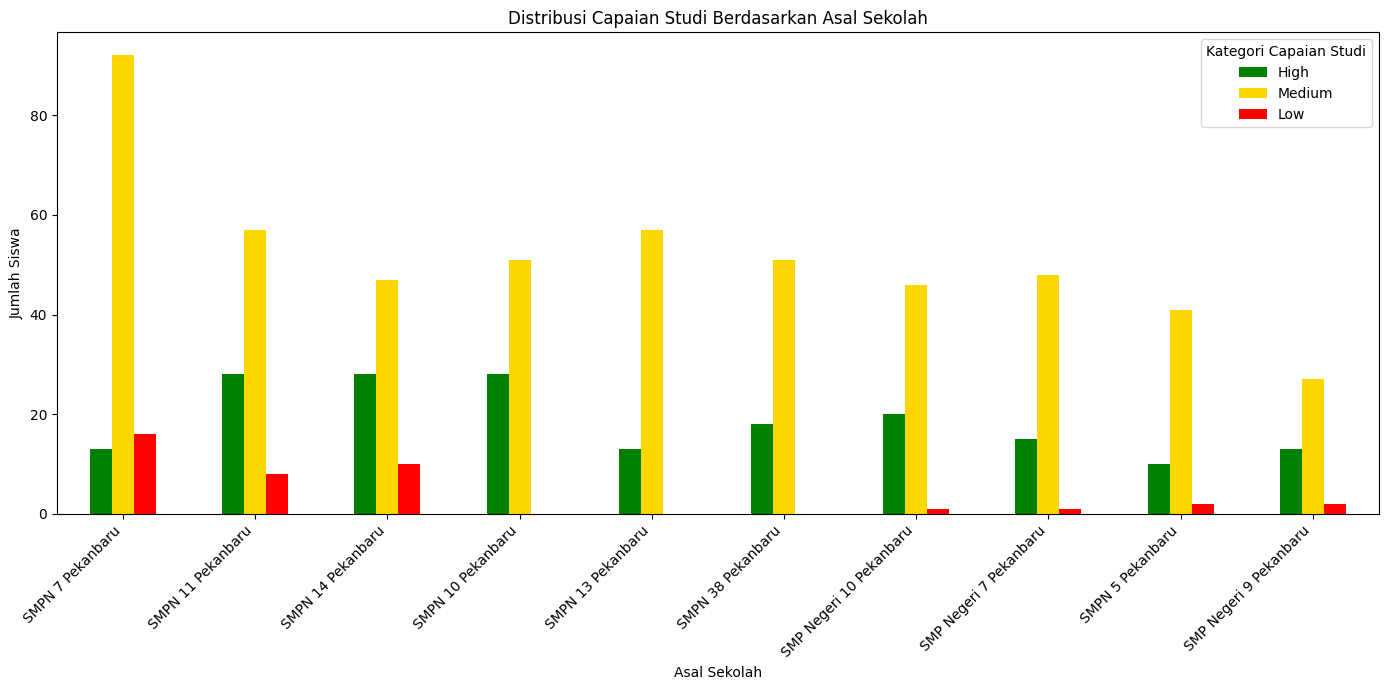

In [ ]:
#Distribusi capaian studi berdasarkan asal sekolah
target_sementara = np.where(
    data["Rata-rata (Keseluruhan)"] > 85,
    "High",
    np.where(
        data["Rata-rata (Keseluruhan)"] >= 78,
        "Medium",
        "Low"
    )
)

# Membuat data sementara tanpa mengubah data asli
eda_sekolah = data[["Asal Sekolah"]].copy()
eda_sekolah["Target"] = target_sementara

# Ambil 10 sekolah dengan jumlah siswa terbanyak
top_sekolah = eda_sekolah["Asal Sekolah"].value_counts().head(10).index

distribusi_sekolah = pd.crosstab(
    eda_sekolah["Asal Sekolah"],
    eda_sekolah["Target"]
).reindex(top_sekolah, fill_value=0)

# Pastikan urutan kategori
distribusi_sekolah = distribusi_sekolah.reindex(
    columns=["High", "Medium", "Low"],
    fill_value=0
)

# Grafik
ax = distribusi_sekolah.plot(
    kind="bar",
    figsize=(14, 7),
    color=["green", "gold", "red"]
)

plt.title("Distribusi Capaian Studi Berdasarkan Asal Sekolah")
plt.xlabel("Asal Sekolah")
plt.ylabel("Jumlah Siswa")
plt.xticks(rotation=45, ha="right")

plt.legend(
    title="Kategori Capaian Studi"
)

plt.tight_layout()
plt.show()

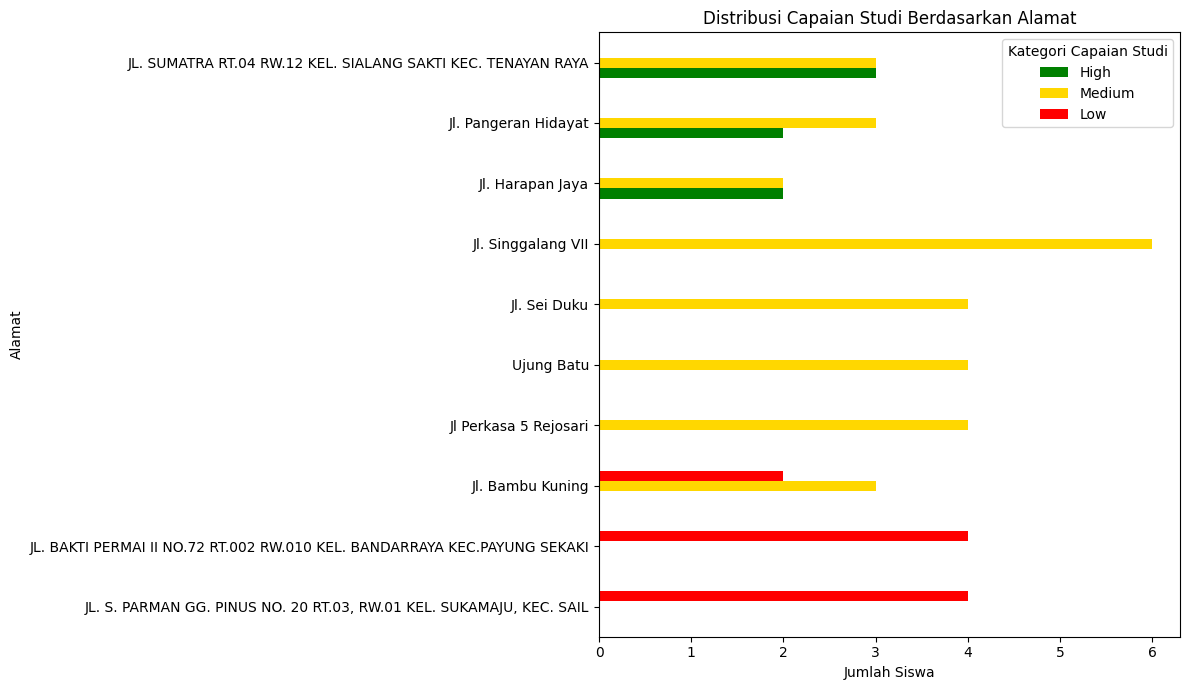

In [ ]:
#Distribusi capaian studi berdasarkan alamat
eda_alamat = data[["Alamat"]].copy()
eda_alamat["Target"] = target_sementara

# 10 alamat dengan jumlah siswa terbanyak
top_alamat = eda_alamat["Alamat"].value_counts().head(10).index

distribusi_alamat = pd.crosstab(
    eda_alamat["Alamat"],
    eda_alamat["Target"]
).reindex(top_alamat, fill_value=0)

# Urutan kategori
distribusi_alamat = distribusi_alamat.reindex(
    columns=["High", "Medium", "Low"],
    fill_value=0
)

# Grafik horizontal
ax = distribusi_alamat.sort_values(
    by=["High", "Medium", "Low"]
).plot(
    kind="barh",
    figsize=(12, 7),
    color=["green", "gold", "red"]
)

plt.title("Distribusi Capaian Studi Berdasarkan Alamat")
plt.xlabel("Jumlah Siswa")
plt.ylabel("Alamat")

plt.legend(title="Kategori Capaian Studi")

plt.tight_layout()
plt.show()

# Prapemrosesan Data -> Pembersihan Data

In [ ]:
# Menyeragamkan format data kategorikal
kolom_kategorikal = [
    "Jenis Kelamin",
    "Kelas",
    "Alamat",
    "Asal Sekolah",
    "Pekerjaan Ayah",
    "Pekerjaan Ibu",
    "Ekstrakurikuler",
    "Kokurikuler",
    "Tahun Ajaran",
    "Ketgori Capaian Siswa"
]

# Hanya memproses kolom yang tersedia
kolom_kategorikal = [
    kolom for kolom in kolom_kategorikal
    if kolom in data.columns
]

for kolom in kolom_kategorikal:
    data[kolom] = (
        data[kolom]
        .astype("string")
        .str.strip()
    )

print("Penyeragaman format selesai.")
print("\nJumlah data kosong setelah proses:")
display(data[kolom_kategorikal].isna().sum())


Penyeragaman format selesai.

Jumlah data kosong setelah proses:


,0
Jenis Kelamin,0
Kelas,0
Alamat,0
Asal Sekolah,0
Pekerjaan Ayah,0
Pekerjaan Ibu,0
Ekstrakurikuler,0
Kokurikuler,0
Tahun Ajaran,0
Ketgori Capaian Siswa,0


In [ ]:
print("Kolom data:")
print(data.columns.tolist())

print("\nVariabel yang mungkin menyimpan hasil ekstraksi:")
for nama, objek in globals().copy().items():
    if isinstance(objek, pd.DataFrame):
        if "Alamat" in objek.columns:
            print(nama, objek.shape)

Kolom data:
['No.', 'NIS', 'NISN', 'Nama Siswa', 'Jenis Kelamin', 'Kelas', 'Tingkat', 'Wali Kelas', 'Rata-rata (Semester 1)', 'Rata-rata (Semester 2)', 'Rata-rata (Semester 3)', 'Rata-rata (Semester 4)', 'Rata-rata (Semester 5)', 'Rata-rata (Semester 6)', 'Rata-rata (Keseluruhan)', 'Rangking (per jurusan)', 'Rangking (keseluruhan)', 'Alamat', 'Asal Sekolah', 'Ketgori Capaian Siswa', 'Nilai Kelas 8 Semester 1', 'Nilai Kelas 8 Semester 2', 'Nilai Kelas 9 Semester 1', 'Nilai Teori Agama', 'Nilai Praktik Agama', 'Nilai PKN', 'Nilai IPS', 'Nilai Teori Kesenian', 'Nilai Praktik Kesenian', 'Nilai Teori TIK', 'Nilai Praktik TIK', 'Nilai Teori Budaya', 'Nilai Praktik Budaya', 'Nilai Bahasa Indonesia', 'Nilai Matematika', 'Nilai Bahasa Inggris', 'Nilai IPA', 'Rata-rata Mapel Masuk', 'Rangking Mapel Masuk', 'Pekerjaan Ayah', 'Pekerjaan Ibu', 'Jarak ()', 'Ekstrakurikuler', 'Kokurikuler', 'Tahun Ajaran']

Variabel yang mungkin menyimpan hasil ekstraksi:
___ (0, 3)
df (405, 45)
data (2332, 45)
eda_a

In [ ]:
#Menyeragamkan kategori pekerjaan orang tua

# Periksa kategori sebelum perubahan
print("Pekerjaan Ayah sebelum:")
print(data["Pekerjaan Ayah"].value_counts())

print("\nPekerjaan Ibu sebelum:")
print(data["Pekerjaan Ibu"].value_counts())

# Menyamakan variasi penulisan kategori
pemetaan_pekerjaan = {
    "Lain - lain": "Lain-lain",
    "Lain-Lain": "Lain-lain",
    "Wiraswasta": "Wirausaha"
}

for kolom in ["Pekerjaan Ayah", "Pekerjaan Ibu"]:
    data[kolom] = data[kolom].replace(pemetaan_pekerjaan)

# Periksa hasil setelah perubahan
print("\nPekerjaan Ayah setelah:")
print(data["Pekerjaan Ayah"].value_counts())

print("\nPekerjaan Ibu setelah:")
print(data["Pekerjaan Ibu"].value_counts())


Pekerjaan Ayah sebelum:
Pekerjaan Ayah
Wiraswasta         536
Karyawan Swasta    517
Buruh              298
Lain - lain        266
Dosen PNS          224
Pedagang           129
PNS PEMDA           69
Petani              68
-                   68
Wirausaha           39
Pensiunan           35
Lain-Lain           19
Guru PNS            19
PNS Pusat           11
TNI                  9
POLRI                8
Guru Swasta          7
Karyawan Bank        3
Nelayan              3
BUMN                 2
IRT                  1
BUMD                 1
Name: count, dtype: Int64

Pekerjaan Ibu sebelum:
Pekerjaan Ibu
IRT                966
Dosen PNS          625
Karyawan Swasta    125
Pedagang           120
Lain-Lain          112
Lain - lain        101
Wiraswasta          75
Guru PNS            43
-                   35
Guru Swasta         31
PNS PEMDA           26
Wirausaha           24
Petani              24
Buruh               17
Karyawan Bank        3
Pensiunan            2
Nelayan              1


In [ ]:
# Mengubah tanda "-" menjadi NaN pada seluruh kolom teks
kolom_teks = data.select_dtypes(
    include=["object", "string"]
).columns

for kolom in kolom_teks:
    data[kolom] = data[kolom].replace("-", np.nan)

print("Jumlah tanda '-' yang tersisa:")
print(
    (data[kolom_teks] == "-").sum().sum()
)

print("\nKolom dengan data kosong:")
missing = data.isna().sum()
display(
    missing[missing > 0]
    .sort_values(ascending=False)
    .to_frame("Jumlah Missing")
)

print("\nUkuran dataset:", data.shape)


Jumlah tanda '-' yang tersisa:
0

Kolom dengan data kosong:


,Jumlah Missing
Nilai Kelas 8 Semester 2,1837
Nilai Kelas 8 Semester 1,1835
Nilai Kelas 9 Semester 1,1834
Kokurikuler,1027
Jarak (),973
Ekstrakurikuler,680
Rata-rata (Semester 6),444
Rata-rata (Semester 5),444
Rata-rata (Semester 4),146
Rata-rata (Semester 3),75



Ukuran dataset: (2332, 45)


In [ ]:
#Memeriksa kategori tanda "-" pada atribut kategorikal

kolom_periksa = [
    "Pekerjaan Ayah",
    "Pekerjaan Ibu",
    "Ekstrakurikuler",
    "Kokurikuler"
]

for kolom in kolom_periksa:
    print(f"\n--- {kolom} ---")
    print(data[kolom].value_counts(dropna=False))
    print("Jumlah tanda '-':", (data[kolom] == "-").sum())



--- Pekerjaan Ayah ---
Pekerjaan Ayah
Wirausaha          575
Karyawan Swasta    517
Buruh              298
Lain-lain          285
Dosen PNS          224
Pedagang           129
PNS PEMDA           69
<NA>                68
Petani              68
Pensiunan           35
Guru PNS            19
PNS Pusat           11
TNI                  9
POLRI                8
Guru Swasta          7
Karyawan Bank        3
Nelayan              3
BUMN                 2
IRT                  1
BUMD                 1
Name: count, dtype: Int64
Jumlah tanda '-': 0

--- Pekerjaan Ibu ---
Pekerjaan Ibu
IRT                966
Dosen PNS          625
Lain-lain          213
Karyawan Swasta    125
Pedagang           120
Wirausaha           99
Guru PNS            43
<NA>                35
Guru Swasta         31
PNS PEMDA           26
Petani              24
Buruh               17
Karyawan Bank        3
Pensiunan            2
Nelayan              1
TNI                  1
BUMN                 1
Name: count, dtype: Int64
J

In [ ]:
# Mengubah tanda '-' menjadi NaN pada kolom Jarak

data["Jarak ()"] = data["Jarak ()"].replace("-", np.nan)

# Mengubah kolom Jarak menjadi numerik
data["Jarak ()"] = pd.to_numeric(
    data["Jarak ()"], errors="coerce"
).astype("Int64")

# Memeriksa hasil
print(data["Jarak ()"].dtype)
print("\nJumlah data kosong:")
print(data["Jarak ()"].isna().sum())


Int64

Jumlah data kosong:
974


In [ ]:

# ==========================================
# PENANGANAN MISSING VALUE
# EKSTRAKURIKULER DAN KOKURIKULER
# ==========================================

for kolom in ["Ekstrakurikuler", "Kokurikuler"]:
    if kolom in data.columns:
        data[kolom] = (
            data[kolom]
            .astype("string")
            .fillna("Belum Dinilai")
        )

print("Missing value setelah penanganan:")
print(
    data[
        ["Ekstrakurikuler", "Kokurikuler"]
    ].isna().sum()
)


Missing value setelah penanganan:
Ekstrakurikuler    0
Kokurikuler        0
dtype: int64


In [ ]:
print(data.dtypes)

No.                                  int64
NIS                                  int64
NISN                                 int64
Nama Siswa                          object
Jenis Kelamin               string[python]
Kelas                       string[python]
Tingkat                              int64
Wali Kelas                          object
Rata-rata (Semester 1)             float64
Rata-rata (Semester 2)             float64
Rata-rata (Semester 3)             float64
Rata-rata (Semester 4)             float64
Rata-rata (Semester 5)             float64
Rata-rata (Semester 6)             float64
Rata-rata (Keseluruhan)            float64
Rangking (per jurusan)               int64
Rangking (keseluruhan)               int64
Alamat                      string[python]
Asal Sekolah                string[python]
Ketgori Capaian Siswa       string[python]
Nilai Kelas 8 Semester 1           float64
Nilai Kelas 8 Semester 2           float64
Nilai Kelas 9 Semester 1           float64
Nilai Teori

In [ ]:
#Penanganan Missing Value


# Salin dataset awal agar data asli tetap aman
data_clean = data.copy()

# --------------------------------------------------
# 1. Hapus atribut dengan missing value sangat tinggi
#    atau nilai yang belum tersedia karena semester
#    belum ditempuh
# --------------------------------------------------
kolom_dihapus = [
    "Nilai Kelas 8 Semester 1",
    "Nilai Kelas 8 Semester 2",
    "Nilai Kelas 9 Semester 1",
    "Rata-rata (Semester 5)",
    "Rata-rata (Semester 6)"
]

data_clean.drop(
    columns=[kolom for kolom in kolom_dihapus
             if kolom in data_clean.columns],
    inplace=True
)

# --------------------------------------------------
# 2. Tangani missing value pada Jarak
#    Median dihitung berdasarkan tahun ajaran
#    Indikator mempertahankan informasi nilai kosong
# --------------------------------------------------
kolom_jarak = "Jarak ()"

if kolom_jarak in data_clean.columns:
    data_clean["Jarak_Tidak_Tercatat"] = (
        data_clean[kolom_jarak].isna().astype(int)
    )

    median_jarak_tahun = (
        data_clean.groupby("Tahun Ajaran")[kolom_jarak]
        .transform("median")
    )

    data_clean[kolom_jarak] = (
        data_clean[kolom_jarak].fillna(median_jarak_tahun)
    )

    # Jika ada tahun ajaran yang seluruh jaraknya kosong,
    # gunakan median keseluruhan sebagai cadangan
    data_clean[kolom_jarak] = (
        data_clean[kolom_jarak]
        .fillna(data_clean[kolom_jarak].median())
    )

# --------------------------------------------------
# 3. Tangani missing value atribut numerik lainnya
#    dengan median
# --------------------------------------------------
kolom_target = "Ketgori Capaian Siswa"

kolom_numerik = data_clean.select_dtypes(
    include="number"
).columns.tolist()

for kolom in kolom_numerik:
    if kolom != kolom_target and data_clean[kolom].isna().any():
        data_clean[kolom] = data_clean[kolom].fillna(
            data_clean[kolom].median()
        )

# --------------------------------------------------
# 4. Tangani missing value atribut kategorikal
# --------------------------------------------------
kolom_kategorikal = data_clean.select_dtypes(
    include=["object", "string", "category"]
).columns.tolist()

for kolom in kolom_kategorikal:
    if kolom != kolom_target:
        data_clean[kolom] = data_clean[kolom].fillna(
            "Tidak diketahui"
        )

# --------------------------------------------------
# 5. Periksa hasil akhir
# --------------------------------------------------
print("Ukuran dataset setelah penanganan missing value:",
      data_clean.shape)

print("\nJumlah missing value yang tersisa:")
print(data_clean.isna().sum().sum())

print("\nKolom yang masih memiliki missing value:")
print(data_clean.isna().sum()[data_clean.isna().sum() > 0])

print("\nDistribusi target:")
print(data_clean[kolom_target].value_counts())

Ukuran dataset setelah penanganan missing value: (2332, 41)

Jumlah missing value yang tersisa:
0

Kolom yang masih memiliki missing value:
Series([], dtype: int64)

Distribusi target:
Ketgori Capaian Siswa
Biasa           1605
Pintar           560
Tidak Pintar     167
Name: count, dtype: Int64


In [ ]:
# Menampilkan seluruh nama asal sekolah
sekolah = sorted(data["Asal Sekolah"].dropna().unique())

for i, nama in enumerate(sekolah, 1):
    print(i, ":", nama)

1 : CENDIKIA ALHARAMAIN INDONESIA
2 : Kalam Kudus
3 : MTS AL-FAJAR
4 : MTS AN-NAJAH
5 : MTS ANNAJAH Pekanbaru
6 : MTS Al Ihsan Condet Jakarta Timur
7 : MTS Al-Ikhwan
8 : MTS An- Najah
9 : MTS BUSTANUL ULUM
10 : MTS BUSTANUL ULUM PEKANBARU
11 : MTS BUSTNANUL ULUM
12 : MTS Bustanul Ulum
13 : MTS Bustanul Ulum Pekanbaru
14 : MTS DAREL HIAH
15 : MTS Hasanah
16 : MTS Hasanah Pekanbaru
17 : MTS Lan Tabur
18 : MTS NEGERI 1 KAB. KEP. MERANTI
19 : MTS NURUL TAQIN
20 : MTS NURUL YAQIN
21 : MTS Nurul Yaqin
22 : MTS Nurul Yaqin Pekanbaru
23 : MTS PP NURUL TAUHID
24 : MTS SWASTA NURUL YAQIN
25 : MTS YKWI Pekanbaru
26 : MTS. NURUL YAQIN PEKANBARU
27 : MTSM KAJAI
28 : MTSN 3 Pekanbaru
29 : MTSN Batang Kabung
30 : MTSS
31 : MTSS AL-JAMIYATUL WASHLIYAH
32 : MTSS ALHUDA
33 : MTSS Al Ikhwan
34 : MTSS AlFadlah Minas
35 : MTSS An Najah
36 : MTSS BUSTANUL ULUM
37 : MTSS BUSTANUL ULUM PEKANBARU
38 : MTSS Bustanul Ulum Pekanbaru
39 : MTSS HASANAH PEKANBARU
40 : MTSS Hasanah
41 : MTSS Muhammadiyah
42 : MTSS NU

In [ ]:
import re

def normalisasi_sekolah(nama):
    nama = str(nama).strip()

    # Menyeragamkan huruf
    nama = nama.upper()

    # Menghapus spasi berlebih
    nama = re.sub(r'\s+', ' ', nama)

    # Menyeragamkan beberapa bentuk singkatan
    nama = re.sub(r'^SMP\s*N\s*', 'SMP NEGERI ', nama)
    nama = re.sub(r'^SMPN\s*', 'SMP NEGERI ', nama)

    # Memperbaiki beberapa kesalahan penulisan umum
    nama = nama.replace('SMP NEGERI 01 ', 'SMP NEGERI 1 ')
    nama = nama.replace('SMP NEGERI 02 ', 'SMP NEGERI 2 ')
    nama = nama.replace('SMP NEGERI 03 ', 'SMP NEGERI 3 ')
    nama = nama.replace('SMP NEGERI 04 ', 'SMP NEGERI 4 ')
    nama = nama.replace('SMP NEGERI 05 ', 'SMP NEGERI 5 ')
    nama = nama.replace('SMP NEGERI 06 ', 'SMP NEGERI 6 ')
    nama = nama.replace('SMP NEGERI 07 ', 'SMP NEGERI 7 ')
    nama = nama.replace('SMP NEGERI 08 ', 'SMP NEGERI 8 ')
    nama = nama.replace('SMP NEGERI 09 ', 'SMP NEGERI 9 ')

    return nama

data["Asal Sekolah"] = data["Asal Sekolah"].apply(normalisasi_sekolah)

In [ ]:
print("Jumlah kategori Asal Sekolah setelah penyeragaman:")
print(data["Asal Sekolah"].nunique())

Jumlah kategori Asal Sekolah setelah penyeragaman:
352


In [ ]:
sekolah_bersih = sorted(data["Asal Sekolah"].unique())

for i, nama in enumerate(sekolah_bersih, 1):
    print(i, ":", nama)

1 : <NA>
2 : CENDIKIA ALHARAMAIN INDONESIA
3 : KALAM KUDUS
4 : MADRASAH THANAWIYAH MUHAMMADIYAH
5 : MTS AAN-NAJAH
6 : MTS AL IHSAN CONDET JAKARTA TIMUR
7 : MTS AL-FAJAR
8 : MTS AL-IKHWAN
9 : MTS AN NAJAH
10 : MTS AN- NAJAH
11 : MTS AN-NAJAH
12 : MTS ANNAJAH PEKANBARU
13 : MTS BUSTANUL ULUM
14 : MTS BUSTANUL ULUM PEKANBARU
15 : MTS BUSTNANUL ULUM
16 : MTS DAREL HIAH
17 : MTS DINIYAH PUTERI
18 : MTS HASANAH
19 : MTS HASANAH KOTA PEKANBARU
20 : MTS HASANAH PEKANBARU
21 : MTS LAN TABUR
22 : MTS MUHAMMADIYAH 02
23 : MTS NEGERI 1 KAB. KEP. MERANTI
24 : MTS NEGERI 4 ROKAN HULU
25 : MTS NURUL TAQIN
26 : MTS NURUL YAKIN
27 : MTS NURUL YAKIN PEKANBARU
28 : MTS NURUL YAQIN
29 : MTS NURUL YAQIN PEKANBARU
30 : MTS PP NURUL TAUHID
31 : MTS PPMTI TG. BERULAK
32 : MTS S AL-MUNAWWARAH
33 : MTS SWASTA NURUL YAQIN
34 : MTS YKWI PEKANBARU
35 : MTS. NURUL YAQIN PEKANBARU
36 : MTSM KAJAI
37 : MTSN 1 AGAM
38 : MTSN 3 PEKANBARU
39 : MTSN 6 SOLOK
40 : MTSN 7 PESISIR SELATAN
41 : MTSN BATANG KABUNG
42 : MTSN HA

In [ ]:
from difflib import get_close_matches

sekolah = sorted(data["Asal Sekolah"].dropna().unique())

for nama in sekolah:
    mirip = get_close_matches(nama, sekolah, n=5, cutoff=0.85)

    if len(mirip) > 1:
        print("\n", nama)
        print("   ", mirip)


 MTS AAN-NAJAH
    ['MTS AAN-NAJAH', 'MTS AN-NAJAH', 'MTS AN- NAJAH', 'MTS AN NAJAH']

 MTS AL-IKHWAN
    ['MTS AL-IKHWAN', 'MTSS AL IKHWAN']

 MTS AN NAJAH
    ['MTS AN NAJAH', 'MTSS AN NAJAH', 'MTS AN- NAJAH', 'MTS AN-NAJAH', 'MTS AAN-NAJAH']

 MTS AN- NAJAH
    ['MTS AN- NAJAH', 'MTS AN-NAJAH', 'MTS AN NAJAH', 'MTSS AN NAJAH', 'MTS AAN-NAJAH']

 MTS AN-NAJAH
    ['MTS AN-NAJAH', 'MTS AN- NAJAH', 'MTS AAN-NAJAH', 'MTS AN NAJAH', 'MTSS AN NAJAH']

 MTS ANNAJAH PEKANBARU
    ['MTS ANNAJAH PEKANBARU', 'MTS HASANAH PEKANBARU']

 MTS BUSTANUL ULUM
    ['MTS BUSTANUL ULUM', 'MTSS BUSTANUL ULUM', 'MTS BUSTNANUL ULUM', 'MTSS. BUSTANUL ULUM']

 MTS BUSTANUL ULUM PEKANBARU
    ['MTS BUSTANUL ULUM PEKANBARU', 'MTSS BUSTANUL ULUM PEKANBARU']

 MTS BUSTNANUL ULUM
    ['MTS BUSTNANUL ULUM', 'MTS BUSTANUL ULUM', 'MTSS BUSTANUL ULUM', 'MTSS. BUSTANUL ULUM']

 MTS HASANAH
    ['MTS HASANAH', 'MTSS HASANAH', 'MTSN HASANAH']

 MTS HASANAH KOTA PEKANBARU
    ['MTS HASANAH KOTA PEKANBARU', 'MTS HASANAH 

In [ ]:
# Menyeragamkan format nama sekolah
data["Asal Sekolah"] = (
    data["Asal Sekolah"]
    .astype(str)
    .str.upper()
    .str.strip()
    .str.replace(r"\s+", " ", regex=True)
    .str.replace(".", "", regex=False)
)

print("Jumlah kategori setelah penyeragaman format:")
print(data["Asal Sekolah"].nunique())

Jumlah kategori setelah penyeragaman format:
350


In [ ]:
print("Jumlah kategori Asal Sekolah setelah cleaning:")
print(data["Asal Sekolah"].nunique())

Jumlah kategori Asal Sekolah setelah cleaning:
350


In [ ]:
print("Jumlah kategori sebelum cleaning:", 350)
print("Jumlah kategori setelah cleaning:", ...)

Jumlah kategori sebelum cleaning: 350
Jumlah kategori setelah cleaning: Ellipsis


In [ ]:
print("Jumlah kategori sebelum cleaning:", 350)
print("Jumlah kategori setelah cleaning:", data["Asal Sekolah"].nunique())

Jumlah kategori sebelum cleaning: 350
Jumlah kategori setelah cleaning: 350


In [ ]:
print("Jumlah kategori Asal Sekolah saat ini:",
      data["Asal Sekolah"].nunique())

Jumlah kategori Asal Sekolah saat ini: 350


In [ ]:
jumlah_sekolah_akhir = data["Asal Sekolah"].nunique()

print("Jumlah kategori Asal Sekolah setelah cleaning:",
      jumlah_sekolah_akhir)

Jumlah kategori Asal Sekolah setelah cleaning: 350


In [ ]:
print(data["Alamat"].value_counts())

Alamat
JL. SUMATRA RT.04 RW.12 KEL. SIALANG SAKTI KEC. TENAYAN RAYA                              6
Jl. Singgalang VII                                                                        6
Jl. Pangeran Hidayat                                                                      5
Jl. Bambu Kuning                                                                          5
JL. BAKTI PERMAI II NO.72 RT.002 RW.010 KEL. BANDARRAYA KEC.PAYUNG SEKAKI                 4
                                                                                         ..
Jl. Indrapuri No.08 RT.01 RW.16 Kel. Rejosari Kec. Tenayan Raya Kota Pekanbaru            1
Jl. Thamrin 3 Kel. Sukamaju Kec. Sail Pekanbaru                                           1
Jalan Tanjung Datuk Gang Sulaiman No.20                                                   1
Jl. Pelita Jaya RT.05 RW.08 Kel. Tembilahan Hilir Kec. Tembilahan Kab. Indragiri Hilir    1
Jl. Usaha Ujung RT.01 RW.07 el. Tanjung Rhu Kec. Limapuluh Pekanbaru     

In [ ]:
# Menyeragamkan format alamat
data["Alamat"] = (
    data["Alamat"]
    .astype(str)
    .str.upper()
    .str.strip()
    .str.replace(r"\s+", " ", regex=True)
    .str.replace(".", "", regex=False)
)

print("Jumlah alamat setelah penyeragaman format:")
print(data["Alamat"].nunique())

Jumlah alamat setelah penyeragaman format:
1091


In [ ]:
print(data["Alamat"].value_counts())

Alamat
JL SUMATRA RT04 RW12 KEL SIALANG SAKTI KEC TENAYAN RAYA                               6
JL SINGGALANG VII                                                                     6
JL HARAPAN JAYA                                                                       5
JL PANGERAN HIDAYAT                                                                   5
JL SUMBER SARI                                                                        5
                                                                                     ..
JL SENTOSA GG PRIBADI RT 04 RW 11 KEL TANGKERANG UTARA KEC BUKIT RAYA PEKANBARU       1
JL HASANUDDIN GG ABIDIN 1 A NO5 RT01 RW04 KEL RINTIS KEC LIMA PULUH KOTA PEKANBARU    1
JL KALI PUTIH NO 55 RT01 RW07 KEL TANGKERANG UTARA KEC BUKIT RAYA KOTA PEKANBARU      1
JL TERATAI NO 1 RT02 RW26 KEL SIDOMULYO BARAT KEC TAMPAN KOTA PEKANBARU               1
JL AIR DINGIN GG MDA NO3 RT03 RW04 KEL AIR DINGIN KEC BUKIT RAYA PEKANBARU            1
Name: count, Length: 1091

In [ ]:
print("Jumlah alamat setelah cleaning:",
      data["Alamat"].nunique())

Jumlah alamat setelah cleaning: 1091


In [ ]:
print("Jumlah data siswa:", len(data))
print("Jumlah baris dan kolom:", data.shape)

Jumlah data siswa: 2332
Jumlah baris dan kolom: (2332, 45)


In [ ]:
print("Jumlah data:", len(data))

print("\nJumlah data per tahun ajaran:")
print(data["Tahun Ajaran"].value_counts().sort_index())

Jumlah data: 2332

Jumlah data per tahun ajaran:
Tahun Ajaran
2021-2022 (3)    528
2022-2023 (3)    485
2023-2024 (3)    475
2024-2025 (3)    439
2025-2026 (3)    405
Name: count, dtype: Int64


In [ ]:
data["Asal Sekolah"] = data["Asal Sekolah"].replace({
    "SMP NEGERI EGERI 5 PEKANBARU": "SMP NEGERI 5 PEKANBARU"
})

In [ ]:
data["Asal Sekolah"] = data["Asal Sekolah"].str.replace(
    "NEGERI EGERI",
    "NEGERI",
    regex=False
)

In [ ]:
daftar_sekolah = (
    data["Asal Sekolah"]
    .value_counts()
    .sort_index()
)

print("Jumlah kategori unik:", data["Asal Sekolah"].nunique())

display(daftar_sekolah.to_frame("Jumlah Siswa"))

Jumlah kategori unik: 320


,Jumlah Siswa
Asal Sekolah,
<NA>,7
CENDIKIA ALHARAMAIN INDONESIA,1
KALAM KUDUS,3
MADRASAH THANAWIYAH MUHAMMADIYAH,2
MTS AAN-NAJAH,2
...,...
UPT SMP NEGERI 1 SIAK HULU,3
UPT SMP NEGERI 3 KUOK,2
UPT SMPN 1 PERHENTIAN RAJA,1


In [ ]:
data[data["Asal Sekolah"] == "-"][
    ["Asal Sekolah", "Nama Siswa", "Alamat"]
]

,Asal Sekolah,Nama Siswa,Alamat


In [ ]:
data["Asal Sekolah"] = data["Asal Sekolah"].replace(
    "-",
    "TIDAK TERIDENTIFIKASI"
)

In [ ]:
tidak_teridentifikasi = data[
    (data["Asal Sekolah"] == "-") |
    (data["Alamat"] == "-")
]

print("Jumlah siswa dengan Asal Sekolah atau Alamat tidak tersedia:",
      len(tidak_teridentifikasi))

display(
    tidak_teridentifikasi[
        ["Asal Sekolah", "Alamat"]
    ]
)

Jumlah siswa dengan Asal Sekolah atau Alamat tidak tersedia: 0


,Asal Sekolah,Alamat


In [ ]:

import pandas as pd
import re

# Salin kolom asli agar fitur lainnya tidak berubah
data["Asal Sekolah"] = data["Asal Sekolah"].astype("string").str.strip()

# Normalisasi format dasar
def normalisasi_nama_sekolah(nama):
    if pd.isna(nama) or nama.strip() == "":
        return pd.NA

    nama = nama.upper().strip()
    nama = re.sub(r"\s+", " ", nama)
    nama = re.sub(r"\s*-\s*", "-", nama)

    return nama

data["Asal Sekolah"] = (
    data["Asal Sekolah"].apply(normalisasi_nama_sekolah)
)

# Contoh koreksi yang harus dipastikan terlebih dahulu:
# data["Asal Sekolah"] = data["Asal Sekolah"].replace({
#     "SMP NEGERI 35 PEKANABARU": "SMP NEGERI 35 PEKANBARU"
# })

print("Jumlah kategori sekolah setelah normalisasi dasar:",
      data["Asal Sekolah"].nunique(dropna=True))

print("Jumlah nilai kosong:",
      data["Asal Sekolah"].isna().sum())


Jumlah kategori sekolah setelah normalisasi dasar: 317
Jumlah nilai kosong: 0


In [ ]:
data["Asal Sekolah"] = data["Asal Sekolah"].replace(
    "-",
    "TIDAK TERIDENTIFIKASI"
)

print("Jumlah Asal Sekolah tidak teridentifikasi:",
      (data["Asal Sekolah"] == "TIDAK TERIDENTIFIKASI").sum())

display(
    data[
        data["Asal Sekolah"] == "TIDAK TERIDENTIFIKASI"
    ][["Asal Sekolah", "Nama Siswa", "Alamat"]]
)

Jumlah Asal Sekolah tidak teridentifikasi: 0


,Asal Sekolah,Nama Siswa,Alamat


In [ ]:
# Pemeriksaan tipe data
print("Tipe data setiap atribut:")
print(data.dtypes)

Tipe data setiap atribut:
No.                                  int64
NIS                                  int64
NISN                                 int64
Nama Siswa                          object
Jenis Kelamin               string[python]
Kelas                       string[python]
Tingkat                              int64
Wali Kelas                          object
Rata-rata (Semester 1)             float64
Rata-rata (Semester 2)             float64
Rata-rata (Semester 3)             float64
Rata-rata (Semester 4)             float64
Rata-rata (Semester 5)             float64
Rata-rata (Semester 6)             float64
Rata-rata (Keseluruhan)            float64
Rangking (per jurusan)               int64
Rangking (keseluruhan)               int64
Alamat                              object
Asal Sekolah                        object
Ketgori Capaian Siswa       string[python]
Nilai Kelas 8 Semester 1           float64
Nilai Kelas 8 Semester 2           float64
Nilai Kelas 9 Semester 1    

# Penentuan Label

In [ ]:
# ==========================================
# PENENTUAN LABEL CAPAIAN STUDI
# ==========================================

import pandas as pd
import numpy as np

kolom_target_nilai = "Rata-rata (Keseluruhan)"

# Pastikan nilai target bertipe numerik
data[kolom_target_nilai] = pd.to_numeric(
    data[kolom_target_nilai],
    errors="coerce"
)

def tentukan_label(nilai):
    if pd.isna(nilai):
        return np.nan
    elif nilai > 85:
        return "High"
    elif nilai >= 78:
        return "Medium"
    else:
        return "Low"

data["Target"] = data[kolom_target_nilai].apply(tentukan_label)

print("Distribusi target:")
print(data["Target"].value_counts(dropna=False))

print("\nJumlah data tanpa target:")
print(data["Target"].isna().sum())

Distribusi target:
Target
Medium    1605
High       560
Low        167
Name: count, dtype: int64

Jumlah data tanpa target:
0


In [ ]:
# ==========================================
# PEMERIKSAAN IDENTITAS SISWA BERULANG
# ==========================================

kolom_identitas = (
    "NISN" if "NISN" in data.columns else "NIS"
)

df = data.copy()

# Membuat ID siswa
df["_ID_SISWA"] = (
    df[kolom_identitas]
    .astype("string")
    .str.strip()
    .str.replace(r"\.0$", "", regex=True)
)

# Mengosongkan ID yang tidak tersedia
df.loc[
    df["_ID_SISWA"].isna() | df["_ID_SISWA"].eq(""),
    "_ID_SISWA"
] = pd.NA

# Pastikan kolom berhasil dibuat
print("Kolom identitas yang digunakan:", kolom_identitas)
print("'_ID_SISWA' tersedia:", "_ID_SISWA" in df.columns)
print("Jumlah baris:", len(df))
print("Jumlah ID unik:", df["_ID_SISWA"].nunique())
print(
    "Jumlah baris dengan ID berulang:",
    df["_ID_SISWA"].duplicated(keep=False).where(
        df["_ID_SISWA"].notna(), False
    ).sum()
)

# Tampilkan catatan siswa berulang
kolom_tampil = [
    kolom for kolom in [
        "_ID_SISWA",
        kolom_identitas,
        "Nama Siswa",
        "Tahun Ajaran",
        "Rata-rata (Keseluruhan)",
        "Target"
    ]
    if kolom in df.columns
]

data_berulang = df.loc[
    df["_ID_SISWA"].notna()
    & df["_ID_SISWA"].duplicated(keep=False),
    kolom_tampil
].sort_values(
    ["_ID_SISWA", "Tahun Ajaran"]
)

display(data_berulang.head(30))

Kolom identitas yang digunakan: NISN
'_ID_SISWA' tersedia: True
Jumlah baris: 2332
Jumlah ID unik: 1107
Jumlah baris dengan ID berulang: 1991


,_ID_SISWA,NISN,Nama Siswa,Tahun Ajaran,Rata-rata (Keseluruhan),Target
1534,101102825,101102825,MUHAMMAD ALFIN,2024-2025 (3),77.46,Low
2103,101102825,101102825,MUHAMMAD ALFIN,2025-2026 (3),77.46,Low
680,138294158,138294158,WAHIDAH ALI IMRON,2022-2023 (3),79.48,Medium
1323,138294158,138294158,WAHIDAH ALI IMRON,2023-2024 (3),79.48,Medium
1923,138294158,138294158,WAHIDAH ALI IMRON,2024-2025 (3),79.48,Medium
207,21294907,21294907,ADRIAN DAVALA,2021-2022 (3),79.97,Medium
882,21294907,21294907,ADRIAN DAVALA,2022-2023 (3),79.97,Medium
47,23603953,23603953,RYANTO MAULANA SAPUTRA,2021-2022 (3),82.64,Medium
727,23603953,23603953,RYANTO MAULANA SAPUTRA,2022-2023 (3),82.64,Medium
1370,23603953,23603953,RYANTO MAULANA SAPUTRA,2023-2024 (3),82.64,Medium


In [ ]:
# ==========================================
# PERIKSA KELENGKAPAN NILAI SISWA BERULANG
# ==========================================

kolom_semester = [
    "Rata-rata (Semester 1)",
    "Rata-rata (Semester 2)",
    "Rata-rata (Semester 3)",
    "Rata-rata (Semester 4)",
    "Rata-rata (Semester 5)",
    "Rata-rata (Semester 6)"
]

# Pastikan kolom tersedia
kolom_semester_ada = [
    kolom for kolom in kolom_semester
    if kolom in df.columns
]

# Hitung jumlah semester yang memiliki nilai
df["Jumlah_Semester_Tersedia"] = (
    df[kolom_semester_ada].notna().sum(axis=1)
)

# Periksa beberapa siswa yang tercatat berulang
nisn_contoh = [
    "101102825",
    "138294158",
    "21294907",
    "23603953"
]

kolom_periksa = [
    "_ID_SISWA",
    "Nama Siswa",
    "Tahun Ajaran",
    *kolom_semester_ada,
    "Rata-rata (Keseluruhan)",
    "Target",
    "Jumlah_Semester_Tersedia"
]

display(
    df.loc[
        df["_ID_SISWA"].isin(nisn_contoh),
        kolom_periksa
    ].sort_values(
        ["_ID_SISWA", "Tahun Ajaran"]
    )
)

,_ID_SISWA,Nama Siswa,Tahun Ajaran,Rata-rata (Semester 1),Rata-rata (Semester 2),Rata-rata (Semester 3),Rata-rata (Semester 4),Rata-rata (Semester 5),Rata-rata (Semester 6),Rata-rata (Keseluruhan),Target,Jumlah_Semester_Tersedia
1534,101102825,MUHAMMAD ALFIN,2024-2025 (3),73.20,77.81,80.01,80.22,NaN,NaN,77.46,Low,4
2103,101102825,MUHAMMAD ALFIN,2025-2026 (3),73.20,77.81,80.01,80.22,NaN,NaN,77.46,Low,4
680,138294158,WAHIDAH ALI IMRON,2022-2023 (3),77.79,78.81,81.10,81.13,79.63,82.55,79.48,Medium,6
1323,138294158,WAHIDAH ALI IMRON,2023-2024 (3),77.79,78.81,81.10,81.13,79.63,82.55,79.48,Medium,6
1923,138294158,WAHIDAH ALI IMRON,2024-2025 (3),77.79,78.81,81.10,81.13,79.63,82.55,79.48,Medium,6
207,21294907,ADRIAN DAVALA,2021-2022 (3),79.15,76.83,81.79,80.54,81.83,82.81,79.97,Medium,6
882,21294907,ADRIAN DAVALA,2022-2023 (3),79.15,76.83,81.79,80.54,81.83,82.81,79.97,Medium,6
47,23603953,RYANTO MAULANA SAPUTRA,2021-2022 (3),80.73,81.70,83.83,82.46,84.90,84.23,82.64,Medium,6
727,23603953,RYANTO MAULANA SAPUTRA,2022-2023 (3),80.73,81.70,83.83,82.46,84.90,84.23,82.64,Medium,6
1370,23603953,RYANTO MAULANA SAPUTRA,2023-2024 (3),80.73,81.70,83.83,82.46,84.90,84.23,82.64,Medium,6


In [ ]:
# ==========================================
# MENYIAPKAN DATA KANDIDAT MODEL
# Satu NISN = satu sampel
# ==========================================

import pandas as pd
import numpy as np

kolom_semester = [
    "Rata-rata (Semester 1)",
    "Rata-rata (Semester 2)",
    "Rata-rata (Semester 3)",
    "Rata-rata (Semester 4)",
    "Rata-rata (Semester 5)",
    "Rata-rata (Semester 6)"
]

df = data.copy()

# Identitas siswa
kolom_identitas = "NISN" if "NISN" in df.columns else "NIS"

df["_ID_SISWA"] = (
    df[kolom_identitas]
    .astype("string")
    .str.strip()
    .str.replace(r"\.0$", "", regex=True)
)

df.loc[
    df["_ID_SISWA"].isna() | df["_ID_SISWA"].eq(""),
    "_ID_SISWA"
] = pd.NA

# Pastikan kolom nilai semester bertipe numerik
for kolom in kolom_semester:
    df[kolom] = pd.to_numeric(df[kolom], errors="coerce")

# Hitung jumlah semester yang tersedia
df["Jumlah_Semester_Tersedia"] = (
    df[kolom_semester].notna().sum(axis=1)
)

# Periksa kelengkapan nilai semester 1-6
df["Semester_1_6_Lengkap"] = (
    df[kolom_semester].notna().all(axis=1)
)

# Periksa catatan yang dapat digunakan sebagai kandidat label akhir
df["Target_Nilai"] = pd.to_numeric(
    df["Rata-rata (Keseluruhan)"],
    errors="coerce"
)

df["Label_Valid"] = df["Target_Nilai"].notna()

# Ringkasan jumlah catatan per siswa
ringkasan_siswa = (
    df[df["_ID_SISWA"].notna()]
    .groupby("_ID_SISWA")
    .agg(
        Jumlah_Catatan=("_ID_SISWA", "size"),
        Semester_Maks=("Jumlah_Semester_Tersedia", "max"),
        Ada_Catatan_6_Semester=("Semester_1_6_Lengkap", "any"),
        Ada_Label_Valid=("Label_Valid", "any")
    )
    .reset_index()
)

print("Jumlah NISN unik:", df["_ID_SISWA"].nunique())
print("\nRingkasan kelengkapan siswa:")
print(ringkasan_siswa[
    ["Jumlah_Catatan", "Semester_Maks", "Ada_Catatan_6_Semester"]
].value_counts().sort_index())

display(ringkasan_siswa.head(20))

Jumlah NISN unik: 1107

Ringkasan kelengkapan siswa:
Jumlah_Catatan  Semester_Maks  Ada_Catatan_6_Semester
1               2              False                      76
                3              False                      71
                4              False                      13
                6              True                      181
2               4              False                     147
                6              True                      163
3               5              False                       1
                6              True                      452
4               6              True                        3
Name: count, dtype: int64


,_ID_SISWA,Jumlah_Catatan,Semester_Maks,Ada_Catatan_6_Semester,Ada_Label_Valid
0,101082942,1,2,False,True
1,101102825,2,4,False,True
2,101188121,1,3,False,True
3,101189531,1,2,False,True
4,101423410,1,2,False,True
5,101529735,1,3,False,True
6,101583930,1,2,False,True
7,101676840,1,3,False,True
8,101873144,1,3,False,True
9,101919542,1,2,False,True


In [ ]:
# Jumlah siswa yang memiliki minimal satu catatan
# dengan nilai semester 1-6 lengkap

siswa_lengkap = (
    df.loc[
        df["_ID_SISWA"].notna()
        & df["Semester_1_6_Lengkap"],
        "_ID_SISWA"
    ]
    .nunique()
)

siswa_tidak_lengkap = (
    df.loc[
        df["_ID_SISWA"].notna()
    ]
    .groupby("_ID_SISWA")["Semester_1_6_Lengkap"]
    .any()
    .eq(False)
    .sum()
)

print("Siswa dengan catatan semester 1-6 lengkap:", siswa_lengkap)
print("Siswa tanpa catatan semester 1-6 lengkap:", siswa_tidak_lengkap)

Siswa dengan catatan semester 1-6 lengkap: 799
Siswa tanpa catatan semester 1-6 lengkap: 308


In [ ]:
# ==========================================
# DATASET KANDIDAT: NILAI SEMESTER 1-6 LENGKAP
# ==========================================

import pandas as pd
import numpy as np

df = data.copy()

kolom_identitas = "NISN" if "NISN" in df.columns else "NIS"

kolom_semester = [
    "Rata-rata (Semester 1)",
    "Rata-rata (Semester 2)",
    "Rata-rata (Semester 3)",
    "Rata-rata (Semester 4)",
    "Rata-rata (Semester 5)",
    "Rata-rata (Semester 6)"
]

# Normalisasi ID
df["_ID_SISWA"] = (
    df[kolom_identitas]
    .astype("string")
    .str.strip()
    .str.replace(r"\.0$", "", regex=True)
)

df.loc[
    df["_ID_SISWA"].isna() | df["_ID_SISWA"].eq(""),
    "_ID_SISWA"
] = pd.NA

# Pastikan nilai semester numerik
for kolom in kolom_semester:
    df[kolom] = pd.to_numeric(df[kolom], errors="coerce")

# Catatan lengkap jika keenam semester tersedia
df["_LENGKAP_6_SEMESTER"] = df[kolom_semester].notna().all(axis=1)

# Ambil hanya catatan lengkap
df_lengkap = df[
    df["_ID_SISWA"].notna()
    & df["_LENGKAP_6_SEMESTER"]
].copy()

# Urutkan berdasarkan tahun awal
df_lengkap["_TAHUN_AWAL"] = pd.to_numeric(
    df_lengkap["Tahun Ajaran"]
    .astype(str)
    .str.extract(r"(\d{4})")[0],
    errors="coerce"
)

df_lengkap = df_lengkap.sort_values(
    ["_ID_SISWA", "_TAHUN_AWAL"]
)

# Satu catatan lengkap terbaru per siswa
data_model = df_lengkap.drop_duplicates(
    subset="_ID_SISWA",
    keep="last"
).copy()

print("Jumlah baris lengkap sebelum deduplikasi:", len(df_lengkap))
print("Jumlah siswa unik kandidat:", data_model["_ID_SISWA"].nunique())
print("Jumlah ID berulang:", data_model["_ID_SISWA"].duplicated().sum())

print("\nDistribusi target kandidat:")
print(data_model["Target"].value_counts(dropna=False))

Jumlah baris lengkap sebelum deduplikasi: 1875
Jumlah siswa unik kandidat: 799
Jumlah ID berulang: 0

Distribusi target kandidat:
Target
Medium    562
High      185
Low        52
Name: count, dtype: int64


In [ ]:
# ==========================================
# VALIDASI TARGET
# ==========================================

data_model["Rata-rata (Keseluruhan)"] = pd.to_numeric(
    data_model["Rata-rata (Keseluruhan)"],
    errors="coerce"
)

def tentukan_label(nilai):
    if pd.isna(nilai):
        return np.nan
    elif nilai > 85:
        return "High"
    elif nilai >= 78:
        return "Medium"
    else:
        return "Low"

data_model["Target_Validasi"] = (
    data_model["Rata-rata (Keseluruhan)"]
    .apply(tentukan_label)
)

# Periksa label lama dan hasil perhitungan ulang
display(
    pd.crosstab(
        data_model["Target"],
        data_model["Target_Validasi"],
        margins=True
    )
)

print(
    "Jumlah target berbeda:",
    (
        data_model["Target"].astype("string")
        != data_model["Target_Validasi"].astype("string")
    ).sum()
)

Target_Validasi,High,Low,Medium,All
Target,,,,
High,185,0,0,185
Low,0,52,0,52
Medium,0,0,562,562
All,185,52,562,799


Jumlah target berbeda: 0


In [ ]:
# ==========================================
# SELEKSI FITUR FINAL - DATA MODEL 799 SISWA
# ==========================================

fitur = [
    # Wilayah dan asal sekolah
    "Asal Sekolah",
    "Alamat",

    # Nilai dari jenjang sebelumnya / SKHU
    "Nilai Teori Agama",
    "Nilai Praktik Agama",
    "Nilai PKN",
    "Nilai IPS",
    "Nilai Teori Kesenian",
    "Nilai Praktik Kesenian",
    "Nilai Teori Budaya",
    "Nilai Praktik Budaya",
    "Nilai Bahasa Indonesia",
    "Nilai Matematika",
    "Nilai Bahasa Inggris",
    "Nilai IPA",
    "Rata-rata Mapel Masuk",

    # Latar belakang keluarga dan lingkungan
    "Pekerjaan Ayah",
    "Pekerjaan Ibu",
    "Jarak ()",

    # Penilaian soft skill
    "Ekstrakurikuler",
    "Kokurikuler"
]

target = "Target"

# ==========================================
# VALIDASI KOLOM
# ==========================================

kolom_tidak_ada = [
    kolom for kolom in fitur + [target]
    if kolom not in data_model.columns
]

if kolom_tidak_ada:
    raise ValueError(
        f"Kolom tidak ditemukan: {kolom_tidak_ada}"
    )

# ==========================================
# MEMBENTUK X DAN y
# ==========================================

X = data_model[fitur].copy()
y = data_model[target].copy()

# ==========================================
# MENAMPILKAN INFORMASI DATA
# ==========================================

print("Jumlah siswa dalam data_model:", len(data_model))
print("Jumlah fitur:", len(fitur))
print("Ukuran X:", X.shape)
print("Ukuran y:", y.shape)

print("\nDistribusi label:")
print(y.value_counts())

print("\nPersentase label (%):")
print((y.value_counts(normalize=True) * 100).round(2))


Jumlah siswa dalam data_model: 799
Jumlah fitur: 20
Ukuran X: (799, 20)
Ukuran y: (799,)

Distribusi label:
Target
Medium    562
High      185
Low        52
Name: count, dtype: int64

Persentase label (%):
Target
Medium    70.34
High      23.15
Low        6.51
Name: proportion, dtype: float64


In [ ]:
# Pemeriksaan dataset model final
target = "Target"

X = data_model[fitur].copy()
y = data_model[target].copy()

print("Distribusi target:")
print(y.value_counts())

print("\nUkuran X:", X.shape)
print("Ukuran y:", y.shape)

Distribusi target:
Target
Medium    562
High      185
Low        52
Name: count, dtype: int64

Ukuran X: (799, 20)
Ukuran y: (799,)


# Seleksi atribut

In [ ]:
# ==========================================
# PEMERIKSAAN MISSING VALUE DATA MODEL
# ==========================================

kolom_pemeriksaan = [
    "Asal Sekolah",
    "Alamat",
    "Nilai Teori Agama",
    "Nilai Praktik Agama",
    "Nilai PKN",
    "Nilai IPS",
    "Nilai Teori Kesenian",
    "Nilai Praktik Kesenian",
    "Nilai Teori Budaya",
    "Nilai Praktik Budaya",
    "Nilai Teori TIK",
    "Nilai Praktik TIK",
    "Nilai Bahasa Indonesia",
    "Nilai Matematika",
    "Nilai Bahasa Inggris",
    "Nilai IPA",
    "Rata-rata Mapel Masuk",
    "Pekerjaan Ayah",
    "Pekerjaan Ibu",
    "Jarak ()",

    # Tambahan fitur soft skill
    "Ekstrakurikuler",
    "Kokurikuler"
]

# Ambil hanya kolom yang tersedia pada data_model
kolom_tersedia = [
    kolom for kolom in kolom_pemeriksaan
    if kolom in data_model.columns
]

# Buat ringkasan missing value
hasil_missing = pd.DataFrame({
    "Jumlah Missing": data_model[kolom_tersedia].isna().sum(),
    "Persentase Missing (%)": (
        data_model[kolom_tersedia].isna().mean() * 100
    ).round(2),
    "Jumlah Nilai Unik": data_model[kolom_tersedia].nunique(
        dropna=True
    )
})

print("Jumlah siswa:", len(data_model))
print("\nRingkasan missing value:")
print(
    hasil_missing.sort_values(
        "Persentase Missing (%)",
        ascending=False
    )
)


Jumlah siswa: 799

Ringkasan missing value:
                        Jumlah Missing  Persentase Missing (%)  \
Jarak ()                           309                   38.67   
Pekerjaan Ayah                      20                    2.50   
Pekerjaan Ibu                       11                    1.38   
Nilai Teori Kesenian                 1                    0.13   
Nilai IPS                            1                    0.13   
Nilai IPA                            1                    0.13   
Nilai Praktik TIK                    1                    0.13   
Nilai Praktik Kesenian               1                    0.13   
Nilai Teori TIK                      1                    0.13   
Nilai PKN                            0                    0.00   
Asal Sekolah                         0                    0.00   
Nilai Praktik Agama                  0                    0.00   
Nilai Teori Agama                    0                    0.00   
Alamat                          

In [ ]:
# ==========================================
# PEMERIKSAAN MISSING JARAK BERDASARKAN TARGET
# ==========================================

data_model["Jarak_Kosong"] = data_model["Jarak ()"].isna()

print("Jumlah siswa dengan jarak kosong:")
print(data_model["Jarak_Kosong"].value_counts())

print("\nProporsi jarak kosong berdasarkan target (%):")
print(
    pd.crosstab(
        data_model["Target"],
        data_model["Jarak_Kosong"],
        normalize="index"
    ).mul(100).round(2)
)

Jumlah siswa dengan jarak kosong:
Jarak_Kosong
False    490
True     309
Name: count, dtype: int64

Proporsi jarak kosong berdasarkan target (%):
Jarak_Kosong  False  True 
Target                    
High          56.76  43.24
Low           78.85  21.15
Medium        61.21  38.79


In [ ]:
# Indikator apakah data jarak tidak tercatat
data_model["Jarak_Tidak_Tercatat"] = (
    data_model["Jarak ()"].isna().astype(int)
)

print(
    data_model["Jarak_Tidak_Tercatat"].value_counts()
)

Jarak_Tidak_Tercatat
0    490
1    309
Name: count, dtype: int64


In [ ]:
fitur_lingkungan = [
    "Pekerjaan Ayah",
    "Pekerjaan Ibu",
    "Jarak ()",
    "Jarak_Tidak_Tercatat"
]

In [ ]:
print([
    kolom for kolom in ["Ekstrakurikuler", "Kokurikuler"]
    if kolom in data_model.columns
])

['Ekstrakurikuler', 'Kokurikuler']


In [ ]:
# ==========================================
# PEMERIKSAAN MISSING VALUE PADA FITUR MODEL
# ==========================================

print("\nMissing value pada setiap fitur:")
print(
    X.isna().sum()
    .sort_values(ascending=False)
)

print("\nTotal missing value pada X:", X.isna().sum().sum())

print("\nMissing value khusus soft skill:")
print(
    X[["Ekstrakurikuler", "Kokurikuler"]]
    .isna()
    .sum()
)



Missing value pada setiap fitur:
Jarak ()                  309
Pekerjaan Ayah             20
Pekerjaan Ibu              11
Nilai IPS                   1
Nilai IPA                   1
Nilai Teori Kesenian        1
Nilai Praktik Kesenian      1
Asal Sekolah                0
Nilai Praktik Agama         0
Nilai Teori Agama           0
Alamat                      0
Nilai PKN                   0
Nilai Matematika            0
Nilai Bahasa Indonesia      0
Nilai Praktik Budaya        0
Nilai Teori Budaya          0
Rata-rata Mapel Masuk       0
Nilai Bahasa Inggris        0
Ekstrakurikuler             0
Kokurikuler                 0
dtype: int64

Total missing value pada X: 344

Missing value khusus soft skill:
Ekstrakurikuler    0
Kokurikuler        0
dtype: int64


In [ ]:
# ==========================================
# DAFTAR FITUR FINAL - DATA MODEL 799 SISWA
# ==========================================

# 1. Fitur wilayah dan asal sekolah
fitur_wilayah = [
    "Asal Sekolah",
    "Alamat"
]

# 2. Fitur nilai akademik dari jenjang sebelumnya (SKHU)
fitur_skhu = [
    "Nilai Teori Agama",
    "Nilai Praktik Agama",
    "Nilai PKN",
    "Nilai IPS",
    "Nilai Teori Kesenian",
    "Nilai Praktik Kesenian",
    "Nilai Teori Budaya",
    "Nilai Praktik Budaya",
    "Nilai Bahasa Indonesia",
    "Nilai Matematika",
    "Nilai Bahasa Inggris",
    "Nilai IPA",
    "Rata-rata Mapel Masuk"
]

# 3. Fitur latar belakang keluarga dan lingkungan
fitur_lingkungan = [
    "Pekerjaan Ayah",
    "Pekerjaan Ibu",
    "Jarak ()",
    "Jarak_Tidak_Tercatat"
]

# 4. Fitur soft skill
fitur_soft_skill = [
    "Ekstrakurikuler",
    "Kokurikuler"
]

# ==========================================
# MENGGABUNGKAN SELURUH FITUR
# ==========================================

fitur = (
    fitur_wilayah
    + fitur_skhu
    + fitur_lingkungan
    + fitur_soft_skill
)

# Target prediksi
target = "Target"

# ==========================================
# VALIDASI KETERSEDIAAN KOLOM
# ==========================================

kolom_tidak_ada = [
    kolom
    for kolom in fitur + [target]
    if kolom not in data_model.columns
]

if kolom_tidak_ada:
    raise ValueError(
        f"Kolom tidak ditemukan di data_model: {kolom_tidak_ada}"
    )

# ==========================================
# MEMBENTUK DATA FITUR (X) DAN TARGET (y)
# ==========================================

X = data_model[fitur].copy()
y = data_model[target].copy()

# ==========================================
# PEMERIKSAAN MISSING VALUE PADA X
# ==========================================

print("Missing value pada setiap fitur:")
print(X.isna().sum().sort_values(ascending=False))

print("\nTotal missing value pada X:", X.isna().sum().sum())

print("\nMissing value Ekstrakurikuler dan Kokurikuler:")
print(X[["Ekstrakurikuler", "Kokurikuler"]].isna().sum())

# ==========================================
# INFORMASI DATASET
# ==========================================

print("\nJumlah siswa:", len(data_model))
print("Jumlah fitur:", len(fitur))
print("Ukuran X:", X.shape)
print("Ukuran y:", y.shape)

print("\nDistribusi target:")
print(y.value_counts())

print("\nPersentase target (%):")
print((y.value_counts(normalize=True) * 100).round(2))

print("\nDaftar fitur yang digunakan:")
for nomor, nama_fitur in enumerate(fitur, start=1):
    print(f"{nomor}. {nama_fitur}")


Missing value pada setiap fitur:
Jarak ()                  309
Pekerjaan Ayah             20
Pekerjaan Ibu              11
Nilai IPS                   1
Nilai IPA                   1
Nilai Praktik Kesenian      1
Nilai Teori Kesenian        1
Nilai PKN                   0
Alamat                      0
Asal Sekolah                0
Nilai Praktik Agama         0
Nilai Teori Agama           0
Nilai Teori Budaya          0
Nilai Bahasa Inggris        0
Nilai Matematika            0
Nilai Bahasa Indonesia      0
Nilai Praktik Budaya        0
Rata-rata Mapel Masuk       0
Jarak_Tidak_Tercatat        0
Ekstrakurikuler             0
Kokurikuler                 0
dtype: int64

Total missing value pada X: 344

Missing value Ekstrakurikuler dan Kokurikuler:
Ekstrakurikuler    0
Kokurikuler        0
dtype: int64

Jumlah siswa: 799
Jumlah fitur: 21
Ukuran X: (799, 21)
Ukuran y: (799,)

Distribusi target:
Target
Medium    562
High      185
Low        52
Name: count, dtype: int64

Persentase target (

In [ ]:
# ==========================================
# SELEKSI ATRIBUT INPUT (X) - DATA MODEL FINAL
# ==========================================

# Data wilayah dan asal siswa
fitur_wilayah = [
    "Asal Sekolah",
    "Alamat"
]

# Nilai akademik dari jenjang sebelumnya (SKHU)
fitur_skhu = [
    "Nilai Teori Agama",
    "Nilai Praktik Agama",
    "Nilai PKN",
    "Nilai IPS",
    "Nilai Teori Kesenian",
    "Nilai Praktik Kesenian",
    "Nilai Teori Budaya",
    "Nilai Praktik Budaya",
    "Nilai Bahasa Indonesia",
    "Nilai Matematika",
    "Nilai Bahasa Inggris",
    "Nilai IPA",
    "Rata-rata Mapel Masuk"
]

# Informasi keluarga dan jarak
fitur_lingkungan = [
    "Pekerjaan Ayah",
    "Pekerjaan Ibu",
    "Jarak ()",
    "Jarak_Tidak_Tercatat"
]

# Penilaian ekstrakurikuler dan kokurikuler
fitur_soft_skill = [
    "Ekstrakurikuler",
    "Kokurikuler"
]

# Gabungkan seluruh atribut input
fitur = (
    fitur_wilayah
    + fitur_skhu
    + fitur_lingkungan
    + fitur_soft_skill
)

# Target prediksi
target = "Target"

# ==========================================
# VALIDASI KOLOM
# ==========================================

kolom_tidak_ada = [
    kolom
    for kolom in fitur + [target]
    if kolom not in data_model.columns
]

if kolom_tidak_ada:
    raise ValueError(
        f"Kolom tidak ditemukan di data_model: {kolom_tidak_ada}"
    )

# ==========================================
# MEMBENTUK X DAN y
# ==========================================

X = data_model[fitur].copy()
y = data_model[target].copy()

# ==========================================
# MENAMPILKAN INFORMASI DATA
# ==========================================

print("Atribut input (X):")
print(X.columns.tolist())

print("\nTarget (y):", y.name)
print("Jumlah siswa:", len(data_model))
print("Jumlah fitur:", len(fitur))
print("Ukuran X:", X.shape)
print("Ukuran y:", y.shape)

print("\nDistribusi target:")
print(y.value_counts())

print("\nDistribusi target dalam persentase:")
print(
    (y.value_counts(normalize=True) * 100)
    .round(2)
    .astype(str) + "%"
)


Atribut input (X):
['Asal Sekolah', 'Alamat', 'Nilai Teori Agama', 'Nilai Praktik Agama', 'Nilai PKN', 'Nilai IPS', 'Nilai Teori Kesenian', 'Nilai Praktik Kesenian', 'Nilai Teori Budaya', 'Nilai Praktik Budaya', 'Nilai Bahasa Indonesia', 'Nilai Matematika', 'Nilai Bahasa Inggris', 'Nilai IPA', 'Rata-rata Mapel Masuk', 'Pekerjaan Ayah', 'Pekerjaan Ibu', 'Jarak ()', 'Jarak_Tidak_Tercatat', 'Ekstrakurikuler', 'Kokurikuler']

Target (y): Target
Jumlah siswa: 799
Jumlah fitur: 21
Ukuran X: (799, 21)
Ukuran y: (799,)

Distribusi target:
Target
Medium    562
High      185
Low        52
Name: count, dtype: int64

Distribusi target dalam persentase:
Target
Medium    70.34%
High      23.15%
Low        6.51%
Name: proportion, dtype: object


In [ ]:
# ==========================================
# PEMERIKSAAN TIPE DATA DAN MISSING VALUE
# DATA MODEL FINAL
# ==========================================

print("Ukuran X:", X.shape)

print("\nTipe data setiap atribut:")
print(X.dtypes)

print("\nJumlah atribut numerik:",
      len(X.select_dtypes(include="number").columns))

print("\nJumlah atribut kategorikal:",
      len(X.select_dtypes(
          include=["object", "string", "category"]
      ).columns))

print("\nMissing value pada X:")
missing = X.isna().sum()
print(missing[missing > 0].sort_values(ascending=False))

print("\nJumlah seluruh nilai kosong:", X.isna().sum().sum())

Ukuran X: (799, 21)

Tipe data setiap atribut:
Asal Sekolah                      object
Alamat                            object
Nilai Teori Agama                float64
Nilai Praktik Agama              float64
Nilai PKN                        float64
Nilai IPS                        float64
Nilai Teori Kesenian             float64
Nilai Praktik Kesenian           float64
Nilai Teori Budaya               float64
Nilai Praktik Budaya             float64
Nilai Bahasa Indonesia           float64
Nilai Matematika                 float64
Nilai Bahasa Inggris             float64
Nilai IPA                        float64
Rata-rata Mapel Masuk            float64
Pekerjaan Ayah            string[python]
Pekerjaan Ibu             string[python]
Jarak ()                           Int64
Jarak_Tidak_Tercatat               int64
Ekstrakurikuler           string[python]
Kokurikuler               string[python]
dtype: object

Jumlah atribut numerik: 15

Jumlah atribut kategorikal: 6

Missing value pada

In [ ]:
# ==========================================
# MEMERIKSA NILAI EKSUL DAN KOKURIKULER
# ==========================================

for kolom in ["Ekstrakurikuler", "Kokurikuler"]:
    print(f"\nDistribusi {kolom}:")
    print(
        data_model[kolom]
        .fillna("Belum Dinilai")
        .value_counts(dropna=False)
    )

# Mengisi nilai kosong dengan kategori khusus
# hanya untuk kedua atribut ini
for kolom in ["Ekstrakurikuler", "Kokurikuler"]:
    data_model[kolom] = (
        data_model[kolom]
        .fillna("Belum Dinilai")
        .astype(str)
    )

print("\nJumlah nilai kosong setelah penanganan:")
print(
    data_model[["Ekstrakurikuler", "Kokurikuler"]]
    .isna()
    .sum()
)



Distribusi Ekstrakurikuler:
Ekstrakurikuler
Belum Dinilai    363
Sangat Baik      227
Baik             195
Cukup             14
Name: count, dtype: Int64

Distribusi Kokurikuler:
Kokurikuler
Belum Dinilai    503
Mahir            164
Cakap            110
Berkembang        22
Name: count, dtype: Int64

Jumlah nilai kosong setelah penanganan:
Ekstrakurikuler    0
Kokurikuler        0
dtype: int64


In [ ]:
# Melihat jumlah data pada setiap kategori Asal Sekolah
print("Distribusi Asal Sekolah:")
print(data["Asal Sekolah"].value_counts())

# Melihat jumlah data pada setiap kategori Alamat
print("\nDistribusi Alamat:")
print(data["Alamat"].value_counts())

Distribusi Asal Sekolah:
Asal Sekolah
SMP NEGERI 7 PEKANBARU           222
SMP NEGERI 10 PEKANBARU          169
SMP NEGERI 11 PEKANBARU          149
SMP NEGERI 14 PEKANBARU          136
SMP NEGERI 38 PEKANBARU          131
                                ... 
CENDIKIA ALHARAMAIN INDONESIA      1
MTS LAN TABUR                      1
SMPS KARTIKA 1-5                   1
SMP IT AL-HUSNA                    1
UPT SMPN 6 SIAK HULU               1
Name: count, Length: 317, dtype: int64

Distribusi Alamat:
Alamat
JL SUMATRA RT04 RW12 KEL SIALANG SAKTI KEC TENAYAN RAYA                               6
JL SINGGALANG VII                                                                     6
JL HARAPAN JAYA                                                                       5
JL PANGERAN HIDAYAT                                                                   5
JL SUMBER SARI                                                                        5
                                                 

In [ ]:
print("Asal Sekolah dengan jumlah siswa <= 3:")
print(data["Asal Sekolah"].value_counts()[
    data["Asal Sekolah"].value_counts() <= 3
])

print("\nAlamat dengan jumlah siswa <= 3:")
print(data["Alamat"].value_counts()[
    data["Alamat"].value_counts() <= 3
])

Asal Sekolah dengan jumlah siswa <= 3:
Asal Sekolah
MTSN 6 SOLOK                                              3
SMPS BUKIT RAYA                                           3
SMP NEGERI 2 KAMPAR KIRI TENGAH                           3
MTSN HASANAH                                              3
SMPS IT IMAM SYAFII 1                                     3
SMP KARTINI 2 BATAM                                       3
MTSS ALHUDA                                               3
SMPS SANTA MARIA PEKANBARU                                3
SMPS IT AL-USWAH                                          3
SMP NEGERI 2 SIANTAR                                      3
SMP KRISTEN KALAM KUDUS                                   3
PONDOK PESANTREN AL-BAIDHA                                3
MTSN BATANG KABUNG                                        3
PKBM PRIMATRAIN                                           3
SMP NEGERI 1 TAMBUSAI                                     3
SMP ISLAM YLPI PEKANBARU                        

In [ ]:
# Pemeriksaan data setelah seleksi atribut

print("Jumlah data sebelum pemeriksaan:", len(data))

# Memeriksa kelengkapan atribut dan target
data_reduksi = data.dropna(
    subset=["Asal Sekolah", "Alamat", "Target"]
).copy()

print("Jumlah data setelah pemeriksaan:", len(data_reduksi))
print("Jumlah data yang dikurangi:",
      len(data) - len(data_reduksi))


Jumlah data sebelum pemeriksaan: 2332
Jumlah data setelah pemeriksaan: 2332
Jumlah data yang dikurangi: 0


In [ ]:
# Melihat beberapa contoh alamat
print(data["Alamat"].head(30).to_string(index=False))

                                           JL SRIKANDI WADYA GRAHA 3 BLOK J NO 9
                       JL SETIA BUDI GG GEMURUH NO 47 KEL PESISIR KEC LIMA PULUH
                                                   JLUSAHA SUMBER SARI GGAMD VII
                                                        JL SUMBER SARI GG ARAFAH
                        JL CEMARA GG CEMARA 2 RT 002 RW005 KEL SUKAMAJU KEC SAIL
                                                                     JLFLAMBOYAN
                      JL AMD NO 172 RT 007 RW 005 KEL TANJUNG RHU KEC LIMA PULUH
    JL TANJUNG BATU NO 74 RT 001 RW 002, KELURAHAN PESISIR, KECAMATAN LIMA PULUH
                                                             JL TEUKU UMAR NO 12
JL MADYA PURI PERUM PURI SEJAHTERA B/8 RT/01/RW016 KEL REJOSARI KEC TENAYAN RAYA
                      RT 03 RW 02 KELURAHAN LEMBAH SARI KECAMATAN RUMBAI PESISIR
                  RT 01 RW 02 KELURAHAN INDUSTRI TENAYAN, KECAMATAN TENAYAN RAYA
                       JL TA

In [ ]:
import re

def ambil_kecamatan(alamat):
    if pd.isna(alamat):
        return None

    alamat = str(alamat).upper()

    # Mencari bagian setelah KEC atau KECAMATAN
    pola = r'\bKEC(?:AMATAN)?\s+([^,]+)'
    hasil = re.search(pola, alamat)

    if hasil:
        return hasil.group(1).strip()

    return None

data["Wilayah Tempat Tinggal"] = data["Alamat"].apply(ambil_kecamatan)

print("Contoh hasil transformasi:")
print(
    data[["Alamat", "Wilayah Tempat Tinggal"]]
    .head(30)
    .to_string(index=False)
)

Contoh hasil transformasi:
                                                                          Alamat Wilayah Tempat Tinggal
                                           JL SRIKANDI WADYA GRAHA 3 BLOK J NO 9                   None
                       JL SETIA BUDI GG GEMURUH NO 47 KEL PESISIR KEC LIMA PULUH             LIMA PULUH
                                                   JLUSAHA SUMBER SARI GGAMD VII                   None
                                                        JL SUMBER SARI GG ARAFAH                   None
                        JL CEMARA GG CEMARA 2 RT 002 RW005 KEL SUKAMAJU KEC SAIL                   SAIL
                                                                     JLFLAMBOYAN                   None
                      JL AMD NO 172 RT 007 RW 005 KEL TANJUNG RHU KEC LIMA PULUH             LIMA PULUH
    JL TANJUNG BATU NO 74 RT 001 RW 002, KELURAHAN PESISIR, KECAMATAN LIMA PULUH             LIMA PULUH
                                     

In [ ]:
print("\nJumlah data yang berhasil mendapatkan wilayah:")
print(data["Wilayah Tempat Tinggal"].notna().sum())

print("\nJumlah data yang belum mendapatkan wilayah:")
print(data["Wilayah Tempat Tinggal"].isna().sum())

print("\nJumlah wilayah unik:")
print(data["Wilayah Tempat Tinggal"].nunique())

print("\nDaftar wilayah:")
print(data["Wilayah Tempat Tinggal"].value_counts())


Jumlah data yang berhasil mendapatkan wilayah:
1377

Jumlah data yang belum mendapatkan wilayah:
955

Jumlah wilayah unik:
70

Daftar wilayah:
Wilayah Tempat Tinggal
TENAYAN RAYA                         311
LIMA PULUH                           190
BUKIT RAYA                            92
TENAYAN RAYA KOTA PEKANBARU           92
TENAYAN RAYA PEKANBARU                76
LIMAPULUH                             73
SAIL                                  60
LIMA PULUH KOTA PEKANBARU             48
LIMAPULUH PEKANBARU                   40
BUKIT RAYA PEKANBARU                  31
MARPOYAN DAMAI                        28
PEKANBARU KOTA                        28
SAIL PEKANBARU                        22
KULIM                                 21
SENAPELAN                             20
BUKIT RAYA KOTA PEKANBARU             16
KULIM PEKANBARU                       12
SIAK HULU KAB KAMPAR                  11
RUMBAI PESISIR                        10
KULIM KOTA PEKANBARU                  10
LIMA PULUH PE

In [ ]:
# Melihat alamat yang belum berhasil mendapatkan wilayah

alamat_belum = data.loc[
    data["Wilayah Tempat Tinggal"].isna(),
    "Alamat"
]

print("Jumlah alamat yang belum mendapatkan wilayah:", len(alamat_belum))
print("\nContoh alamat yang belum teridentifikasi:")
print(alamat_belum.head(100).to_string(index=False))

Jumlah alamat yang belum mendapatkan wilayah: 955

Contoh alamat yang belum teridentifikasi:
                                JL SRIKANDI WADYA GRAHA 3 BLOK J NO 9
                                        JLUSAHA SUMBER SARI GGAMD VII
                                             JL SUMBER SARI GG ARAFAH
                                                          JLFLAMBOYAN
                                                  JL TEUKU UMAR NO 12
                                                 JL KUANTAN 7, NO 88A
                                                      AFD II AEK RASO
                                                 JL TEUKU UMAR NO82 E
                                                      JL GUNUNG AGUNG
                                                         JL INDRAPURI
                                                 JL LOKOMOTIF 11 NO 3
                                                     JL KARYA BERSAMA
                                          JL MANDAU  48 DANAU LANCA

In [ ]:
import re

def ambil_kelurahan(alamat):
    if pd.isna(alamat):
        return None

    alamat = str(alamat).upper()

    pola = r'\b(?:KEL|KELURAHAN)\s+([^,]+)'
    hasil = re.search(pola, alamat)

    if hasil:
        return hasil.group(1).strip()

    return None

data["Kelurahan"] = data["Alamat"].apply(ambil_kelurahan)

print("Jumlah alamat dengan informasi kelurahan:")
print(data["Kelurahan"].notna().sum())

print("\nJumlah kelurahan unik:")
print(data["Kelurahan"].nunique())

print("\nContoh kelurahan:")
print(data["Kelurahan"].value_counts().head(30))

Jumlah alamat dengan informasi kelurahan:
1332

Jumlah kelurahan unik:
220

Contoh kelurahan:
Kelurahan
TANJUNG RHU KEC LIMA PULUH                       67
REJOSARI KEC TENAYAN RAYA                        60
REJOSARI                                         42
TANJUNG RHU                                      39
SIALANG SAKTI KEC TENAYAN RAYA                   36
PESISIR                                          35
PESISIR KEC LIMA PULUH                           33
REJOSARI KEC TENAYAN RAYA PEKANBARU              31
SUKAMAJU KEC SAIL                                26
BENCAH LESUNG KEC TENAYAN RAYA                   24
INDUSTRI TENAYAN KEC TENAYAN RAYA                24
REJOSARI KEC TENAYAN RAYA KOTA PEKANBARU         23
BENCAH LESUNG KEC TENAYAN RAYA KOTA PEKANBARU    20
TANJUNG RHU KEC LIMAPULUH                        20
BAMBU KUNING KEC TENAYAN RAYA                    19
BAMBU KUNING                                     18
TANGKERANG UTARA                                 17
PESISIR KEC 

In [ ]:
import re

def ambil_kecamatan(alamat):
    if pd.isna(alamat):
        return None

    alamat = str(alamat).upper()

    # Menangkap nama kecamatan setelah KEC atau KECAMATAN
    pola = r'\bKECAMATAN\s+([A-Z ]+?)(?:,|$)|\bKEC\s+([A-Z ]+?)(?:,|$)'
    hasil = re.search(pola, alamat)

    if hasil:
        wilayah = hasil.group(1) if hasil.group(1) else hasil.group(2)

        # Menghilangkan informasi setelah nama wilayah
        wilayah = re.split(
            r'\b(?:KOTA|KAB|KABUPATEN|PEKANBARU)\b',
            wilayah
        )[0]

        return wilayah.strip()

    return None

data["Wilayah Tempat Tinggal"] = data["Alamat"].apply(ambil_kecamatan)

print("Jumlah data yang berhasil mendapatkan wilayah:")
print(data["Wilayah Tempat Tinggal"].notna().sum())

print("\nJumlah wilayah unik:")
print(data["Wilayah Tempat Tinggal"].nunique())

print("\nDistribusi wilayah:")
print(data["Wilayah Tempat Tinggal"].value_counts())

Jumlah data yang berhasil mendapatkan wilayah:
1371

Jumlah wilayah unik:
41

Distribusi wilayah:
Wilayah Tempat Tinggal
TENAYAN RAYA                         479
LIMA PULUH                           248
BUKIT RAYA                           139
LIMAPULUH                            113
SAIL                                  89
KULIM                                 43
MARPOYAN DAMAI                        39
SENAPELAN                             32
                                      31
TAMPAN                                18
SIAK HULU                             18
RUMBAI PESISIR                        13
SUKAJADI                              13
TAPUNG HILIR                          11
RUMBAI                                 8
PAYUNG SEKAKI                          8
TAMBANG                                6
TUAH MADANI                            6
BINA WIDYA                             5
TAPUNG HULU                            3
KUBU                                   3
TAPUNG            

In [ ]:
# Daftar kecamatan resmi Kota Pekanbaru
daftar_kecamatan = [
    "BUKIT RAYA",
    "TENAYAN RAYA",
    "KULIM",
    "MARPOYAN DAMAI",
    "PAYUNG SEKAKI",
    "SAIL",
    "SENAPELAN",
    "SUKAJADI",
    "PEKANBARU KOTA",
    "LIMA PULUH",
    "RUMBAI",
    "RUMBAI BARAT",
    "RUMBAI TIMUR",
    "BINA WIDYA",
    "TUAH MADANI"
]

def cari_kecamatan(alamat):
    if pd.isna(alamat):
        return None

    alamat = str(alamat).upper()

    # Menyeragamkan beberapa penulisan
    alamat = alamat.replace("LIMAPULUH", "LIMA PULUH")
    alamat = alamat.replace("BINAWIDYA", "BINA WIDYA")
    alamat = alamat.replace("TENYAN RAYA", "TENAYAN RAYA")
    alamat = alamat.replace("TENAYAN RAUA", "TENAYAN RAYA")
    alamat = alamat.replace("MARPORAN DAMAI", "MARPOYAN DAMAI")
    alamat = alamat.replace("PEKANBARUKOTA", "PEKANBARU KOTA")

    for kecamatan in daftar_kecamatan:
        if kecamatan in alamat:
            return kecamatan

    return None

data["Wilayah Tempat Tinggal"] = data["Alamat"].apply(cari_kecamatan)

print("Jumlah data yang berhasil mendapatkan kecamatan:")
print(data["Wilayah Tempat Tinggal"].notna().sum())

print("\nJumlah data yang belum mendapatkan kecamatan:")
print(data["Wilayah Tempat Tinggal"].isna().sum())

print("\nJumlah kecamatan:")
print(data["Wilayah Tempat Tinggal"].nunique())

print("\nDistribusi kecamatan:")
print(data["Wilayah Tempat Tinggal"].value_counts())

Jumlah data yang berhasil mendapatkan kecamatan:
1387

Jumlah data yang belum mendapatkan kecamatan:
945

Jumlah kecamatan:
13

Distribusi kecamatan:
Wilayah Tempat Tinggal
TENAYAN RAYA      522
LIMA PULUH        381
BUKIT RAYA        152
SAIL               96
KULIM              52
MARPOYAN DAMAI     47
SENAPELAN          32
PEKANBARU KOTA     29
RUMBAI             25
SUKAJADI           20
PAYUNG SEKAKI      15
TUAH MADANI         9
BINA WIDYA          7
Name: count, dtype: int64


In [ ]:
# Mengambil data yang belum mendapatkan kecamatan

data_belum = data[data["Wilayah Tempat Tinggal"].isna()].copy()

print("Jumlah data belum mendapatkan kecamatan:", len(data_belum))

# Melihat alamat yang memiliki informasi kelurahan
data_belum["Kelurahan"] = data_belum["Alamat"].str.extract(
    r'\b(?:KEL|KELURAHAN)\s+([^,]+)',
    expand=False
)

print("\nJumlah data yang memiliki informasi kelurahan:")
print(data_belum["Kelurahan"].notna().sum())

print("\nContoh kelurahan:")
print(data_belum["Kelurahan"].value_counts().head(50))

Jumlah data belum mendapatkan kecamatan: 945

Jumlah data yang memiliki informasi kelurahan:
84

Contoh kelurahan:
Kelurahan
TARAI BANGUN KEC TAMBANG                               6
DELIMA KEC TAMPAN                                      6
PANDAU JAYA KEC SIAK HULU                              6
KOTA BARU                                              4
INDUSTRI TENAYAN                                       3
KOTA GARO KEC TAPUNG HILIR KAB KAMPAR                  3
SUKAMAJU KEC SUKAMAJU                                  3
TANGKERANG UTARA                                       3
PETAPAHAN JAYA KEC TAPUNG                              3
SUNGAI KUBU HULU                                       3
TANGKERANG LABUAI                                      3
BALAM SEMPURNA KEC BALAI JAYA ROHIL                    3
REJOSARI                                               3
KOTABARU                                               3
TUAH KARYA KEC TAMPAN PEKANBARU                        3
SIALANGMUNGGU       

In [ ]:
import re

def cari_kecamatan(alamat):
    if pd.isna(alamat):
        return None

    alamat = str(alamat).upper()

    # Menyeragamkan beberapa penulisan
    alamat = alamat.replace("LIMAPULUH", "LIMA PULUH")
    alamat = alamat.replace("BINAWIDYA", "BINA WIDYA")
    alamat = alamat.replace("TENYAN RAYA", "TENAYAN RAYA")
    alamat = alamat.replace("TENAYAN RAUA", "TENAYAN RAYA")
    alamat = alamat.replace("MARPORAN DAMAI", "MARPOYAN DAMAI")
    alamat = alamat.replace("PEKANBARUKOTA", "PEKANBARU KOTA")

    # Mengambil nama setelah KEC atau KECAMATAN
    pola = r'\b(?:KEC|KECAMATAN)\s+(.+?)(?=\s+(?:KAB|KABUPATEN|KOTA)\b|,|$)'

    hasil = re.search(pola, alamat)

    if hasil:
        return hasil.group(1).strip()

    return None


# Membuat kembali variabel wilayah
data["Wilayah Tempat Tinggal"] = data["Alamat"].apply(cari_kecamatan)

print("Jumlah data yang berhasil mendapatkan kecamatan:")
print(data["Wilayah Tempat Tinggal"].notna().sum())

print("\nJumlah data yang belum mendapatkan kecamatan:")
print(data["Wilayah Tempat Tinggal"].isna().sum())

print("\nJumlah kecamatan/wilayah unik:")
print(data["Wilayah Tempat Tinggal"].nunique())

print("\nDistribusi kecamatan:")
print(data["Wilayah Tempat Tinggal"].value_counts())

Jumlah data yang berhasil mendapatkan kecamatan:
1377

Jumlah data yang belum mendapatkan kecamatan:
955

Jumlah kecamatan/wilayah unik:
50

Distribusi kecamatan:
Wilayah Tempat Tinggal
TENAYAN RAYA                         409
LIMA PULUH                           311
BUKIT RAYA                           108
TENAYAN RAYA PEKANBARU                76
SAIL                                  67
LIMA PULUH PEKANBARU                  50
MARPOYAN DAMAI                        39
PEKANBARU                             32
KULIM                                 31
BUKIT RAYA PEKANBARU                  31
SENAPELAN                             27
SAIL PEKANBARU                        22
SIAK HULU                             18
KULIM PEKANBARU                       12
TAMPAN                                12
TAPUNG HILIR                          11
SUKAJADI                              10
RUMBAI PESISIR                        10
RUMBAI                                 8
TAMBANG                            

In [ ]:
# Daftar kecamatan yang ditemukan dalam data
daftar_kecamatan = [
    "TENAYAN RAYA",
    "LIMA PULUH",
    "BUKIT RAYA",
    "SAIL",
    "KULIM",
    "MARPOYAN DAMAI",
    "SENAPELAN",
    "PEKANBARU KOTA",
    "RUMBAI",
    "SUKAJADI",
    "PAYUNG SEKAKI",
    "TUAH MADANI",
    "BINA WIDYA",
    "TAMPAN",
    "SIAK HULU",
    "TAPUNG HILIR",
    "TAPUNG HULU",
    "TAPUNG",
    "RUMBAI PESISIR",
    "TAMBANG",
    "KUBU",
    "HUTARAJA TINGGI",
    "BANGKO PUSAKO",
    "BALAI JAYA",
    "PANGKALAN KURAS",
    "PERHENTIAN RAJA",
    "GUNUNG SAHILAN"
]

# Urutkan dari nama terpanjang agar tidak salah menangkap nama
daftar_kecamatan = sorted(daftar_kecamatan, key=len, reverse=True)

def cari_kecamatan(alamat):
    if pd.isna(alamat):
        return None

    alamat = str(alamat).upper()

    # Penyeragaman penulisan
    alamat = alamat.replace("LIMAPULUH", "LIMA PULUH")
    alamat = alamat.replace("BINAWIDYA", "BINA WIDYA")
    alamat = alamat.replace("TENYAN RAYA", "TENAYAN RAYA")
    alamat = alamat.replace("TENAYAN RAUA", "TENAYAN RAYA")
    alamat = alamat.replace("MARPORAN DAMAI", "MARPOYAN DAMAI")
    alamat = alamat.replace("PEKANBARUKOTA", "PEKANBARU KOTA")

    # Mencari nama kecamatan di dalam alamat
    for kecamatan in daftar_kecamatan:
        if kecamatan in alamat:
            return kecamatan

    return None


data["Wilayah Tempat Tinggal"] = data["Alamat"].apply(cari_kecamatan)

print("Jumlah data yang berhasil mendapatkan kecamatan:")
print(data["Wilayah Tempat Tinggal"].notna().sum())

print("\nJumlah data yang belum mendapatkan kecamatan:")
print(data["Wilayah Tempat Tinggal"].isna().sum())

print("\nJumlah wilayah unik:")
print(data["Wilayah Tempat Tinggal"].nunique())

print("\nDistribusi wilayah:")
print(data["Wilayah Tempat Tinggal"].value_counts())

Jumlah data yang berhasil mendapatkan kecamatan:
1469

Jumlah data yang belum mendapatkan kecamatan:
863

Jumlah wilayah unik:
27

Distribusi wilayah:
Wilayah Tempat Tinggal
TENAYAN RAYA       517
LIMA PULUH         381
BUKIT RAYA         151
SAIL                96
KULIM               52
MARPOYAN DAMAI      47
SENAPELAN           32
PEKANBARU KOTA      29
SIAK HULU           21
PAYUNG SEKAKI       21
SUKAJADI            20
TAMPAN              15
RUMBAI PESISIR      13
RUMBAI              12
TAPUNG HILIR        11
TUAH MADANI          9
BINA WIDYA           7
TAMBANG              6
PERHENTIAN RAJA      5
BANGKO PUSAKO        4
HUTARAJA TINGGI      3
KUBU                 3
TAPUNG HULU          3
TAPUNG               3
BALAI JAYA           3
GUNUNG SAHILAN       3
PANGKALAN KURAS      2
Name: count, dtype: int64


In [ ]:
data_belum = data[
    data["Wilayah Tempat Tinggal"].isna()
].copy()

print("Jumlah alamat yang belum teridentifikasi:",
      len(data_belum))

print("\n100 contoh alamat:")
print(
    data_belum["Alamat"]
    .head(100)
    .to_string(index=False)
)

Jumlah alamat yang belum teridentifikasi: 863

100 contoh alamat:
                             JL SRIKANDI WADYA GRAHA 3 BLOK J NO 9
                                     JLUSAHA SUMBER SARI GGAMD VII
                                          JL SUMBER SARI GG ARAFAH
                                                       JLFLAMBOYAN
                                               JL TEUKU UMAR NO 12
                                              JL KUANTAN 7, NO 88A
                                                   AFD II AEK RASO
                                              JL TEUKU UMAR NO82 E
                                                   JL GUNUNG AGUNG
                                                      JL INDRAPURI
                                              JL LOKOMOTIF 11 NO 3
                                                  JL KARYA BERSAMA
                                       JL MANDAU  48 DANAU LANCANG
                                         JL SUTOMO GG SELAMAT N

In [ ]:
# Mengisi wilayah yang belum dapat diidentifikasi

data["Wilayah Tempat Tinggal"] = data["Wilayah Tempat Tinggal"].fillna(
    "TIDAK TERIDENTIFIKASI"
)

print("Jumlah kategori wilayah:")
print(data["Wilayah Tempat Tinggal"].nunique())

print("\nDistribusi wilayah:")
print(data["Wilayah Tempat Tinggal"].value_counts())

Jumlah kategori wilayah:
28

Distribusi wilayah:
Wilayah Tempat Tinggal
TIDAK TERIDENTIFIKASI    863
TENAYAN RAYA             517
LIMA PULUH               381
BUKIT RAYA               151
SAIL                      96
KULIM                     52
MARPOYAN DAMAI            47
SENAPELAN                 32
PEKANBARU KOTA            29
SIAK HULU                 21
PAYUNG SEKAKI             21
SUKAJADI                  20
TAMPAN                    15
RUMBAI PESISIR            13
RUMBAI                    12
TAPUNG HILIR              11
TUAH MADANI                9
BINA WIDYA                 7
TAMBANG                    6
PERHENTIAN RAJA            5
BANGKO PUSAKO              4
HUTARAJA TINGGI            3
KUBU                       3
TAPUNG HULU                3
TAPUNG                     3
BALAI JAYA                 3
GUNUNG SAHILAN             3
PANGKALAN KURAS            2
Name: count, dtype: int64


In [ ]:
# Pemeriksaan dan penyeragaman nama wilayah

# Melihat seluruh nama wilayah sebelum penyeragaman
print("Wilayah sebelum penyeragaman:")
print(data["Wilayah Tempat Tinggal"].value_counts())

# Penyeragaman beberapa variasi penulisan
penyeragaman_wilayah = {
    "LIMAPULUH": "LIMA PULUH",
    "LIMA PULUH PEKANBARU": "LIMA PULUH",
    "TENAYAN RAYA PEKANBARU": "TENAYAN RAYA",
    "BUKIT RAYA PEKANBARU": "BUKIT RAYA",
    "SAIL PEKANBARU": "SAIL",
    "KULIM PEKANBARU": "KULIM",
    "TANGKERANG SELATAN KEC BUKIT RAYA": "BUKIT RAYA",
    "REJOSARI KEL TENAYAN RAYA": "TENAYAN RAYA"
}

data["Wilayah Tempat Tinggal"] = (
    data["Wilayah Tempat Tinggal"]
    .replace(penyeragaman_wilayah)
)

print("\nWilayah setelah penyeragaman:")
print(data["Wilayah Tempat Tinggal"].value_counts())

print("\nJumlah wilayah unik setelah penyeragaman:")
print(data["Wilayah Tempat Tinggal"].nunique())

Wilayah sebelum penyeragaman:
Wilayah Tempat Tinggal
TIDAK TERIDENTIFIKASI    863
TENAYAN RAYA             517
LIMA PULUH               381
BUKIT RAYA               151
SAIL                      96
KULIM                     52
MARPOYAN DAMAI            47
SENAPELAN                 32
PEKANBARU KOTA            29
SIAK HULU                 21
PAYUNG SEKAKI             21
SUKAJADI                  20
TAMPAN                    15
RUMBAI PESISIR            13
RUMBAI                    12
TAPUNG HILIR              11
TUAH MADANI                9
BINA WIDYA                 7
TAMBANG                    6
PERHENTIAN RAJA            5
BANGKO PUSAKO              4
HUTARAJA TINGGI            3
KUBU                       3
TAPUNG HULU                3
TAPUNG                     3
BALAI JAYA                 3
GUNUNG SAHILAN             3
PANGKALAN KURAS            2
Name: count, dtype: int64

Wilayah setelah penyeragaman:
Wilayah Tempat Tinggal
TIDAK TERIDENTIFIKASI    863
TENAYAN RAYA             5

In [ ]:
# Pemetaan Kelurahan -> Kecamatan berdasarkan wilayah administrasi Pekanbaru

mapping_kelurahan = {
    # Tuah Madani
    "SIDOMULYO BARAT": "TUAH MADANI",
    "SIALANG MUNGGU": "TUAH MADANI",
    "TUAH KARYA": "TUAH MADANI",
    "TUAH MADANI": "TUAH MADANI",
    "AIR PUTIH": "TUAH MADANI",

    # Bina Widya
    "SIMPANG BARU": "BINA WIDYA",
    "DELIMA": "BINA WIDYA",
    "TOBEK GODANG": "BINA WIDYA",
    "BINA WIDYA": "BINA WIDYA",
    "SUNGAI SIBAM": "BINA WIDYA",

    # Payung Sekaki
    "AIR HITAM": "PAYUNG SEKAKI",
    "BANDAR RAYA": "PAYUNG SEKAKI",
    "LABUH BARU BARAT": "PAYUNG SEKAKI",
    "LABUH BARU TIMUR": "PAYUNG SEKAKI",
    "TIRTA SIAK": "PAYUNG SEKAKI",
    "TAMPAN": "PAYUNG SEKAKI",

    # Kulim
    "KULIM": "KULIM",
    "MENTANGOR": "KULIM",
    "PEBATUAN": "KULIM",
    "PEMATANG KAPAU": "KULIM",
    "SIALANG RAMPAI": "KULIM",

    # Tenayan Raya
    "SIALANG SAKTI": "TENAYAN RAYA",
    "BAMBU KUNING": "TENAYAN RAYA",
    "INDUSTRI TENAYAN": "TENAYAN RAYA",
    "MELEBUNG": "TENAYAN RAYA",
    "REJOSARI": "TENAYAN RAYA",
    "BENCAH LESUNG": "TENAYAN RAYA",
    "TANGKERANG TIMUR": "TENAYAN RAYA",
    "TUAH NEGERI": "TENAYAN RAYA",

    # Rumbai Timur
    "TEBING TINGGI OKURA": "RUMBAI TIMUR",
    "SUNGAI UKAI": "RUMBAI TIMUR",
    "SUNGAI AMBANG": "RUMBAI TIMUR",
    "LEMBAH SARI": "RUMBAI TIMUR",
    "LIMBUNGAN": "RUMBAI TIMUR",

    # Rumbai
    "LEMBAH DAMAI": "RUMBAI",
    "LIMBUNGAN BARU": "RUMBAI",
    "MERANTI PANDAK": "RUMBAI",
    "SRI MERANTI": "RUMBAI",
    "PALAS": "RUMBAI",
    "UMBAN SARI": "RUMBAI",

    # Rumbai Barat
    "MUARA FAJAR TIMUR": "RUMBAI BARAT",
    "MUARA FAJAR BARAT": "RUMBAI BARAT",
    "RUMBAI BUKIT": "RUMBAI BARAT",
    "RANTAU PANJANG": "RUMBAI BARAT",
    "MAHARANI": "RUMBAI BARAT",
    "AGROWISATA": "RUMBAI BARAT",

    # Bukit Raya
    "TANGKERANG LABUAI": "BUKIT RAYA",
    "SIMPANG TIGA": "BUKIT RAYA",
    "AIR DINGIN": "BUKIT RAYA",
    "TANGKERANG SELATAN": "BUKIT RAYA",
    "TANGKERANG UTARA": "SAIL",

    # Sail
    "CINTA RAJA": "SAIL",
    "SUKA MAJU": "SAIL",
    "SUKA MULYA": "SAIL",
    "SUKAMULYA": "SAIL",

    # Pekanbaru Kota
    "SIMPANG EMPAT": "PEKANBARU KOTA",
    "SUMAHILANG": "PEKANBARU KOTA",
    "TANAH DATAR": "PEKANBARU KOTA",
    "KOTA BARU": "PEKANBARU KOTA",
    "SUKARAMAI": "PEKANBARU KOTA",
    "KOTA TINGGI": "PEKANBARU KOTA",

    # Sukajadi
    "JADIREJO": "SUKAJADI",
    "KAMPUNG MELAYU": "SUKAJADI",
    "KAMPUNG TENGAH": "SUKAJADI",
    "KEDUNGSARI": "SUKAJADI",
    "HARJOSARI": "SUKAJADI",
    "SUKAJADI": "SUKAJADI",
    "PULAU KARAMAH": "SUKAJADI",

    # Senapelan
    "KAMPUNG BANDAR": "SENAPELAN",
    "KAMPUNG BARU": "SENAPELAN",
    "KAMPUNG DALAM": "SENAPELAN",
    "PADANG BULAN": "SENAPELAN",
    "PADANG TERUBUK": "SENAPELAN",
    "SAGO": "SENAPELAN",

    # Lima Puluh
    "RINTIS": "LIMA PULUH",
    "SEKIP": "LIMA PULUH",
    "PESISIR": "LIMA PULUH",
    "TANJUNG RHU": "LIMA PULUH",

    # Marpoyan Damai
    "TANGKERANG BARAT": "MARPOYAN DAMAI",
    "TANGKERANG TENGAH": "MARPOYAN DAMAI",
    "TANGKERANG TENGAH": "MARPOYAN DAMAI",
    "SIDOMULYO TIMUR": "MARPOYAN DAMAI",
    "WONOREJO": "MARPOYAN DAMAI",
    "MAHARATU": "MARPOYAN DAMAI",
    "PERHENTIAN MARPOYAN": "MARPOYAN DAMAI",
}

In [ ]:
def cari_kecamatan_dari_kelurahan(alamat):
    if pd.isna(alamat):
        return None

    alamat = str(alamat).upper()

    # Cek dari nama kelurahan
    for kelurahan, kecamatan in mapping_kelurahan.items():
        if kelurahan in alamat:
            return kecamatan

    return None


# Hanya memproses data yang sebelumnya belum teridentifikasi
mask_belum = data["Wilayah Tempat Tinggal"].isna()

data.loc[mask_belum, "Wilayah Tempat Tinggal"] = (
    data.loc[mask_belum, "Alamat"]
    .apply(cari_kecamatan_dari_kelurahan)
)

print("Jumlah data yang berhasil mendapatkan wilayah:")
print(data["Wilayah Tempat Tinggal"].notna().sum())

print("\nJumlah data yang masih belum teridentifikasi:")
print(data["Wilayah Tempat Tinggal"].isna().sum())

print("\nDistribusi wilayah:")
print(data["Wilayah Tempat Tinggal"].value_counts())

Jumlah data yang berhasil mendapatkan wilayah:
2332

Jumlah data yang masih belum teridentifikasi:
0

Distribusi wilayah:
Wilayah Tempat Tinggal
TIDAK TERIDENTIFIKASI    863
TENAYAN RAYA             517
LIMA PULUH               381
BUKIT RAYA               151
SAIL                      96
KULIM                     52
MARPOYAN DAMAI            47
SENAPELAN                 32
PEKANBARU KOTA            29
SIAK HULU                 21
PAYUNG SEKAKI             21
SUKAJADI                  20
TAMPAN                    15
RUMBAI PESISIR            13
RUMBAI                    12
TAPUNG HILIR              11
TUAH MADANI                9
BINA WIDYA                 7
TAMBANG                    6
PERHENTIAN RAJA            5
BANGKO PUSAKO              4
HUTARAJA TINGGI            3
KUBU                       3
TAPUNG HULU                3
TAPUNG                     3
BALAI JAYA                 3
GUNUNG SAHILAN             3
PANGKALAN KURAS            2
Name: count, dtype: int64


In [ ]:
data_tidak_teridentifikasi = data[
    data["Wilayah Tempat Tinggal"] == "TIDAK TERIDENTIFIKASI"
][["Alamat"]]

print("Jumlah alamat yang belum teridentifikasi:", len(data_tidak_teridentifikasi))

pd.set_option("display.max_rows", 100)
pd.set_option("display.max_colwidth", 200)

display(data_tidak_teridentifikasi)

Jumlah alamat yang belum teridentifikasi: 863


,Alamat
0,JL SRIKANDI WADYA GRAHA 3 BLOK J NO 9
2,JLUSAHA SUMBER SARI GGAMD VII
3,JL SUMBER SARI GG ARAFAH
5,JLFLAMBOYAN
8,JL TEUKU UMAR NO 12
...,...
2270,JL CEMPAKA NO 74B PEKANBARU
2302,"JL SUDIRMAN ,MUSTAFA YATIM P JANUARI TOWN HOUSE"
2306,JL CENDRAWASIH GG CENDRAWASIH NO 18 RT04 RW04 TANGKERANG TENGAH PEKANBARU
2326,PERUM JUNDUL LAMA BLOK K S 1-10


In [ ]:
data_tidak_teridentifikasi = data[
    data["Wilayah Tempat Tinggal"] == "TIDAK TERIDENTIFIKASI"
][["Asal Sekolah", "Alamat"]]

display(data_tidak_teridentifikasi)

,Asal Sekolah,Alamat
0,SMP IT AL FITYAH,JL SRIKANDI WADYA GRAHA 3 BLOK J NO 9
2,SMP NEGERI 7 PEKANBARU,JLUSAHA SUMBER SARI GGAMD VII
3,SMP NEGERI 14 PEKANBARU,JL SUMBER SARI GG ARAFAH
5,MTSS AN NAJAH,JLFLAMBOYAN
8,SMPS TUNAS BANGSA,JL TEUKU UMAR NO 12
...,...,...
2270,SMP NEGERI 2 PEKANBARU,JL CEMPAKA NO 74B PEKANBARU
2302,SMP NEGERI 17 PEKANBARU,"JL SUDIRMAN ,MUSTAFA YATIM P JANUARI TOWN HOUSE"
2306,SMP NEGERI 37 PEKANBARU,JL CENDRAWASIH GG CENDRAWASIH NO 18 RT04 RW04 TANGKERANG TENGAH PEKANBARU
2326,SMP TUNAS BANGSA,PERUM JUNDUL LAMA BLOK K S 1-10


In [ ]:
import re

In [ ]:
# Cari kembali data yang masih belum teridentifikasi
mask_belum = data["Wilayah Tempat Tinggal"] == "TIDAK TERIDENTIFIKASI"

print("Data yang akan dicari kembali:", mask_belum.sum())

# Fungsi pencarian berdasarkan nama kelurahan
def cari_kecamatan_dari_kelurahan(alamat):
    if pd.isna(alamat):
        return None

    alamat = str(alamat).upper()

    # Normalisasi sederhana
    alamat = alamat.replace(",", " ")
    alamat = " ".join(alamat.split())

    for kelurahan, kecamatan in mapping_kelurahan.items():
        # Cari nama kelurahan sebagai kata utuh
        pola = r"\b" + re.escape(kelurahan) + r"\b"

        if re.search(pola, alamat):
            return kecamatan

    return None


# Terapkan hanya pada data yang belum teridentifikasi
hasil_kelurahan = data.loc[mask_belum, "Alamat"].apply(
    cari_kecamatan_dari_kelurahan
)

# Masukkan hasil yang berhasil ditemukan
data.loc[mask_belum, "Wilayah Tempat Tinggal"] = hasil_kelurahan

# Yang masih kosong dikembalikan menjadi kategori tidak teridentifikasi
data["Wilayah Tempat Tinggal"] = data["Wilayah Tempat Tinggal"].fillna(
    "TIDAK TERIDENTIFIKASI"
)

# Tampilkan hasil
print("Distribusi wilayah setelah pemetaan ulang:")
print(data["Wilayah Tempat Tinggal"].value_counts())

print("\nJumlah masih belum teridentifikasi:",
      (data["Wilayah Tempat Tinggal"] == "TIDAK TERIDENTIFIKASI").sum())

Data yang akan dicari kembali: 863
Distribusi wilayah setelah pemetaan ulang:
Wilayah Tempat Tinggal
TIDAK TERIDENTIFIKASI    775
TENAYAN RAYA             556
LIMA PULUH               388
BUKIT RAYA               162
SAIL                     101
MARPOYAN DAMAI            57
KULIM                     54
SENAPELAN                 39
PEKANBARU KOTA            31
PAYUNG SEKAKI             26
SIAK HULU                 21
SUKAJADI                  20
TAMPAN                    15
RUMBAI PESISIR            13
RUMBAI                    12
TAPUNG HILIR              11
TUAH MADANI                9
BINA WIDYA                 7
TAMBANG                    6
PERHENTIAN RAJA            5
BANGKO PUSAKO              4
HUTARAJA TINGGI            3
KUBU                       3
TAPUNG HULU                3
TAPUNG                     3
BALAI JAYA                 3
GUNUNG SAHILAN             3
PANGKALAN KURAS            2
Name: count, dtype: int64

Jumlah masih belum teridentifikasi: 775


In [ ]:
data_belum = data[
    data["Wilayah Tempat Tinggal"] == "TIDAK TERIDENTIFIKASI"
][["Asal Sekolah", "Alamat"]].copy()

print("Jumlah data belum teridentifikasi:", len(data_belum))

pd.set_option("display.max_rows", 100)
pd.set_option("display.max_colwidth", 200)

display(data_belum.head(100))

Jumlah data belum teridentifikasi: 775


,Asal Sekolah,Alamat
0,SMP IT AL FITYAH,JL SRIKANDI WADYA GRAHA 3 BLOK J NO 9
2,SMP NEGERI 7 PEKANBARU,JLUSAHA SUMBER SARI GGAMD VII
3,SMP NEGERI 14 PEKANBARU,JL SUMBER SARI GG ARAFAH
5,MTSS AN NAJAH,JLFLAMBOYAN
8,SMPS TUNAS BANGSA,JL TEUKU UMAR NO 12
14,SMP NEGERI 38 PEKANBARU,"JL KUANTAN 7, NO 88A"
15,SMPS,AFD II AEK RASO
17,SMP NEGERI 14 PEKANBARU,JL TEUKU UMAR NO82 E
19,SMP NEGERI 26 PEKANBARU,JL GUNUNG AGUNG
20,SMP NEGERI 11 PEKANBARU,JL INDRAPURI


In [ ]:
import re
import pandas as pd

# Ambil data yang masih belum teridentifikasi
data_belum = data[
    data["Wilayah Tempat Tinggal"] == "TIDAK TERIDENTIFIKASI"
][["Asal Sekolah", "Alamat"]].copy()

# Normalisasi alamat
def normalisasi_alamat(alamat):
    if pd.isna(alamat):
        return ""

    alamat = str(alamat).upper()

    # Hilangkan tanda baca tertentu
    alamat = re.sub(r"[,./()-]", " ", alamat)

    # Tambahkan spasi pada beberapa singkatan yang menempel
    alamat = re.sub(r"([A-Z])([0-9])", r"\1 \2", alamat)
    alamat = re.sub(r"([0-9])([A-Z])", r"\1 \2", alamat)

    # Rapikan spasi
    alamat = re.sub(r"\s+", " ", alamat).strip()

    return alamat

data_belum["Alamat_Normal"] = data_belum["Alamat"].apply(
    normalisasi_alamat
)

display(data_belum.head(100))

,Asal Sekolah,Alamat,Alamat_Normal
0,SMP IT AL FITYAH,JL SRIKANDI WADYA GRAHA 3 BLOK J NO 9,JL SRIKANDI WADYA GRAHA 3 BLOK J NO 9
2,SMP NEGERI 7 PEKANBARU,JLUSAHA SUMBER SARI GGAMD VII,JLUSAHA SUMBER SARI GGAMD VII
3,SMP NEGERI 14 PEKANBARU,JL SUMBER SARI GG ARAFAH,JL SUMBER SARI GG ARAFAH
5,MTSS AN NAJAH,JLFLAMBOYAN,JLFLAMBOYAN
8,SMPS TUNAS BANGSA,JL TEUKU UMAR NO 12,JL TEUKU UMAR NO 12
14,SMP NEGERI 38 PEKANBARU,"JL KUANTAN 7, NO 88A",JL KUANTAN 7 NO 88 A
15,SMPS,AFD II AEK RASO,AFD II AEK RASO
17,SMP NEGERI 14 PEKANBARU,JL TEUKU UMAR NO82 E,JL TEUKU UMAR NO 82 E
19,SMP NEGERI 26 PEKANBARU,JL GUNUNG AGUNG,JL GUNUNG AGUNG
20,SMP NEGERI 11 PEKANBARU,JL INDRAPURI,JL INDRAPURI


In [ ]:
import re
import pandas as pd

# Buat kolom Alamat_Normal pada DATA UTAMA
def normalisasi_alamat(alamat):
    if pd.isna(alamat):
        return ""

    alamat = str(alamat).upper()

    # Ganti tanda baca dengan spasi
    alamat = re.sub(r"[,./()-]", " ", alamat)

    # Pisahkan huruf dan angka yang menempel
    alamat = re.sub(r"([A-Z])([0-9])", r"\1 \2", alamat)
    alamat = re.sub(r"([0-9])([A-Z])", r"\1 \2", alamat)

    # Rapikan spasi
    alamat = re.sub(r"\s+", " ", alamat).strip()

    return alamat

data["Alamat_Normal"] = data["Alamat"].apply(normalisasi_alamat)

print("Kolom berhasil dibuat.")
print(data[["Alamat", "Alamat_Normal"]].head(10))

Kolom berhasil dibuat.
                                                                             Alamat  \
0                                             JL SRIKANDI WADYA GRAHA 3 BLOK J NO 9   
1                         JL SETIA BUDI GG GEMURUH NO 47 KEL PESISIR KEC LIMA PULUH   
2                                                     JLUSAHA SUMBER SARI GGAMD VII   
3                                                          JL SUMBER SARI GG ARAFAH   
4                          JL CEMARA GG CEMARA 2 RT 002 RW005 KEL SUKAMAJU KEC SAIL   
5                                                                       JLFLAMBOYAN   
6                        JL AMD NO 172 RT 007 RW 005 KEL TANJUNG RHU KEC LIMA PULUH   
7      JL TANJUNG BATU NO 74 RT 001 RW 002, KELURAHAN PESISIR, KECAMATAN LIMA PULUH   
8                                                               JL TEUKU UMAR NO 12   
9  JL MADYA PURI PERUM PURI SEJAHTERA B/8 RT/01/RW016 KEL REJOSARI KEC TENAYAN RAYA   

                   

In [ ]:
import re

# Daftar petunjuk wilayah yang umum muncul pada alamat Pekanbaru
petunjuk_wilayah = [
    "TANGKERANG TENGAH",
    "TANGKERANG BARAT",
    "TANGKERANG TIMUR",
    "TANGKERANG UTARA",
    "TANGKERANG SELATAN",
    "HARAPAN RAYA",
    "GOBAH",
    "PANDAU PERMAI",
    "SUMBER SARI",
    "TANJUNG BATU",
    "TANJUNG DATUK",
    "TEUKU UMAR",
    "PANGERAN HIDAYAT",
    "SINGGALANG",
    "LOKOMOTIF",
    "HANGTUAH",
    "HANG TUAH",
    "HANG JEBAT",
    "KAPUR",
    "KAMPAR",
    "KUANTAN",
    "PESANTREN",
    "PARIT INDAH",
    "ROKAN",
    "CENDRAWASIH",
    "SIDOMULYO",
    "JUNDUL",
    "KARYA BAKTI",
    "KARYA BERSAMA",
    "INDRAPURI",
    "KALI PUTIH",
    "SEI DUKU",
    "SUNGAI DUKU",
    "SERAYU",
    "DAHLIA",
    "PEPAYA",
    "HASANUDIN",
    "AGUS SALIM",
    "SATRIA",
    "LUMBA-LUMBA",
    "LUMBA LUMBA"
]

def cari_petunjuk_wilayah(alamat):
    if pd.isna(alamat):
        return None

    alamat = str(alamat).upper()

    hasil = []

    for wilayah in petunjuk_wilayah:
        if re.search(r"\b" + re.escape(wilayah) + r"\b", alamat):
            hasil.append(wilayah)

    if hasil:
        return ", ".join(dict.fromkeys(hasil))

    return None


# Hanya periksa 775 data yang belum teridentifikasi
mask_belum = data["Wilayah Tempat Tinggal"] == "TIDAK TERIDENTIFIKASI"

data.loc[mask_belum, "Petunjuk_Wilayah"] = (
    data.loc[mask_belum, "Alamat_Normal"]
    .apply(cari_petunjuk_wilayah)
)

print("Jumlah alamat dengan petunjuk wilayah:")
print(data.loc[mask_belum, "Petunjuk_Wilayah"].notna().sum())

print("\nJumlah yang belum memiliki petunjuk:")
print(data.loc[mask_belum, "Petunjuk_Wilayah"].isna().sum())

Jumlah alamat dengan petunjuk wilayah:
310

Jumlah yang belum memiliki petunjuk:
465


In [ ]:
hasil_petunjuk = data[
    (data["Wilayah Tempat Tinggal"] == "TIDAK TERIDENTIFIKASI") &
    (data["Petunjuk_Wilayah"].notna())
][["Asal Sekolah", "Alamat", "Alamat_Normal", "Petunjuk_Wilayah"]]

display(hasil_petunjuk.head(100))

,Asal Sekolah,Alamat,Alamat_Normal,Petunjuk_Wilayah
2,SMP NEGERI 7 PEKANBARU,JLUSAHA SUMBER SARI GGAMD VII,JLUSAHA SUMBER SARI GGAMD VII,SUMBER SARI
3,SMP NEGERI 14 PEKANBARU,JL SUMBER SARI GG ARAFAH,JL SUMBER SARI GG ARAFAH,SUMBER SARI
8,SMPS TUNAS BANGSA,JL TEUKU UMAR NO 12,JL TEUKU UMAR NO 12,TEUKU UMAR
14,SMP NEGERI 38 PEKANBARU,"JL KUANTAN 7, NO 88A",JL KUANTAN 7 NO 88 A,KUANTAN
17,SMP NEGERI 14 PEKANBARU,JL TEUKU UMAR NO82 E,JL TEUKU UMAR NO 82 E,TEUKU UMAR
20,SMP NEGERI 11 PEKANBARU,JL INDRAPURI,JL INDRAPURI,INDRAPURI
24,SMP NEGERI 10 PEKANBARU,JL LOKOMOTIF 11 NO 3,JL LOKOMOTIF 11 NO 3,LOKOMOTIF
26,SMP NEGERI 38 PEKANBARU,JL KARYA BERSAMA,JL KARYA BERSAMA,KARYA BERSAMA
31,SMP NEGERI 3 SATU ATAP TUALANG,JL KUANTAN VII NO 88A,JL KUANTAN VII NO 88 A,KUANTAN
33,SMP NEGERI 1 RIMBA MELINTANG,JL KANDIS GG IRMALA 3 HARAPAN RAYA,JL KANDIS GG IRMALA 3 HARAPAN RAYA,HARAPAN RAYA


In [ ]:
mapping_petunjuk = {
    "INDRAPURI": "TENAYAN RAYA",
    "SUMBER SARI": "LIMA PULUH",
    "TEUKU UMAR": "LIMA PULUH",
    "TANJUNG DATUK": "LIMA PULUH"
}

def mapping_dari_petunjuk(petunjuk):
    if pd.isna(petunjuk):
        return None

    # Jika ada beberapa petunjuk, periksa satu per satu
    daftar = [x.strip() for x in str(petunjuk).split(",")]

    for item in daftar:
        if item in mapping_petunjuk:
            return mapping_petunjuk[item]

    return None


mask_belum = data["Wilayah Tempat Tinggal"] == "TIDAK TERIDENTIFIKASI"

data.loc[mask_belum, "Kecamatan_Hasil"] = (
    data.loc[mask_belum, "Petunjuk_Wilayah"]
    .apply(mapping_dari_petunjuk)
)

print("Berhasil mendapat kecamatan:",
      data.loc[mask_belum, "Kecamatan_Hasil"].notna().sum())

print("Belum mendapat kecamatan:",
      data.loc[mask_belum, "Kecamatan_Hasil"].isna().sum())

Berhasil mendapat kecamatan: 70
Belum mendapat kecamatan: 705


In [ ]:
mask_705 = (
    (data["Wilayah Tempat Tinggal"] == "TIDAK TERIDENTIFIKASI") &
    (data["Kecamatan_Hasil"].isna())
)

data_705 = data.loc[
    mask_705,
    ["Asal Sekolah", "Alamat", "Alamat_Normal"]
].copy()

# Cek informasi administratif yang tertulis di alamat
data_705["Ada_KEC"] = data_705["Alamat_Normal"].str.contains(
    r"\bKEC\b|\bKECAMATAN\b",
    regex=True,
    na=False
)

data_705["Ada_KEL"] = data_705["Alamat_Normal"].str.contains(
    r"\bKEL\b|\bKELURAHAN\b",
    regex=True,
    na=False
)

data_705["Ada_Pekanbaru"] = data_705["Alamat_Normal"].str.contains(
    r"\bPEKANBARU\b",
    regex=True,
    na=False
)

print("Total:", len(data_705))

print("\nAda KEC/KECAMATAN:")
print(data_705["Ada_KEC"].sum())

print("\nAda KEL/KELURAHAN:")
print(data_705["Ada_KEL"].sum())

print("\nAda PEKANBARU:")
print(data_705["Ada_Pekanbaru"].sum())

Total: 705

Ada KEC/KECAMATAN:
7

Ada KEL/KELURAHAN:
9

Ada PEKANBARU:
54


In [ ]:
display(
    data_705[
        data_705["Ada_KEC"] | data_705["Ada_KEL"]
    ][["Asal Sekolah", "Alamat", "Alamat_Normal"]].head(100)
)

,Asal Sekolah,Alamat,Alamat_Normal
111,SMP NEGERI 13 PEKANBARU,JL DATUK LAKSMANA NO 16 RT004 RW003 KEL SUKAMAJU KEC SUKAMAJU,JL DATUK LAKSMANA NO 16 RT 004 RW 003 KEL SUKAMAJU KEC SUKAMAJU
789,SMP NEGERI 13 PEKANBARU,JL DATUK LAKSMANA NO 16 RT004 RW003 KEL SUKAMAJU KEC SUKAMAJU,JL DATUK LAKSMANA NO 16 RT 004 RW 003 KEL SUKAMAJU KEC SUKAMAJU
1022,SMP NEGERI 16 PKU,"JALAN KARET, RT03, RW 02, KODE POS 28114, KEL KOTABARU, KEC PEKANBARU",JALAN KARET RT 03 RW 02 KODE POS 28114 KEL KOTABARU KEC PEKANBARU
1430,SMP NEGERI 13 PEKANBARU,JL DATUK LAKSMANA NO 16 RT004 RW003 KEL SUKAMAJU KEC SUKAMAJU,JL DATUK LAKSMANA NO 16 RT 004 RW 003 KEL SUKAMAJU KEC SUKAMAJU
1512,SMP NEGERI 11 PEKANBARU,"JL KAPAS, RT003, RW006, KELURAHAN REJO SARI, KOTA PEKANBARU",JL KAPAS RT 003 RW 006 KELURAHAN REJO SARI KOTA PEKANBARU
1637,SMP NEGERI 16 PKU,"JALAN KARET, RT03, RW 02, KODE POS 28114, KEL KOTABARU, KEC PEKANBARU",JALAN KARET RT 03 RW 02 KODE POS 28114 KEL KOTABARU KEC PEKANBARU
1975,SMPS PGRI PEKANBARU,JL PELITA JAYA RT05 RW08 KEL TEMBILAHAN HILIR KEC TEMBILAHAN KAB INDRAGIRI HILIR,JL PELITA JAYA RT 05 RW 08 KEL TEMBILAHAN HILIR KEC TEMBILAHAN KAB INDRAGIRI HILIR
2067,SMP NEGERI 11 PEKANBARU,"JL KAPAS, RT003, RW006, KELURAHAN REJO SARI, KOTA PEKANBARU",JL KAPAS RT 003 RW 006 KELURAHAN REJO SARI KOTA PEKANBARU
2189,SMP NEGERI 16 PKU,"JALAN KARET, RT03, RW 02, KODE POS 28114, KEL KOTABARU, KEC PEKANBARU",JALAN KARET RT 03 RW 02 KODE POS 28114 KEL KOTABARU KEC PEKANBARU


In [ ]:
import re

def ekstrak_wilayah_administratif(alamat):
    if pd.isna(alamat):
        return None

    alamat = str(alamat).upper()

    # 1. Cari bagian setelah KEC / KECAMATAN
    pola_kec = r'\bKECAMATAN\s+([A-Z\s]+?)(?=\s+KEL(?:URAHAN)?\b|\s+KAB\b|\s+KOTA\b|$)'
    hasil_kec = re.search(pola_kec, alamat)

    if hasil_kec:
        return hasil_kec.group(1).strip()

    pola_kec2 = r'\bKEC\s+([A-Z\s]+?)(?=\s+KEL(?:URAHAN)?\b|\s+KAB\b|\s+KOTA\b|$)'
    hasil_kec2 = re.search(pola_kec2, alamat)

    if hasil_kec2:
        return hasil_kec2.group(1).strip()

    return None


mask_belum = (
    (data["Wilayah Tempat Tinggal"] == "TIDAK TERIDENTIFIKASI") &
    (data["Kecamatan_Hasil"].isna())
)

data.loc[mask_belum, "Kecamatan_Dari_Alamat"] = (
    data.loc[mask_belum, "Alamat_Normal"]
    .apply(ekstrak_wilayah_administratif)
)

print(
    "Berhasil ekstrak kecamatan:",
    data.loc[mask_belum, "Kecamatan_Dari_Alamat"].notna().sum()
)

print(
    "Belum berhasil:",
    data.loc[mask_belum, "Kecamatan_Dari_Alamat"].isna().sum()
)

Berhasil ekstrak kecamatan: 7
Belum berhasil: 698


In [ ]:
hasil_ekstraksi = data[
    data["Kecamatan_Dari_Alamat"].notna()
][[
    "Alamat",
    "Alamat_Normal",
    "Kecamatan_Dari_Alamat"
]]

display(hasil_ekstraksi)

,Alamat,Alamat_Normal,Kecamatan_Dari_Alamat
111,JL DATUK LAKSMANA NO 16 RT004 RW003 KEL SUKAMAJU KEC SUKAMAJU,JL DATUK LAKSMANA NO 16 RT 004 RW 003 KEL SUKAMAJU KEC SUKAMAJU,SUKAMAJU
789,JL DATUK LAKSMANA NO 16 RT004 RW003 KEL SUKAMAJU KEC SUKAMAJU,JL DATUK LAKSMANA NO 16 RT 004 RW 003 KEL SUKAMAJU KEC SUKAMAJU,SUKAMAJU
1022,"JALAN KARET, RT03, RW 02, KODE POS 28114, KEL KOTABARU, KEC PEKANBARU",JALAN KARET RT 03 RW 02 KODE POS 28114 KEL KOTABARU KEC PEKANBARU,PEKANBARU
1430,JL DATUK LAKSMANA NO 16 RT004 RW003 KEL SUKAMAJU KEC SUKAMAJU,JL DATUK LAKSMANA NO 16 RT 004 RW 003 KEL SUKAMAJU KEC SUKAMAJU,SUKAMAJU
1637,"JALAN KARET, RT03, RW 02, KODE POS 28114, KEL KOTABARU, KEC PEKANBARU",JALAN KARET RT 03 RW 02 KODE POS 28114 KEL KOTABARU KEC PEKANBARU,PEKANBARU
1975,JL PELITA JAYA RT05 RW08 KEL TEMBILAHAN HILIR KEC TEMBILAHAN KAB INDRAGIRI HILIR,JL PELITA JAYA RT 05 RW 08 KEL TEMBILAHAN HILIR KEC TEMBILAHAN KAB INDRAGIRI HILIR,TEMBILAHAN
2189,"JALAN KARET, RT03, RW 02, KODE POS 28114, KEL KOTABARU, KEC PEKANBARU",JALAN KARET RT 03 RW 02 KODE POS 28114 KEL KOTABARU KEC PEKANBARU,PEKANBARU


In [ ]:
# Hapus hasil ekstraksi sebelumnya
if "Kecamatan_Dari_Alamat" in data.columns:
    data.drop(columns=["Kecamatan_Dari_Alamat"], inplace=True)

In [ ]:
import re

def ekstrak_kelurahan(alamat):
    if pd.isna(alamat):
        return None

    alamat = str(alamat).upper()

    # KEL SUKAMAJU
    pola1 = r'\bKEL\s+(.+?)(?=\s+KEC\b|\s+KECAMATAN\b|\s+KAB\b|\s+KOTA\b|$)'
    hasil1 = re.search(pola1, alamat)

    if hasil1:
        return hasil1.group(1).strip()

    # KELURAHAN REJO SARI
    pola2 = r'\bKELURAHAN\s+(.+?)(?=\s+KEC\b|\s+KECAMATAN\b|\s+KAB\b|\s+KOTA\b|$)'
    hasil2 = re.search(pola2, alamat)

    if hasil2:
        return hasil2.group(1).strip()

    return None


mask_belum = (
    (data["Wilayah Tempat Tinggal"] == "TIDAK TERIDENTIFIKASI") &
    (data["Kecamatan_Hasil"].isna())
)

data.loc[mask_belum, "Kelurahan_Dari_Alamat"] = (
    data.loc[mask_belum, "Alamat_Normal"]
    .apply(ekstrak_kelurahan)
)

print(
    "Berhasil menemukan nama kelurahan:",
    data.loc[mask_belum, "Kelurahan_Dari_Alamat"].notna().sum()
)

print(
    "Belum menemukan nama kelurahan:",
    data.loc[mask_belum, "Kelurahan_Dari_Alamat"].isna().sum()
)

Berhasil menemukan nama kelurahan: 9
Belum menemukan nama kelurahan: 696


In [ ]:
hasil_kelurahan = data[
    data["Kelurahan_Dari_Alamat"].notna()
][[
    "Alamat",
    "Kelurahan_Dari_Alamat"
]]

display(hasil_kelurahan)

,Alamat,Kelurahan_Dari_Alamat
111,JL DATUK LAKSMANA NO 16 RT004 RW003 KEL SUKAMAJU KEC SUKAMAJU,SUKAMAJU
789,JL DATUK LAKSMANA NO 16 RT004 RW003 KEL SUKAMAJU KEC SUKAMAJU,SUKAMAJU
1022,"JALAN KARET, RT03, RW 02, KODE POS 28114, KEL KOTABARU, KEC PEKANBARU",KOTABARU
1430,JL DATUK LAKSMANA NO 16 RT004 RW003 KEL SUKAMAJU KEC SUKAMAJU,SUKAMAJU
1512,"JL KAPAS, RT003, RW006, KELURAHAN REJO SARI, KOTA PEKANBARU",REJO SARI
1637,"JALAN KARET, RT03, RW 02, KODE POS 28114, KEL KOTABARU, KEC PEKANBARU",KOTABARU
1975,JL PELITA JAYA RT05 RW08 KEL TEMBILAHAN HILIR KEC TEMBILAHAN KAB INDRAGIRI HILIR,TEMBILAHAN HILIR
2067,"JL KAPAS, RT003, RW006, KELURAHAN REJO SARI, KOTA PEKANBARU",REJO SARI
2189,"JALAN KARET, RT03, RW 02, KODE POS 28114, KEL KOTABARU, KEC PEKANBARU",KOTABARU


In [ ]:
mapping_kelurahan = {
    "SUKAMAJU": "SAIL",
    "KOTABARU": "PEKANBARU KOTA",
    "REJO SARI": "TENAYAN RAYA",
    "REJOSARI": "TENAYAN RAYA",
    "TEMBILAHAN HILIR": "TEMBILAHAN HILIR"
}

data["Kecamatan_Dari_Kelurahan"] = (
    data["Kelurahan_Dari_Alamat"]
    .map(mapping_kelurahan)
)

hasil_mapping = data[
    data["Kecamatan_Dari_Kelurahan"].notna()
][[
    "Alamat",
    "Kelurahan_Dari_Alamat",
    "Kecamatan_Dari_Kelurahan"
]]

display(hasil_mapping)

,Alamat,Kelurahan_Dari_Alamat,Kecamatan_Dari_Kelurahan
111,JL DATUK LAKSMANA NO 16 RT004 RW003 KEL SUKAMAJU KEC SUKAMAJU,SUKAMAJU,SAIL
789,JL DATUK LAKSMANA NO 16 RT004 RW003 KEL SUKAMAJU KEC SUKAMAJU,SUKAMAJU,SAIL
1022,"JALAN KARET, RT03, RW 02, KODE POS 28114, KEL KOTABARU, KEC PEKANBARU",KOTABARU,PEKANBARU KOTA
1430,JL DATUK LAKSMANA NO 16 RT004 RW003 KEL SUKAMAJU KEC SUKAMAJU,SUKAMAJU,SAIL
1512,"JL KAPAS, RT003, RW006, KELURAHAN REJO SARI, KOTA PEKANBARU",REJO SARI,TENAYAN RAYA
1637,"JALAN KARET, RT03, RW 02, KODE POS 28114, KEL KOTABARU, KEC PEKANBARU",KOTABARU,PEKANBARU KOTA
1975,JL PELITA JAYA RT05 RW08 KEL TEMBILAHAN HILIR KEC TEMBILAHAN KAB INDRAGIRI HILIR,TEMBILAHAN HILIR,TEMBILAHAN HILIR
2067,"JL KAPAS, RT003, RW006, KELURAHAN REJO SARI, KOTA PEKANBARU",REJO SARI,TENAYAN RAYA
2189,"JALAN KARET, RT03, RW 02, KODE POS 28114, KEL KOTABARU, KEC PEKANBARU",KOTABARU,PEKANBARU KOTA


In [ ]:
# Masukkan hasil mapping kelurahan ke Wilayah Tempat Tinggal
mask_mapping = data["Kecamatan_Dari_Kelurahan"].notna()

data.loc[mask_mapping, "Wilayah Tempat Tinggal"] = (
    data.loc[mask_mapping, "Kecamatan_Dari_Kelurahan"]
)

print("Jumlah data yang berhasil diperbarui:",
      mask_mapping.sum())

print("\nDistribusi sementara Wilayah Tempat Tinggal:")
print(data["Wilayah Tempat Tinggal"].value_counts())

Jumlah data yang berhasil diperbarui: 9

Distribusi sementara Wilayah Tempat Tinggal:
Wilayah Tempat Tinggal
TIDAK TERIDENTIFIKASI    766
TENAYAN RAYA             558
LIMA PULUH               388
BUKIT RAYA               162
SAIL                     104
MARPOYAN DAMAI            57
KULIM                     54
SENAPELAN                 39
PEKANBARU KOTA            34
PAYUNG SEKAKI             26
SIAK HULU                 21
SUKAJADI                  20
TAMPAN                    15
RUMBAI PESISIR            13
RUMBAI                    12
TAPUNG HILIR              11
TUAH MADANI                9
BINA WIDYA                 7
TAMBANG                    6
PERHENTIAN RAJA            5
BANGKO PUSAKO              4
HUTARAJA TINGGI            3
TAPUNG HULU                3
KUBU                       3
TAPUNG                     3
BALAI JAYA                 3
GUNUNG SAHILAN             3
PANGKALAN KURAS            2
TEMBILAHAN HILIR           1
Name: count, dtype: int64


In [ ]:
display(
    data.loc[mask_mapping, [
        "Alamat",
        "Kelurahan_Dari_Alamat",
        "Kecamatan_Dari_Kelurahan",
        "Wilayah Tempat Tinggal"
    ]]
)

,Alamat,Kelurahan_Dari_Alamat,Kecamatan_Dari_Kelurahan,Wilayah Tempat Tinggal
111,JL DATUK LAKSMANA NO 16 RT004 RW003 KEL SUKAMAJU KEC SUKAMAJU,SUKAMAJU,SAIL,SAIL
789,JL DATUK LAKSMANA NO 16 RT004 RW003 KEL SUKAMAJU KEC SUKAMAJU,SUKAMAJU,SAIL,SAIL
1022,"JALAN KARET, RT03, RW 02, KODE POS 28114, KEL KOTABARU, KEC PEKANBARU",KOTABARU,PEKANBARU KOTA,PEKANBARU KOTA
1430,JL DATUK LAKSMANA NO 16 RT004 RW003 KEL SUKAMAJU KEC SUKAMAJU,SUKAMAJU,SAIL,SAIL
1512,"JL KAPAS, RT003, RW006, KELURAHAN REJO SARI, KOTA PEKANBARU",REJO SARI,TENAYAN RAYA,TENAYAN RAYA
1637,"JALAN KARET, RT03, RW 02, KODE POS 28114, KEL KOTABARU, KEC PEKANBARU",KOTABARU,PEKANBARU KOTA,PEKANBARU KOTA
1975,JL PELITA JAYA RT05 RW08 KEL TEMBILAHAN HILIR KEC TEMBILAHAN KAB INDRAGIRI HILIR,TEMBILAHAN HILIR,TEMBILAHAN HILIR,TEMBILAHAN HILIR
2067,"JL KAPAS, RT003, RW006, KELURAHAN REJO SARI, KOTA PEKANBARU",REJO SARI,TENAYAN RAYA,TENAYAN RAYA
2189,"JALAN KARET, RT03, RW 02, KODE POS 28114, KEL KOTABARU, KEC PEKANBARU",KOTABARU,PEKANBARU KOTA,PEKANBARU KOTA


In [ ]:
# Ambil data yang masih belum teridentifikasi
data_belum = data[
    data["Wilayah Tempat Tinggal"] == "TIDAK TERIDENTIFIKASI"
].copy()

# Hitung frekuensi setiap alamat
frekuensi_alamat = (
    data_belum["Alamat_Normal"]
    .value_counts()
    .reset_index()
)

frekuensi_alamat.columns = ["Alamat_Normal", "Jumlah_Siswa"]

# Tampilkan alamat yang muncul lebih dari 1 kali
alamat_berulang = frekuensi_alamat[
    frekuensi_alamat["Jumlah_Siswa"] > 1
]

print("Jumlah alamat unik yang belum teridentifikasi:",
      len(frekuensi_alamat))

print("Alamat yang muncul lebih dari 1 kali:",
      len(alamat_berulang))

print("Jumlah siswa yang berada pada alamat berulang:",
      alamat_berulang["Jumlah_Siswa"].sum())

display(alamat_berulang.head(100))

Jumlah alamat unik yang belum teridentifikasi: 414
Alamat yang muncul lebih dari 1 kali: 237
Jumlah siswa yang berada pada alamat berulang: 589


,Alamat_Normal,Jumlah_Siswa
0,JL SINGGALANG VII,6
1,JL PANGERAN HIDAYAT,5
2,JL SUMBER SARI,5
3,JL TANJUNG DATUK,5
4,JL HARAPAN JAYA,5
5,JL SEKUNTUM,4
6,UJUNG BATU,4
7,JL SEI DUKU,4
8,JL KUANTAN 7 NO 88 A,3
9,JLFLAMBOYAN,3


In [ ]:
# Tampilkan seluruh alamat berulang yang belum teridentifikasi
pd.set_option("display.max_rows", 300)
pd.set_option("display.max_colwidth", 100)

display(alamat_berulang)

,Alamat_Normal,Jumlah_Siswa
0,JL SINGGALANG VII,6
1,JL PANGERAN HIDAYAT,5
2,JL SUMBER SARI,5
3,JL TANJUNG DATUK,5
4,JL HARAPAN JAYA,5
5,JL SEKUNTUM,4
6,UJUNG BATU,4
7,JL SEI DUKU,4
8,JL KUANTAN 7 NO 88 A,3
9,JLFLAMBOYAN,3


In [ ]:
alamat_berulang_lengkap = data_belum[
    data_belum["Alamat_Normal"].isin(
        alamat_berulang["Alamat_Normal"]
    )
][[
    "Alamat_Normal",
    "Alamat"
]].drop_duplicates()

alamat_berulang_lengkap = (
    alamat_berulang_lengkap
    .merge(
        alamat_berulang,
        on="Alamat_Normal",
        how="left"
    )
    .sort_values("Jumlah_Siswa", ascending=False)
)

display(alamat_berulang_lengkap)

,Alamat_Normal,Alamat,Jumlah_Siswa
18,JL SINGGALANG VII,JL SINGGALANG VII,6
66,JL HARAPAN JAYA,JL HARAPAN JAYA,5
69,JL PANGERAN HIDAYAT,JL PANGERAN HIDAYAT,5
164,JL TANJUNG DATUK,JL TANJUNG DATUK,5
194,JL SUMBER SARI,JL SUMBER SARI,5
21,JL SEI DUKU,JL SEI DUKU,4
171,JL SEKUNTUM,"JL, SEKUNTUM",4
150,UJUNG BATU,UJUNG BATU,4
165,JL SEKUNTUM,JL SEKUNTUM,4
8,JL INDRAPURI,JL INDRAPURI,3


In [ ]:
mapping_alamat = {

    # TENAYAN RAYA
    "JL SINGGALANG VII": "TENAYAN RAYA",
    "JALAN SINGGALANG VII": "TENAYAN RAYA",
    "JL INDRAPURI": "TENAYAN RAYA",
    "JL INDRA PURI": "TENAYAN RAYA",
    "JL GAHARU NO 17 PEKANBARU": "TENAYAN RAYA",

    # LIMA PULUH
    "JL SUMBER SARI": "LIMA PULUH",
    "JL SUMBER SARI GG FAMILY": "LIMA PULUH",
    "JL SUMBER SARI GG ARAFAH": "LIMA PULUH",
    "JL SUMBER SARI UJUNG GG BUNTU": "LIMA PULUH",
    "JL USAHA SUMBER SARI": "LIMA PULUH",
    "JL SUMBER SARI GG BATIN": "LIMA PULUH",

    "JL TANJUNG DATUK": "LIMA PULUH",
    "JL TANJUNG DATUK NO 305 RT 01 RW 05": "LIMA PULUH",
    "JL TANJUNG DATUK PERUM SUNGGARDEN BLOK B 15 RT 03 RW 03": "LIMA PULUH",
    "JL TANJUNG DATUK GG SETIA KAWAN NO 12": "LIMA PULUH",
    "JL TANJUNG DATUK GG SUBUR": "LIMA PULUH",
    "JL TANJUNG DATUK GG SABAR": "LIMA PULUH",
    "JL TANJUNG DATUK GG MENTENG NO 176 A 2": "LIMA PULUH",
    "JL TANJUNG DATUK UJUNG GG MESJID AL HIDAYAH N 0 121": "LIMA PULUH",
    "JL TJ DATUK GG BUNTU NO 36 B": "LIMA PULUH",
    "JL TJ DATUK NO 337": "LIMA PULUH",
    "JL TJ BATU NO 78": "LIMA PULUH",

    "JL TANJUNG BATU": "LIMA PULUH",
    "JL TANJUNG BATU NO 19": "LIMA PULUH",
    "JL TANJUNG BATU NO 96": "LIMA PULUH",

    "JL TEUKU UMAR NO 12": "LIMA PULUH",
    "JL TEUKU UMAR NO 82 E": "LIMA PULUH",
    "JL SETIA BUDI GG RIHADI NO 24": "LIMA PULUH",
    "JALAN DR SETIABUDI GG GEMURUH NO 47": "LIMA PULUH",
    "JL HASANUDIN GGABIDIN 1 A NO 26": "LIMA PULUH",
    "JL HASANUDIN GG SUKSES NO 28": "LIMA PULUH",
    "JL SEI DUKU": "LIMA PULUH",
    "JL SEI DUKU RT RW 002 007": "LIMA PULUH",
    "JL SUNGAI DUKU NO 339": "LIMA PULUH",
    "JL KUANTAN V NO 41 A": "LIMA PULUH",
    "JL KUANTAN 7 NO 88 A": "LIMA PULUH",
    "JL KUANTAN VII NO 88 A": "LIMA PULUH",
    "JL PROYEK BARU NO 56": "LIMA PULUH",
    "JLNPROYEK BARU": "LIMA PULUH",

    # PEKANBARU KOTA
    "JL PANGERAN HIDAYAT": "PEKANBARU KOTA",
    "JL PANGERAN HIDAYAT RT 03 RW 06": "PEKANBARU KOTA",
    "JL PANGERAN HIDAYAT GG NIKMAT": "PEKANBARU KOTA",
    "JL PANGERAN HIDAYAT GG IRSYAD NO 5 RT 003 RW 005 PEKANBARU": "PEKANBARU KOTA",
    "JL AGUS SALIM GG IRSYAD": "PEKANBARU KOTA",
    "JL AGUS SALIM GG IRSYAD NO 8": "PEKANBARU KOTA",
    "JL CUT NYAK DIEN NO 06": "PEKANBARU KOTA",

    # SAIL
    "JL DWIKORA NO 1 GOBAH": "SAIL",
    "JL DWIKORA NO 9": "SAIL",
    "JL SUKOHARJO": "SAIL",
    "JL THAMRIN NO 7 GOBAH": "SAIL",
    "JL THAMRIN GOBAH": "SAIL",
}

In [ ]:
data["Mapping_Sementara"] = data["Alamat_Normal"].map(mapping_alamat)

print("Berhasil dipetakan:",
      data["Mapping_Sementara"].notna().sum())

print("Belum dipetakan:",
      data["Mapping_Sementara"].isna().sum())

Berhasil dipetakan: 137
Belum dipetakan: 2195


In [ ]:
cek_mapping = (
    data[data["Mapping_Sementara"].notna()]
    .groupby("Mapping_Sementara")
    .size()
    .sort_values(ascending=False)
)

print("Distribusi 140 data yang berhasil dipetakan:")
print(cek_mapping)

Distribusi 140 data yang berhasil dipetakan:
Mapping_Sementara
LIMA PULUH        93
PEKANBARU KOTA    18
TENAYAN RAYA      16
SAIL              10
dtype: int64


In [ ]:
cek_detail_mapping = (
    data[data["Mapping_Sementara"].notna()]
    [["Alamat_Normal", "Mapping_Sementara"]]
    .drop_duplicates()
    .sort_values(["Mapping_Sementara", "Alamat_Normal"])
)

display(cek_detail_mapping)

,Alamat_Normal,Mapping_Sementara
603,JALAN DR SETIABUDI GG GEMURUH NO 47,LIMA PULUH
227,JL HASANUDIN GG SUKSES NO 28,LIMA PULUH
123,JL HASANUDIN GGABIDIN 1 A NO 26,LIMA PULUH
14,JL KUANTAN 7 NO 88 A,LIMA PULUH
233,JL KUANTAN V NO 41 A,LIMA PULUH
31,JL KUANTAN VII NO 88 A,LIMA PULUH
175,JL PROYEK BARU NO 56,LIMA PULUH
42,JL SEI DUKU,LIMA PULUH
581,JL SEI DUKU RT RW 002 007,LIMA PULUH
625,JL SETIA BUDI GG RIHADI NO 24,LIMA PULUH


In [ ]:
# Masukkan mapping yang sudah diperiksa ke kolom Wilayah Tempat Tinggal
mask_mapping = data["Mapping_Sementara"].notna()

data.loc[mask_mapping, "Wilayah Tempat Tinggal"] = (
    data.loc[mask_mapping, "Mapping_Sementara"]
)

print("Jumlah data yang diperbarui:", mask_mapping.sum())

print("\nJumlah data yang masih belum teridentifikasi:",
      (data["Wilayah Tempat Tinggal"] == "TIDAK TERIDENTIFIKASI").sum())

print("\nDistribusi Wilayah Tempat Tinggal:")
print(data["Wilayah Tempat Tinggal"].value_counts())

Jumlah data yang diperbarui: 137

Jumlah data yang masih belum teridentifikasi: 629

Distribusi Wilayah Tempat Tinggal:
Wilayah Tempat Tinggal
TIDAK TERIDENTIFIKASI    629
TENAYAN RAYA             574
LIMA PULUH               481
BUKIT RAYA               162
SAIL                     114
MARPOYAN DAMAI            57
KULIM                     54
PEKANBARU KOTA            52
SENAPELAN                 39
PAYUNG SEKAKI             26
SIAK HULU                 21
SUKAJADI                  20
TAMPAN                    15
RUMBAI PESISIR            13
RUMBAI                    12
TAPUNG HILIR              11
TUAH MADANI                9
BINA WIDYA                 7
TAMBANG                    6
PERHENTIAN RAJA            5
BANGKO PUSAKO              4
HUTARAJA TINGGI            3
TAPUNG HULU                3
KUBU                       3
TAPUNG                     3
BALAI JAYA                 3
GUNUNG SAHILAN             3
PANGKALAN KURAS            2
TEMBILAHAN HILIR           1
Name: count, dty

In [ ]:
# Ambil hanya data yang masih belum teridentifikasi
data_belum_626 = data[
    data["Wilayah Tempat Tinggal"] == "TIDAK TERIDENTIFIKASI"
].copy()

# Cari alamat yang mengandung kata petunjuk administratif
pola_admin = (
    r"KEC|KECAMATAN|KEL|KELURAHAN|KOTA|KAB|"
    r"PEKANBARU|KAMPAR|SIAK|ROKAN|INDRAGIRI|PELALAWAN"
)

data_admin = data_belum_626[
    data_belum_626["Alamat_Normal"]
    .str.contains(pola_admin, case=False, regex=True, na=False)
].copy()

print("Jumlah alamat yang memiliki petunjuk administratif:",
      len(data_admin))

display(
    data_admin[
        ["Alamat", "Alamat_Normal"]
    ].drop_duplicates()
)

Jumlah alamat yang memiliki petunjuk administratif: 99


,Alamat,Alamat_Normal
34,PEKANBARU,PEKANBARU
36,KAMPAR KIRI TENGAH RT 016 RW 007,KAMPAR KIRI TENGAH RT 016 RW 007
93,JL KAMBOJA INDAH NO 8 PEKANBARU,JL KAMBOJA INDAH NO 8 PEKANBARU
133,JLROKAN II,JLROKAN II
173,JL ROKAN GG BUNTU NO 50 D,JL ROKAN GG BUNTU NO 50 D
202,JL KAMPAR,JL KAMPAR
214,JL KAMPAR III,JL KAMPAR III
226,JL ROKAN,JL ROKAN
242,JL SUNGAI ROKAN,JL SUNGAI ROKAN
264,JL HANGTUAH GG KUANTAN PEKANBARU,JL HANGTUAH GG KUANTAN PEKANBARU


In [ ]:
# Cari pola KEC / KECAMATAN / KEL / KELURAHAN
pola_kec = r'KEC(?:AMATAN)?'
pola_kel = r'KEL(?:URAHAN)?'

data_admin["Ada_KEC"] = data_admin["Alamat_Normal"].str.contains(
    pola_kec, regex=True, na=False
)

data_admin["Ada_KEL"] = data_admin["Alamat_Normal"].str.contains(
    pola_kel, regex=True, na=False
)

print("Alamat dengan KEC/KECAMATAN:",
      data_admin["Ada_KEC"].sum())

print("Alamat dengan KEL/KELURAHAN:",
      data_admin["Ada_KEL"].sum())

print("Alamat dengan KEC atau KEL:",
      (data_admin["Ada_KEC"] | data_admin["Ada_KEL"]).sum())

Alamat dengan KEC/KECAMATAN: 8
Alamat dengan KEL/KELURAHAN: 16
Alamat dengan KEC atau KEL: 24


In [ ]:
hasil_pecahan_admin = data_admin[
    data_admin["Ada_KEC"] | data_admin["Ada_KEL"]
][[
    "Alamat",
    "Alamat_Normal"
]].drop_duplicates()

display(hasil_pecahan_admin)

,Alamat,Alamat_Normal
272,JL KELAPA SAWIT NO 20,JL KELAPA SAWIT NO 20
397,JL HANG JEBAT KAMPUNG KELAPA NO 17B,JL HANG JEBAT KAMPUNG KELAPA NO 17 B
419,JL HANG JEBAT GG KELAPA NO 51 A,JL HANG JEBAT GG KELAPA NO 51 A
423,JL HANGTUAH KP KELAPA NO 60,JL HANGTUAH KP KELAPA NO 60
439,JL HANGTUAH KAMPUNG KELAPA SUKAMULIA,JL HANGTUAH KAMPUNG KELAPA SUKAMULIA
443,JL HANGTUAH KAMPUNG KELAPA NO 31 G,JL HANGTUAH KAMPUNG KELAPA NO 31 G
451,JL HANG JEBAT KAMPUNG KELAPA GG PUSKESMAS NO 63B PEKANBARU,JL HANG JEBAT KAMPUNG KELAPA GG PUSKESMAS NO 63 B PEKANBARU
517,JL HANGTUAH KAMPUNG KELAPA NO 31 A,JL HANGTUAH KAMPUNG KELAPA NO 31 A
522,JL KELAPA GADING GG KAPULAGA,JL KELAPA GADING GG KAPULAGA
592,JL GUNUNG KELUD,JL GUNUNG KELUD


In [ ]:
# Pola administratif yang lebih ketat
# KEL harus diikuti spasi, sehingga KELAPA tidak dianggap KEL
pola_kel = r'\bKEL(?:URAHAN)?(?=\s+)'

# KEC bisa ditulis:
# KEC MINAS
# KECMINAS
# KECAMATAN MINAS
pola_kec = r'\bKEC(?:AMATAN)?(?=\s+|[A-Z])'

data_admin["Ada_KEC_Benar"] = data_admin["Alamat_Normal"].str.contains(
    pola_kec, regex=True, na=False
)

data_admin["Ada_KEL_Benar"] = data_admin["Alamat_Normal"].str.contains(
    pola_kel, regex=True, na=False
)

print("KEC/KECAMATAN yang terdeteksi:",
      data_admin["Ada_KEC_Benar"].sum())

print("KEL/KELURAHAN yang terdeteksi:",
      data_admin["Ada_KEL_Benar"].sum())

print("KEC atau KEL yang terdeteksi:",
      (
          data_admin["Ada_KEC_Benar"] |
          data_admin["Ada_KEL_Benar"]
      ).sum())

KEC/KECAMATAN yang terdeteksi: 8
KEL/KELURAHAN yang terdeteksi: 0
KEC atau KEL yang terdeteksi: 8


In [ ]:
hasil_admin_benar = data_admin[
    data_admin["Ada_KEC_Benar"] |
    data_admin["Ada_KEL_Benar"]
][[
    "Alamat",
    "Alamat_Normal",
    "Ada_KEC_Benar",
    "Ada_KEL_Benar"
]].drop_duplicates()

display(hasil_admin_benar)

,Alamat,Alamat_Normal,Ada_KEC_Benar,Ada_KEL_Benar
654,JLSURAU MUNAI SEJATI RT 01 RW 02 KABROKAN HULU KECRAMBAH HILIR DESA RAMBAH HILIR TIMUR,JLSURAU MUNAI SEJATI RT 01 RW 02 KABROKAN HULU KECRAMBAH HILIR DESA RAMBAH HILIR TIMUR,True,False
1029,"JLNSISINGA MANGA RAJA, RT/RW: 003/012, KECMINAS",JLNSISINGA MANGA RAJA RT RW: 003 012 KECMINAS,True,False
1562,"JL SUNGAI ROKAN NO 22 A, KECAMATAN TANJUNG DATUK, KOTA PEKANBARU",JL SUNGAI ROKAN NO 22 A KECAMATAN TANJUNG DATUK KOTA PEKANBARU,True,False


In [ ]:
def ekstrak_nama_kecamatan(alamat):
    if pd.isna(alamat):
        return None

    alamat = str(alamat).upper()

    # KECAMATAN NAMA
    pola1 = r'\bKECAMATAN\s+(.+?)(?=\s+KOTA\b|\s+KAB\b|$)'
    hasil = re.search(pola1, alamat)

    if hasil:
        return hasil.group(1).strip()

    # KEC NAMA atau KECNAMA
    pola2 = r'\bKEC\s*([A-Z]+(?:\s+[A-Z]+)*?)(?=\s+DESA\b|\s+KEL\b|\s+KELURAHAN\b|\s+KOTA\b|\s+KAB\b|$)'
    hasil = re.search(pola2, alamat)

    if hasil:
        return hasil.group(1).strip()

    return None


data_admin["Nama_Kecamatan_Mentah"] = (
    data_admin["Alamat_Normal"]
    .apply(ekstrak_nama_kecamatan)
)

display(
    data_admin[
        data_admin["Nama_Kecamatan_Mentah"].notna()
    ][[
        "Alamat",
        "Nama_Kecamatan_Mentah"
    ]].drop_duplicates()
)

,Alamat,Nama_Kecamatan_Mentah
654,JLSURAU MUNAI SEJATI RT 01 RW 02 KABROKAN HULU KECRAMBAH HILIR DESA RAMBAH HILIR TIMUR,RAMBAH HILIR
1029,"JLNSISINGA MANGA RAJA, RT/RW: 003/012, KECMINAS",MINAS
1562,"JL SUNGAI ROKAN NO 22 A, KECAMATAN TANJUNG DATUK, KOTA PEKANBARU",TANJUNG DATUK


In [ ]:
def ekstrak_nama_kecamatan(alamat):
    if pd.isna(alamat):
        return None

    alamat = str(alamat).upper()

    # KECAMATAN NAMA
    pola1 = r'\bKECAMATAN\s+(.+?)(?=\s+KOTA\b|\s+KAB\b|$)'
    hasil = re.search(pola1, alamat)

    if hasil:
        return hasil.group(1).strip()

    # KEC NAMA atau KECNAMA
    pola2 = r'\bKEC\s*([A-Z]+(?:\s+[A-Z]+)*?)(?=\s+DESA\b|\s+KEL\b|\s+KELURAHAN\b|\s+KOTA\b|\s+KAB\b|$)'
    hasil = re.search(pola2, alamat)

    if hasil:
        return hasil.group(1).strip()

    return None


data_admin["Nama_Kecamatan_Mentah"] = (
    data_admin["Alamat_Normal"]
    .apply(ekstrak_nama_kecamatan)
)

display(
    data_admin[
        data_admin["Nama_Kecamatan_Mentah"].notna()
    ][[
        "Alamat",
        "Nama_Kecamatan_Mentah"
    ]].drop_duplicates()
)

,Alamat,Nama_Kecamatan_Mentah
654,JLSURAU MUNAI SEJATI RT 01 RW 02 KABROKAN HULU KECRAMBAH HILIR DESA RAMBAH HILIR TIMUR,RAMBAH HILIR
1029,"JLNSISINGA MANGA RAJA, RT/RW: 003/012, KECMINAS",MINAS
1562,"JL SUNGAI ROKAN NO 22 A, KECAMATAN TANJUNG DATUK, KOTA PEKANBARU",TANJUNG DATUK


In [ ]:
# Mapping kecamatan yang sudah terverifikasi
mapping_kec_valid = {
    "RAMBAH HILIR": "RAMBAH HILIR",
    "MINAS": "MINAS"
}

data_admin["Kecamatan_Valid"] = (
    data_admin["Nama_Kecamatan_Mentah"]
    .map(mapping_kec_valid)
)

# Hanya masukkan yang benar-benar valid
mask_kec_valid = data_admin["Kecamatan_Valid"].notna()

print("Data yang berhasil divalidasi:",
      mask_kec_valid.sum())

display(
    data_admin.loc[
        mask_kec_valid,
        ["Alamat", "Nama_Kecamatan_Mentah", "Kecamatan_Valid"]
    ].drop_duplicates()
)

Data yang berhasil divalidasi: 6


,Alamat,Nama_Kecamatan_Mentah,Kecamatan_Valid
654,JLSURAU MUNAI SEJATI RT 01 RW 02 KABROKAN HULU KECRAMBAH HILIR DESA RAMBAH HILIR TIMUR,RAMBAH HILIR,RAMBAH HILIR
1029,"JLNSISINGA MANGA RAJA, RT/RW: 003/012, KECMINAS",MINAS,MINAS


In [ ]:
# Ambil index data yang alamatnya sama
alamat_valid = set(
    data_admin.loc[
        mask_kec_valid,
        "Alamat_Normal"
    ]
)

# Mapping berdasarkan alamat
for alamat, wilayah in zip(
    data_admin.loc[mask_kec_valid, "Alamat_Normal"],
    data_admin.loc[mask_kec_valid, "Kecamatan_Valid"]
):
    data.loc[
        data["Alamat_Normal"] == alamat,
        "Wilayah Tempat Tinggal"
    ] = wilayah

print(
    "Jumlah siswa yang masih belum teridentifikasi:",
    (data["Wilayah Tempat Tinggal"] == "TIDAK TERIDENTIFIKASI").sum()
)

Jumlah siswa yang masih belum teridentifikasi: 623


In [ ]:
# Ambil 620 alamat yang masih belum teridentifikasi
data_belum_620 = data[
    data["Wilayah Tempat Tinggal"] == "TIDAK TERIDENTIFIKASI"
].copy()

# Cari alamat yang memiliki petunjuk administratif
pola_admin = (
    r"\bKEC\b|"
    r"\bKECAMATAN\b|"
    r"\bKEL\b|"
    r"\bKELURAHAN\b|"
    r"\bDESA\b|"
    r"\bKOTA\b|"
    r"\bKAB\b|"
    r"\bPEKANBARU\b|"
    r"\bKAMPAR\b|"
    r"\bSIAK\b|"
    r"\bROKAN\b|"
    r"\bINDRAGIRI\b|"
    r"\bPELALAWAN\b"
)

data_admin_620 = data_belum_620[
    data_belum_620["Alamat_Normal"].str.contains(
        pola_admin,
        regex=True,
        na=False
    )
].copy()

print("Jumlah siswa dengan petunjuk administratif:",
      len(data_admin_620))

print("Jumlah alamat unik:",
      data_admin_620["Alamat_Normal"].nunique())

display(
    data_admin_620[
        ["Alamat", "Alamat_Normal"]
    ].drop_duplicates()
)

Jumlah siswa dengan petunjuk administratif: 73
Jumlah alamat unik: 52


,Alamat,Alamat_Normal
34,PEKANBARU,PEKANBARU
36,KAMPAR KIRI TENGAH RT 016 RW 007,KAMPAR KIRI TENGAH RT 016 RW 007
93,JL KAMBOJA INDAH NO 8 PEKANBARU,JL KAMBOJA INDAH NO 8 PEKANBARU
173,JL ROKAN GG BUNTU NO 50 D,JL ROKAN GG BUNTU NO 50 D
202,JL KAMPAR,JL KAMPAR
214,JL KAMPAR III,JL KAMPAR III
226,JL ROKAN,JL ROKAN
242,JL SUNGAI ROKAN,JL SUNGAI ROKAN
264,JL HANGTUAH GG KUANTAN PEKANBARU,JL HANGTUAH GG KUANTAN PEKANBARU
346,JL HARAPAN JAYA GG BUKIT INDAH PEKANBARU,JL HARAPAN JAYA GG BUKIT INDAH PEKANBARU


In [ ]:
def tentukan_wilayah_alamat(alamat):
    alamat = str(alamat).upper()

    # Kabupaten/Kecamatan di luar Pekanbaru
    if "KAMPAR KIRI TENGAH" in alamat:
        return "KAMPAR KIRI TENGAH"

    if "RIMBO PANJANG" in alamat:
        return "TAMBANG"

    if "PANDAU PERMAI" in alamat:
        return "SIAK HULU"

    # Kecamatan Lima Puluh
    if "JL ROKAN" in alamat or "JL SUNGAI ROKAN" in alamat:
        return "LIMA PULUH"

    if "JL KAMPAR III" in alamat:
        return "LIMA PULUH"

    if "JL TG DATUK" in alamat or "JL TANJUNG DATUK" in alamat:
        return "LIMA PULUH"

    if "JL TANJUNG BATU" in alamat or "JL TJ BATU" in alamat:
        return "LIMA PULUH"

    # Kecamatan Tenayan Raya
    if "JL HARAPAN JAYA" in alamat:
        return "TENAYAN RAYA"

    if "JL HANGTUAH UJUNG" in alamat:
        return "TENAYAN RAYA"

    if "JL SINGGALANG" in alamat:
        return "TENAYAN RAYA"

    # Kecamatan Sail
    if "JL S PARMAN" in alamat:
        return "SAIL"

    if "JL SUKOHARJO" in alamat:
        return "SAIL"

    if "JL SUKATERUS" in alamat:
        return "SAIL"

    # Kecamatan Senapelan
    if "JL MERANTI" in alamat:
        return "SENAPELAN"

    # Kecamatan Sukajadi
    if "JL CEMPAKA" in alamat:
        return "SUKAJADI"

    return None

In [ ]:
data_admin_620["Wilayah_Hasil"] = (
    data_admin_620["Alamat_Normal"]
    .apply(tentukan_wilayah_alamat)
)

hasil_pemetaan = data_admin_620[
    data_admin_620["Wilayah_Hasil"].notna()
].copy()

print("Siswa yang berhasil dipetakan:",
      len(hasil_pemetaan))

print("Alamat unik yang berhasil dipetakan:",
      hasil_pemetaan["Alamat_Normal"].nunique())

display(
    hasil_pemetaan[
        ["Alamat", "Wilayah_Hasil"]
    ].drop_duplicates()
)

Siswa yang berhasil dipetakan: 42
Alamat unik yang berhasil dipetakan: 31


,Alamat,Wilayah_Hasil
36,KAMPAR KIRI TENGAH RT 016 RW 007,KAMPAR KIRI TENGAH
173,JL ROKAN GG BUNTU NO 50 D,LIMA PULUH
214,JL KAMPAR III,LIMA PULUH
226,JL ROKAN,LIMA PULUH
242,JL SUNGAI ROKAN,LIMA PULUH
346,JL HARAPAN JAYA GG BUKIT INDAH PEKANBARU,TENAYAN RAYA
348,JL TG DATUK GG ANYAR NO1 PEKANBARU,LIMA PULUH
351,"JL KAMPAR III, NO 13",LIMA PULUH
369,JL ROKAN NO 22C,LIMA PULUH
429,JL ROKAN GG IKLAS NO6,LIMA PULUH


In [ ]:
# Ambil hanya alamat yang berhasil dipetakan
hasil_valid = (
    data_admin_620[
        data_admin_620["Wilayah_Hasil"].notna()
    ][["Alamat_Normal", "Wilayah_Hasil"]]
    .drop_duplicates()
)

# Masukkan wilayah ke dataset utama
for _, row in hasil_valid.iterrows():
    data.loc[
        data["Alamat_Normal"] == row["Alamat_Normal"],
        "Wilayah Tempat Tinggal"
    ] = row["Wilayah_Hasil"]

print(
    "Jumlah siswa yang masih belum teridentifikasi:",
    (data["Wilayah Tempat Tinggal"] == "TIDAK TERIDENTIFIKASI").sum()
)

Jumlah siswa yang masih belum teridentifikasi: 581


In [ ]:
print("Distribusi Wilayah Tempat Tinggal:")
print(
    data["Wilayah Tempat Tinggal"]
    .value_counts()
)

Distribusi Wilayah Tempat Tinggal:
Wilayah Tempat Tinggal
TENAYAN RAYA             582
TIDAK TERIDENTIFIKASI    581
LIMA PULUH               501
BUKIT RAYA               162
SAIL                     117
MARPOYAN DAMAI            57
KULIM                     54
PEKANBARU KOTA            52
SENAPELAN                 42
PAYUNG SEKAKI             26
SUKAJADI                  23
SIAK HULU                 22
TAMPAN                    15
RUMBAI PESISIR            13
RUMBAI                    12
TAPUNG HILIR              11
TUAH MADANI                9
BINA WIDYA                 7
TAMBANG                    7
PERHENTIAN RAJA            5
BANGKO PUSAKO              4
KAMPAR KIRI TENGAH         3
TAPUNG HULU                3
KUBU                       3
TAPUNG                     3
HUTARAJA TINGGI            3
MINAS                      3
RAMBAH HILIR               3
BALAI JAYA                 3
GUNUNG SAHILAN             3
PANGKALAN KURAS            2
TEMBILAHAN HILIR           1
Name: count, d

In [ ]:
# Ambil data yang masih belum teridentifikasi
data_belum_578 = data[
    data["Wilayah Tempat Tinggal"] == "TIDAK TERIDENTIFIKASI"
].copy()

# Hitung frekuensi setiap alamat
frekuensi_alamat_578 = (
    data_belum_578["Alamat_Normal"]
    .value_counts()
    .reset_index()
)

frekuensi_alamat_578.columns = [
    "Alamat_Normal",
    "Jumlah_Siswa"
]

# Urutkan dari alamat yang paling sering muncul
frekuensi_alamat_578 = frekuensi_alamat_578.sort_values(
    "Jumlah_Siswa",
    ascending=False
)

print("Jumlah siswa belum teridentifikasi:", len(data_belum_578))
print("Jumlah alamat unik:", data_belum_578["Alamat_Normal"].nunique())

display(frekuensi_alamat_578.head(100))

Jumlah siswa belum teridentifikasi: 581
Jumlah alamat unik: 331


,Alamat_Normal,Jumlah_Siswa
0,JL HARAPAN JAYA,5
2,JL SEKUNTUM,4
1,UJUNG BATU,4
16,JL PEPAYA GG SAUS NO 2 C,3
20,JL SIDOMULYO NO 98,3
17,JL HANGTUAH 28 E,3
18,DUSUN TAKOLU,3
19,JL RAMAH KASIH GG MURNI,3
24,JL HANGTUAH GG GEREJA,3
25,JL TANJUNG KARANG NO 73,3


In [ ]:
# Ambil 20 alamat yang paling sering muncul
top_20_alamat = (
    frekuensi_alamat_578
    .head(20)
    .copy()
)

display(top_20_alamat)

,Alamat_Normal,Jumlah_Siswa
0,JL HARAPAN JAYA,5
2,JL SEKUNTUM,4
1,UJUNG BATU,4
16,JL PEPAYA GG SAUS NO 2 C,3
20,JL SIDOMULYO NO 98,3
17,JL HANGTUAH 28 E,3
18,DUSUN TAKOLU,3
19,JL RAMAH KASIH GG MURNI,3
24,JL HANGTUAH GG GEREJA,3
25,JL TANJUNG KARANG NO 73,3


In [ ]:
mapping_top20 = {
    "JL HARAPAN JAYA": "TENAYAN RAYA",
    "JL SEKUNTUM": "TENAYAN RAYA",
    "JL PEPAYA GG SAUS NO 2 C": "SUKAJADI",
    "JALAN PURWODADI UJUNG PERUM KENANGA INDAH": "TUAH MADANI",
    "JL LOKOMOTIF JUNDUL LAMA": "LIMA PULUH",
    "JL SAKUNTALA GG NANGKA": "BUKIT RAYA",
    "PERUM JUNDUL LAMA BLOK K S 1 10": "LIMA PULUH",
    "JL GUNUNG RAYA": "TENAYAN RAYA",
    "JALAN GULAMA PERUM TALANG SUMPIT MAS BLOK C 2": "MARPOYAN DAMAI",
    "JL PARIT INDAH ALAM PERMAI V BLOK 2 NO 16": "BUKIT RAYA"
}

for alamat, wilayah in mapping_top20.items():
    data.loc[
        data["Alamat_Normal"] == alamat,
        "Wilayah Tempat Tinggal"
    ] = wilayah

print(
    "Jumlah siswa yang masih belum teridentifikasi:",
    (data["Wilayah Tempat Tinggal"] == "TIDAK TERIDENTIFIKASI").sum()
)

Jumlah siswa yang masih belum teridentifikasi: 548


In [ ]:
data_belum_545 = data[
    data["Wilayah Tempat Tinggal"] == "TIDAK TERIDENTIFIKASI"
].copy()

frekuensi_alamat_545 = (
    data_belum_545["Alamat_Normal"]
    .value_counts()
    .reset_index()
)

frekuensi_alamat_545.columns = [
    "Alamat_Normal",
    "Jumlah_Siswa"
]

display(
    frekuensi_alamat_545.head(50)
)

,Alamat_Normal,Jumlah_Siswa
0,UJUNG BATU,4
1,JL HANG JEBAT 3 NOA,3
2,JL SEGAR GG NILAM,3
3,JL HANGTUAH NO 227,3
4,JL PESANTREN PERUM AL IKHWAN BLOK I NO 5,3
5,JL KAMBOJA INDAH NO 8 PEKANBARU,3
6,JL TANJUNG KARANG NO 73,3
7,JL KEMBANG HARAPAN NO 25 B,3
8,JL RAMAH KASIH GG MURNI,3
9,JL RONGGO WARSITO GG MESJID AR RIDWAN,3


In [ ]:
mapping_tambahan = {
    "JL SEGAR GG NILAM": "TENAYAN RAYA",
    "JL PESANTREN PERUM AL IKHWAN BLOK I NO 5": "TENAYAN RAYA",
    "JL HANGTUAH GG GEREJA": "TENAYAN RAYA",
    "JL RAMAH KASIH GG MURNI": "TENAYAN RAYA",
    "JL RONGGO WARSITO GG MESJID AR RIDWAN": "SAIL",
    "JL HANG JEBAT 3 NOA": "SAIL",
    "JL HANGTUAH NO 128": "SAIL",
    "JALAN SIALANG BUNGKUK PERUMAHAN PURI HARMONI BLOK B 1 RT 03 RW 21": "TENAYAN RAYA",
    "JALAN HANGTUAH UJUNG GG KAMPAR 3": "TENAYAN RAYA"
}

for alamat, wilayah in mapping_tambahan.items():
    data.loc[
        data["Alamat_Normal"] == alamat,
        "Wilayah Tempat Tinggal"
    ] = wilayah

print(
    "Jumlah siswa yang masih belum teridentifikasi:",
    (data["Wilayah Tempat Tinggal"] == "TIDAK TERIDENTIFIKASI").sum()
)

Jumlah siswa yang masih belum teridentifikasi: 521


In [ ]:
# Ujung Batu merupakan Kecamatan Ujung Batu,
# Kabupaten Rokan Hulu, Provinsi Riau

data.loc[
    data["Alamat_Normal"] == "UJUNG BATU",
    "Wilayah Tempat Tinggal"
] = "UJUNG BATU"

print(
    "Jumlah siswa yang masih belum teridentifikasi:",
    (data["Wilayah Tempat Tinggal"] == "TIDAK TERIDENTIFIKASI").sum()
)

Jumlah siswa yang masih belum teridentifikasi: 517


In [ ]:
# Cek berapa data yang benar-benar memiliki alamat UJUNG BATU
cek_ujung_batu = data[
    data["Alamat_Normal"] == "UJUNG BATU"
]

print("Jumlah alamat UJUNG BATU:",
      len(cek_ujung_batu))

display(
    cek_ujung_batu[
        ["Alamat", "Alamat_Normal", "Wilayah Tempat Tinggal"]
    ]
)

Jumlah alamat UJUNG BATU: 4


,Alamat,Alamat_Normal,Wilayah Tempat Tinggal
327,UJUNG BATU,UJUNG BATU,UJUNG BATU
331,UJUNG BATU,UJUNG BATU,UJUNG BATU
996,UJUNG BATU,UJUNG BATU,UJUNG BATU
998,UJUNG BATU,UJUNG BATU,UJUNG BATU


In [ ]:
print("Jumlah UJUNG BATU:",
      (data["Alamat_Normal"] == "UJUNG BATU").sum())

print("Jumlah wilayah UJUNG BATU:",
      (data["Wilayah Tempat Tinggal"] == "UJUNG BATU").sum())

Jumlah UJUNG BATU: 4
Jumlah wilayah UJUNG BATU: 4


In [ ]:
data_belum_514 = data[
    data["Wilayah Tempat Tinggal"] == "TIDAK TERIDENTIFIKASI"
].copy()

frekuensi_alamat_514 = (
    data_belum_514["Alamat_Normal"]
    .value_counts()
    .reset_index()
)

frekuensi_alamat_514.columns = [
    "Alamat_Normal",
    "Jumlah_Siswa"
]

print("Jumlah siswa belum teridentifikasi:", len(data_belum_514))
print("Jumlah alamat unik:", data_belum_514["Alamat_Normal"].nunique())

display(
    frekuensi_alamat_514.head(50)
)

Jumlah siswa belum teridentifikasi: 517
Jumlah alamat unik: 311


,Alamat_Normal,Jumlah_Siswa
0,JL HANGTUAH NO 227,3
1,JL KAMBOJA INDAH NO 8 PEKANBARU,3
2,JL SERAYU GG MERANTI,3
3,JL TANJUNG UBAN NO 30,3
4,JL HANGTUAH 28 E,3
5,DUSUN TAKOLU,3
6,JL USAHA MAJU NO 10,3
7,JLROKAN II,3
8,JL KEMBANG HARAPAN NO 25 B,3
9,JL SIDOMULYO NO 98,3


In [ ]:
mapping_tambahan_2 = {
    "JL MANDAU KM 48 DANAU LANCANG": "TAPUNG HULU",
    "JL SRIKANDI WADYA GRAHA 3 BLOK J NO 9": "BINAWIDYA",
    "JL KEMBANG HARAPAN NO 25 B": "SAIL",
    "JL PINANG SEJAHTERA GG SEJAHTERA RT 04 RW 3": "LIMA PULUH",
    "JL HIJRAH SUMBER SARI RT 005 RW 005": "LIMA PULUH",
    "JL HARAPAN MURNI": "TENAYAN RAYA"
}

for alamat, wilayah in mapping_tambahan_2.items():
    data.loc[
        data["Alamat_Normal"] == alamat,
        "Wilayah Tempat Tinggal"
    ] = wilayah

print(
    "Jumlah siswa yang masih belum teridentifikasi:",
    (data["Wilayah Tempat Tinggal"] == "TIDAK TERIDENTIFIKASI").sum()
)

Jumlah siswa yang masih belum teridentifikasi: 502


In [ ]:
# Ambil data yang masih belum teridentifikasi
data_belum_496 = data[
    data["Wilayah Tempat Tinggal"] == "TIDAK TERIDENTIFIKASI"
].copy()

# Cari petunjuk kelurahan/desa
pola_wilayah = (
    r"\bKEL\b|"
    r"\bKELURAHAN\b|"
    r"\bDESA\b|"
    r"\bKAMPUNG\b|"
    r"\bDUSUN\b"
)

data_petunjuk_wilayah = data_belum_496[
    data_belum_496["Alamat_Normal"].str.contains(
        pola_wilayah,
        regex=True,
        na=False
    )
].copy()

print("Jumlah siswa dengan petunjuk kelurahan/desa:",
      len(data_petunjuk_wilayah))

print("Jumlah alamat unik:",
      data_petunjuk_wilayah["Alamat_Normal"].nunique())

display(
    data_petunjuk_wilayah[
        ["Alamat", "Alamat_Normal"]
    ].drop_duplicates()
)

Jumlah siswa dengan petunjuk kelurahan/desa: 11
Jumlah alamat unik: 9


,Alamat,Alamat_Normal
110,DUSUN TAKOLU,DUSUN TAKOLU
397,JL HANG JEBAT KAMPUNG KELAPA NO 17B,JL HANG JEBAT KAMPUNG KELAPA NO 17 B
439,JL HANGTUAH KAMPUNG KELAPA SUKAMULIA,JL HANGTUAH KAMPUNG KELAPA SUKAMULIA
443,JL HANGTUAH KAMPUNG KELAPA NO 31 G,JL HANGTUAH KAMPUNG KELAPA NO 31 G
451,JL HANG JEBAT KAMPUNG KELAPA GG PUSKESMAS NO 63B PEKANBARU,JL HANG JEBAT KAMPUNG KELAPA GG PUSKESMAS NO 63 B PEKANBARU
484,JL GURU MAHMUD DUSUN SATU SUKADAMAI,JL GURU MAHMUD DUSUN SATU SUKADAMAI
517,JL HANGTUAH KAMPUNG KELAPA NO 31 A,JL HANGTUAH KAMPUNG KELAPA NO 31 A
887,JL KAMPUNG KELAPA,JL KAMPUNG KELAPA
2007,JORONG III TUMPUK SIMPANG BUNDUNG DUSUN TIGO TUMPUAK,JORONG III TUMPUK SIMPANG BUNDUNG DUSUN TIGO TUMPUAK


In [ ]:
mapping_petunjuk_terakhir = {
    "DUSUN TAKOLU": "KANDIS",

    "JL HANG JEBAT KAMPUNG KELAPA NO 17 B": "SAIL",
    "JL HANGTUAH KAMPUNG KELAPA SUKAMULIA": "SAIL",
    "JL HANGTUAH KAMPUNG KELAPA NO 31 G": "SAIL",
    "JL HANG JEBAT KAMPUNG KELAPA GG PUSKESMAS NO 63 B PEKANBARU": "SAIL",
    "JL HANGTUAH KAMPUNG KELAPA NO 31 A": "SAIL",
    "JL KAMPUNG KELAPA": "SAIL"
}

for alamat, wilayah in mapping_petunjuk_terakhir.items():
    data.loc[
        data["Alamat_Normal"] == alamat,
        "Wilayah Tempat Tinggal"
    ] = wilayah

print(
    "Jumlah siswa yang masih belum teridentifikasi:",
    (data["Wilayah Tempat Tinggal"] == "TIDAK TERIDENTIFIKASI").sum()
)

Jumlah siswa yang masih belum teridentifikasi: 493


In [ ]:
# Data yang masih belum teridentifikasi
data_belum_487 = data[
    data["Wilayah Tempat Tinggal"] == "TIDAK TERIDENTIFIKASI"
].copy()

# Frekuensi alamat
frekuensi_487 = (
    data_belum_487["Alamat_Normal"]
    .value_counts()
    .reset_index()
)

frekuensi_487.columns = [
    "Alamat_Normal",
    "Jumlah_Siswa"
]

# Ambil semua alamat yang muncul minimal 2 kali
alamat_berulang_487 = frekuensi_487[
    frekuensi_487["Jumlah_Siswa"] >= 2
].copy()

print("Siswa belum teridentifikasi:", len(data_belum_487))
print("Alamat unik:", data_belum_487["Alamat_Normal"].nunique())
print("Alamat berulang:", len(alamat_berulang_487))
print(
    "Siswa yang berada pada alamat berulang:",
    alamat_berulang_487["Jumlah_Siswa"].sum()
)

display(alamat_berulang_487.head(100))

Siswa belum teridentifikasi: 493
Alamat unik: 299
Alamat berulang: 150
Siswa yang berada pada alamat berulang: 344


,Alamat_Normal,Jumlah_Siswa
0,JL SIDOMULYO NO 98,3
1,JL KUANTAN RAYA UJUNG PERUM JUNDUL LAMA BLOK E 37 KOTA PEKANBARU,3
2,PERUM MUTIARA SIALANG INDAH A 5 KUBANG JAYA,3
3,JL KENANGA DKI 3 BLOK I NO 3,3
4,KOMP JUNDUL LAMA NO F 24,3
5,JL SUDIRMAN MUSTAFA YATIM P JANUARI TOWN HOUSE,3
6,JL USAHA MAJU NO 10,3
7,JLROKAN II,3
8,JL HANGTUAH PERUMAHAN PANORAMA INDAH RESIDEN BLOK E NO 3,3
9,JL TANJUNG KARANG NO 73,3


In [ ]:
# Ambil alamat berulang yang masih belum teridentifikasi
alamat_berulang_final = frekuensi_487[
    frekuensi_487["Jumlah_Siswa"] >= 2
].copy()

# Kata kunci wilayah yang sudah cukup jelas
kata_kunci_wilayah = (
    r"PANDAO|PANDAU|KUBANG|"
    r"LABUH BARU|LABUHBARU|"
    r"SENANTIASA|"
    r"SIDOMULYO|"
    r"SEKUNTUM|"
    r"SUKOHARJO|"
    r"PARIT INDAH|"
    r"KANDIS|"
    r"JUNDUL|"
    r"KUANTAN|"
    r"ROKAN|"
    r"SIANOK"
)

kandidat_wilayah = alamat_berulang_final[
    alamat_berulang_final["Alamat_Normal"].str.contains(
        kata_kunci_wilayah,
        regex=True,
        na=False
    )
].copy()

print("Jumlah alamat kandidat:",
      len(kandidat_wilayah))

print(
    "Jumlah siswa pada alamat kandidat:",
    kandidat_wilayah["Jumlah_Siswa"].sum()
)

display(kandidat_wilayah)

Jumlah alamat kandidat: 22
Jumlah siswa pada alamat kandidat: 52


,Alamat_Normal,Jumlah_Siswa
0,JL SIDOMULYO NO 98,3
1,JL KUANTAN RAYA UJUNG PERUM JUNDUL LAMA BLOK E 37 KOTA PEKANBARU,3
2,PERUM MUTIARA SIALANG INDAH A 5 KUBANG JAYA,3
4,KOMP JUNDUL LAMA NO F 24,3
7,JLROKAN II,3
13,JL KANDIS GG IRMALA 3 HARAPAN RAYA,3
32,JL SIANOK PERUM GRIYA SIANOK BLOK C 15,3
35,JL SEKUNTUM BLOK C 4 NO 5,3
44,JL SIRSAK 2 NO 10 PANDAU PERMAI,2
64,JL KUANTAN RAYA PERUM JUNDUL LAMA BLOK L NOMOR 25,2


In [ ]:
alamat_prioritas = [
    "PERUM MUTIARA SIALANG INDAH A 5 KUBANG JAYA",
    "JL SIRSAK 2 NO 10 PANDAU PERMAI",
    "JL KEMPAS JAYA PERUM PANDAU PERMAI BLOK B 58 NO 4",
    "JL PANDAU PERMAI BLOK B 47 NO 10",
    "PANDAU PERMAI PERUM GRENHILL",
    "JL GARUDA NO 31 LABUH BARU",
    "JL SENANTIASA NO 02 LABUHBARU BARAT",
    "JL SIDOMULYO NO 98",
    "JL SEKUNTUM BLOK C 4 NO 5",
    "JL SEKUNTUMPERUMPONDOK MAYANG BLOK C 1 NO 6"
]

cek_prioritas = data[
    data["Alamat_Normal"].isin(alamat_prioritas)
][[
    "Alamat",
    "Alamat_Normal",
    "Wilayah Tempat Tinggal"
]].copy()

display(
    cek_prioritas
    .drop_duplicates()
    .sort_values("Alamat_Normal")
)

,Alamat,Alamat_Normal,Wilayah Tempat Tinggal
236,JL GARUDA NO 31 LABUH BARU,JL GARUDA NO 31 LABUH BARU,TIDAK TERIDENTIFIKASI
291,JL KEMPAS JAYA PERUM PANDAU PERMAI BLOK B 58 NO 4,JL KEMPAS JAYA PERUM PANDAU PERMAI BLOK B 58 NO 4,TIDAK TERIDENTIFIKASI
243,JL PANDAU PERMAI BLOK B 47 NO 10,JL PANDAU PERMAI BLOK B 47 NO 10,TIDAK TERIDENTIFIKASI
628,JL SEKUNTUM BLOK C4 NO5,JL SEKUNTUM BLOK C 4 NO 5,TIDAK TERIDENTIFIKASI
230,JL SEKUNTUMPERUMPONDOK MAYANG BLOK C1 NO 6,JL SEKUNTUMPERUMPONDOK MAYANG BLOK C 1 NO 6,TIDAK TERIDENTIFIKASI
252,JL SENANTIASA NO02 LABUHBARU BARAT,JL SENANTIASA NO 02 LABUHBARU BARAT,TIDAK TERIDENTIFIKASI
138,JL SIDOMULYO NO 98,JL SIDOMULYO NO 98,TIDAK TERIDENTIFIKASI
176,JL SIRSAK 2 NO 10 PANDAU PERMAI,JL SIRSAK 2 NO 10 PANDAU PERMAI,TIDAK TERIDENTIFIKASI
273,PANDAU PERMAI PERUM GRENHILL,PANDAU PERMAI PERUM GRENHILL,TIDAK TERIDENTIFIKASI
1053,PERUM MUTIARA SIALANG INDAH A5 KUBANG JAYA,PERUM MUTIARA SIALANG INDAH A 5 KUBANG JAYA,TIDAK TERIDENTIFIKASI


In [ ]:
mapping_9_alamat = {
    "JL GARUDA NO 31 LABUH BARU": "PAYUNG SEKAKI",

    "JL KEMPAS JAYA PERUM PANDAU PERMAI BLOK B 58 NO 4": "SIAK HULU",

    "JL PANDAU PERMAI BLOK B 47 NO 10": "SIAK HULU",

    "JL SEKUNTUM BLOK C 4 NO 5": "TENAYAN RAYA",

    "JL SEKUNTUMPERUMPONDOK MAYANG BLOK C 1 NO 6": "TENAYAN RAYA",

    "JL SENANTIASA NO 02 LABUHBARU BARAT": "PAYUNG SEKAKI",

    "JL SIRSAK 2 NO 10 PANDAU PERMAI": "SIAK HULU",

    "PANDAU PERMAI PERUM GRENHILL": "SIAK HULU",

    "PERUM MUTIARA SIALANG INDAH A 5 KUBANG JAYA": "SIAK HULU"
}

for alamat, wilayah in mapping_9_alamat.items():
    data.loc[
        data["Alamat_Normal"] == alamat,
        "Wilayah Tempat Tinggal"
    ] = wilayah

print(
    "Jumlah siswa yang masih belum teridentifikasi:",
    (data["Wilayah Tempat Tinggal"] == "TIDAK TERIDENTIFIKASI").sum()
)

Jumlah siswa yang masih belum teridentifikasi: 473


In [ ]:
# Data yang masih belum teridentifikasi
data_belum_467 = data[
    data["Wilayah Tempat Tinggal"] == "TIDAK TERIDENTIFIKASI"
].copy()

# Frekuensi alamat
frekuensi_467 = (
    data_belum_467["Alamat_Normal"]
    .value_counts()
    .reset_index()
)

frekuensi_467.columns = [
    "Alamat_Normal",
    "Jumlah_Siswa"
]

# Hanya alamat yang muncul minimal 2 kali
alamat_berulang_467 = frekuensi_467[
    frekuensi_467["Jumlah_Siswa"] >= 2
].copy()

print("Siswa belum teridentifikasi:", len(data_belum_467))
print("Alamat unik:", data_belum_467["Alamat_Normal"].nunique())
print("Alamat berulang:", len(alamat_berulang_467))
print(
    "Siswa pada alamat berulang:",
    alamat_berulang_467["Jumlah_Siswa"].sum()
)

display(alamat_berulang_467.head(80))

Siswa belum teridentifikasi: 473
Alamat unik: 290
Alamat berulang: 141
Siswa pada alamat berulang: 324


,Alamat_Normal,Jumlah_Siswa
0,JL UTAMA GGTANJUNG NO 19 RT 03 RW 03,3
1,JL KH NASUTION,3
2,JL TEMU IRENG RT 001 RW 001,3
3,JL SENTOSA NO 13 RT 03 RW 10,3
4,JL LINTAS TIMUR,3
5,JL USAHA MAJU NO 10,3
6,JL HANGTUAH 28 E,3
7,JL KAMBOJA INDAH NO 8 PEKANBARU,3
8,JL HANGTUAH NO 227,3
9,JL TANJUNG UBAN NO 30,3


In [ ]:
alamat_prioritas_2 = [
    "JL KAMBOJA INDAH NO 8 PEKANBARU",
    "JL SIANOK PERUM GRIYA SIANOK BLOK C 15",
    "JL KUANTAN RAYA UJUNG PERUM JUNDUL LAMA BLOK E 37 KOTA PEKANBARU",
    "KOMP JUNDUL LAMA NO F 24",
    "JL HANGTUAH PERUMAHAN PANORAMA INDAH RESIDEN BLOK E NO 3",
    "JL SEKAPUR SIRIH PERUMAHAN GRAHA HANG TUAH PERMAI BLOK N 7",
    "JL KENANGA DKI 3 BLOK I NO 3",
    "JL SUDIRMAN MUSTAFA YATIM P JANUARI TOWN HOUSE",
    "JL BUKIT PASIR PERUM BMP BLOK E 3",
    "JL MADYA PURI PERUM PURI SEJAHTERA BLOK E 1"
]

cek_prioritas_2 = data[
    data["Alamat_Normal"].isin(alamat_prioritas_2)
][[
    "Alamat",
    "Alamat_Normal",
    "Wilayah Tempat Tinggal"
]].copy()

display(
    cek_prioritas_2
    .drop_duplicates()
    .sort_values("Alamat_Normal")
)

,Alamat,Alamat_Normal,Wilayah Tempat Tinggal
198,JL BUKIT PASIR PERUM BMP BLOK E-3,JL BUKIT PASIR PERUM BMP BLOK E 3,TIDAK TERIDENTIFIKASI
40,JL HANGTUAH PERUMAHAN PANORAMA INDAH RESIDEN BLOK E NO 3,JL HANGTUAH PERUMAHAN PANORAMA INDAH RESIDEN BLOK E NO 3,TIDAK TERIDENTIFIKASI
93,JL KAMBOJA INDAH NO 8 PEKANBARU,JL KAMBOJA INDAH NO 8 PEKANBARU,TIDAK TERIDENTIFIKASI
1048,JL KENANGA DKI 3 BLOK I NO 3,JL KENANGA DKI 3 BLOK I NO 3,TIDAK TERIDENTIFIKASI
1028,JL KUANTAN RAYA UJUNG PERUM JUNDUL LAMA BLOK E37 KOTA PEKANBARU,JL KUANTAN RAYA UJUNG PERUM JUNDUL LAMA BLOK E 37 KOTA PEKANBARU,TIDAK TERIDENTIFIKASI
179,JL MADYA PURI PERUM PURI SEJAHTERA BLOK E1,JL MADYA PURI PERUM PURI SEJAHTERA BLOK E 1,TIDAK TERIDENTIFIKASI
590,JL SIANOK PERUM GRIYA SIANOK BLOK C 15,JL SIANOK PERUM GRIYA SIANOK BLOK C 15,TIDAK TERIDENTIFIKASI
1157,"JL SUDIRMAN ,MUSTAFA YATIM P JANUARI TOWN HOUSE",JL SUDIRMAN MUSTAFA YATIM P JANUARI TOWN HOUSE,TIDAK TERIDENTIFIKASI
1172,KOMP JUNDUL LAMA NO F 24,KOMP JUNDUL LAMA NO F 24,TIDAK TERIDENTIFIKASI


In [ ]:
mapping_baru = {
    "JL HANGTUAH PERUMAHAN PANORAMA INDAH RESIDEN BLOK E NO 3": "TENAYAN RAYA",
    "JL KAMBOJA INDAH NO 8 PEKANBARU": "TENAYAN RAYA",
    "JL KENANGA DKI 3 BLOK I NO 3": "TENAYAN RAYA",
    "JL KUANTAN RAYA UJUNG PERUM JUNDUL LAMA BLOK E 37 KOTA PEKANBARU": "LIMA PULUH",
    "JL MADYA PURI PERUM PURI SEJAHTERA BLOK E 1": "TENAYAN RAYA",
    "JL SIANOK PERUM GRIYA SIANOK BLOK C 15": "KULIM",
    "KOMP JUNDUL LAMA NO F 24": "LIMA PULUH"
}

mask_baru = data["Alamat_Normal"].isin(mapping_baru.keys())

data.loc[mask_baru, "Wilayah Tempat Tinggal"] = (
    data.loc[mask_baru, "Alamat_Normal"].map(mapping_baru)
)

print(
    "Jumlah siswa yang masih belum teridentifikasi:",
    (data["Wilayah Tempat Tinggal"] == "TIDAK TERIDENTIFIKASI").sum()
)

Jumlah siswa yang masih belum teridentifikasi: 453


In [ ]:
# Ambil data yang masih belum teridentifikasi
data_belum_447 = data[
    data["Wilayah Tempat Tinggal"] == "TIDAK TERIDENTIFIKASI"
].copy()

# Hitung frekuensi setiap alamat
frekuensi_447 = (
    data_belum_447["Alamat_Normal"]
    .value_counts()
    .reset_index()
)

frekuensi_447.columns = [
    "Alamat_Normal",
    "Jumlah_Siswa"
]

# Ambil alamat yang muncul minimal 2 kali
alamat_berulang_447 = frekuensi_447[
    frekuensi_447["Jumlah_Siswa"] >= 2
].copy()

print("Siswa belum teridentifikasi:", len(data_belum_447))
print("Alamat unik:", data_belum_447["Alamat_Normal"].nunique())
print("Alamat berulang:", len(alamat_berulang_447))
print(
    "Siswa pada alamat berulang:",
    alamat_berulang_447["Jumlah_Siswa"].sum()
)

display(alamat_berulang_447.head(100))

Siswa belum teridentifikasi: 453
Alamat unik: 283
Alamat berulang: 134
Siswa pada alamat berulang: 304


,Alamat_Normal,Jumlah_Siswa
0,JLROKAN II,3
1,JL SIDOMULYO NO 98,3
2,JL HANGTUAH 28 E,3
3,JL HM YAMIN NO 25,3
4,JLN LUMBA LUMBA NO 54 E,3
5,JL SUDIRMAN MUSTAFA YATIM P JANUARI TOWN HOUSE,3
6,JL SENTOSA NO 13 RT 03 RW 10,3
7,JL SUTOMO GG SELAMAT NO 20,3
8,JL KH NASUTION,3
9,JL TEMU IRENG RT 001 RW 001,3


In [ ]:
alamat_prioritas_3 = [
    "JL HANGTUAH GG KUANTAN",
    "JL HANGTUAH GG KUANTAN PEKANBARU",
    "JL HANGTUAH NO 227",
    "JL KUANTAN RAYA PERUM JUNDUL LAMA BLOK L NOMOR 25",
    "JL PESANTREN PARIT INDAH",
    "JL SINGGALANG RUKO BIRU TOKO DANI",
    "JL KAPAS",
    "JL RINDANG NO 22 TANGKERANG",
    "JL SWAKARYA PERUM RIAU INDAH LESTARI BLOK E NO 3",
    "JL KESADARAN PERUMAHAN TAMAN NIRWANA II B 6",
    "JL HARAPAN JAYA UJUNG PERUM PANORAMA INDAH A 4",
    "JL SENTOSA PERUMAHAN CALTEX NO 1 A",
    "JL KERETA API",
    "JL RIAU UJUNG NO 89 B",
    "JL A YANI GG TARANDAM 3 NO 25"
]

cek_prioritas_3 = data[
    data["Alamat_Normal"].isin(alamat_prioritas_3)
][[
    "Alamat",
    "Alamat_Normal",
    "Wilayah Tempat Tinggal"
]].copy()

display(
    cek_prioritas_3
    .drop_duplicates()
    .sort_values("Alamat_Normal")
)

,Alamat,Alamat_Normal,Wilayah Tempat Tinggal
324,JL A YANI GG TARANDAM 3 NO 25,JL A YANI GG TARANDAM 3 NO 25,TIDAK TERIDENTIFIKASI
254,"JL HANGTUAH, GG KUANTAN",JL HANGTUAH GG KUANTAN,TIDAK TERIDENTIFIKASI
264,JL HANGTUAH GG KUANTAN PEKANBARU,JL HANGTUAH GG KUANTAN PEKANBARU,TIDAK TERIDENTIFIKASI
71,JL HANGTUAH NO227,JL HANGTUAH NO 227,TIDAK TERIDENTIFIKASI
211,"JL HARAPAN JAYA UJUNG, PERUM PANORAMA INDAH A4",JL HARAPAN JAYA UJUNG PERUM PANORAMA INDAH A 4,TIDAK TERIDENTIFIKASI
334,JL KAPAS,JL KAPAS,TIDAK TERIDENTIFIKASI
219,JL KERETA API,JL KERETA API,TIDAK TERIDENTIFIKASI
275,JL KESADARAN PERUMAHAN TAMAN NIRWANA II B6,JL KESADARAN PERUMAHAN TAMAN NIRWANA II B 6,TIDAK TERIDENTIFIKASI
194,JL KUANTAN RAYA PERUM JUNDUL LAMA BLOK L NOMOR 25,JL KUANTAN RAYA PERUM JUNDUL LAMA BLOK L NOMOR 25,TIDAK TERIDENTIFIKASI
188,"JL PESANTREN, PARIT INDAH",JL PESANTREN PARIT INDAH,TIDAK TERIDENTIFIKASI


In [ ]:
mapping_baru_2 = {
    "JL HANGTUAH GG KUANTAN": "LIMA PULUH",
    "JL HANGTUAH GG KUANTAN PEKANBARU": "LIMA PULUH",
    "JL KUANTAN RAYA PERUM JUNDUL LAMA BLOK L NOMOR 25": "LIMA PULUH",
    "JL PESANTREN PARIT INDAH": "TENAYAN RAYA",
    "JL SINGGALANG RUKO BIRU TOKO DANI": "TENAYAN RAYA",
    "JL KERETA API": "MARPOYAN DAMAI"
}

mask_baru_2 = data["Alamat_Normal"].isin(mapping_baru_2.keys())

data.loc[mask_baru_2, "Wilayah Tempat Tinggal"] = (
    data.loc[mask_baru_2, "Alamat_Normal"].map(mapping_baru_2)
)

print(
    "Jumlah siswa yang masih belum teridentifikasi:",
    (data["Wilayah Tempat Tinggal"] == "TIDAK TERIDENTIFIKASI").sum()
)

Jumlah siswa yang masih belum teridentifikasi: 441


In [ ]:
# Data yang masih belum teridentifikasi
data_belum_435 = data[
    data["Wilayah Tempat Tinggal"] == "TIDAK TERIDENTIFIKASI"
].copy()

# Frekuensi alamat
frekuensi_435 = (
    data_belum_435["Alamat_Normal"]
    .value_counts()
    .reset_index()
)

frekuensi_435.columns = [
    "Alamat_Normal",
    "Jumlah_Siswa"
]

# Alamat yang muncul minimal 2 kali
alamat_berulang_435 = frekuensi_435[
    frekuensi_435["Jumlah_Siswa"] >= 2
].copy()

print("Siswa belum teridentifikasi:", len(data_belum_435))
print("Alamat unik:", data_belum_435["Alamat_Normal"].nunique())
print("Alamat berulang:", len(alamat_berulang_435))
print(
    "Siswa pada alamat berulang:",
    alamat_berulang_435["Jumlah_Siswa"].sum()
)

display(alamat_berulang_435.head(100))

Siswa belum teridentifikasi: 441
Alamat unik: 277
Alamat berulang: 128
Siswa pada alamat berulang: 292


,Alamat_Normal,Jumlah_Siswa
0,JL KARYA BERSAMA,3
1,JL HANGTUAH NO 227,3
2,JL SERAYU GG MERANTI,3
3,JL TANJUNG UBAN NO 30,3
4,JL TJ UBAN NO 30,3
5,JL TANJUNG KARANG NO 73,3
6,PEKANBARU,3
7,JL UMAR GAFAR 1,3
8,JL MANDAU 48 DANAU LANCANG,3
9,JL GUNUNG AGUNG,3


In [ ]:
mapping_baru_3 = {
    "JL INDRAPURI PERUM INDAH PURI GARDEN NO 8": "TENAYAN RAYA",
    "JL SEKAPUR SIRIH PERUMAHAN GRAHA HANG TUAH PERMAI BLOK N 7 RT 002 RW 006": "TENAYAN RAYA",
    "JL HARAPAN JAYA UJUNG PERUM PANORAMA INDAH A 4": "TENAYAN RAYA",
    "JL HANGTUAH 28 E": "TENAYAN RAYA",
    "JL LOKOMOTIF 11 NO 3": "LIMA PULUH"
}

mask_baru_3 = data["Alamat_Normal"].isin(mapping_baru_3.keys())

data.loc[mask_baru_3, "Wilayah Tempat Tinggal"] = (
    data.loc[mask_baru_3, "Alamat_Normal"].map(mapping_baru_3)
)

print(
    "Jumlah siswa yang masih belum teridentifikasi:",
    (data["Wilayah Tempat Tinggal"] == "TIDAK TERIDENTIFIKASI").sum()
)

Jumlah siswa yang masih belum teridentifikasi: 428


In [ ]:
# Data terbaru yang masih belum teridentifikasi
data_belum_422 = data[
    data["Wilayah Tempat Tinggal"] == "TIDAK TERIDENTIFIKASI"
].copy()

# Frekuensi alamat
frekuensi_422 = (
    data_belum_422["Alamat_Normal"]
    .value_counts()
    .reset_index()
)

frekuensi_422.columns = [
    "Alamat_Normal",
    "Jumlah_Siswa"
]

# Alamat yang muncul minimal 2 kali
alamat_berulang_422 = frekuensi_422[
    frekuensi_422["Jumlah_Siswa"] >= 2
].copy()

print("Siswa belum teridentifikasi:", len(data_belum_422))
print("Alamat unik:", data_belum_422["Alamat_Normal"].nunique())
print("Alamat berulang:", len(alamat_berulang_422))
print(
    "Siswa pada alamat berulang:",
    alamat_berulang_422["Jumlah_Siswa"].sum()
)

display(alamat_berulang_422.head(100))

Siswa belum teridentifikasi: 428
Alamat unik: 272
Alamat berulang: 123
Siswa pada alamat berulang: 279


,Alamat_Normal,Jumlah_Siswa
0,JL HANGTUAH NO 227,3
1,JL USAHA MAJU NO 10,3
2,JLROKAN II,3
3,JL SIDOMULYO NO 98,3
4,JL LINTAS TIMUR,3
5,JL HANG JEBAT 1,3
6,JL PANGERAN HIDAYAT GG NIAT,3
7,JL AMD GGAMD 4,3
8,JL POMROY GG RAHMAT DUMAI,3
9,JL SEGAR GG YONG PATI NO 127,3


In [ ]:
alamat_prioritas_4 = [
    "JL SUDIRMAN MUSTAFA YATIM P JANUARI TOWN HOUSE",
    "JL LOKOMOTIF KOMP JONDUL BARU BLOK D NO 07",
    "JL CIPTA KARYA UJUNG PERUMAHAN GRAHA BINTUNGAN 1",
    "JL AMAL PERUM TUNGGAL PERKASA PERMAI E 11",
    "JL KESADARAN PERUMAHAN TAMAN NIRWANA II B 6",
    "JL SWAKARYA PERUM RIAU INDAH LESTARI BLOK E NO 3",
    "JL BERDIKARI PERUM PURI ALAM PERMAI BLOK A 4",
    "JL TANJUNG KARANG TANJUNGJ RHU",
    "JL RINDANG NO 22 TANGKERANG",
    "JL KAPAS GG CIPTA III"
]

cek_prioritas_4 = data[
    data["Alamat_Normal"].isin(alamat_prioritas_4)
][[
    "Alamat",
    "Alamat_Normal",
    "Wilayah Tempat Tinggal"
]].copy()

display(
    cek_prioritas_4
    .drop_duplicates()
    .sort_values("Alamat_Normal")
)

,Alamat,Alamat_Normal,Wilayah Tempat Tinggal
842,JL AMAL PERUM TUNGGAL PERKASA PERMAI E/11,JL AMAL PERUM TUNGGAL PERKASA PERMAI E 11,TIDAK TERIDENTIFIKASI
238,JL BERDIKARI PERUM PURI ALAM PERMAI BLOK A4,JL BERDIKARI PERUM PURI ALAM PERMAI BLOK A 4,TIDAK TERIDENTIFIKASI
1315,JL CIPTA KARYA UJUNG PERUMAHAN GRAHA BINTUNGAN 1,JL CIPTA KARYA UJUNG PERUMAHAN GRAHA BINTUNGAN 1,TIDAK TERIDENTIFIKASI
335,JL KAPAS GG CIPTA III,JL KAPAS GG CIPTA III,TIDAK TERIDENTIFIKASI
275,JL KESADARAN PERUMAHAN TAMAN NIRWANA II B6,JL KESADARAN PERUMAHAN TAMAN NIRWANA II B 6,TIDAK TERIDENTIFIKASI
199,JL LOKOMOTIF KOMP JONDUL BARU BLOK D NO 07,JL LOKOMOTIF KOMP JONDUL BARU BLOK D NO 07,TIDAK TERIDENTIFIKASI
317,JL RINDANG NO 22 TANGKERANG,JL RINDANG NO 22 TANGKERANG,TIDAK TERIDENTIFIKASI
1157,"JL SUDIRMAN ,MUSTAFA YATIM P JANUARI TOWN HOUSE",JL SUDIRMAN MUSTAFA YATIM P JANUARI TOWN HOUSE,TIDAK TERIDENTIFIKASI
280,JL SWAKARYA PERUM RIAU INDAH LESTARI BLOK E NO 3,JL SWAKARYA PERUM RIAU INDAH LESTARI BLOK E NO 3,TIDAK TERIDENTIFIKASI
285,"JL TANJUNG KARANG, TANJUNGJ RHU",JL TANJUNG KARANG TANJUNGJ RHU,TIDAK TERIDENTIFIKASI


In [ ]:
mapping_baru_4 = {
    "JL AMAL PERUM TUNGGAL PERKASA PERMAI E 11": "KULIM",
    "JL CIPTA KARYA UJUNG PERUMAHAN GRAHA BINTUNGAN 1": "TUAH MADANI",
    "JL LOKOMOTIF KOMP JONDUL BARU BLOK D NO 07": "LIMA PULUH",
    "JL SWAKARYA PERUM RIAU INDAH LESTARI BLOK E NO 3": "TUAH MADANI",
    "JL TANJUNG KARANG TANJUNGJ RHU": "LIMA PULUH"
}

mask_baru_4 = data["Alamat_Normal"].isin(mapping_baru_4.keys())

data.loc[mask_baru_4, "Wilayah Tempat Tinggal"] = (
    data.loc[mask_baru_4, "Alamat_Normal"].map(mapping_baru_4)
)

print(
    "Jumlah siswa yang masih belum teridentifikasi:",
    (data["Wilayah Tempat Tinggal"] == "TIDAK TERIDENTIFIKASI").sum()
)

Jumlah siswa yang masih belum teridentifikasi: 418


In [ ]:
# Data terbaru yang masih belum teridentifikasi
data_belum_412 = data[
    data["Wilayah Tempat Tinggal"] == "TIDAK TERIDENTIFIKASI"
].copy()

# Frekuensi alamat
frekuensi_412 = (
    data_belum_412["Alamat_Normal"]
    .value_counts()
    .reset_index()
)

frekuensi_412.columns = [
    "Alamat_Normal",
    "Jumlah_Siswa"
]

# Alamat yang muncul minimal 2 kali
alamat_berulang_412 = frekuensi_412[
    frekuensi_412["Jumlah_Siswa"] >= 2
].copy()

print("Siswa belum teridentifikasi:", len(data_belum_412))
print("Alamat unik:", data_belum_412["Alamat_Normal"].nunique())
print("Alamat berulang:", len(alamat_berulang_412))
print(
    "Siswa pada alamat berulang:",
    alamat_berulang_412["Jumlah_Siswa"].sum()
)

display(alamat_berulang_412.head(100))

Siswa belum teridentifikasi: 418
Alamat unik: 267
Alamat berulang: 118
Siswa pada alamat berulang: 269


,Alamat_Normal,Jumlah_Siswa
0,JL SIDOMULYO NO 98,3
1,JL POMROY GG RAHMAT DUMAI,3
2,JL IRKAB GG GUNSAI,3
3,JL HM YAMIN NO 25,3
4,JLN LUMBA LUMBA NO 54 E,3
5,JL SUDIRMAN MUSTAFA YATIM P JANUARI TOWN HOUSE,3
6,JLROKAN II,3
7,JL LINTAS TIMUR,3
8,JL HANGTUAH NO 227,3
9,JL USAHA MAJU NO 10,3


In [ ]:
mapping_baru_5 = {
    "JL KANDIS GG IRMALA 3 HARAPAN RAYA": "BUKIT RAYA",
    "JL GUNUNG KELUD": "LIMA PULUH",
    "JL HANG JEBAT 1": "SAIL",
    "JL TANJUNG UBAN NO 30": "LIMA PULUH",
    "JL TJ UBAN NO 30": "LIMA PULUH",
    "JLROKAN II": "LIMA PULUH",
    "JL SERAYU GG MERANTI": "PAYUNG SEKAKI"
}

mask_baru_5 = data["Alamat_Normal"].isin(mapping_baru_5.keys())

data.loc[mask_baru_5, "Wilayah Tempat Tinggal"] = (
    data.loc[mask_baru_5, "Alamat_Normal"].map(mapping_baru_5)
)

print(
    "Jumlah siswa yang masih belum teridentifikasi:",
    (data["Wilayah Tempat Tinggal"] == "TIDAK TERIDENTIFIKASI").sum()
)

Jumlah siswa yang masih belum teridentifikasi: 397


In [ ]:
data_belum_391 = data[
    data["Wilayah Tempat Tinggal"] == "TIDAK TERIDENTIFIKASI"
].copy()

frekuensi_391 = (
    data_belum_391["Alamat_Normal"]
    .value_counts()
    .reset_index()
)

frekuensi_391.columns = [
    "Alamat_Normal",
    "Jumlah_Siswa"
]

alamat_berulang_391 = frekuensi_391[
    frekuensi_391["Jumlah_Siswa"] >= 2
].copy()

print("Siswa belum teridentifikasi:", len(data_belum_391))
print("Alamat unik:", data_belum_391["Alamat_Normal"].nunique())
print("Alamat berulang:", len(alamat_berulang_391))
print(
    "Siswa pada alamat berulang:",
    alamat_berulang_391["Jumlah_Siswa"].sum()
)

display(alamat_berulang_391.head(100))

Siswa belum teridentifikasi: 397
Alamat unik: 260
Alamat berulang: 111
Siswa pada alamat berulang: 248


,Alamat_Normal,Jumlah_Siswa
0,JL SUDIRMAN MUSTAFA YATIM P JANUARI TOWN HOUSE,3
1,JL SIDOMULYO NO 98,3
2,JL UMAR GAFAR 1,3
3,JL MANDAU 48 DANAU LANCANG,3
4,JL SUTOMO GG SELAMAT NO 20,3
5,PEKANBARU,3
6,JL PANGERAN HIDAYAT GG NIAT,3
7,JL PERKASA GG PERKASA 1 NO 6,3
8,JL UTAMA GGTANJUNG NO 19 RT 03 RW 03,3
9,JL TEMU IRENG RT 001 RW 001,3


In [ ]:
alamat_prioritas_5 = [
    "JL TANJUNG MEDANG GG TANJUNG KARANG NO 7",
    "JL TANJUNG KARANG TANJUNGJ RHU",
    "JL TJ DATUK GG SD 018 NO 66",
    "JLTANJUNG DATUK GG SUBUR",
    "JALAN TANJUNG DATUK KOMPLEK SUN GARDEN BLOK B 15",
    "PERUM KUANTAN BLOK R NO 1",
    "JL WIRAPURI PERUM WIRAPURI INDAH BLOK C NO 17",
    "JL BUKIT PASIR PERUM BMP BLOK E 3",
    "JLPERMATA BENING THP 3 BLOK I NO 6",
    "JL KESADARAN PERUMAHAN TAMAN NIRWANA II B 6"
]

cek_prioritas_5 = data[
    data["Alamat_Normal"].isin(alamat_prioritas_5)
][[
    "Alamat",
    "Alamat_Normal",
    "Wilayah Tempat Tinggal"
]].copy()

display(
    cek_prioritas_5
    .drop_duplicates()
    .sort_values("Alamat_Normal")
)

,Alamat,Alamat_Normal,Wilayah Tempat Tinggal
192,JALAN TANJUNG DATUK KOMPLEK SUN GARDEN BLOK B 15,JALAN TANJUNG DATUK KOMPLEK SUN GARDEN BLOK B 15,TIDAK TERIDENTIFIKASI
198,JL BUKIT PASIR PERUM BMP BLOK E-3,JL BUKIT PASIR PERUM BMP BLOK E 3,TIDAK TERIDENTIFIKASI
275,JL KESADARAN PERUMAHAN TAMAN NIRWANA II B6,JL KESADARAN PERUMAHAN TAMAN NIRWANA II B 6,TIDAK TERIDENTIFIKASI
285,"JL TANJUNG KARANG, TANJUNGJ RHU",JL TANJUNG KARANG TANJUNGJ RHU,LIMA PULUH
223,"JL, TANJUNG MEDANG GG TANJUNG KARANG NO,7",JL TANJUNG MEDANG GG TANJUNG KARANG NO 7,TIDAK TERIDENTIFIKASI
231,JL TJ DATUK GG SD 018 NO 66,JL TJ DATUK GG SD 018 NO 66,TIDAK TERIDENTIFIKASI
338,JL WIRAPURI PERUM WIRAPURI INDAH BLOK C NO 17,JL WIRAPURI PERUM WIRAPURI INDAH BLOK C NO 17,TIDAK TERIDENTIFIKASI
333,JLPERMATA BENING THP 3 BLOK I NO 6,JLPERMATA BENING THP 3 BLOK I NO 6,TIDAK TERIDENTIFIKASI
235,JLTANJUNG DATUK GG SUBUR,JLTANJUNG DATUK GG SUBUR,TIDAK TERIDENTIFIKASI
216,PERUM KUANTAN BLOK R NO 1,PERUM KUANTAN BLOK R NO 1,TIDAK TERIDENTIFIKASI


In [ ]:
mapping_baru_6 = {
    "JALAN TANJUNG DATUK KOMPLEK SUN GARDEN BLOK B 15": "LIMA PULUH",
    "JL BUKIT PASIR PERUM BMP BLOK E 3": "TENAYAN RAYA",
    "JL TJ DATUK GG SD 018 NO 66": "LIMA PULUH",
    "JLTANJUNG DATUK GG SUBUR": "LIMA PULUH"
}

mask_baru_6 = data["Alamat_Normal"].isin(mapping_baru_6.keys())

data.loc[mask_baru_6, "Wilayah Tempat Tinggal"] = (
    data.loc[mask_baru_6, "Alamat_Normal"].map(mapping_baru_6)
)

print(
    "Jumlah siswa yang masih belum teridentifikasi:",
    (data["Wilayah Tempat Tinggal"] == "TIDAK TERIDENTIFIKASI").sum()
)

Jumlah siswa yang masih belum teridentifikasi: 389


In [ ]:
# Data terbaru yang masih belum teridentifikasi
data_belum_383 = data[
    data["Wilayah Tempat Tinggal"] == "TIDAK TERIDENTIFIKASI"
].copy()

# Frekuensi alamat
frekuensi_383 = (
    data_belum_383["Alamat_Normal"]
    .value_counts()
    .reset_index()
)

frekuensi_383.columns = [
    "Alamat_Normal",
    "Jumlah_Siswa"
]

# Alamat yang muncul minimal 2 kali
alamat_berulang_383 = frekuensi_383[
    frekuensi_383["Jumlah_Siswa"] >= 2
].copy()

print("Siswa belum teridentifikasi:", len(data_belum_383))
print("Alamat unik:", data_belum_383["Alamat_Normal"].nunique())
print("Alamat berulang:", len(alamat_berulang_383))
print(
    "Siswa pada alamat berulang:",
    alamat_berulang_383["Jumlah_Siswa"].sum()
)

display(alamat_berulang_383.head(100))

Siswa belum teridentifikasi: 389
Alamat unik: 256
Alamat berulang: 107
Siswa pada alamat berulang: 240


,Alamat_Normal,Jumlah_Siswa
0,JLFLAMBOYAN,3
1,AFD II AEK RASO,3
2,JL GUNUNG AGUNG,3
3,JL KARYA BERSAMA,3
4,JL SUTOMO GG SELAMAT NO 20,3
5,JL MANDAU 48 DANAU LANCANG,3
6,PEKANBARU,3
7,JL UMAR GAFAR 1,3
8,JL USAHA MAJU NO 10,3
9,JL TANJUNG KARANG NO 73,3


In [ ]:
mapping_baru = {
    "JL KARYA BERSAMA": "BUKIT RAYA",
    "JL IRKAB GG GUNSAI": "MARPOYAN DAMAI",
    "JL KH NASUTION": "MARPOYAN DAMAI",
    "JL KAPAS NO 20": "TENAYAN RAYA",
    "JL RIAU UJUNG NO 89 B": "PAYUNG SEKAKI"
}

mask_baru = data["Alamat_Normal"].isin(mapping_baru.keys())

data.loc[mask_baru, "Wilayah Tempat Tinggal"] = (
    data.loc[mask_baru, "Alamat_Normal"].map(mapping_baru)
)

print(
    "Jumlah siswa yang masih belum teridentifikasi:",
    (data["Wilayah Tempat Tinggal"] == "TIDAK TERIDENTIFIKASI").sum()
)

Jumlah siswa yang masih belum teridentifikasi: 376


In [ ]:
data_belum_370 = data[
    data["Wilayah Tempat Tinggal"] == "TIDAK TERIDENTIFIKASI"
].copy()

frekuensi_370 = (
    data_belum_370["Alamat_Normal"]
    .value_counts()
    .reset_index()
)

frekuensi_370.columns = [
    "Alamat_Normal",
    "Jumlah_Siswa"
]

alamat_berulang_370 = frekuensi_370[
    frekuensi_370["Jumlah_Siswa"] >= 2
].copy()

print("Siswa belum teridentifikasi:", len(data_belum_370))
print("Alamat unik:", data_belum_370["Alamat_Normal"].nunique())
print("Alamat berulang:", len(alamat_berulang_370))
print(
    "Siswa pada alamat berulang:",
    alamat_berulang_370["Jumlah_Siswa"].sum()
)

display(alamat_berulang_370.head(100))

Siswa belum teridentifikasi: 376
Alamat unik: 251
Alamat berulang: 102
Siswa pada alamat berulang: 227


,Alamat_Normal,Jumlah_Siswa
0,JLFLAMBOYAN,3
1,AFD II AEK RASO,3
2,JL GUNUNG AGUNG,3
3,JL UMAR GAFAR 1,3
4,JL MANDAU 48 DANAU LANCANG,3
5,JL SUTOMO GG SELAMAT NO 20,3
6,PEKANBARU,3
7,JL TANJUNG KARANG NO 73,3
8,JL SIDOMULYO NO 98,3
9,JL USAHA MAJU NO 10,3


In [ ]:
mapping_baru = {
    "JL GUNUNG AGUNG": "LIMA PULUH",
    "JL SUTOMO GG SELAMAT NO 20": "LIMA PULUH",
    "JL AMD GGAMD 4": "TENAYAN RAYA",
    "JL GUNUNG KELUD NO 19": "LIMA PULUH"
}

mask_baru = data["Alamat_Normal"].isin(mapping_baru.keys())

data.loc[mask_baru, "Wilayah Tempat Tinggal"] = (
    data.loc[mask_baru, "Alamat_Normal"].map(mapping_baru)
)

print(
    "Jumlah siswa yang masih belum teridentifikasi:",
    (data["Wilayah Tempat Tinggal"] == "TIDAK TERIDENTIFIKASI").sum()
)

Jumlah siswa yang masih belum teridentifikasi: 365


In [ ]:
data_belum_359 = data[
    data["Wilayah Tempat Tinggal"] == "TIDAK TERIDENTIFIKASI"
].copy()

frekuensi_359 = (
    data_belum_359["Alamat_Normal"]
    .value_counts()
    .reset_index()
)

frekuensi_359.columns = [
    "Alamat_Normal",
    "Jumlah_Siswa"
]

alamat_berulang_359 = frekuensi_359[
    frekuensi_359["Jumlah_Siswa"] >= 2
].copy()

print("Siswa belum teridentifikasi:", len(data_belum_359))
print("Alamat unik:", data_belum_359["Alamat_Normal"].nunique())
print("Alamat berulang:", len(alamat_berulang_359))
print(
    "Siswa pada alamat berulang:",
    alamat_berulang_359["Jumlah_Siswa"].sum()
)

display(alamat_berulang_359.head(100))

Siswa belum teridentifikasi: 365
Alamat unik: 247
Alamat berulang: 98
Siswa pada alamat berulang: 216


,Alamat_Normal,Jumlah_Siswa
0,JLFLAMBOYAN,3
1,AFD II AEK RASO,3
2,JL MANDAU 48 DANAU LANCANG,3
3,JL UMAR GAFAR 1,3
4,PEKANBARU,3
5,JL HANGTUAH NO 227,3
6,JL TANJUNG KARANG NO 73,3
7,JL SIDOMULYO NO 98,3
8,JL USAHA MAJU NO 10,3
9,JL LINTAS TIMUR,3


In [ ]:
mapping_baru = {
    "JL TEMU RASA": "TENAYAN RAYA",
    "JL PEMUDA": "TENAYAN RAYA",
    "JL PERKASA GG PERKASA 1 NO 6": "TENAYAN RAYA",
    "JL UTAMA GGTANJUNG NO 19 RT 03 RW 03": "TENAYAN RAYA",
    "JL TEMU IRENG RT 001 RW 001": "TENAYAN RAYA",
    "JL USAHA MAJU NO 10": "TENAYAN RAYA",
    "JLTENAYAN JAYA": "TENAYAN RAYA",
    "JL TUAH SEKATA GGSULTAN": "TENAYAN RAYA"
}

mask_baru = data["Alamat_Normal"].isin(mapping_baru.keys())

data.loc[mask_baru, "Wilayah Tempat Tinggal"] = (
    data.loc[mask_baru, "Alamat_Normal"].map(mapping_baru)
)

print(
    "Jumlah siswa yang masih belum teridentifikasi:",
    (data["Wilayah Tempat Tinggal"] == "TIDAK TERIDENTIFIKASI").sum()
)

Jumlah siswa yang masih belum teridentifikasi: 345


In [ ]:
data_belum_339 = data[
    data["Wilayah Tempat Tinggal"] == "TIDAK TERIDENTIFIKASI"
].copy()

frekuensi_339 = (
    data_belum_339["Alamat_Normal"]
    .value_counts()
    .reset_index()
)

frekuensi_339.columns = [
    "Alamat_Normal",
    "Jumlah_Siswa"
]

alamat_berulang_339 = frekuensi_339[
    frekuensi_339["Jumlah_Siswa"] >= 2
].copy()

print("Siswa belum teridentifikasi:", len(data_belum_339))
print("Alamat unik:", data_belum_339["Alamat_Normal"].nunique())
print("Alamat berulang:", len(alamat_berulang_339))
print(
    "Siswa pada alamat berulang:",
    alamat_berulang_339["Jumlah_Siswa"].sum()
)

display(alamat_berulang_339.head(100))

Siswa belum teridentifikasi: 345
Alamat unik: 239
Alamat berulang: 90
Siswa pada alamat berulang: 196


,Alamat_Normal,Jumlah_Siswa
0,JLFLAMBOYAN,3
1,AFD II AEK RASO,3
2,JL MANDAU 48 DANAU LANCANG,3
3,JL UMAR GAFAR 1,3
4,PEKANBARU,3
5,JL HANGTUAH NO 227,3
6,JL TANJUNG KARANG NO 73,3
7,JL SIDOMULYO NO 98,3
8,JL LINTAS TIMUR,3
9,JL HM YAMIN NO 25,3


In [ ]:
mapping_baru = {
    "JL PERKASA GG PERKASA 1 NO 6": "TENAYAN RAYA",
    "JL TEMU IRENG RT 001 RW 001": "TENAYAN RAYA",
    "JL KARYA BAKTI": "TENAYAN RAYA",
    "JL BUDI BAKTI": "TENAYAN RAYA",
    "JL BUKIT BARISAN": "TENAYAN RAYA",
    "JL HANG TUAH UJUNG SIMPANG PROYEK": "TENAYAN RAYA",
    "JL HANGTUAH UJUNG GG HANDAYANI": "TENAYAN RAYA"
}

mask_baru = data["Alamat_Normal"].isin(mapping_baru.keys())

data.loc[mask_baru, "Wilayah Tempat Tinggal"] = (
    data.loc[mask_baru, "Alamat_Normal"].map(mapping_baru)
)

print(
    "Jumlah siswa yang masih belum teridentifikasi:",
    (data["Wilayah Tempat Tinggal"] == "TIDAK TERIDENTIFIKASI").sum()
)

Jumlah siswa yang masih belum teridentifikasi: 335


In [ ]:
data_belum_329 = data[
    data["Wilayah Tempat Tinggal"] == "TIDAK TERIDENTIFIKASI"
].copy()

frekuensi_329 = (
    data_belum_329["Alamat_Normal"]
    .value_counts()
    .reset_index()
)

frekuensi_329.columns = [
    "Alamat_Normal",
    "Jumlah_Siswa"
]

alamat_berulang_329 = frekuensi_329[
    frekuensi_329["Jumlah_Siswa"] >= 2
].copy()

print("Siswa belum teridentifikasi:", len(data_belum_329))
print("Alamat unik:", data_belum_329["Alamat_Normal"].nunique())
print("Alamat berulang:", len(alamat_berulang_329))
print(
    "Siswa pada alamat berulang:",
    alamat_berulang_329["Jumlah_Siswa"].sum()
)

display(alamat_berulang_329.head(100))

Siswa belum teridentifikasi: 335
Alamat unik: 234
Alamat berulang: 85
Siswa pada alamat berulang: 186


,Alamat_Normal,Jumlah_Siswa
0,JLFLAMBOYAN,3
1,AFD II AEK RASO,3
2,JL HANGTUAH NO 227,3
3,JL MANDAU 48 DANAU LANCANG,3
4,PEKANBARU,3
5,JL UMAR GAFAR 1,3
6,JL TANJUNG KARANG NO 73,3
7,JL SIDOMULYO NO 98,3
8,JL LINTAS TIMUR,3
9,JLN LUMBA LUMBA NO 54 E,3


In [ ]:
mapping_baru = {
    "JLN LUMBA LUMBA NO 54 E": "BUKIT RAYA",
    "JL BARAU BARAU HARAPAN RAYA": "TENAYAN RAYA",
    "JL KAPAS": "TENAYAN RAYA",
    "JL KAPAS GG CIPTA III": "TENAYAN RAYA",
    "JL MERAK": "BUKIT RAYA",
    "JL IMAM MUNDANDAR GG CERIA NO 5 B": "BUKIT RAYA"
}

mask_baru = data["Alamat_Normal"].isin(mapping_baru.keys())

data.loc[mask_baru, "Wilayah Tempat Tinggal"] = (
    data.loc[mask_baru, "Alamat_Normal"].map(mapping_baru)
)

print(
    "Jumlah siswa yang masih belum teridentifikasi:",
    (data["Wilayah Tempat Tinggal"] == "TIDAK TERIDENTIFIKASI").sum()
)

Jumlah siswa yang masih belum teridentifikasi: 322


In [ ]:
data_belum_316 = data[
    data["Wilayah Tempat Tinggal"] == "TIDAK TERIDENTIFIKASI"
].copy()

frekuensi_316 = (
    data_belum_316["Alamat_Normal"]
    .value_counts()
    .reset_index()
)

frekuensi_316.columns = [
    "Alamat_Normal",
    "Jumlah_Siswa"
]

alamat_berulang_316 = frekuensi_316[
    frekuensi_316["Jumlah_Siswa"] >= 2
].copy()

print("Siswa belum teridentifikasi:", len(data_belum_316))
print("Alamat unik:", data_belum_316["Alamat_Normal"].nunique())
print("Alamat berulang:", len(alamat_berulang_316))
print(
    "Siswa pada alamat berulang:",
    alamat_berulang_316["Jumlah_Siswa"].sum()
)

display(alamat_berulang_316.head(100))

Siswa belum teridentifikasi: 322
Alamat unik: 228
Alamat berulang: 79
Siswa pada alamat berulang: 173


,Alamat_Normal,Jumlah_Siswa
0,JLFLAMBOYAN,3
1,AFD II AEK RASO,3
2,JL MANDAU 48 DANAU LANCANG,3
3,PEKANBARU,3
4,JL SIDOMULYO NO 98,3
5,JL UMAR GAFAR 1,3
6,JL HANGTUAH NO 227,3
7,JL TANJUNG KARANG NO 73,3
8,JL LINTAS TIMUR,3
9,JL SENTOSA NO 13 RT 03 RW 10,3


In [ ]:
mapping_baru = {
    "JL TODAK UJUNG GG PARIS": "MARPOYAN DAMAI",
    "JL TANJUNG MEDANG GG TANJUNG KARANG NO 7": "LIMA PULUH",
    "JL TANJUNG DATUK GG TELUK LIMAU NO 17": "LIMA PULUH",
    "JL TEUKU CIK DITIRO GG KITA": "PEKANBARU KOTA"
}

mask_baru = data["Alamat_Normal"].isin(mapping_baru.keys())

data.loc[mask_baru, "Wilayah Tempat Tinggal"] = (
    data.loc[mask_baru, "Alamat_Normal"].map(mapping_baru)
)

print(
    "Jumlah siswa yang masih belum teridentifikasi:",
    (data["Wilayah Tempat Tinggal"] == "TIDAK TERIDENTIFIKASI").sum()
)

Jumlah siswa yang masih belum teridentifikasi: 314


In [ ]:
mapping_baru = {
    "JL SIDOMULYO NO 98": "MARPOYAN DAMAI",
    "JL HM YAMIN NO 25": "PEKANBARU KOTA",
    "JL H IMAM MUNANDAR": "BUKIT RAYA",
    "JL KAPLING AMILIN NO 6": "TENAYAN RAYA"
}

mask_baru = data["Alamat_Normal"].isin(mapping_baru.keys())

data.loc[mask_baru, "Wilayah Tempat Tinggal"] = (
    data.loc[mask_baru, "Alamat_Normal"].map(mapping_baru)
)

print(
    "Jumlah siswa yang masih belum teridentifikasi:",
    (data["Wilayah Tempat Tinggal"] == "TIDAK TERIDENTIFIKASI").sum()
)

Jumlah siswa yang masih belum teridentifikasi: 304


In [ ]:
data_belum_298 = data[
    data["Wilayah Tempat Tinggal"] == "TIDAK TERIDENTIFIKASI"
].copy()

frekuensi_298 = (
    data_belum_298["Alamat_Normal"]
    .value_counts()
    .reset_index()
)

frekuensi_298.columns = [
    "Alamat_Normal",
    "Jumlah_Siswa"
]

alamat_berulang_298 = frekuensi_298[
    frekuensi_298["Jumlah_Siswa"] >= 2
].copy()

print("Siswa belum teridentifikasi:", len(data_belum_298))
print("Alamat unik:", data_belum_298["Alamat_Normal"].nunique())
print("Alamat berulang:", len(alamat_berulang_298))
print(
    "Siswa pada alamat berulang:",
    alamat_berulang_298["Jumlah_Siswa"].sum()
)

display(alamat_berulang_298.head(100))

Siswa belum teridentifikasi: 304
Alamat unik: 220
Alamat berulang: 71
Siswa pada alamat berulang: 155


,Alamat_Normal,Jumlah_Siswa
0,JLFLAMBOYAN,3
1,AFD II AEK RASO,3
2,JL MANDAU 48 DANAU LANCANG,3
3,PEKANBARU,3
4,JL HANGTUAH NO 227,3
5,JL UMAR GAFAR 1,3
6,JL TANJUNG KARANG NO 73,3
7,JL LINTAS TIMUR,3
8,JL POMROY GG RAHMAT DUMAI,3
9,JL PANGERAN HIDAYAT GG NIAT,3


In [ ]:
mapping_baru = {
    "JL SUMATERA": "TENAYAN RAYA",
    "JL THAMRIN": "SAIL",
    "JL KINIBALU": "LIMA PULUH",
    "JL TANJUNG JATI NO 46": "LIMA PULUH",
    "JL TANJUNG UBAN NO 41": "LIMA PULUH",
    "JL T ZAINAL ABIDIN GG JAYA NO 20": "PEKANBARU KOTA",
    "JL TENGKU ZAINAL ABIDIN GANG JAYA NO 2": "PEKANBARU KOTA"
}

mask_baru = data["Alamat_Normal"].isin(mapping_baru.keys())

data.loc[mask_baru, "Wilayah Tempat Tinggal"] = (
    data.loc[mask_baru, "Alamat_Normal"].map(mapping_baru)
)

print(
    "Jumlah siswa yang masih belum teridentifikasi:",
    (data["Wilayah Tempat Tinggal"] == "TIDAK TERIDENTIFIKASI").sum()
)

Jumlah siswa yang masih belum teridentifikasi: 290


In [ ]:
data_belum_284 = data[
    data["Wilayah Tempat Tinggal"] == "TIDAK TERIDENTIFIKASI"
].copy()

frekuensi_284 = (
    data_belum_284["Alamat_Normal"]
    .value_counts()
    .reset_index()
)

frekuensi_284.columns = [
    "Alamat_Normal",
    "Jumlah_Siswa"
]

alamat_berulang_284 = frekuensi_284[
    frekuensi_284["Jumlah_Siswa"] >= 2
].copy()

print("Siswa belum teridentifikasi:", len(data_belum_284))
print("Alamat unik:", data_belum_284["Alamat_Normal"].nunique())
print("Alamat berulang:", len(alamat_berulang_284))
print(
    "Siswa pada alamat berulang:",
    alamat_berulang_284["Jumlah_Siswa"].sum()
)

display(alamat_berulang_284.head(100))

Siswa belum teridentifikasi: 290
Alamat unik: 213
Alamat berulang: 64
Siswa pada alamat berulang: 141


,Alamat_Normal,Jumlah_Siswa
0,JLFLAMBOYAN,3
1,JL MANDAU 48 DANAU LANCANG,3
2,AFD II AEK RASO,3
3,PEKANBARU,3
4,JL UMAR GAFAR 1,3
5,JL HANGTUAH NO 227,3
6,JL TANJUNG KARANG NO 73,3
7,JL LINTAS TIMUR,3
8,JL POMROY GG RAHMAT DUMAI,3
9,JL SUDIRMAN MUSTAFA YATIM P JANUARI TOWN HOUSE,3


In [ ]:
mapping_baru = {
    "JLFLAMBOYAN": "BUKIT RAYA",
    "JL HANGTUAH UJUNG PERUM BMP BLOK E 57": "TENAYAN RAYA",
    "GRAHA HANGTUAH PERMAI BLOK KK NO 04": "TENAYAN RAYA",
    "JL BATA UJUNG RT 05 RW 14": "TENAYAN RAYA",
    "JL SULAWESI GG SULAWESI III": "SAIL"
}

mask_baru = data["Alamat_Normal"].isin(mapping_baru.keys())

data.loc[mask_baru, "Wilayah Tempat Tinggal"] = (
    data.loc[mask_baru, "Alamat_Normal"].map(mapping_baru)
)

print(
    "Jumlah siswa yang masih belum teridentifikasi:",
    (data["Wilayah Tempat Tinggal"] == "TIDAK TERIDENTIFIKASI").sum()
)

Jumlah siswa yang masih belum teridentifikasi: 279


In [ ]:
data_belum_273 = data[
    data["Wilayah Tempat Tinggal"] == "TIDAK TERIDENTIFIKASI"
].copy()

frekuensi_273 = (
    data_belum_273["Alamat_Normal"]
    .value_counts()
    .reset_index()
)

frekuensi_273.columns = [
    "Alamat_Normal",
    "Jumlah_Siswa"
]

alamat_berulang_273 = frekuensi_273[
    frekuensi_273["Jumlah_Siswa"] >= 2
].copy()

print("Siswa belum teridentifikasi:", len(data_belum_273))
print("Alamat unik:", data_belum_273["Alamat_Normal"].nunique())
print("Alamat berulang:", len(alamat_berulang_273))
print(
    "Siswa pada alamat berulang:",
    alamat_berulang_273["Jumlah_Siswa"].sum()
)

display(alamat_berulang_273.head(100))

Siswa belum teridentifikasi: 279
Alamat unik: 208
Alamat berulang: 59
Siswa pada alamat berulang: 130


,Alamat_Normal,Jumlah_Siswa
0,AFD II AEK RASO,3
1,JL MANDAU 48 DANAU LANCANG,3
2,PEKANBARU,3
3,JL UMAR GAFAR 1,3
4,JL TANJUNG KARANG NO 73,3
5,JL HANGTUAH NO 227,3
6,JL LINTAS TIMUR,3
7,JL SUDIRMAN MUSTAFA YATIM P JANUARI TOWN HOUSE,3
8,JL SENTOSA NO 13 RT 03 RW 10,3
9,JL SEGAR GG YONG PATI NO 127,3


In [ ]:
mapping_baru = {
    "JLSIDODADI HARAPAN RAYA": "BUKIT RAYA",
    "JL KUANTAN RAYA PERUM JUNDUL BLOK L NO 12": "LIMA PULUH",
    "JL KAMPAR": "LIMA PULUH"
}

mask_baru = data["Alamat_Normal"].isin(mapping_baru.keys())

data.loc[mask_baru, "Wilayah Tempat Tinggal"] = (
    data.loc[mask_baru, "Alamat_Normal"].map(mapping_baru)
)

print(
    "Jumlah siswa yang masih belum teridentifikasi:",
    (data["Wilayah Tempat Tinggal"] == "TIDAK TERIDENTIFIKASI").sum()
)

Jumlah siswa yang masih belum teridentifikasi: 273


In [ ]:
# Mapping alamat berdasarkan informasi wilayah yang sudah dikonfirmasi

mapping_baru = {
    "PEKANBARU": "PEKANBARU KOTA",
    "JL UMAR GAFAR 1": "BUKIT TINGGI, SUMATERA BARAT",
    "JL TANJUNG KARANG NO 73": "LIMA PULUH",
    "JL HANGTUAH NO 227": "TENAYAN RAYA",
    "JL LINTAS TIMUR": "KULIM",
    "JL SUDIRMAN MUSTAFA YATIM P JANUARI TOWN HOUSE": "PEKANBARU KOTA",
    "JL POMROY GG RAHMAT DUMAI": "KOTA DUMAI",
    "JL SEGAR GG YONG PATI NO 127": "TENAYAN RAYA",
    "JL SENTOSA NO 13 RT 03 RW 10": "TENAYAN RAYA"
}

# Terapkan mapping ke data
mask_baru = data["Alamat_Normal"].isin(mapping_baru.keys())

data.loc[mask_baru, "Wilayah Tempat Tinggal"] = (
    data.loc[mask_baru, "Alamat_Normal"].map(mapping_baru)
)

# Cek hasil
print("Jumlah siswa yang masih belum teridentifikasi:",
      (data["Wilayah Tempat Tinggal"] == "TIDAK TERIDENTIFIKASI").sum())

print("\nAlamat yang baru dipetakan:")
print(
    data.loc[mask_baru,
             ["Alamat_Normal", "Wilayah Tempat Tinggal"]]
    .drop_duplicates()
    .sort_values("Alamat_Normal")
)

Jumlah siswa yang masih belum teridentifikasi: 246

Alamat yang baru dipetakan:
                                       Alamat_Normal  \
71                                JL HANGTUAH NO 227   
234                                  JL LINTAS TIMUR   
639                        JL POMROY GG RAHMAT DUMAI   
578                     JL SEGAR GG YONG PATI NO 127   
566                     JL SENTOSA NO 13 RT 03 RW 10   
1157  JL SUDIRMAN MUSTAFA YATIM P JANUARI TOWN HOUSE   
56                           JL TANJUNG KARANG NO 73   
35                                   JL UMAR GAFAR 1   
34                                         PEKANBARU   

            Wilayah Tempat Tinggal  
71                    TENAYAN RAYA  
234                          KULIM  
639                     KOTA DUMAI  
578                   TENAYAN RAYA  
566                   TENAYAN RAYA  
1157                PEKANBARU KOTA  
56                      LIMA PULUH  
35    BUKIT TINGGI, SUMATERA BARAT  
34                  PEKANB

In [ ]:
# Ambil data yang masih belum teridentifikasi
data_belum = data[
    data["Wilayah Tempat Tinggal"] == "TIDAK TERIDENTIFIKASI"
].copy()

# Hitung frekuensi setiap alamat
frekuensi_alamat = (
    data_belum["Alamat_Normal"]
    .value_counts()
    .reset_index()
)

frekuensi_alamat.columns = ["Alamat_Normal", "Jumlah_Siswa"]

# Hanya alamat yang muncul lebih dari 1 kali
alamat_berulang = frekuensi_alamat[
    frekuensi_alamat["Jumlah_Siswa"] > 1
].copy()

print("Siswa belum teridentifikasi:", len(data_belum))
print("Alamat unik:", data_belum["Alamat_Normal"].nunique())
print("Alamat berulang:", len(alamat_berulang))
print(
    "Siswa pada alamat berulang:",
    alamat_berulang["Jumlah_Siswa"].sum()
)

# Tampilkan alamat berulang
alamat_berulang

Siswa belum teridentifikasi: 246
Alamat unik: 196
Alamat berulang: 47
Siswa pada alamat berulang: 97


,Alamat_Normal,Jumlah_Siswa
0,AFD II AEK RASO,3
1,JL MANDAU 48 DANAU LANCANG,3
2,JL PANGERAN HIDAYAT GG NIAT,3
3,JL SETIA BUDHI NO 35,2
4,PERUM BUKIT MUTIARA P III,2
5,JL SURABAYA NO 96,2
6,KOTO TANDUN,2
7,JL SENTOSA PERUMAHAN CALTEX NO 1 A,2
8,JL AMD GG AMD IV,2
9,PERUM KUANTAN BLOK R NO 1,2


In [ ]:
mapping_baru = {
    "AFD II AEK RASO": "AEK RASO, SUMATERA UTARA",
    "JL TANJUNG KARANG": "LIMA PULUH",
    "JL SETIA BUDHI NO 35": "LIMA PULUH"
}

mask_baru = data["Alamat_Normal"].isin(mapping_baru.keys())

data.loc[mask_baru, "Wilayah Tempat Tinggal"] = (
    data.loc[mask_baru, "Alamat_Normal"].map(mapping_baru)
)

print("Jumlah siswa yang masih belum teridentifikasi:",
      (data["Wilayah Tempat Tinggal"] == "TIDAK TERIDENTIFIKASI").sum())

print("\nAlamat yang baru dipetakan:")
print(
    data.loc[mask_baru,
             ["Alamat_Normal", "Wilayah Tempat Tinggal"]]
    .drop_duplicates()
)

Jumlah siswa yang masih belum teridentifikasi: 239

Alamat yang baru dipetakan:
            Alamat_Normal    Wilayah Tempat Tinggal
15        AFD II AEK RASO  AEK RASO, SUMATERA UTARA
187  JL SETIA BUDHI NO 35                LIMA PULUH
190     JL TANJUNG KARANG                LIMA PULUH


In [ ]:
# Ambil alamat berulang yang masih belum teridentifikasi
data_belum = data[
    data["Wilayah Tempat Tinggal"] == "TIDAK TERIDENTIFIKASI"
].copy()

frekuensi_alamat = (
    data_belum["Alamat_Normal"]
    .value_counts()
    .reset_index()
)

frekuensi_alamat.columns = ["Alamat_Normal", "Jumlah_Siswa"]

alamat_berulang = frekuensi_alamat[
    frekuensi_alamat["Jumlah_Siswa"] > 1
].copy()

# Tampilkan seluruh alamat berulang beserta jumlah siswanya
print(alamat_berulang.to_string(index=False))

                                Alamat_Normal  Jumlah_Siswa
                   JL MANDAU 48 DANAU LANCANG             3
                  JL PANGERAN HIDAYAT GG NIAT             3
                    PERUM BUKIT MUTIARA P III             2
                              JL SATRIA NO 69             2
                         JL ANGKATAN 66 NO 25             2
                             JL AMD GG AMD IV             2
                    PERUM KUANTAN BLOK R NO 1             2
                                  KOTO TANDUN             2
           JL SENTOSA PERUMAHAN CALTEX NO 1 A             2
                              JL BAKAU NO 479             2
                JL SUDIRMAN GG THAWALIB NO 34             2
                             JL ANGGREK NO 45             2
                      JL TANJUNG KARANG NO 89             2
                         JL ANGKATAN 66 NO 55             2
                                JL HASANUDDIN             2
                               JL DAMAI 

In [ ]:
mapping_baru = {
    "JL ANGKATAN 66 NO 25": "TENAYAN RAYA",
    "PERUM KUANTAN BLOK R NO 1": "LIMA PULUH",
    "JL AMD GG AMD IV": "LIMA PULUH",
    "JL TANJUNG KARANG NO 89": "LIMA PULUH",
    "JL HASANUDDIN": "LIMA PULUH",
    "JL ANGKATAN 45": "TENAYAN RAYA"
}

mask_baru = data["Alamat_Normal"].isin(mapping_baru.keys())

data.loc[mask_baru, "Wilayah Tempat Tinggal"] = (
    data.loc[mask_baru, "Alamat_Normal"].map(mapping_baru)
)

print("Jumlah siswa yang masih belum teridentifikasi:",
      (data["Wilayah Tempat Tinggal"] == "TIDAK TERIDENTIFIKASI").sum())

print("\nAlamat yang baru dipetakan:")
print(
    data.loc[mask_baru,
             ["Alamat_Normal", "Wilayah Tempat Tinggal"]]
    .drop_duplicates()
    .sort_values("Alamat_Normal")
)

Jumlah siswa yang masih belum teridentifikasi: 227

Alamat yang baru dipetakan:
                  Alamat_Normal Wilayah Tempat Tinggal
213            JL AMD GG AMD IV             LIMA PULUH
1546             JL ANGKATAN 45           TENAYAN RAYA
169        JL ANGKATAN 66 NO 25           TENAYAN RAYA
241               JL HASANUDDIN             LIMA PULUH
253     JL TANJUNG KARANG NO 89             LIMA PULUH
216   PERUM KUANTAN BLOK R NO 1             LIMA PULUH


In [ ]:
alamat_prioritas = [
    "JL KESADARAN PERUMAHAN TAMAN NIRWANA II B 6",
    "JL WIRAPURI PERUM WIRAPURI INDAH BLOK C NO 17",
    "PERUM BUKIT MUTIARA P III",
    "JLPERMATA BENING THP 3 BLOK I NO 6",
    "JL BERDIKARI PERUM PURI ALAM PERMAI BLOK A 4",
    "JL SENTOSA PERUMAHAN CALTEX NO 1 A",
    "JL UTAMA GG CIPTA NO 15",
    "JL HANGTUAH UJUNG GG SEPOYONO NO 07",
    "JL TANJUNG UBAN GG BATANG NO 3",
    "JLN DATUK LAKSAMANA GGSETIA"
]

data_belum = data[
    data["Wilayah Tempat Tinggal"] == "TIDAK TERIDENTIFIKASI"
].copy()

hasil = data_belum[
    data_belum["Alamat_Normal"].isin(alamat_prioritas)
][[
    "Nama Siswa",
    "Alamat",
    "Alamat_Normal",
    "Tahun Ajaran"
]]

print(hasil.to_string(index=False))

               Nama Siswa                                        Alamat                                 Alamat_Normal  Tahun Ajaran
              AFDAL ZIKRI            JL SENTOSA PERUMAHAN CALTEX NO 1 A            JL SENTOSA PERUMAHAN CALTEX NO 1 A 2021-2022 (3)
 RACHEL HERAWATY HUTASOIT   JL BERDIKARI PERUM PURI ALAM PERMAI BLOK A4  JL BERDIKARI PERUM PURI ALAM PERMAI BLOK A 4 2021-2022 (3)
              BIMA SATRIA                       JL UTAMA GG CIPTA NO 15                       JL UTAMA GG CIPTA NO 15 2021-2022 (3)
        DI AJENG PRASTITI    JL KESADARAN PERUMAHAN TAMAN NIRWANA II B6   JL KESADARAN PERUMAHAN TAMAN NIRWANA II B 6 2021-2022 (3)
       INTAN AFITRI YANTI            JLPERMATA BENING THP 3 BLOK I NO 6            JLPERMATA BENING THP 3 BLOK I NO 6 2021-2022 (3)
MARCELINO AGUSTIN SITORUS                     PERUM BUKIT MUTIARA P III                     PERUM BUKIT MUTIARA P III 2021-2022 (3)
           MUHAMMAD ABDUH JL WIRAPURI PERUM WIRAPURI INDAH BLOK C NO 17 JL W

In [ ]:
mapping_baru = {
    "JL BERDIKARI PERUM PURI ALAM PERMAI BLOK A 4": "TENAYAN RAYA",
    "PERUM BUKIT MUTIARA P III": "TENAYAN RAYA"
}

mask_baru = data["Alamat_Normal"].isin(mapping_baru.keys())

data.loc[mask_baru, "Wilayah Tempat Tinggal"] = (
    data.loc[mask_baru, "Alamat_Normal"].map(mapping_baru)
)

print("Jumlah siswa yang masih belum teridentifikasi:",
      (data["Wilayah Tempat Tinggal"] == "TIDAK TERIDENTIFIKASI").sum())

print("\nAlamat yang baru dipetakan:")
print(
    data.loc[mask_baru,
             ["Alamat_Normal", "Wilayah Tempat Tinggal"]]
    .drop_duplicates()
)

Jumlah siswa yang masih belum teridentifikasi: 223

Alamat yang baru dipetakan:
                                    Alamat_Normal Wilayah Tempat Tinggal
238  JL BERDIKARI PERUM PURI ALAM PERMAI BLOK A 4           TENAYAN RAYA
337                     PERUM BUKIT MUTIARA P III           TENAYAN RAYA


In [ ]:
# Ambil data yang masih belum teridentifikasi
data_belum = data[
    data["Wilayah Tempat Tinggal"] == "TIDAK TERIDENTIFIKASI"
].copy()

# Hitung frekuensi alamat
frekuensi_alamat = (
    data_belum["Alamat_Normal"]
    .value_counts()
    .reset_index()
)

frekuensi_alamat.columns = [
    "Alamat_Normal",
    "Jumlah_Siswa"
]

# Ambil hanya alamat yang muncul lebih dari satu kali
alamat_berulang = frekuensi_alamat[
    frekuensi_alamat["Jumlah_Siswa"] > 1
].copy()

print("Siswa belum teridentifikasi:", len(data_belum))
print("Alamat unik:", data_belum["Alamat_Normal"].nunique())
print("Alamat berulang:", len(alamat_berulang))
print(
    "Siswa pada alamat berulang:",
    alamat_berulang["Jumlah_Siswa"].sum()
)

print("\nDaftar alamat berulang:")
print(alamat_berulang.to_string(index=False))

Siswa belum teridentifikasi: 223
Alamat unik: 185
Alamat berulang: 36
Siswa pada alamat berulang: 74

Daftar alamat berulang:
                                Alamat_Normal  Jumlah_Siswa
                   JL MANDAU 48 DANAU LANCANG             3
                  JL PANGERAN HIDAYAT GG NIAT             3
                                  KOTO TANDUN             2
                              JL BAKAU NO 479             2
                JL SUDIRMAN GG THAWALIB NO 34             2
           JL SENTOSA PERUMAHAN CALTEX NO 1 A             2
                               JL DAMAI NO 19             2
                         JL ANGKATAN 66 NO 55             2
                      JL UTAMA GG CIPTA NO 15             2
  JL KESADARAN PERUMAHAN TAMAN NIRWANA II B 6             2
               JL SENTOSA GG BERSAUDARA NO 25             2
                             JL ANGGREK NO 45             2
           JLPERMATA BENING THP 3 BLOK I NO 6             2
                               JL 

In [ ]:
mapping_baru = {
    "JL SUDIRMAN GG THAWALIB NO 34": "PEKANBARU KOTA",
    "JL BAKAU NO 479": "TENAYAN RAYA",
    "JL ANGKATAN 66 NO 55": "TENAYAN RAYA",
    "KOTO TANDUN": "TANDUN, ROKAN HULU"
}

mask_baru = data["Alamat_Normal"].isin(mapping_baru.keys())

data.loc[mask_baru, "Wilayah Tempat Tinggal"] = (
    data.loc[mask_baru, "Alamat_Normal"].map(mapping_baru)
)

print("Jumlah siswa yang masih belum teridentifikasi:",
      (data["Wilayah Tempat Tinggal"] == "TIDAK TERIDENTIFIKASI").sum())

print("\nAlamat yang baru dipetakan:")
print(
    data.loc[
        mask_baru,
        ["Alamat_Normal", "Wilayah Tempat Tinggal"]
    ]
    .drop_duplicates()
    .sort_values("Alamat_Normal")
)

Jumlah siswa yang masih belum teridentifikasi: 215

Alamat yang baru dipetakan:
                     Alamat_Normal Wilayah Tempat Tinggal
245           JL ANGKATAN 66 NO 55           TENAYAN RAYA
270                JL BAKAU NO 479           TENAYAN RAYA
256  JL SUDIRMAN GG THAWALIB NO 34         PEKANBARU KOTA
185                    KOTO TANDUN     TANDUN, ROKAN HULU


In [ ]:
alamat_prioritas = [
    "JL SENTOSA PERUMAHAN CALTEX NO 1 A",
    "JL KESADARAN PERUMAHAN TAMAN NIRWANA II B 6",
    "JL UTAMA GG CIPTA NO 15",
    "JLPERMATA BENING THP 3 BLOK I NO 6",
    "JL WIRAPURI PERUM WIRAPURI INDAH BLOK C NO 17",
    "JL HANGTUAH UJUNG GG SEPOYONO NO 07",
    "JL TANJUNG UBAN GG BATANG NO 3",
    "JLN DATUK LAKSAMANA GGSETIA",
    "JL BERDIKARI PERUM PURI ALAM PERMAI BLOK A 4",
    "PERUM BUKIT MUTIARA P III"
]

data_belum = data[
    data["Wilayah Tempat Tinggal"] == "TIDAK TERIDENTIFIKASI"
].copy()

hasil = data_belum[
    data_belum["Alamat_Normal"].isin(alamat_prioritas)
][[
    "Nama Siswa",
    "Alamat",
    "Alamat_Normal",
    "Tahun Ajaran"
]]

print(hasil.to_string(index=False))

         Nama Siswa                                        Alamat                                 Alamat_Normal  Tahun Ajaran
        AFDAL ZIKRI            JL SENTOSA PERUMAHAN CALTEX NO 1 A            JL SENTOSA PERUMAHAN CALTEX NO 1 A 2021-2022 (3)
        BIMA SATRIA                       JL UTAMA GG CIPTA NO 15                       JL UTAMA GG CIPTA NO 15 2021-2022 (3)
  DI AJENG PRASTITI    JL KESADARAN PERUMAHAN TAMAN NIRWANA II B6   JL KESADARAN PERUMAHAN TAMAN NIRWANA II B 6 2021-2022 (3)
 INTAN AFITRI YANTI            JLPERMATA BENING THP 3 BLOK I NO 6            JLPERMATA BENING THP 3 BLOK I NO 6 2021-2022 (3)
     MUHAMMAD ABDUH JL WIRAPURI PERUM WIRAPURI INDAH BLOK C NO 17 JL WIRAPURI PERUM WIRAPURI INDAH BLOK C NO 17 2021-2022 (3)
        AFDAL ZIKRI            JL SENTOSA PERUMAHAN CALTEX NO 1 A            JL SENTOSA PERUMAHAN CALTEX NO 1 A 2022-2023 (3)
        BIMA SATRIA                       JL UTAMA GG CIPTA NO 15                       JL UTAMA GG CIPTA NO 15 2022-2

In [ ]:
# Cek apakah alamat asli memiliki informasi tambahan
alamat_prioritas = [
    "JL SENTOSA PERUMAHAN CALTEX NO 1 A",
    "JL UTAMA GG CIPTA NO 15",
    "JL KESADARAN PERUMAHAN TAMAN NIRWANA II B 6",
    "JLPERMATA BENING THP 3 BLOK I NO 6",
    "JL WIRAPURI PERUM WIRAPURI INDAH BLOK C NO 17",
    "JL TANJUNG UBAN GG BATANG NO 3",
    "JL HANGTUAH UJUNG GG SEPOYONO NO 07",
    "JLN DATUK LAKSAMANA GGSETIA"
]

data_belum = data[
    data["Wilayah Tempat Tinggal"] == "TIDAK TERIDENTIFIKASI"
].copy()

hasil = data_belum[
    data_belum["Alamat_Normal"].isin(alamat_prioritas)
][["Alamat", "Alamat_Normal"]].drop_duplicates()

print(hasil.to_string(index=False))

                                       Alamat                                 Alamat_Normal
           JL SENTOSA PERUMAHAN CALTEX NO 1 A            JL SENTOSA PERUMAHAN CALTEX NO 1 A
                      JL UTAMA GG CIPTA NO 15                       JL UTAMA GG CIPTA NO 15
   JL KESADARAN PERUMAHAN TAMAN NIRWANA II B6   JL KESADARAN PERUMAHAN TAMAN NIRWANA II B 6
           JLPERMATA BENING THP 3 BLOK I NO 6            JLPERMATA BENING THP 3 BLOK I NO 6
JL WIRAPURI PERUM WIRAPURI INDAH BLOK C NO 17 JL WIRAPURI PERUM WIRAPURI INDAH BLOK C NO 17
               JL TANJUNG UBAN GG BATANG NO 3                JL TANJUNG UBAN GG BATANG NO 3
          JL HANGTUAH UJUNG GG SEPOYONO NO 07           JL HANGTUAH UJUNG GG SEPOYONO NO 07
                  JLN DATUK LAKSAMANA GGSETIA                   JLN DATUK LAKSAMANA GGSETIA


In [ ]:
mapping_baru = {
    "JL KESADARAN PERUMAHAN TAMAN NIRWANA II B 6": "BUKIT RAYA",
    "JLPERMATA BENING THP 3 BLOK I NO 6": "TUAH MADANI",
    "JL WIRAPURI PERUM WIRAPURI INDAH BLOK C NO 17": "TENAYAN RAYA",
    "JLN DATUK LAKSAMANA GGSETIA": "SAIL"
}

mask_baru = data["Alamat_Normal"].isin(mapping_baru.keys())

data.loc[mask_baru, "Wilayah Tempat Tinggal"] = (
    data.loc[mask_baru, "Alamat_Normal"].map(mapping_baru)
)

print("Jumlah siswa yang masih belum teridentifikasi:",
      (data["Wilayah Tempat Tinggal"] == "TIDAK TERIDENTIFIKASI").sum())

print("\nAlamat yang baru dipetakan:")
print(
    data.loc[
        mask_baru,
        ["Alamat_Normal", "Wilayah Tempat Tinggal"]
    ]
    .drop_duplicates()
    .sort_values("Alamat_Normal")
)

Jumlah siswa yang masih belum teridentifikasi: 207

Alamat yang baru dipetakan:
                                      Alamat_Normal Wilayah Tempat Tinggal
275     JL KESADARAN PERUMAHAN TAMAN NIRWANA II B 6             BUKIT RAYA
338   JL WIRAPURI PERUM WIRAPURI INDAH BLOK C NO 17           TENAYAN RAYA
1582                    JLN DATUK LAKSAMANA GGSETIA                   SAIL
333              JLPERMATA BENING THP 3 BLOK I NO 6            TUAH MADANI


In [ ]:
# Ambil data yang masih belum teridentifikasi
data_belum = data[
    data["Wilayah Tempat Tinggal"] == "TIDAK TERIDENTIFIKASI"
].copy()

# Hitung frekuensi alamat
frekuensi_alamat = (
    data_belum["Alamat_Normal"]
    .value_counts()
    .reset_index()
)

frekuensi_alamat.columns = [
    "Alamat_Normal",
    "Jumlah_Siswa"
]

# Ambil alamat yang muncul lebih dari satu kali
alamat_berulang = frekuensi_alamat[
    frekuensi_alamat["Jumlah_Siswa"] > 1
].copy()

print("Siswa belum teridentifikasi:", len(data_belum))
print("Alamat unik:", data_belum["Alamat_Normal"].nunique())
print("Alamat berulang:", len(alamat_berulang))
print(
    "Siswa pada alamat berulang:",
    alamat_berulang["Jumlah_Siswa"].sum()
)

print("\nDaftar alamat berulang:")
print(alamat_berulang.to_string(index=False))

Siswa belum teridentifikasi: 207
Alamat unik: 177
Alamat berulang: 28
Siswa pada alamat berulang: 58

Daftar alamat berulang:
                      Alamat_Normal  Jumlah_Siswa
         JL MANDAU 48 DANAU LANCANG             3
        JL PANGERAN HIDAYAT GG NIAT             3
                     JL DAMAI NO 19             2
            JL UTAMA GG CIPTA NO 15             2
                    JL SATRIA NO 69             2
                   JL ANGGREK NO 45             2
                   JL FIRDAUS NO 40             2
              JL BALAM UJUNG NO 6 B             2
 JL SENTOSA PERUMAHAN CALTEX NO 1 A             2
         JL MELUR GG AL JIHAD NO 11             2
        JL RINDANG NO 22 TANGKERANG             2
                 JL RINDANG NO 72 B             2
                 JL SUKOHARJO NO 76             2
                JL SURYA GG SURYA 2             2
                      JL MADYA PURI             2
     JL SENTOSA GG BERSAUDARA NO 25             2
                        

In [ ]:
mapping_baru = {
    "JL MELUR GG AL JIHAD NO 11": "SUKAJADI",
    "JL BUDI LUHUR": "KULIM"
}

mask_baru = data["Alamat_Normal"].isin(mapping_baru.keys())

data.loc[mask_baru, "Wilayah Tempat Tinggal"] = (
    data.loc[mask_baru, "Alamat_Normal"].map(mapping_baru)
)

print("Jumlah siswa yang masih belum teridentifikasi:",
      (data["Wilayah Tempat Tinggal"] == "TIDAK TERIDENTIFIKASI").sum())

print("\nAlamat yang baru dipetakan:")
print(
    data.loc[
        mask_baru,
        ["Alamat_Normal", "Wilayah Tempat Tinggal"]
    ]
    .drop_duplicates()
    .sort_values("Alamat_Normal")
)

Jumlah siswa yang masih belum teridentifikasi: 203

Alamat yang baru dipetakan:
                   Alamat_Normal Wilayah Tempat Tinggal
1523               JL BUDI LUHUR                  KULIM
294   JL MELUR GG AL JIHAD NO 11               SUKAJADI


In [ ]:
# Data yang masih belum teridentifikasi
data_belum = data[
    data["Wilayah Tempat Tinggal"] == "TIDAK TERIDENTIFIKASI"
].copy()

# Hitung jumlah siswa per alamat
frekuensi_alamat = (
    data_belum["Alamat_Normal"]
    .value_counts()
    .reset_index()
)

frekuensi_alamat.columns = [
    "Alamat_Normal",
    "Jumlah_Siswa"
]

# Alamat yang masih berulang
alamat_berulang = frekuensi_alamat[
    frekuensi_alamat["Jumlah_Siswa"] > 1
].copy()

print("Siswa belum teridentifikasi:", len(data_belum))
print("Alamat unik:", data_belum["Alamat_Normal"].nunique())
print("Alamat berulang:", len(alamat_berulang))
print(
    "Siswa pada alamat berulang:",
    alamat_berulang["Jumlah_Siswa"].sum()
)

print("\nDaftar alamat berulang:")
print(alamat_berulang.to_string(index=False))

Siswa belum teridentifikasi: 203
Alamat unik: 175
Alamat berulang: 26
Siswa pada alamat berulang: 54

Daftar alamat berulang:
                      Alamat_Normal  Jumlah_Siswa
         JL MANDAU 48 DANAU LANCANG             3
        JL PANGERAN HIDAYAT GG NIAT             3
 JL SENTOSA PERUMAHAN CALTEX NO 1 A             2
                     JL DAMAI NO 19             2
        JL RINDANG NO 22 TANGKERANG             2
              JL BALAM UJUNG NO 6 B             2
                    JL SATRIA NO 69             2
                 JL SUKOHARJO NO 76             2
                 JL RINDANG NO 72 B             2
                      JL MADYA PURI             2
                JL SURYA GG SURYA 2             2
     JL SENTOSA GG BERSAUDARA NO 25             2
               JL BELIMBING NO 23 D             2
            JL UTAMA GG CIPTA NO 15             2
      JL A YANI GG TARANDAM 3 NO 25             2
                            JL MAUR             2
                        

In [ ]:
mapping_baru = {
    "JL A YANI GG TARANDAM 3 NO 25": "BUKIT RAYA",
    "JL RINDANG NO 22 TANGKERANG": "BUKIT RAYA",
    "JL FIRDAUS NO 40": "BUKIT RAYA",
    "JL TENGKU ZAINAL ABIDIN NO 19": "PEKANBARU KOTA"
}

mask_baru = data["Alamat_Normal"].isin(mapping_baru.keys())

data.loc[mask_baru, "Wilayah Tempat Tinggal"] = (
    data.loc[mask_baru, "Alamat_Normal"].map(mapping_baru)
)

print("Jumlah siswa yang masih belum teridentifikasi:",
      (data["Wilayah Tempat Tinggal"] == "TIDAK TERIDENTIFIKASI").sum())

print("\nAlamat yang baru dipetakan:")
print(
    data.loc[
        mask_baru,
        ["Alamat_Normal", "Wilayah Tempat Tinggal"]
    ]
    .drop_duplicates()
    .sort_values("Alamat_Normal")
)

Jumlah siswa yang masih belum teridentifikasi: 195

Alamat yang baru dipetakan:
                      Alamat_Normal Wilayah Tempat Tinggal
324   JL A YANI GG TARANDAM 3 NO 25             BUKIT RAYA
322                JL FIRDAUS NO 40             BUKIT RAYA
317     JL RINDANG NO 22 TANGKERANG             BUKIT RAYA
1502  JL TENGKU ZAINAL ABIDIN NO 19         PEKANBARU KOTA


In [ ]:
# Ambil data yang masih belum teridentifikasi
data_belum = data[
    data["Wilayah Tempat Tinggal"] == "TIDAK TERIDENTIFIKASI"
].copy()

# Hitung frekuensi alamat
frekuensi_alamat = (
    data_belum["Alamat_Normal"]
    .value_counts()
    .reset_index()
)

frekuensi_alamat.columns = [
    "Alamat_Normal",
    "Jumlah_Siswa"
]

# Ambil alamat yang masih muncul lebih dari satu kali
alamat_berulang = frekuensi_alamat[
    frekuensi_alamat["Jumlah_Siswa"] > 1
].copy()

print("Siswa belum teridentifikasi:", len(data_belum))
print("Alamat unik:", data_belum["Alamat_Normal"].nunique())
print("Alamat berulang:", len(alamat_berulang))
print(
    "Siswa pada alamat berulang:",
    alamat_berulang["Jumlah_Siswa"].sum()
)

print("\nDaftar alamat berulang:")
print(alamat_berulang.to_string(index=False))

Siswa belum teridentifikasi: 195
Alamat unik: 171
Alamat berulang: 22
Siswa pada alamat berulang: 46

Daftar alamat berulang:
                      Alamat_Normal  Jumlah_Siswa
         JL MANDAU 48 DANAU LANCANG             3
        JL PANGERAN HIDAYAT GG NIAT             3
                    JL SATRIA NO 69             2
     JL SENTOSA GG BERSAUDARA NO 25             2
               JL BELIMBING NO 23 D             2
                JL SURYA GG SURYA 2             2
                      JL MADYA PURI             2
                   JL ANGGREK NO 45             2
            JL UTAMA GG CIPTA NO 15             2
                     JL DAMAI NO 19             2
                 JL SUKOHARJO NO 76             2
                  JL SURABAYA NO 96             2
                 JL RINDANG NO 72 B             2
              JL BALAM UJUNG NO 6 B             2
                            JL MAUR             2
                     JL BADAK UJUNG             2
                        

In [ ]:
mapping_baru = {
    "JL SATRIA NO 69": "TENAYAN RAYA",
    "JL SENTOSA GG BERSAUDARA NO 25": "BUKIT RAYA",
    "JL BELIMBING NO 23 D": "MARPOYAN DAMAI",
    "JL SURYA GG SURYA 2": "TENAYAN RAYA",
    "JL MADYA PURI": "TENAYAN RAYA",
    "JL ANGGREK NO 45": "TUAH MADANI",
    "JL UTAMA GG CIPTA NO 15": "TENAYAN RAYA",
    "JL SENTOSA PERUMAHAN CALTEX NO 1 A": "RUMBAI",
    "JL DAMAI NO 19": "TAMPAN",
    "JL RINDANG NO 72 B": "BUKIT RAYA",
    "JL SUKOHARJO NO 76": "SAIL",
    "JL MAKMUR": "BUKIT RAYA",
    "JL SIDODADI": "BUKIT RAYA",
    "JL SURABAYA NO 96": "BUKIT RAYA",
    "JL BADAK UJUNG": "TENAYAN RAYA",
    "JL BALAM UJUNG NO 6 B": "SUKAJADI",
    "JL TANJUNG UBAN GG BATANG NO 3": "LIMA PULUH",
    "JL ANGKATAN 45 NO 24": "TENAYAN RAYA",
    "JL KAYU PUTIH NO 25": "BINA WIDYA",
    "JL HANGTUAH UJUNG GG SEPOYONO NO 07": "TENAYAN RAYA"
}

mask_baru = data["Alamat_Normal"].isin(mapping_baru.keys())

data.loc[mask_baru, "Wilayah Tempat Tinggal"] = (
    data.loc[mask_baru, "Alamat_Normal"].map(mapping_baru)
)

print("Jumlah siswa yang masih belum teridentifikasi:",
      (data["Wilayah Tempat Tinggal"] == "TIDAK TERIDENTIFIKASI").sum())

print("\nAlamat yang baru dipetakan:")
print(
    data.loc[
        mask_baru,
        ["Alamat_Normal", "Wilayah Tempat Tinggal"]
    ]
    .drop_duplicates()
    .sort_values("Alamat_Normal")
)

Jumlah siswa yang masih belum teridentifikasi: 157

Alamat yang baru dipetakan:
                            Alamat_Normal Wilayah Tempat Tinggal
255                      JL ANGGREK NO 45            TUAH MADANI
1594                 JL ANGKATAN 45 NO 24           TENAYAN RAYA
332                        JL BADAK UJUNG           TENAYAN RAYA
325                 JL BALAM UJUNG NO 6 B               SUKAJADI
283                  JL BELIMBING NO 23 D         MARPOYAN DAMAI
240                        JL DAMAI NO 19                 TAMPAN
1574  JL HANGTUAH UJUNG GG SEPOYONO NO 07           TENAYAN RAYA
1623                  JL KAYU PUTIH NO 25             BINA WIDYA
288                         JL MADYA PURI           TENAYAN RAYA
292                    JL RINDANG NO 72 B             BUKIT RAYA
191                       JL SATRIA NO 69           TENAYAN RAYA
282        JL SENTOSA GG BERSAUDARA NO 25             BUKIT RAYA
220    JL SENTOSA PERUMAHAN CALTEX NO 1 A                 RUMBAI
344       

In [ ]:
# Ambil data yang masih belum teridentifikasi
data_belum = data[
    data["Wilayah Tempat Tinggal"] == "TIDAK TERIDENTIFIKASI"
].copy()

# Hitung frekuensi setiap alamat
frekuensi_alamat = (
    data_belum["Alamat_Normal"]
    .value_counts()
    .reset_index()
)

frekuensi_alamat.columns = ["Alamat_Normal", "Jumlah_Siswa"]

# Ambil alamat yang muncul lebih dari 1 kali
alamat_berulang = frekuensi_alamat[
    frekuensi_alamat["Jumlah_Siswa"] > 1
].copy()

print("Jumlah data belum teridentifikasi:", len(data_belum))
print("Jumlah alamat unik:", len(frekuensi_alamat))
print("Jumlah alamat berulang:", len(alamat_berulang))
print(
    "Jumlah siswa yang berada pada alamat berulang:",
    alamat_berulang["Jumlah_Siswa"].sum()
)

print("\n20 alamat berulang berikutnya:")
print(alamat_berulang.head(20).to_string(index=False))

Jumlah data belum teridentifikasi: 157
Jumlah alamat unik: 152
Jumlah alamat berulang: 3
Jumlah siswa yang berada pada alamat berulang: 8

20 alamat berulang berikutnya:
              Alamat_Normal  Jumlah_Siswa
 JL MANDAU 48 DANAU LANCANG             3
JL PANGERAN HIDAYAT GG NIAT             3
                    JL MAUR             2


In [ ]:
# Tampilkan seluruh 149 alamat yang masih belum teridentifikasi
alamat_belum = (
    data.loc[
        data["Wilayah Tempat Tinggal"] == "TIDAK TERIDENTIFIKASI",
        ["Alamat_Normal"]
    ]
    .drop_duplicates()
    .reset_index(drop=True)
)

print("Jumlah alamat yang masih belum teridentifikasi:", len(alamat_belum))
print(alamat_belum.to_string(index=True))

Jumlah alamat yang masih belum teridentifikasi: 152
                                                 Alamat_Normal
0                                JLUSAHA SUMBER SARI GGAMD VII
1                                   JL MANDAU 48 DANAU LANCANG
2                             JL KALI PUTIH GG KALI PUTIH NO 1
3                                    JL H AGUS SALIM GG IRSYAD
4                                              JL DAHLIA INDAH
5                                JL AMAL PERUM ARJUNA BLOK B 7
6                                 JL LUMBA LUMBA GANG CEMARA 1
7                                          JL KAPUR GG H JAFAR
8                                          JL SUMBER SARI NO 3
9        KUANTAN REGENCY PERUMAHAN CLUSTER GARDEN BLOK H NO 22
10                                               JL HANG JEBAT
11                                          JL DATUK LAKSAMANA
12                                       JL KELAPA SAWIT NO 20
13                                JL HANG JEBAT GG NADIM NO 15
14 

In [ ]:
mapping_149 = {
    "JLUSAHA SUMBER SARI GGAMD VII": "LIMA PULUH",
    "JL KALI PUTIH GG KALI PUTIH NO 1": "BUKIT RAYA",
    "JL H AGUS SALIM GG IRSYAD": "PEKANBARU KOTA",
    "JL DAHLIA INDAH": "TENAYAN RAYA",
    "JL LUMBA LUMBA GANG CEMARA 1": "TUAH MADANI",
    "JL SUMBER SARI NO 3": "LIMA PULUH",
    "KUANTAN REGENCY PERUMAHAN CLUSTER GARDEN BLOK H NO 22": "TENAYAN RAYA",
    "JL HANG JEBAT": "SAIL",
    "JL KELAPA SAWIT NO 20": "TENAYAN RAYA",
    "JL HANG JEBAT GG NADIM NO 15": "SAIL",
    "JL KUANTAN 5 GG KUANTAN": "LIMA PULUH",
    "JL TANJUNG JATI": "LIMA PULUH",
    "JL USAHA GG AMD": "LIMA PULUH",
    "JL CEMARA NO 41": "SAIL",
    "JL USAHA 004 005 TJ RHU": "LIMA PULUH",
    "JL A YANI NO 121": "PEKANBARU KOTA",
    "JL INDRAPURI INDAH BLOK E NO 2": "TENAYAN RAYA",
    "JL LOKOMOTIF NO 4": "LIMA PULUH",
    "JL BATA UJUNG BLOK B NO 8 PERUM NUANSA PURI LESTARI": "TENAYAN RAYA",
    "JL TANJUNG DATUK UJUNG": "LIMA PULUH",
    "JL PANGERAN HIDAYAT 001 006": "PEKANBARU KOTA",
    "JL DR SETIABUDI GG BUNTU": "LIMA PULUH",
    "JL DWIKORA": "SAIL",
    "JL JEND SUDIRMAN GG PERTANIAN NO 6 B": "PEKANBARU KOTA",
    "PERUMPANDAU PERMAI BLOK B 32 NO 7": "SIAK HULU",
    "JL TANJUNG DATUK GGIKHSAN": "LIMA PULUH",
    "JL HANG JEBAT GG PUSKESMAS NO 3": "SAIL",
    "JL H AGUS SALIM": "PEKANBARU KOTA",
    "JL DATUK LAKSAMANA GOBAH": "SENAPELAN",
    "JL THAMRIN UJUNG": "SAIL",
    "JL SUMBER SARI GG AROFAH NO 2": "LIMA PULUH",
    "JL CEMARA NO 17": "SAIL",
    "JL TENGKU UMAR GG RAHMAT NO 2 E": "LIMA PULUH",
    "JL DWIKORA GG PRIBADI NO 7": "SAIL",
    "JL HANG TUAH UJUNG PERUM BMP BLOK H 30": "TENAYAN RAYA",
    "JL PESANTREN": "TENAYAN RAYA",
    "JL BATA UJUNG PERUM NUANSA PURI BESTARI BLOK B 8": "TENAYAN RAYA",
    "JL HANGTUAH KP KELAPA NO 60": "TENAYAN RAYA",
    "JL AMD GG PERJUANGAN": "LIMA PULUH",
    "JL DATUK LAKSMANA NO 18": "SENAPELAN",
    "JL TANJUNG UBAN NO 15 B": "LIMA PULUH",
    "JL DATUK LAKSMANA NO 4": "SENAPELAN",
    "JL USAHA GG AMAL SUMBERSARI": "LIMA PULUH",
    "JL KANDIS GGIRMALA": "BUKIT RAYA",
    "JL SELAMAT BUKIT BARISAN": "TENAYAN RAYA",
    "JL BATA UJUNG PERUM NUANSA PURI BESTARI TAHAP II BLOK E 5": "TENAYAN RAYA",
    "JL KARYA LABERSA 16 BLOK H 2 NO 5": "TENAYAN RAYA",
    "JL DATUK LAKSAMANA GG TIGA NO 11": "SENAPELAN",
    "JL CEMARA NO 69": "SAIL",
    "JL HARAPAN RAYA MERAK UJUNG NO 28": "BUKIT RAYA",
    "JL TENAYAN JAYA PEKANBARU": "TENAYAN RAYA",
    "JL GUNUNG RAYA GG PELANGI PEKANBARU": "TENAYAN RAYA",
    "JL KARYA LABERSA": "TENAYAN RAYA",
    "JL S PARMAN GG VINUS NO 5": "SENAPELAN",
    "JL HANG JEBAT GG KELAPA NO 51 A": "SAIL",
    "JL CEMARA": "SAIL",
    "JL DATUK LAKSAMANA": "SENAPELAN",
    "JL TANJUNG DATUK UJUNG": "LIMA PULUH",
    "JL KEMBANG HARAPAN GG SILIAGGURI NO 7": "TENAYAN RAYA",
    "JL KAPAU SARI PERUM BUMI LANCANG KUNING BLOK D 58": "KULIM",
    "JL HANGTUAH GG KUANTAN NO 35 C": "LIMA PULUH",
    "JL KARTINI GG KARTINI I NO 11": "PEKANBARU KOTA",
    "JL HANGTUAH GG MURNI": "TENAYAN RAYA",
    "JL KESEHATAN GG BUDI RAHAYU NO 19": "TENAYAN RAYA",
    "JL HANGTUAH NO 21": "TENAYAN RAYA",
    "JL HANGTUAH UJUNG PERUM GREENDLAND NO A 4": "TENAYAN RAYA",
    "JL AMD GG AMD VIII": "LIMA PULUH",
    "JLHANGTUAH UJUNG": "TENAYAN RAYA",
    "JL SUTOMO GG PLN BLOK D 3": "SAIL",
    "JL PINANG MERAH GG KELAPA KUNING PEKANBARU": "TENAYAN RAYA",
    "JL RIAU I NO 71": "SENAPELAN",
    "JL SUKOHARJO NO 60": "SAIL",
    "JALAN TANJUNG DATUK GANG SULAIMAN NO 20": "LIMA PULUH",
    "JLN INDRA PURI": "TENAYAN RAYA",
    "JL LOKOMOTIF": "LIMA PULUH"
}

In [ ]:
mask_mapping = data["Alamat_Normal"].isin(mapping_149.keys())

data.loc[mask_mapping, "Wilayah Tempat Tinggal"] = (
    data.loc[mask_mapping, "Alamat_Normal"].map(mapping_149)
)

print(
    "Jumlah siswa yang masih belum teridentifikasi:",
    (data["Wilayah Tempat Tinggal"] == "TIDAK TERIDENTIFIKASI").sum()
)

print("\nJumlah alamat yang berhasil dipetakan:")
print(mask_mapping.sum())

print("\nAlamat yang berhasil dipetakan:")
print(
    data.loc[
        mask_mapping,
        ["Alamat_Normal", "Wilayah Tempat Tinggal"]
    ]
    .drop_duplicates()
    .sort_values("Alamat_Normal")
    .to_string(index=False)
)

Jumlah siswa yang masih belum teridentifikasi: 83

Jumlah alamat yang berhasil dipetakan:
74

Alamat yang berhasil dipetakan:
                                            Alamat_Normal Wilayah Tempat Tinggal
                  JALAN TANJUNG DATUK GANG SULAIMAN NO 20             LIMA PULUH
                                         JL A YANI NO 121         PEKANBARU KOTA
                                       JL AMD GG AMD VIII             LIMA PULUH
                                     JL AMD GG PERJUANGAN             LIMA PULUH
      JL BATA UJUNG BLOK B NO 8 PERUM NUANSA PURI LESTARI           TENAYAN RAYA
         JL BATA UJUNG PERUM NUANSA PURI BESTARI BLOK B 8           TENAYAN RAYA
JL BATA UJUNG PERUM NUANSA PURI BESTARI TAHAP II BLOK E 5           TENAYAN RAYA
                                                JL CEMARA                   SAIL
                                          JL CEMARA NO 17                   SAIL
                                          JL CEMARA NO 41       

In [ ]:
# Ambil seluruh alamat yang masih belum teridentifikasi
alamat_sisa = (
    data.loc[
        data["Wilayah Tempat Tinggal"] == "TIDAK TERIDENTIFIKASI",
        ["Alamat_Normal"]
    ]
    .drop_duplicates()
    .reset_index(drop=True)
)

print("Jumlah alamat yang masih belum teridentifikasi:", len(alamat_sisa))
print(alamat_sisa.to_string(index=True))

Jumlah alamat yang masih belum teridentifikasi: 78
                                               Alamat_Normal
0                                 JL MANDAU 48 DANAU LANCANG
1                              JL AMAL PERUM ARJUNA BLOK B 7
2                                        JL KAPUR GG H JAFAR
3                                         JL KARET GG PALAPA
4                                                    JL MAUR
5                                            JL IBADAH NO 32
6                                  JL SIREBUT NO 1 PEKANBARU
7                                        JLHANGTUAH GG GAJAH
8                                 JL PERMATA NO 22 ARENGKA 1
9                            PERUM GRIYA SEPAKAT BLOK E NO 8
10                                                  JL KUINI
11                    JL HANGTUAH UJUNG PRUM BMP 3 BLOK D 19
12                                         JL USAHA GQ AMD 4
13                                           JL CEMARA NO 43
14                                

In [ ]:
mapping_sisa = {
    "JLUSAHA SUMBER SARI GGAMD VII": "LIMA PULUH",
    "JL KAPUR GG H JAFAR": "LIMA PULUH",
    "JL HANGTUAH GG GAJAH": "TENAYAN RAYA",
    "JL PERMATA NO 22 ARENGKA 1": "MARPOYAN DAMAI",
    "JL HANGTUAH UJUNG PRUM BMP 3 BLOK D 19": "TENAYAN RAYA",
    "JL USAHA GQ AMD 4": "LIMA PULUH",
    "JL CEMARA NO 43": "SAIL",
    "JL TANJUNG JATI NO 78": "LIMA PULUH",
    "PERUM NUANSA PURI BESTARI BLOK L 5": "TENAYAN RAYA",
    "JL HARAPAN JAYA GG AS SHOLIHIN": "TENAYAN RAYA",
    "JL CEMARA NO 39 77": "SAIL",
    "JL KAMPAR NO 106": "LIMA PULUH",
    "JL HANGTUAH GG BUNTU PEKANBARU": "TENAYAN RAYA",
    "JL HANG JEBAT 1 NO 28 PEKANBARU": "SAIL",
    "JL KARET PEKANBARU": "LIMA PULUH",
    "JL SUNGAI KAMPAR NO 125 PEKANBARU": "LIMA PULUH",
    "JL MELUR PEKANBARU": "SUKAJADI",
    "JL SUMBER SARI GGFAJAR": "LIMA PULUH",
    "JL HASANUDDIN GG ABIDIN II NO 18": "LIMA PULUH",
    "JL HARAPAN RAYA": "BUKIT RAYA",
    "JL SIALANG BUNGKUK PERUMH HANGTUAH HOME BLOK C 1": "TENAYAN RAYA",
    "JL KAPAU SARI PERUM BUMI LANCANG KUNING I NO 65": "KULIM",
    "JL SINGGALANG V": "TENAYAN RAYA",
    "JL INDRAPURI UJUNG PERUM NUANSA PURI BESTARI 3 BLOK J 02": "TENAYAN RAYA",
    "JL KESADARAN PERUM TAMAN NIRWANA II NO A 3": "BUKIT RAYA",
    "JL KARYA SARI NO 13": "TENAYAN RAYA",
    "JL HARAPAN JAYA GG DAMAI NO 35": "TENAYAN RAYA",
    "JL LOKOMOTIF NO 71": "LIMA PULUH",
    "JL PROYEK BARU": "LIMA PULUH",
    "JL TENGKU BEY PEKANBARU": "PEKANBARU KOTA",
    "PANDAU JAYA BLOK AA NO 21 14": "SIAK HULU",
    "JL GARUDA NO 33 LABUH BARU PEKANBARU": "PAYUNG SEKAKI",
    "JL HANGTUAH GG SUKA RAMAI NO 39": "TENAYAN RAYA",
    "JL WIRAPURI": "TENAYAN RAYA",
    "JL DATUK LAKSAMANA GG 3 NO 4 GOBAH": "SAIL",
    "JL CEMARA GANG DAMAR": "SAIL",
    "JL KALI PUTIH NO 36": "BUKIT RAYA",
    "JL CEMARA NO 55": "SAIL",
    "JL INDRAPURI UJUNG NUANSA PURI BESTARI A 12": "TENAYAN RAYA",
    "JL H IMAM MUNANDAR GG SUDIMURO": "TENAYAN RAYA",
    "JL CITRA RAYA LABERSA": "TENAYAN RAYA",
    "JL KELAPA GADING GG KAPULAGA": "TENAYAN RAYA",
    "JL CEMARA NO 128": "SAIL",
    "JL CEMARA 3 NO 71": "SAIL",
    "JL KAYU MANIS GG CERY": "TENAYAN RAYA",
    "JL DARU DARU III RT 002 RW 005": "TENAYAN RAYA",
    "JALAN MUSLIMIN": "TENAYAN RAYA"
}

In [ ]:
mask_mapping = data["Alamat_Normal"].isin(mapping_sisa)

data.loc[mask_mapping, "Wilayah Tempat Tinggal"] = (
    data.loc[mask_mapping, "Alamat_Normal"].map(mapping_sisa)
)

print(
    "Jumlah siswa yang masih belum teridentifikasi:",
    (data["Wilayah Tempat Tinggal"] == "TIDAK TERIDENTIFIKASI").sum()
)

print("\nJumlah alamat yang berhasil dipetakan:")
print(mask_mapping.sum())

print("\nAlamat yang berhasil dipetakan:")
print(
    data.loc[
        mask_mapping,
        ["Alamat_Normal", "Wilayah Tempat Tinggal"]
    ]
    .drop_duplicates()
    .sort_values("Alamat_Normal")
    .to_string(index=False)
)

Jumlah siswa yang masih belum teridentifikasi: 38

Jumlah alamat yang berhasil dipetakan:
46

Alamat yang berhasil dipetakan:
                                           Alamat_Normal Wilayah Tempat Tinggal
                                          JALAN MUSLIMIN           TENAYAN RAYA
                                       JL CEMARA 3 NO 71                   SAIL
                                    JL CEMARA GANG DAMAR                   SAIL
                                        JL CEMARA NO 128                   SAIL
                                      JL CEMARA NO 39 77                   SAIL
                                         JL CEMARA NO 43                   SAIL
                                         JL CEMARA NO 55                   SAIL
                                   JL CITRA RAYA LABERSA           TENAYAN RAYA
                          JL DARU DARU III RT 002 RW 005           TENAYAN RAYA
                      JL DATUK LAKSAMANA GG 3 NO 4 GOBAH                  

In [ ]:
alamat_sisa = (
    data.loc[
        data["Wilayah Tempat Tinggal"] == "TIDAK TERIDENTIFIKASI",
        ["Alamat_Normal"]
    ]
    .drop_duplicates()
    .reset_index(drop=True)
)

print("Jumlah alamat yang masih belum teridentifikasi:", len(alamat_sisa))
print(alamat_sisa.to_string(index=True))

Jumlah alamat yang masih belum teridentifikasi: 33
                                           Alamat_Normal
0                             JL MANDAU 48 DANAU LANCANG
1                          JL AMAL PERUM ARJUNA BLOK B 7
2                                     JL KARET GG PALAPA
3                                                JL MAUR
4                                        JL IBADAH NO 32
5                              JL SIREBUT NO 1 PEKANBARU
6                                    JLHANGTUAH GG GAJAH
7                        PERUM GRIYA SEPAKAT BLOK E NO 8
8                                               JL KUINI
9                  JL DIPONEGORO XI GG BERINGIN I NO 6 B
10                                                  <NA>
11                                        JL BUDI RAHAYU
12                             JL TERATAI GG TERANDAM II
13                     JL THAMRIN GG TEBING TINGGI NO 19
14                        JL LEMBAH RAYA NO 35 PEKANBARU
15                                   

In [ ]:
mapping_30 = {
    "JL KUINI": "SUKAJADI",
    "JL BUDI RAHAYU": "TENAYAN RAYA",
    "JL TEMU RASA GG TEMU RASA PEKANBARU": "TENAYAN RAYA",
    "JL MELATI NO 15": "SUKAJADI",
    "JLHANGTUAH GG GAJAH": "TENAYAN RAYA",
    "PERUM GRIYA SEPAKAT BLOK E NO 8": "TENAYAN RAYA",
    "PERUM PERMATA RATU": "BUKIT RAYA",
    "JL THAMRIN GG TEBING TINGGI NO 19": "SAIL",
    "JL HANG JEBAT 1 NO 28 PEKANBARU": "SAIL",
    "ASRAMA MILITER YONIF 132 BS SALO": "SALO"
}

mask_mapping = data["Alamat_Normal"].isin(mapping_30.keys())

data.loc[mask_mapping, "Wilayah Tempat Tinggal"] = (
    data.loc[mask_mapping, "Alamat_Normal"].map(mapping_30)
)

print(
    "Jumlah siswa yang masih belum teridentifikasi:",
    (data["Wilayah Tempat Tinggal"] == "TIDAK TERIDENTIFIKASI").sum()
)

print("\nAlamat yang baru dipetakan:")
print(
    data.loc[
        mask_mapping,
        ["Alamat_Normal", "Wilayah Tempat Tinggal"]
    ]
    .drop_duplicates()
    .sort_values("Alamat_Normal")
    .to_string(index=False)
)

Jumlah siswa yang masih belum teridentifikasi: 29

Alamat yang baru dipetakan:
                      Alamat_Normal Wilayah Tempat Tinggal
   ASRAMA MILITER YONIF 132 BS SALO                   SALO
                     JL BUDI RAHAYU           TENAYAN RAYA
    JL HANG JEBAT 1 NO 28 PEKANBARU                   SAIL
                           JL KUINI               SUKAJADI
                    JL MELATI NO 15               SUKAJADI
JL TEMU RASA GG TEMU RASA PEKANBARU           TENAYAN RAYA
  JL THAMRIN GG TEBING TINGGI NO 19                   SAIL
                JLHANGTUAH GG GAJAH           TENAYAN RAYA
    PERUM GRIYA SEPAKAT BLOK E NO 8           TENAYAN RAYA
                 PERUM PERMATA RATU             BUKIT RAYA


In [ ]:
alamat_sisa = (
    data.loc[
        data["Wilayah Tempat Tinggal"] == "TIDAK TERIDENTIFIKASI",
        ["Alamat_Normal"]
    ]
    .drop_duplicates()
    .reset_index(drop=True)
)

print("Jumlah alamat yang masih belum teridentifikasi:", len(alamat_sisa))
print(alamat_sisa.to_string(index=True))

Jumlah alamat yang masih belum teridentifikasi: 24
                                           Alamat_Normal
0                             JL MANDAU 48 DANAU LANCANG
1                          JL AMAL PERUM ARJUNA BLOK B 7
2                                     JL KARET GG PALAPA
3                                                JL MAUR
4                                        JL IBADAH NO 32
5                              JL SIREBUT NO 1 PEKANBARU
6                  JL DIPONEGORO XI GG BERINGIN I NO 6 B
7                                                   <NA>
8                              JL TERATAI GG TERANDAM II
9                         JL LEMBAH RAYA NO 35 PEKANBARU
10                                       JL ARAFAH NO 76
11                          JL BERINGIN ASRDENPOM NO C 1
12                                      JL SWADAYA NO 53
13                            PERUM PEPUTRA RAYA TAHAP V
14                   JL GURU MAHMUD DUSUN SATU SUKADAMAI
15                               JL D

In [ ]:
mapping_baru = {
    "JL PERKASA V": "TENAYAN RAYA",
    "JL BANDA ACEH GG MUKHLISIN 2 UJUNG": "BUKIT RAYA",
    "PERUM PEPUTRA RAYA TAHAP V": "SIAK HULU",
    "JL MURAI BATU": "BUKIT RAYA",
    "JL KAMBOJA INDAH": "TAMPAN"
}

mask_baru = data["Alamat_Normal"].isin(mapping_baru.keys())

data.loc[mask_baru, "Wilayah Tempat Tinggal"] = (
    data.loc[mask_baru, "Alamat_Normal"].map(mapping_baru)
)

print(
    "Jumlah siswa yang masih belum teridentifikasi:",
    (data["Wilayah Tempat Tinggal"] == "TIDAK TERIDENTIFIKASI").sum()
)

print("\nAlamat yang baru dipetakan:")
print(
    data.loc[
        mask_baru,
        ["Alamat_Normal", "Wilayah Tempat Tinggal"]
    ]
    .drop_duplicates()
    .sort_values("Alamat_Normal")
    .to_string(index=False)
)

Jumlah siswa yang masih belum teridentifikasi: 24

Alamat yang baru dipetakan:
                     Alamat_Normal Wilayah Tempat Tinggal
JL BANDA ACEH GG MUKHLISIN 2 UJUNG             BUKIT RAYA
                  JL KAMBOJA INDAH                 TAMPAN
                     JL MURAI BATU             BUKIT RAYA
                      JL PERKASA V           TENAYAN RAYA
        PERUM PEPUTRA RAYA TAHAP V              SIAK HULU


In [ ]:
mapping_final_1 = {
    "JL TERATAI GG TERANDAM II": "SUKAJADI",
    "JL DATUK LAKSAMANA": "SAIL",
    "JL LEMBAH RAYA NO 35 PEKANBARU": "BUKIT RAYA",
    "JL KAMBOJA INDAH": "TAMPAN"
}

mask_mapping = data["Alamat_Normal"].isin(mapping_final_1.keys())

data.loc[mask_mapping, "Wilayah Tempat Tinggal"] = (
    data.loc[mask_mapping, "Alamat_Normal"].map(mapping_final_1)
)

print(
    "Jumlah siswa yang masih belum teridentifikasi:",
    (data["Wilayah Tempat Tinggal"] == "TIDAK TERIDENTIFIKASI").sum()
)

print("\nAlamat yang baru dipetakan:")
print(
    data.loc[
        mask_mapping,
        ["Alamat_Normal", "Wilayah Tempat Tinggal"]
    ]
    .drop_duplicates()
    .sort_values("Alamat_Normal")
    .to_string(index=False)
)

Jumlah siswa yang masih belum teridentifikasi: 22

Alamat yang baru dipetakan:
                 Alamat_Normal Wilayah Tempat Tinggal
            JL DATUK LAKSAMANA                   SAIL
              JL KAMBOJA INDAH                 TAMPAN
JL LEMBAH RAYA NO 35 PEKANBARU             BUKIT RAYA
     JL TERATAI GG TERANDAM II               SUKAJADI


In [ ]:
mapping_baru = {
    "JL AMAL PERUM ARJUNA BLOK B 7": "TENAYAN RAYA",
    "JL KARET GG PALAPA": "PEKANBARU KOTA",
    "JL IBADAH NO 32": "BUKIT RAYA",
    "JL SIREBUT NO 1 PEKANBARU": "PEKANBARU KOTA",
    "JL DIPONEGORO XI GG BERINGIN I NO 6 B": "SAIL",
    "JL BUDI RAHAYU": "TENAYAN RAYA",
    "JL ARAFAH NO 76": "TUAH MADANI",
    "JL BERINGIN ASRDENPOM NO C 1": "PAYUNG SEKAKI",
    "JL SWADAYA NO 53": "LIMA PULUH",
    "PERUM PEPUTRA RAYA TAHAP V": "SIAK HULU",
    "JL GURU MAHMUD DUSUN SATU SUKADAMAI": "SIAK HULU",
    "JL DIPONEGORO III NO 39": "PEKANBARU KOTA"
}

mask_baru = data["Alamat_Normal"].isin(mapping_baru.keys())

data.loc[mask_baru, "Wilayah Tempat Tinggal"] = (
    data.loc[mask_baru, "Alamat_Normal"].map(mapping_baru)
)

print(
    "Jumlah siswa yang masih belum teridentifikasi:",
    (data["Wilayah Tempat Tinggal"] == "TIDAK TERIDENTIFIKASI").sum()
)

print("\nAlamat yang baru dipetakan:")
print(
    data.loc[
        mask_baru,
        ["Alamat_Normal", "Wilayah Tempat Tinggal"]
    ]
    .drop_duplicates()
    .sort_values("Alamat_Normal")
    .to_string(index=False)
)

Jumlah siswa yang masih belum teridentifikasi: 12

Alamat yang baru dipetakan:
                        Alamat_Normal Wilayah Tempat Tinggal
        JL AMAL PERUM ARJUNA BLOK B 7           TENAYAN RAYA
                      JL ARAFAH NO 76            TUAH MADANI
         JL BERINGIN ASRDENPOM NO C 1          PAYUNG SEKAKI
                       JL BUDI RAHAYU           TENAYAN RAYA
              JL DIPONEGORO III NO 39         PEKANBARU KOTA
JL DIPONEGORO XI GG BERINGIN I NO 6 B                   SAIL
  JL GURU MAHMUD DUSUN SATU SUKADAMAI              SIAK HULU
                      JL IBADAH NO 32             BUKIT RAYA
                   JL KARET GG PALAPA         PEKANBARU KOTA
            JL SIREBUT NO 1 PEKANBARU         PEKANBARU KOTA
                     JL SWADAYA NO 53             LIMA PULUH
           PERUM PEPUTRA RAYA TAHAP V              SIAK HULU


In [ ]:
alamat_sisa = (
    data.loc[
        data["Wilayah Tempat Tinggal"] == "TIDAK TERIDENTIFIKASI",
        ["Alamat_Normal"]
    ]
    .drop_duplicates()
    .reset_index(drop=True)
)

print("Jumlah alamat yang masih belum teridentifikasi:", len(alamat_sisa))
print(alamat_sisa.to_string(index=True))

Jumlah alamat yang masih belum teridentifikasi: 7
                                          Alamat_Normal
0                            JL MANDAU 48 DANAU LANCANG
1                                               JL MAUR
2                                                  <NA>
3                                     JL DATUK LAKSMANA
4                                            JL MERPATI
5                           JL PANGERAN HIDAYAT GG NIAT
6  JORONG III TUMPUK SIMPANG BUNDUNG DUSUN TIGO TUMPUAK


In [ ]:
mapping_terakhir = {
    "JL DATUK LAKSAMANA": "SAIL"
}

mask_mapping = data["Alamat_Normal"].isin(mapping_terakhir.keys())

data.loc[mask_mapping, "Wilayah Tempat Tinggal"] = (
    data.loc[mask_mapping, "Alamat_Normal"].map(mapping_terakhir)
)

print(
    "Jumlah siswa yang masih belum teridentifikasi:",
    (data["Wilayah Tempat Tinggal"] == "TIDAK TERIDENTIFIKASI").sum()
)

Jumlah siswa yang masih belum teridentifikasi: 12


In [ ]:
alamat_terakhir = (
    data.loc[
        data["Wilayah Tempat Tinggal"] == "TIDAK TERIDENTIFIKASI",
        ["Alamat", "Alamat_Normal"]
    ]
)

print(alamat_terakhir.to_string(index=False))

                                              Alamat                                        Alamat_Normal
                         JL MANDAU  48 DANAU LANCANG                           JL MANDAU 48 DANAU LANCANG
                                             JL MAUR                                              JL MAUR
                                                <NA>                                                 <NA>
                                             JL MAUR                                              JL MAUR
                                   JL DATUK LAKSMANA                                    JL DATUK LAKSMANA
                                          JL MERPATI                                           JL MERPATI
                         JL PANGERAN HIDAYAT GG NIAT                          JL PANGERAN HIDAYAT GG NIAT
                         JL MANDAU  48 DANAU LANCANG                           JL MANDAU 48 DANAU LANCANG
                         JL PANGERAN HIDAYAT G

hasil mapping terakhir

In [ ]:
mapping_terakhir = {
    "JL DATUK LAKSMANA": "SAIL",
    "JORONG III TUMPUK SIMPANG BUNDUNG DUSUN TIGO TUMPUAK": "LINTAU BUO"
}

mask_terakhir = data["Alamat_Normal"].isin(mapping_terakhir.keys())

data.loc[mask_terakhir, "Wilayah Tempat Tinggal"] = (
    data.loc[mask_terakhir, "Alamat_Normal"].map(mapping_terakhir)
)

print(
    "Jumlah siswa yang masih belum teridentifikasi:",
    (data["Wilayah Tempat Tinggal"] == "TIDAK TERIDENTIFIKASI").sum()
)

print("\nData yang masih belum teridentifikasi:")
print(
    data.loc[
        data["Wilayah Tempat Tinggal"] == "TIDAK TERIDENTIFIKASI",
        ["Alamat", "Alamat_Normal"]
    ].to_string(index=False)
)

Jumlah siswa yang masih belum teridentifikasi: 10

Data yang masih belum teridentifikasi:
                     Alamat               Alamat_Normal
JL MANDAU  48 DANAU LANCANG  JL MANDAU 48 DANAU LANCANG
                    JL MAUR                     JL MAUR
                       <NA>                        <NA>
                    JL MAUR                     JL MAUR
                 JL MERPATI                  JL MERPATI
JL PANGERAN HIDAYAT GG NIAT JL PANGERAN HIDAYAT GG NIAT
JL MANDAU  48 DANAU LANCANG  JL MANDAU 48 DANAU LANCANG
JL PANGERAN HIDAYAT GG NIAT JL PANGERAN HIDAYAT GG NIAT
JL MANDAU  48 DANAU LANCANG  JL MANDAU 48 DANAU LANCANG
JL PANGERAN HIDAYAT GG NIAT JL PANGERAN HIDAYAT GG NIAT


In [ ]:
print("Jumlah data setelah mapping:", len(data))

print("\nJumlah siswa yang belum teridentifikasi:",
      (data["Wilayah Tempat Tinggal"] == "TIDAK TERIDENTIFIKASI").sum())

Jumlah data setelah mapping: 2332

Jumlah siswa yang belum teridentifikasi: 10


In [ ]:
print(data.columns.tolist())

['No.', 'NIS', 'NISN', 'Nama Siswa', 'Jenis Kelamin', 'Kelas', 'Tingkat', 'Wali Kelas', 'Rata-rata (Semester 1)', 'Rata-rata (Semester 2)', 'Rata-rata (Semester 3)', 'Rata-rata (Semester 4)', 'Rata-rata (Semester 5)', 'Rata-rata (Semester 6)', 'Rata-rata (Keseluruhan)', 'Rangking (per jurusan)', 'Rangking (keseluruhan)', 'Alamat', 'Asal Sekolah', 'Ketgori Capaian Siswa', 'Nilai Kelas 8 Semester 1', 'Nilai Kelas 8 Semester 2', 'Nilai Kelas 9 Semester 1', 'Nilai Teori Agama', 'Nilai Praktik Agama', 'Nilai PKN', 'Nilai IPS', 'Nilai Teori Kesenian', 'Nilai Praktik Kesenian', 'Nilai Teori TIK', 'Nilai Praktik TIK', 'Nilai Teori Budaya', 'Nilai Praktik Budaya', 'Nilai Bahasa Indonesia', 'Nilai Matematika', 'Nilai Bahasa Inggris', 'Nilai IPA', 'Rata-rata Mapel Masuk', 'Rangking Mapel Masuk', 'Pekerjaan Ayah', 'Pekerjaan Ibu', 'Jarak ()', 'Ekstrakurikuler', 'Kokurikuler', 'Tahun Ajaran', 'Target', 'Wilayah Tempat Tinggal', 'Kelurahan', 'Alamat_Normal', 'Petunjuk_Wilayah', 'Kecamatan_Hasil', 'K

In [ ]:
print(data["Kecamatan_Dari_Kelurahan"].value_counts(dropna=False).head(20))
print("\nJumlah kategori kecamatan:",
      data["Kecamatan_Dari_Kelurahan"].nunique())

Kecamatan_Dari_Kelurahan
NaN                 2323
SAIL                   3
PEKANBARU KOTA         3
TENAYAN RAYA           2
TEMBILAHAN HILIR       1
Name: count, dtype: int64

Jumlah kategori kecamatan: 4


In [ ]:
# Cek hasil setiap kolom transformasi alamat

kolom_cek = [
    "Alamat",
    "Alamat_Normal",
    "Petunjuk_Wilayah",
    "Kelurahan",
    "Kelurahan_Dari_Alamat",
    "Kecamatan_Hasil",
    "Kecamatan_Dari_Kelurahan",
    "Mapping_Sementara"
]

for kolom in kolom_cek:
    print("\n================================")
    print(kolom)
    print("Jumlah nilai kosong:", data[kolom].isna().sum())
    print("Jumlah kategori unik:", data[kolom].nunique(dropna=True))
    print(data[kolom].value_counts(dropna=False).head(10))


Alamat
Jumlah nilai kosong: 0
Jumlah kategori unik: 1091
Alamat
JL SUMATRA RT04 RW12 KEL SIALANG SAKTI KEC TENAYAN RAYA                6
JL SINGGALANG VII                                                      6
JL HARAPAN JAYA                                                        5
JL PANGERAN HIDAYAT                                                    5
JL SUMBER SARI                                                         5
JL BAMBU KUNING                                                        5
JL TANJUNG DATUK                                                       5
JL BAKTI PERMAI II NO72 RT002 RW010 KEL BANDARRAYA KECPAYUNG SEKAKI    4
UJUNG BATU                                                             4
JL PERKASA 5 REJOSARI                                                  4
Name: count, dtype: int64

Alamat_Normal
Jumlah nilai kosong: 0
Jumlah kategori unik: 1087
Alamat_Normal
JL TANJUNG JATI RT 02 RW 08 KEL PESISIR KEC LIMA PULUH                  6
JL SINGGALANG VII         

In [ ]:
# Melihat data yang sudah berhasil dipetakan
data[
    [
        "Alamat",
        "Alamat_Normal",
        "Kelurahan",
        "Kelurahan_Dari_Alamat",
        "Kecamatan_Hasil",
        "Mapping_Sementara",
        "Kecamatan_Dari_Kelurahan"
    ]
].dropna(
    subset=["Mapping_Sementara"],
    how="all"
).head(30)

,Alamat,Alamat_Normal,Kelurahan,Kelurahan_Dari_Alamat,Kecamatan_Hasil,Mapping_Sementara,Kecamatan_Dari_Kelurahan
3,JL SUMBER SARI GG ARAFAH,JL SUMBER SARI GG ARAFAH,None,NaN,LIMA PULUH,LIMA PULUH,NaN
8,JL TEUKU UMAR NO 12,JL TEUKU UMAR NO 12,None,NaN,LIMA PULUH,LIMA PULUH,NaN
14,"JL KUANTAN 7, NO 88A",JL KUANTAN 7 NO 88 A,None,None,None,LIMA PULUH,NaN
17,JL TEUKU UMAR NO82 E,JL TEUKU UMAR NO 82 E,None,NaN,LIMA PULUH,LIMA PULUH,NaN
20,JL INDRAPURI,JL INDRAPURI,None,NaN,TENAYAN RAYA,TENAYAN RAYA,NaN
31,JL KUANTAN VII NO 88A,JL KUANTAN VII NO 88 A,None,None,None,LIMA PULUH,NaN
38,JL SINGGALANG VII,JL SINGGALANG VII,None,None,None,TENAYAN RAYA,NaN
42,JL SEI DUKU,JL SEI DUKU,None,None,None,LIMA PULUH,NaN
43,JL SUNGAI DUKU NO339,JL SUNGAI DUKU NO 339,None,None,None,LIMA PULUH,NaN
62,JL PANGERAN HIDAYAT RT03 RW06,JL PANGERAN HIDAYAT RT 03 RW 06,None,None,None,PEKANBARU KOTA,NaN


In [ ]:
# Melihat seluruh mapping kecamatan yang sudah ditemukan
print(
    data["Mapping_Sementara"]
    .value_counts(dropna=False)
)

Mapping_Sementara
NaN               2195
LIMA PULUH          93
PEKANBARU KOTA      18
TENAYAN RAYA        16
SAIL                10
Name: count, dtype: int64


In [ ]:
# ============================================
# FINALISASI WILAYAH KECAMATAN
# ============================================

# Menggunakan hasil Mapping_Sementara sebagai
# hasil kecamatan apabila tersedia

data["Kecamatan_Final"] = data["Mapping_Sementara"]

# Data yang belum teridentifikasi diberi label
# "Tidak Teridentifikasi"
data["Kecamatan_Final"] = data["Kecamatan_Final"].fillna(
    "Tidak Teridentifikasi"
)

# Cek hasil
print("Jumlah data:", len(data))
print("\nDistribusi Kecamatan:")
print(data["Kecamatan_Final"].value_counts())

Jumlah data: 2332

Distribusi Kecamatan:
Kecamatan_Final
Tidak Teridentifikasi    2195
LIMA PULUH                 93
PEKANBARU KOTA             18
TENAYAN RAYA               16
SAIL                       10
Name: count, dtype: int64


In [ ]:
# Cek jumlah data teridentifikasi
jumlah_tidak_teridentifikasi = (
    data["Kecamatan_Final"] == "Tidak Teridentifikasi"
).sum()

jumlah_teridentifikasi = len(data) - jumlah_tidak_teridentifikasi

print("Teridentifikasi       :", jumlah_teridentifikasi)
print("Tidak teridentifikasi :", jumlah_tidak_teridentifikasi)
print("Total                  :", len(data))

Teridentifikasi       : 137
Tidak teridentifikasi : 2195
Total                  : 2332


In [ ]:
# Menyalin hasil mapping kecamatan dari Mapping_Sementara
data["Kecamatan_Dari_Kelurahan"] = data["Mapping_Sementara"]

# Cek hasil
print("Jumlah data:", len(data))
print("\nDistribusi Kecamatan:")
print(data["Kecamatan_Dari_Kelurahan"].value_counts(dropna=False))

Jumlah data: 2332

Distribusi Kecamatan:
Kecamatan_Dari_Kelurahan
NaN               2195
LIMA PULUH          93
PEKANBARU KOTA      18
TENAYAN RAYA        16
SAIL                10
Name: count, dtype: int64


In [ ]:
# Menyalin Mapping_Sementara ke kolom Kecamatan_Dari_Kelurahan
data["Kecamatan_Dari_Kelurahan"] = data["Mapping_Sementara"]

# Mengganti data yang belum memiliki hasil mapping
data["Kecamatan_Dari_Kelurahan"] = (
    data["Kecamatan_Dari_Kelurahan"]
    .fillna("Tidak Teridentifikasi")
)

# Cek hasil
print("Jumlah data:", len(data))
print("\nDistribusi Kecamatan:")
print(data["Kecamatan_Dari_Kelurahan"].value_counts())

Jumlah data: 2332

Distribusi Kecamatan:
Kecamatan_Dari_Kelurahan
Tidak Teridentifikasi    2195
LIMA PULUH                 93
PEKANBARU KOTA             18
TENAYAN RAYA               16
SAIL                       10
Name: count, dtype: int64


In [ ]:
# Mengembalikan hasil kecamatan yang sudah benar
data["Kecamatan_Dari_Kelurahan"] = data["Wilayah Tempat Tinggal"]

# Cek jumlah data yang belum teridentifikasi
print(
    "Jumlah siswa yang masih belum teridentifikasi:",
    (data["Kecamatan_Dari_Kelurahan"] == "TIDAK TERIDENTIFIKASI").sum()
)

print("\nDistribusi kecamatan:")
print(data["Kecamatan_Dari_Kelurahan"].value_counts())

Jumlah siswa yang masih belum teridentifikasi: 10

Distribusi kecamatan:
Kecamatan_Dari_Kelurahan
TENAYAN RAYA                    782
LIMA PULUH                      619
BUKIT RAYA                      215
SAIL                            171
PEKANBARU KOTA                   81
MARPOYAN DAMAI                   76
KULIM                            66
SENAPELAN                        48
PAYUNG SEKAKI                    37
SIAK HULU                        37
SUKAJADI                         34
TUAH MADANI                      22
TAMPAN                           18
RUMBAI                           14
RUMBAI PESISIR                   13
TAPUNG HILIR                     11
TIDAK TERIDENTIFIKASI            10
BINA WIDYA                        9
TAMBANG                           7
PERHENTIAN RAJA                   5
BANGKO PUSAKO                     4
UJUNG BATU                        4
BINAWIDYA                         3
AEK RASO, SUMATERA UTARA          3
KAMPAR KIRI TENGAH                3
TA

In [ ]:

mask = (
    data["Kecamatan_Dari_Kelurahan"]
    == "TIDAK TERIDENTIFIKASI"
)

print("Jumlah baris tidak teridentifikasi:", mask.sum())

print("\nAlamat unik yang tidak teridentifikasi:")
print(
    data.loc[mask, "Alamat"]
    .drop_duplicates()
    .to_string(index=False)
)

print("\nJumlah alamat unik:", data.loc[mask, "Alamat"].nunique())


Jumlah baris tidak teridentifikasi: 10

Alamat unik yang tidak teridentifikasi:
JL MANDAU  48 DANAU LANCANG
                    JL MAUR
                       <NA>
                 JL MERPATI
JL PANGERAN HIDAYAT GG NIAT

Jumlah alamat unik: 5


In [ ]:

mask = (
    data["Kecamatan_Dari_Kelurahan"]
    == "TIDAK TERIDENTIFIKASI"
)

hasil_gagal = (
    data.loc[mask, "Alamat"]
    .value_counts(dropna=False)
    .rename_axis("Alamat")
    .reset_index(name="Jumlah Siswa")
)

print(hasil_gagal.to_string(index=False))


                     Alamat  Jumlah Siswa
JL MANDAU  48 DANAU LANCANG             3
JL PANGERAN HIDAYAT GG NIAT             3
                    JL MAUR             2
                       <NA>             1
                 JL MERPATI             1


In [ ]:
# Perbaikan manual berdasarkan hasil verifikasi alamat

alamat_normal = (
    data["Alamat"]
    .fillna("")
    .astype(str)
    .str.upper()
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
)

# JL MANDAU KM 48 DANAU LANCANG
mask_mandau = (
    alamat_normal.str.contains("MANDAU", na=False)
    & alamat_normal.str.contains("DANAU LANCANG", na=False)
)

data.loc[mask_mandau, "Kecamatan_Dari_Kelurahan"] = (
    "TAPUNG HULU"
)

# JL PANGERAN HIDAYAT GG NIAT
mask_pangeran = alamat_normal.str.contains(
    "PANGERAN HIDAYAT", na=False
)

data.loc[mask_pangeran, "Kecamatan_Dari_Kelurahan"] = (
    "PEKANBARU KOTA"
)

# Periksa alamat yang masih belum teridentifikasi
mask_gagal = (
    data["Kecamatan_Dari_Kelurahan"]
    == "TIDAK TERIDENTIFIKASI"
)

print("Jumlah baris belum teridentifikasi:", mask_gagal.sum())
print("\nAlamat yang masih perlu diperiksa:")
print(
    data.loc[mask_gagal, "Alamat"]
    .value_counts(dropna=False)
)


Jumlah baris belum teridentifikasi: 4

Alamat yang masih perlu diperiksa:
Alamat
JL MAUR       2
<NA>          1
JL MERPATI    1
Name: count, dtype: int64


In [ ]:
# Perbaikan alamat JL MERPATI berdasarkan hasil penelusuran
mask_merpati = (
    data["Alamat"]
    .fillna("")
    .astype(str)
    .str.upper()
    .str.strip()
    .eq("JL MERPATI")
)

data.loc[mask_merpati, "Kecamatan_Dari_Kelurahan"] = (
    "MARPOYAN DAMAI"
)

print("Jumlah JL MERPATI yang diperbaiki:", mask_merpati.sum())

mask_gagal = (
    data["Kecamatan_Dari_Kelurahan"]
    == "TIDAK TERIDENTIFIKASI"
)

print("Jumlah baris belum teridentifikasi:", mask_gagal.sum())
print(data.loc[mask_gagal, "Alamat"].value_counts(dropna=False))


Jumlah JL MERPATI yang diperbaiki: 1
Jumlah baris belum teridentifikasi: 3
Alamat
JL MAUR    2
<NA>       1
Name: count, dtype: int64


In [ ]:
# Menampilkan siswa dengan alamat JL MAUR
mask_maur = (
    data["Alamat"]
    .fillna("")
    .astype(str)
    .str.upper()
    .str.contains("MAUR", na=False)
)

kolom_tampil = [
    kolom for kolom in [
        "Nama Siswa",
        "NIS",
        "Alamat",
        "Asal Sekolah"
    ]
    if kolom in data.columns
]

print("Jumlah siswa dengan alamat mengandung MAUR:", mask_maur.sum())

display(
    data.loc[mask_maur, kolom_tampil]
)


Jumlah siswa dengan alamat mengandung MAUR: 10


,Nama Siswa,NIS,Alamat,Asal Sekolah
329,DAVID KURNIAWAN WARUWU,202279,JL MAUR,SMP NEGERI 1 GUNUNG SITOLI BARAT
424,ANUM SAFITRI,192091,JL MAUR TANGKERANG LABUAI,SMPS WIDYA GRAHA
433,IFO FIRONIKA,192107,JL MAUR,SMPS WIDYA GRAHA
1049,ANISA MUSLIM,232796,JALAN MAUR NO 50 TANGKERANG LABUAI,SMP NEGERI 22 PEKANBARU
1124,RABBANI BANYU AZI,232903,"JL MAUR BLOK D 28 PERUM C PEKANBARU, RT01, RW02, KEL SIALANGMUNGGU, KEC TAMPAN, PEKANBARU",SMP NEGERI 30 PEKANBARU
1670,ANISA MUSLIM,232796,JALAN MAUR NO 50 TANGKERANG LABUAI,SMP NEGERI 22 PEKANBARU
1733,RABBANI BANYU AZI,232903,"JL MAUR BLOK D 28 PERUM C PEKANBARU, RT01, RW02, KEL SIALANGMUNGGU, KEC TAMPAN, PEKANBARU",SMP NEGERI 30 PEKANBARU
2018,ABABIL FATHIR IRAWAN,253108,JL SEGAR GG MAUR I RT04 RW10 KEL REJOSARI KEC TENAYAN RAYA KOTA PEKANBARU,SMP NEGERI 11 PEKANBARU
2222,ANISA MUSLIM,232796,JALAN MAUR NO 50 TANGKERANG LABUAI,SMP NEGERI 22 PEKANBARU
2285,RABBANI BANYU AZI,232903,"JL MAUR BLOK D 28 PERUM C PEKANBARU, RT01, RW02, KEL SIALANGMUNGGU, KEC TAMPAN, PEKANBARU",SMP NEGERI 30 PEKANBARU


In [ ]:
data.loc[
    data["Kecamatan_Dari_Kelurahan"] == "TIDAK TERIDENTIFIKASI",
    ["Alamat", "Asal Sekolah", "Tahun Ajaran"]
]

,Alamat,Asal Sekolah,Tahun Ajaran
329,JL MAUR,SMP NEGERI 1 GUNUNG SITOLI BARAT,2021-2022 (3)
414,<NA>,<NA>,2021-2022 (3)
433,JL MAUR,SMPS WIDYA GRAHA,2021-2022 (3)


In [ ]:
mask_maur = (
    data["Alamat_Normal"]
    .str.contains(r"\bMAUR\b", na=False)
    &
    data["Alamat_Normal"]
    .str.contains("TANGKERANG LABUAI", na=False)
)

data.loc[mask_maur, "Kecamatan_Dari_Kelurahan"] = "BUKIT RAYA"

In [ ]:
kolom_periksa = [
    "Alamat",
    "Alamat_Normal",
    "Asal Sekolah",
    "Tahun Ajaran",
    "NIS",
    "Nama Siswa"
]

data.loc[[329, 433, 414], kolom_periksa]

,Alamat,Alamat_Normal,Asal Sekolah,Tahun Ajaran,NIS,Nama Siswa
329,JL MAUR,JL MAUR,SMP NEGERI 1 GUNUNG SITOLI BARAT,2021-2022 (3),202279,DAVID KURNIAWAN WARUWU
433,JL MAUR,JL MAUR,SMPS WIDYA GRAHA,2021-2022 (3),192107,IFO FIRONIKA
414,<NA>,<NA>,<NA>,2021-2022 (3),212592,MUSTAQIM


In [ ]:
nis_dicari = [202279, 192107]

kolom_periksa = [
    "NIS",
    "Nama Siswa",
    "Alamat",
    "Asal Sekolah",
    "Tahun Ajaran",
    "Kecamatan_Dari_Kelurahan"
]

data.loc[
    data["NIS"].isin(nis_dicari),
    kolom_periksa
].sort_values(["NIS", "Tahun Ajaran"])

,NIS,Nama Siswa,Alamat,Asal Sekolah,Tahun Ajaran,Kecamatan_Dari_Kelurahan
433,192107,IFO FIRONIKA,JL MAUR,SMPS WIDYA GRAHA,2021-2022 (3),TIDAK TERIDENTIFIKASI
329,202279,DAVID KURNIAWAN WARUWU,JL MAUR,SMP NEGERI 1 GUNUNG SITOLI BARAT,2021-2022 (3),TIDAK TERIDENTIFIKASI


In [ ]:
data.loc[
    data["Kecamatan_Dari_Kelurahan"] == "TIDAK TERIDENTIFIKASI",
    ["Alamat", "Alamat_Normal", "Wilayah Tempat Tinggal", "Kecamatan_Dari_Kelurahan"]
]

,Alamat,Alamat_Normal,Wilayah Tempat Tinggal,Kecamatan_Dari_Kelurahan
329,JL MAUR,JL MAUR,TIDAK TERIDENTIFIKASI,TIDAK TERIDENTIFIKASI
414,<NA>,<NA>,TIDAK TERIDENTIFIKASI,TIDAK TERIDENTIFIKASI
433,JL MAUR,JL MAUR,TIDAK TERIDENTIFIKASI,TIDAK TERIDENTIFIKASI


# Pembagian Data

In [ ]:
# ==========================================
# CEK FITUR SEBELUM PEMBAGIAN DATA
# ==========================================

print("Ukuran X:", X.shape)
print("\nKolom X:")
print(X.columns.tolist())

print("\nApakah kecamatan ada di X?")
print("Kecamatan_Dari_Kelurahan" in X.columns)

print("\nApakah kecamatan ada di data_model?")
print("Kecamatan_Dari_Kelurahan" in data_model.columns)

Ukuran X: (799, 21)

Kolom X:
['Asal Sekolah', 'Alamat', 'Nilai Teori Agama', 'Nilai Praktik Agama', 'Nilai PKN', 'Nilai IPS', 'Nilai Teori Kesenian', 'Nilai Praktik Kesenian', 'Nilai Teori Budaya', 'Nilai Praktik Budaya', 'Nilai Bahasa Indonesia', 'Nilai Matematika', 'Nilai Bahasa Inggris', 'Nilai IPA', 'Rata-rata Mapel Masuk', 'Pekerjaan Ayah', 'Pekerjaan Ibu', 'Jarak ()', 'Jarak_Tidak_Tercatat', 'Ekstrakurikuler', 'Kokurikuler']

Apakah kecamatan ada di X?
False

Apakah kecamatan ada di data_model?
False


In [ ]:
# ==========================================
# MEMASUKKAN FITUR KECAMATAN
# ==========================================

if "Wilayah Tempat Tinggal" not in data.columns:
    raise ValueError(
        "Kolom 'Wilayah Tempat Tinggal' belum tersedia. "
        "Jalankan proses pemetaan alamat terlebih dahulu."
    )

data["Kecamatan_Dari_Kelurahan"] = (
    data["Wilayah Tempat Tinggal"]
)

print("Kolom kecamatan berhasil dibuat.")
print(
    data["Kecamatan_Dari_Kelurahan"]
    .value_counts(dropna=False)
)


Kolom kecamatan berhasil dibuat.
Kecamatan_Dari_Kelurahan
TENAYAN RAYA                    782
LIMA PULUH                      619
BUKIT RAYA                      215
SAIL                            171
PEKANBARU KOTA                   81
MARPOYAN DAMAI                   76
KULIM                            66
SENAPELAN                        48
PAYUNG SEKAKI                    37
SIAK HULU                        37
SUKAJADI                         34
TUAH MADANI                      22
TAMPAN                           18
RUMBAI                           14
RUMBAI PESISIR                   13
TAPUNG HILIR                     11
TIDAK TERIDENTIFIKASI            10
BINA WIDYA                        9
TAMBANG                           7
PERHENTIAN RAJA                   5
BANGKO PUSAKO                     4
UJUNG BATU                        4
BINAWIDYA                         3
AEK RASO, SUMATERA UTARA          3
KAMPAR KIRI TENGAH                3
TAPUNG HULU                       3
KUBU  

In [ ]:

# ==========================================
# VALIDASI HASIL PEMETAAN KECAMATAN
# ==========================================

assert "Kecamatan_Dari_Kelurahan" in data.columns, (
    "Kolom Kecamatan_Dari_Kelurahan belum tersedia di data."
)

print("Kolom kecamatan berhasil ditemukan.")
print("Jumlah baris:", len(data))
print("\nDistribusi kecamatan:")
print(
    data["Kecamatan_Dari_Kelurahan"]
    .value_counts(dropna=False)
)


Kolom kecamatan berhasil ditemukan.
Jumlah baris: 2332

Distribusi kecamatan:
Kecamatan_Dari_Kelurahan
TENAYAN RAYA                    782
LIMA PULUH                      619
BUKIT RAYA                      215
SAIL                            171
PEKANBARU KOTA                   81
MARPOYAN DAMAI                   76
KULIM                            66
SENAPELAN                        48
PAYUNG SEKAKI                    37
SIAK HULU                        37
SUKAJADI                         34
TUAH MADANI                      22
TAMPAN                           18
RUMBAI                           14
RUMBAI PESISIR                   13
TAPUNG HILIR                     11
TIDAK TERIDENTIFIKASI            10
BINA WIDYA                        9
TAMBANG                           7
PERHENTIAN RAJA                   5
BANGKO PUSAKO                     4
UJUNG BATU                        4
BINAWIDYA                         3
AEK RASO, SUMATERA UTARA          3
KAMPAR KIRI TENGAH               

In [ ]:

# ==========================================
# MEMASUKKAN KECAMATAN KE DATA_MODEL
# ==========================================

# Pastikan kolom tersedia di data
if "Kecamatan_Dari_Kelurahan" not in data.columns:
    raise ValueError(
        "Kolom Kecamatan_Dari_Kelurahan belum ada di data. "
        "Jalankan sel pemetaan alamat terlebih dahulu."
    )

# Pastikan ID siswa tersedia
kolom_id = "NISN" if "NISN" in data.columns else "NIS"

if kolom_id not in data.columns or kolom_id not in data_model.columns:
    raise ValueError("Kolom ID siswa tidak ditemukan.")

# Buat pemetaan ID siswa ke kecamatan
data_pemetaan = data[[kolom_id, "Kecamatan_Dari_Kelurahan"]].copy()

data_pemetaan[kolom_id] = (
    data_pemetaan[kolom_id]
    .astype("string")
    .str.strip()
    .str.replace(r"\.0$", "", regex=True)
)

data_pemetaan = data_pemetaan.drop_duplicates(
    subset=kolom_id,
    keep="last"
)

# Siapkan ID pada data_model
id_model = (
    data_model[kolom_id]
    .astype("string")
    .str.strip()
    .str.replace(r"\.0$", "", regex=True)
)

# Masukkan kecamatan berdasarkan ID siswa
mapping_id = data_pemetaan.set_index(kolom_id)[
    "Kecamatan_Dari_Kelurahan"
]

data_model["Kecamatan_Dari_Kelurahan"] = (
    id_model.map(mapping_id).to_numpy()
)

# Periksa hasil
print("Kolom kecamatan berhasil dimasukkan.")
print("Jumlah baris data_model:", len(data_model))
print(
    "Jumlah kecamatan kosong:",
    data_model["Kecamatan_Dari_Kelurahan"].isna().sum()
)

print("\nDistribusi kecamatan:")
print(
    data_model["Kecamatan_Dari_Kelurahan"]
    .value_counts(dropna=False)
)


Kolom kecamatan berhasil dimasukkan.
Jumlah baris data_model: 799
Jumlah kecamatan kosong: 0

Distribusi kecamatan:
Kecamatan_Dari_Kelurahan
TENAYAN RAYA                    259
LIMA PULUH                      203
BUKIT RAYA                       78
SAIL                             69
PEKANBARU KOTA                   29
MARPOYAN DAMAI                   24
KULIM                            20
SIAK HULU                        19
SENAPELAN                        19
SUKAJADI                         15
PAYUNG SEKAKI                    12
TUAH MADANI                       8
TAMPAN                            6
RUMBAI                            4
TIDAK TERIDENTIFIKASI             4
RUMBAI PESISIR                    4
TAMBANG                           3
TAPUNG HILIR                      3
UJUNG BATU                        2
BUKIT TINGGI, SUMATERA BARAT      1
TANDUN, ROKAN HULU                1
HUTARAJA TINGGI                   1
AEK RASO, SUMATERA UTARA          1
PERHENTIAN RAJA                

In [ ]:

fitur = [
    # Wilayah dan asal sekolah
    "Asal Sekolah",
    "Kecamatan_Dari_Kelurahan",

    # Nilai akademik dari jenjang sebelumnya
    "Nilai Teori Agama",
    "Nilai Praktik Agama",
    "Nilai PKN",
    "Nilai IPS",
    "Nilai Teori Kesenian",
    "Nilai Praktik Kesenian",
    "Nilai Teori Budaya",
    "Nilai Praktik Budaya",
    "Nilai Bahasa Indonesia",
    "Nilai Matematika",
    "Nilai Bahasa Inggris",
    "Nilai IPA",
    "Rata-rata Mapel Masuk",

    # Kondisi keluarga dan jarak
    "Pekerjaan Ayah",
    "Pekerjaan Ibu",
    "Jarak ()",
    "Jarak_Tidak_Tercatat",

    # Soft skill
    "Ekstrakurikuler",
    "Kokurikuler"
]

# Validasi fitur
fitur_tidak_ada = [
    kolom for kolom in fitur
    if kolom not in data_model.columns
]

if fitur_tidak_ada:
    raise ValueError(
        f"Fitur tidak ditemukan di data_model: {fitur_tidak_ada}"
    )

X = data_model[fitur].copy()
y = data_model["Target"].copy()

print("Ukuran X:", X.shape)
print("Kecamatan tersedia:",
      "Kecamatan_Dari_Kelurahan" in X.columns)
print("Indeks X dan y sama:", X.index.equals(y.index))


Ukuran X: (799, 21)
Kecamatan tersedia: True
Indeks X dan y sama: True


In [ ]:
# ==========================================
# PEMBAGIAN DATA TRAINING DAN TESTING
# DATA FINAL: 799 SISWA
# ==========================================

from sklearn.model_selection import train_test_split

# Pastikan fitur soft skill tersedia
fitur_soft_skill = [
    "Ekstrakurikuler",
    "Kokurikuler"
]

for kolom in fitur_soft_skill:
    if kolom not in X.columns:
        raise ValueError(
            f"{kolom} belum masuk ke X. "
            "Jalankan ulang seleksi fitur terlebih dahulu."
        )

# Pastikan X dan y menggunakan indeks yang sama
assert X.index.equals(y.index), "Indeks X dan y tidak sama."

# Pembagian data 80% training dan 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# ==========================================
# INFORMASI DATA TRAINING DAN TESTING
# ==========================================

print("Jumlah data training:", len(X_train))
print("Jumlah data testing :", len(X_test))

print("\nUkuran X_train:", X_train.shape)
print("Ukuran X_test :", X_test.shape)

print("\nDistribusi target training:")
print(y_train.value_counts())

print("\nDistribusi target testing:")
print(y_test.value_counts())

print("\nFitur soft skill di X_train:")
print([
    kolom for kolom in fitur_soft_skill
    if kolom in X_train.columns
])

# ==========================================
# VERIFIKASI ID SISWA
# ==========================================

id_train = set(
    data_model.loc[X_train.index, "_ID_SISWA"]
)

id_test = set(
    data_model.loc[X_test.index, "_ID_SISWA"]
)

print(
    "\nID siswa yang muncul di kedua bagian:",
    len(id_train & id_test)
)


Jumlah data training: 639
Jumlah data testing : 160

Ukuran X_train: (639, 21)
Ukuran X_test : (160, 21)

Distribusi target training:
Target
Medium    449
High      148
Low        42
Name: count, dtype: int64

Distribusi target testing:
Target
Medium    113
High       37
Low        10
Name: count, dtype: int64

Fitur soft skill di X_train:
['Ekstrakurikuler', 'Kokurikuler']

ID siswa yang muncul di kedua bagian: 0


# Prepocessing

In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.preprocessing import FunctionTransformer
import pandas as pd
import numpy as np

# ==========================================
# KELOMPOK FITUR
# ==========================================

# Fitur kategorikal ditentukan secara eksplisit
kolom_kategorikal = [
    "Asal Sekolah",
    "Kecamatan_Dari_Kelurahan",
    "Pekerjaan Ayah",
    "Pekerjaan Ibu",
    "Ekstrakurikuler",
    "Kokurikuler"
]

# Validasi bahwa semua fitur kategorikal tersedia
kolom_tidak_ada = [
    kolom for kolom in kolom_kategorikal
    if kolom not in X_train.columns
]

if kolom_tidak_ada:
    raise ValueError(
        f"Fitur kategorikal tidak ditemukan: {kolom_tidak_ada}"
    )

# Fitur numerik adalah seluruh fitur selain kategorikal
kolom_numerik = [
    kolom for kolom in X_train.columns
    if kolom not in kolom_kategorikal
]

# Pastikan semua fitur tercakup tepat satu kali
assert len(kolom_numerik) + len(kolom_kategorikal) == X_train.shape[1]

print("Jumlah fitur numerik:", len(kolom_numerik))
print("Fitur numerik:", kolom_numerik)

print("\nJumlah fitur kategorikal:", len(kolom_kategorikal))
print("Fitur kategorikal:", kolom_kategorikal)

# ==========================================
# MEMBERSIHKAN TIPE DATA KATEGORIKAL
# ==========================================

def bersihkan_kategorikal(X):
    X = pd.DataFrame(X).astype(object)
    return X.where(pd.notna(X), np.nan)

# ==========================================
# PIPELINE NUMERIK
# ==========================================

pipeline_numerik = Pipeline([
    ("imputer", SimpleImputer(
        strategy="median",
        add_indicator=True
    )),
    ("scaler", StandardScaler())
])

# ==========================================
# PIPELINE KATEGORIKAL
# ==========================================

pipeline_kategorikal = Pipeline([
    ("bersihkan", FunctionTransformer(
        bersihkan_kategorikal,
        validate=False
    )),
    ("imputer", SimpleImputer(
        strategy="most_frequent"
    )),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore"
    ))
])

# ==========================================
# GABUNGKAN PREPROCESSING
# ==========================================

preprocessor = ColumnTransformer([
    ("numerik", pipeline_numerik, kolom_numerik),
    ("kategorikal", pipeline_kategorikal, kolom_kategorikal)
])

print("\nPreprocessor berhasil dibuat.")


Jumlah fitur numerik: 15
Fitur numerik: ['Nilai Teori Agama', 'Nilai Praktik Agama', 'Nilai PKN', 'Nilai IPS', 'Nilai Teori Kesenian', 'Nilai Praktik Kesenian', 'Nilai Teori Budaya', 'Nilai Praktik Budaya', 'Nilai Bahasa Indonesia', 'Nilai Matematika', 'Nilai Bahasa Inggris', 'Nilai IPA', 'Rata-rata Mapel Masuk', 'Jarak ()', 'Jarak_Tidak_Tercatat']

Jumlah fitur kategorikal: 6
Fitur kategorikal: ['Asal Sekolah', 'Kecamatan_Dari_Kelurahan', 'Pekerjaan Ayah', 'Pekerjaan Ibu', 'Ekstrakurikuler', 'Kokurikuler']

Preprocessor berhasil dibuat.


# Encoder

In [ ]:
# ==========================================
# ENCODER DAN PREPROCESSING FINAL
# TERMASUK EKSTRAKURIKULER DAN KOKURIKULER
# ==========================================

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# ==========================================
# KELOMPOK FITUR
# ==========================================

# Tentukan fitur soft skill secara eksplisit
fitur_soft_skill = [
    "Ekstrakurikuler",
    "Kokurikuler"
]

# Pastikan kedua fitur tersedia di X_train
kolom_tidak_ada = [
    kolom for kolom in fitur_soft_skill
    if kolom not in X_train.columns
]

if kolom_tidak_ada:
    raise ValueError(
        f"Fitur tidak ditemukan di X_train: {kolom_tidak_ada}. "
        "Periksa kembali seleksi fitur dan pembagian data."
    )

# Deteksi fitur kategorikal lainnya
kolom_kategorikal = X_train.select_dtypes(
    include=["object", "category", "string"]
).columns.tolist()

# Tambahkan ekskul dan kokurikuler secara eksplisit
kolom_kategorikal = list(dict.fromkeys(
    kolom_kategorikal + fitur_soft_skill
))

# Fitur numerik adalah semua fitur selain kategorikal
kolom_numerik = [
    kolom for kolom in X_train.columns
    if kolom not in kolom_kategorikal
]

# ==========================================
# PIPELINE NUMERIK
# ==========================================

preprocessing_numerik = Pipeline([
    ("imputer", SimpleImputer(
        strategy="median",
        add_indicator=True
    )),
    ("scaler", StandardScaler())
])

# ==========================================
# PIPELINE KATEGORIKAL
# ==========================================

preprocessing_kategorikal = Pipeline([
    ("imputer", SimpleImputer(
        strategy="most_frequent"
    )),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore"
    ))
])

# ==========================================
# GABUNGKAN PREPROCESSING
# ==========================================

preprocessor = ColumnTransformer([
    ("numerik", preprocessing_numerik, kolom_numerik),
    ("kategorikal", preprocessing_kategorikal, kolom_kategorikal)
])

# ==========================================
# VALIDASI
# ==========================================

print("Jumlah fitur numerik:", len(kolom_numerik))
print("Fitur numerik:", kolom_numerik)

print("\nJumlah fitur kategorikal:", len(kolom_kategorikal))
print("Fitur kategorikal:", kolom_kategorikal)

print("\nEkstrakurikuler masuk:",
      "Ekstrakurikuler" in kolom_kategorikal)

print("Kokurikuler masuk:",
      "Kokurikuler" in kolom_kategorikal)

print("\nTotal fitur awal:", X_train.shape[1])
print("Preprocessing siap digunakan.")


Jumlah fitur numerik: 15
Fitur numerik: ['Nilai Teori Agama', 'Nilai Praktik Agama', 'Nilai PKN', 'Nilai IPS', 'Nilai Teori Kesenian', 'Nilai Praktik Kesenian', 'Nilai Teori Budaya', 'Nilai Praktik Budaya', 'Nilai Bahasa Indonesia', 'Nilai Matematika', 'Nilai Bahasa Inggris', 'Nilai IPA', 'Rata-rata Mapel Masuk', 'Jarak ()', 'Jarak_Tidak_Tercatat']

Jumlah fitur kategorikal: 6
Fitur kategorikal: ['Asal Sekolah', 'Kecamatan_Dari_Kelurahan', 'Pekerjaan Ayah', 'Pekerjaan Ibu', 'Ekstrakurikuler', 'Kokurikuler']

Ekstrakurikuler masuk: True
Kokurikuler masuk: True

Total fitur awal: 21
Preprocessing siap digunakan.


# Imbalance data dengan class weight

In [ ]:
# ==========================================
# PEMERIKSAAN IMBALANCE DATA TRAINING
# ==========================================

print("Distribusi kelas training:")
print(y_train.value_counts())

print("\nProporsi kelas training (%):")
print(
    (y_train.value_counts(normalize=True) * 100).round(2)
)

Distribusi kelas training:
Target
Medium    449
High      148
Low        42
Name: count, dtype: int64

Proporsi kelas training (%):
Target
Medium    70.27
High      23.16
Low        6.57
Name: proportion, dtype: float64


In [ ]:
# Periksa missing value pada fitur training
print("Missing value X_train:")
print(X_train.isna().sum()[X_train.isna().sum() > 0])

print("\nTipe data kategorikal:")
print(X_train.select_dtypes(
    include=["object", "string", "category"]
).dtypes)

Missing value X_train:
Nilai IPS                   1
Nilai Teori Kesenian        1
Nilai Praktik Kesenian      1
Nilai IPA                   1
Pekerjaan Ayah             19
Pekerjaan Ibu              11
Jarak ()                  244
dtype: int64

Tipe data kategorikal:
Asal Sekolah                        object
Kecamatan_Dari_Kelurahan            object
Pekerjaan Ayah              string[python]
Pekerjaan Ibu               string[python]
Ekstrakurikuler                     object
Kokurikuler                         object
dtype: object


In [ ]:
import numpy as np
import pandas as pd

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.preprocessing import FunctionTransformer

# Identifikasi fitur
kolom_numerik = X_train.select_dtypes(
    include=["number"]
).columns.tolist()

kolom_kategorikal = X_train.select_dtypes(
    include=["object", "string", "category"]
).columns.tolist()

# Konversi nilai kategorikal pd.NA menjadi np.nan
def bersihkan_kategorikal(X):
    X = pd.DataFrame(X).astype(object)
    return X.where(pd.notna(X), np.nan)

pipeline_numerik = Pipeline([
    ("imputer", SimpleImputer(
        strategy="median",
        add_indicator=True
    )),
    ("scaler", StandardScaler())
])

pipeline_kategorikal = Pipeline([
    ("bersihkan", FunctionTransformer(
        bersihkan_kategorikal,
        validate=False
    )),
    ("imputer", SimpleImputer(
        strategy="most_frequent"
    )),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore"
    ))
])

preprocessor = ColumnTransformer([
    ("numerik", pipeline_numerik, kolom_numerik),
    ("kategorikal", pipeline_kategorikal, kolom_kategorikal)
])

print("Preprocessing diperbarui.")
print("Fitur numerik:", len(kolom_numerik))
print("Fitur kategorikal:", len(kolom_kategorikal))

Preprocessing diperbarui.
Fitur numerik: 15
Fitur kategorikal: 6


In [ ]:
# ==========================================
# UJI PREPROCESSING PADA DATA TRAINING
# ==========================================

X_train_processed = preprocessor.fit_transform(X_train)

print("Missing value sebelum preprocessing:")
print(X_train.isna().sum()[X_train.isna().sum() > 0])

print("\nUkuran X_train sebelum preprocessing:", X_train.shape)
print("Ukuran X_train setelah preprocessing:", X_train_processed.shape)

# Periksa apakah hasil numerik memiliki nilai NaN
if hasattr(X_train_processed, "data"):
    # Untuk matriks sparse
    nilai_nan = np.isnan(X_train_processed.data).sum()
else:
    nilai_nan = np.isnan(X_train_processed).sum()

print("\nJumlah NaN pada hasil preprocessing:", nilai_nan)


Missing value sebelum preprocessing:
Nilai IPS                   1
Nilai Teori Kesenian        1
Nilai Praktik Kesenian      1
Nilai IPA                   1
Pekerjaan Ayah             19
Pekerjaan Ibu              11
Jarak ()                  244
dtype: int64

Ukuran X_train sebelum preprocessing: (639, 21)
Ukuran X_train setelah preprocessing: (639, 300)

Jumlah NaN pada hasil preprocessing: 0


In [ ]:

# Periksa struktur objek preprocessing
print("Jenis preprocessor:", type(preprocessor).__name__)

# Tampilkan setiap transformer
if hasattr(preprocessor, "transformers_"):
    for nama, transformer, kolom in preprocessor.transformers_:
        print("\nNama transformer:", nama)
        print("Jenis transformer:", type(transformer).__name__)

        if hasattr(transformer, "steps"):
            print("Tahapan pipeline:")
            for nama_step, step in transformer.steps:
                print(" -", nama_step, ":", type(step).__name__)

        if hasattr(transformer, "get_feature_names_out"):
            try:
                print("Jumlah fitur keluaran:",
                      len(transformer.get_feature_names_out()))
            except Exception as e:
                print("Nama fitur belum tersedia:", e)


Jenis preprocessor: ColumnTransformer

Nama transformer: numerik
Jenis transformer: Pipeline
Tahapan pipeline:
 - imputer : SimpleImputer
 - scaler : StandardScaler
Jumlah fitur keluaran: 20

Nama transformer: kategorikal
Jenis transformer: Pipeline
Tahapan pipeline:
 - bersihkan : FunctionTransformer
 - imputer : SimpleImputer
 - encoder : OneHotEncoder
Nama fitur belum tersedia: Estimator bersihkan does not provide get_feature_names_out. Did you mean to call pipeline[:-1].get_feature_names_out()?


In [ ]:

# Memeriksa jumlah fitur pada setiap pipeline

for nama, transformer, kolom in preprocessor.transformers_:
    print(f"\nTransformer: {nama}")

    if nama == "numerik":
        print("Jumlah fitur numerik:",
              len(kolom))

    elif nama == "kategorikal":
        # Ambil pipeline kategorikal
        pipeline_kat = transformer

        # Ambil encoder OneHotEncoder
        encoder = pipeline_kat.named_steps["encoder"]

        print("Jumlah fitur input kategorikal:",
              len(kolom))

        print("Jumlah fitur hasil OneHotEncoder:",
              len(encoder.get_feature_names_out()))

        print("\nNama fitur hasil encoding:")
        for fitur in encoder.get_feature_names_out():
            print(fitur)



Transformer: numerik
Jumlah fitur numerik: 15

Transformer: kategorikal
Jumlah fitur input kategorikal: 6
Jumlah fitur hasil OneHotEncoder: 280

Nama fitur hasil encoding:
x0_<NA>
x0_MTS AAN-NAJAH
x0_MTS AL-FAJAR
x0_MTS AL-IKHWAN
x0_MTS AN-NAJAH
x0_MTS ANNAJAH PEKANBARU
x0_MTS BUSTANUL ULUM
x0_MTS BUSTANUL ULUM PEKANBARU
x0_MTS BUSTNANUL ULUM
x0_MTS DAREL HIAH
x0_MTS DINIYAH PUTERI
x0_MTS HASANAH KOTA PEKANBARU
x0_MTS HASANAH PEKANBARU
x0_MTS MUHAMMADIYAH 02
x0_MTS NEGERI 1 KAB KEP MERANTI
x0_MTS NURUL TAQIN
x0_MTS NURUL YAKIN PEKANBARU
x0_MTS NURUL YAQIN
x0_MTS NURUL YAQIN PEKANBARU
x0_MTS S AL-MUNAWWARAH
x0_MTS SWASTA NURUL YAQIN
x0_MTS YKWI PEKANBARU
x0_MTSN 1 AGAM
x0_MTSN 3 PEKANBARU
x0_MTSN 6 SOLOK
x0_MTSN 7 PESISIR SELATAN
x0_MTSN BATANG KABUNG
x0_MTSN HASANAH
x0_MTSS
x0_MTSS AL IKHWAN
x0_MTSS AL-JAMIYATUL WASHLIYAH
x0_MTSS ALFADLAH MINAS
x0_MTSS ALHUDA
x0_MTSS AN NAJAH
x0_MTSS BUSTANUL ULUM
x0_MTSS BUSTANUL ULUM PEKANBARU
x0_MTSS DARUL FALAH
x0_MTSS DARUN NAJAH
x0_MTSS HASANAH


In [ ]:
# Menghitung kategori unik setiap fitur kategorikal
pipeline_kat = preprocessor.named_transformers_["kategorikal"]

encoder = pipeline_kat.named_steps["encoder"]

kolom_kategorikal = X_train.select_dtypes(
    include=["object", "category", "string"]
).columns.tolist()

print("Jumlah kolom kategorikal:", len(kolom_kategorikal))
print("\nJumlah kategori per fitur:")

for kolom, kategori in zip(
    kolom_kategorikal,
    encoder.categories_
):
    print(f"{kolom}: {len(kategori)} kategori")


Jumlah kolom kategorikal: 6

Jumlah kategori per fitur:
Asal Sekolah: 204 kategori
Kecamatan_Dari_Kelurahan: 36 kategori
Pekerjaan Ayah: 16 kategori
Pekerjaan Ibu: 16 kategori
Ekstrakurikuler: 4 kategori
Kokurikuler: 4 kategori


# Pelatihan Model

In [ ]:
#RF dengan Class Weight
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier

model_rf = Pipeline([
    ("preprocessing", preprocessor),
    ("model", RandomForestClassifier(
        n_estimators=300,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

model_rf.fit(X_train, y_train)

print("Random Forest selesai dilatih.")

Random Forest selesai dilatih.


In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC

model_svm = Pipeline([
    ("preprocessing", preprocessor),
    ("model", SVC(
        kernel="rbf",
        class_weight="balanced",
        random_state=42
    ))
])

model_svm.fit(X_train, y_train)

print("SVM selesai dilatih.")

SVM selesai dilatih.


In [ ]:
# ==========================================
# OPTIMASI CLASS WEIGHT DENGAN CROSS-VALIDATION
# ==========================================

from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.pipeline import Pipeline
import pandas as pd

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Beberapa pilihan bobot kelas
daftar_bobot = [
    "balanced",
    {"Low": 3, "Medium": 1, "High": 1},
    {"Low": 5, "Medium": 1, "High": 1},
    {"Low": 8, "Medium": 1, "High": 1},
    {"Low": 10, "Medium": 1, "High": 1}
]

# ----- Random Forest -----
pipeline_rf_tuning = Pipeline([
    ("preprocessing", preprocessor),
    ("model", RandomForestClassifier(
        n_estimators=300,
        random_state=42,
        n_jobs=-1
    ))
])

grid_rf = GridSearchCV(
    estimator=pipeline_rf_tuning,
    param_grid={
        "model__class_weight": daftar_bobot
    },
    scoring="f1_macro",
    cv=cv,
    n_jobs=-1,
    refit=True
)

grid_rf.fit(X_train, y_train)

print("RANDOM FOREST")
print("Bobot terbaik:", grid_rf.best_params_)
print("Macro F1 CV terbaik:", round(grid_rf.best_score_, 4))


# ----- SVM -----
pipeline_svm_tuning = Pipeline([
    ("preprocessing", preprocessor),
    ("model", SVC(
        kernel="rbf"
    ))
])

grid_svm = GridSearchCV(
    estimator=pipeline_svm_tuning,
    param_grid={
        "model__class_weight": daftar_bobot,
        "model__C": [0.1, 1, 10],
        "model__gamma": ["scale", 0.01, 0.1]
    },
    scoring="f1_macro",
    cv=cv,
    n_jobs=-1,
    refit=True
)

grid_svm.fit(X_train, y_train)

print("\nSVM")
print("Parameter terbaik:", grid_svm.best_params_)
print("Macro F1 CV terbaik:", round(grid_svm.best_score_, 4))

RANDOM FOREST
Bobot terbaik: {'model__class_weight': {'Low': 3, 'Medium': 1, 'High': 1}}
Macro F1 CV terbaik: 0.5202

SVM
Parameter terbaik: {'model__C': 10, 'model__class_weight': {'Low': 10, 'Medium': 1, 'High': 1}, 'model__gamma': 0.01}
Macro F1 CV terbaik: 0.595


In [ ]:
# ANALISIS FITUR NUMERIK BERDASARKAN TARGET
# Menggunakan data training saja

import pandas as pd

data_analisis = X_train.copy()
data_analisis["Target"] = y_train

kolom_nilai = [
    "Nilai Teori Agama",
    "Nilai Praktik Agama",
    "Nilai PKN",
    "Nilai IPS",
    "Nilai Teori Kesenian",
    "Nilai Praktik Kesenian",
    "Nilai Teori Budaya",
    "Nilai Bahasa Indonesia",
    "Nilai Matematika",
    "Nilai Bahasa Inggris",
    "Nilai IPA",
    "Rata-rata Mapel Masuk"
]

kolom_nilai = [
    kolom for kolom in kolom_nilai
    if kolom in data_analisis.columns
]

ringkasan = data_analisis.groupby("Target")[kolom_nilai].agg(
    ["mean", "median", "std"]
).round(2)

display(ringkasan)

Nilai Teori Agama              Nilai Praktik Agama               \
                    mean median   std                mean median   std   
Target                                                                   
High               87.57  88.75  4.47               86.35  87.50  4.63   
Low                80.31  82.00  8.78               78.94  81.50  8.74   
Medium             81.92  83.00  6.35               81.15  81.25  6.10   

       Nilai PKN              Nilai IPS  ... Nilai Matematika  \
            mean median   std      mean  ...              std   
Target                                   ...                    
High       83.57  83.00  4.05     87.36  ...            11.86   
Low        80.01  80.00  5.74     80.96  ...            18.18   
Medium     80.60  80.38  4.59     82.94  ...            15.25   

       Nilai Bahasa Inggris               Nilai IPA                \
                       mean median    std      mean median    std   
Target                                                              
High                  78.06  80.56  10.11     83.42  87.00  12.33   
Low                   61.37  72.04  19.67     62.62  78.00  20.75   
Medium                71.99  79.50  15.32     74.95  81.37  16.64   

       Rata-rata Mapel Masuk               
                        mean median   std  
Target                                     
High                   84.67  85.16  3.43  
Low                    75.03  76.04  4.59  
Medium                 79.42  80.52  4.25  

[3 rows x 36 columns]

# Evaluasi Model

In [ ]:
# ==========================================
# EVALUASI RANDOM FOREST
# ==========================================

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)
import pandas as pd

# Prediksi data testing
y_pred_rf = model_rf.predict(X_test)

# Hitung metrik evaluasi
akurasi_rf = accuracy_score(y_test, y_pred_rf)
presisi_rf = precision_score(
    y_test, y_pred_rf,
    average="macro", zero_division=0
)
recall_rf = recall_score(
    y_test, y_pred_rf,
    average="macro", zero_division=0
)
f1_rf = f1_score(
    y_test, y_pred_rf,
    average="macro", zero_division=0
)

print("=" * 50)
print("EVALUASI RANDOM FOREST")
print("=" * 50)

print(f"Akurasi         : {akurasi_rf:.4f} ({akurasi_rf*100:.2f}%)")
print(f"Macro Precision : {presisi_rf:.4f}")
print(f"Macro Recall    : {recall_rf:.4f}")
print(f"Macro F1-score  : {f1_rf:.4f}")

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_rf,
    labels=["Low", "Medium", "High"],
    zero_division=0
))

print("Confusion Matrix:")
display(pd.DataFrame(
    confusion_matrix(
        y_test,
        y_pred_rf,
        labels=["Low", "Medium", "High"]
    ),
    index=["Aktual Low", "Aktual Medium", "Aktual High"],
    columns=["Prediksi Low", "Prediksi Medium", "Prediksi High"]
))

EVALUASI RANDOM FOREST
Akurasi         : 0.8125 (81.25%)
Macro Precision : 0.5491
Macro Recall    : 0.5107
Macro F1-score  : 0.5188

Classification Report:
              precision    recall  f1-score   support

         Low       0.00      0.00      0.00        10
      Medium       0.81      0.96      0.88       113
        High       0.84      0.57      0.68        37

    accuracy                           0.81       160
   macro avg       0.55      0.51      0.52       160
weighted avg       0.76      0.81      0.78       160

Confusion Matrix:


,Prediksi Low,Prediksi Medium,Prediksi High
Aktual Low,0,10,0
Aktual Medium,0,109,4
Aktual High,0,16,21


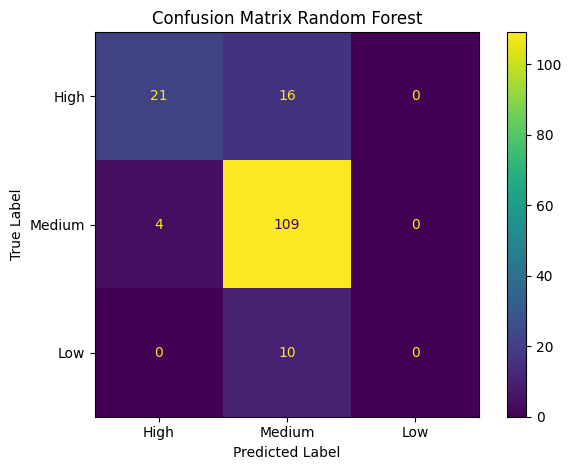

In [ ]:
# ==========================================
# CONFUSION MATRIX RANDOM FOREST
# ==========================================

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Prediksi data testing
y_pred_rf = model_rf.predict(X_test)

# Urutan label disamakan dengan contoh Anda
label_urut = ["High", "Medium", "Low"]

cm_rf = confusion_matrix(
    y_test,
    y_pred_rf,
    labels=label_urut
)

disp_rf = ConfusionMatrixDisplay(
    confusion_matrix=cm_rf,
    display_labels=label_urut
)

disp_rf.plot()
plt.title("Confusion Matrix Random Forest")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.tight_layout()
plt.show()

# Low masih rendah -> BalancedRandomForestClassifier

In [ ]:

!pip -q install imbalanced-learn

import pandas as pd
from imblearn.ensemble import BalancedRandomForestClassifier
from imblearn.pipeline import Pipeline as ImbPipeline
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    f1_score
)

# Balanced Random Forest
model_brf = ImbPipeline([
    ("preprocessing", preprocessor),
    ("model", BalancedRandomForestClassifier(
        n_estimators=300,
        sampling_strategy="all",
        replacement=True,
        random_state=42,
        n_jobs=-1
    ))
])

# Training hanya dengan data training
model_brf.fit(X_train, y_train)

# Prediksi data testing
y_pred_brf = model_brf.predict(X_test)

labels = ["Low", "Medium", "High"]

print("=== DISTRIBUSI PREDIKSI ===")
print(
    pd.Series(y_pred_brf)
    .value_counts()
    .reindex(labels, fill_value=0)
)

print("\n=== CLASSIFICATION REPORT ===")
print(classification_report(
    y_test,
    y_pred_brf,
    labels=labels,
    zero_division=0
))

print("\n=== CONFUSION MATRIX ===")
display(pd.DataFrame(
    confusion_matrix(y_test, y_pred_brf, labels=labels),
    index=[f"Aktual {x}" for x in labels],
    columns=[f"Prediksi {x}" for x in labels]
))

print("Accuracy:", round(accuracy_score(y_test, y_pred_brf), 4))
print("Macro F1:", round(f1_score(
    y_test,
    y_pred_brf,
    labels=labels,
    average="macro",
    zero_division=0
), 4))


=== DISTRIBUSI PREDIKSI ===
Low       34
Medium    81
High      45
Name: count, dtype: int64

=== CLASSIFICATION REPORT ===
              precision    recall  f1-score   support

         Low       0.18      0.60      0.27        10
      Medium       0.91      0.65      0.76       113
        High       0.71      0.86      0.78        37

    accuracy                           0.70       160
   macro avg       0.60      0.71      0.61       160
weighted avg       0.82      0.70      0.74       160


=== CONFUSION MATRIX ===


,Prediksi Low,Prediksi Medium,Prediksi High
Aktual Low,6,4,0
Aktual Medium,26,74,13
Aktual High,2,3,32


Accuracy: 0.7
Macro F1: 0.6054


,Prediksi Low,Prediksi Medium,Prediksi High
Aktual Low,6,4,0
Aktual Medium,26,74,13
Aktual High,2,3,32


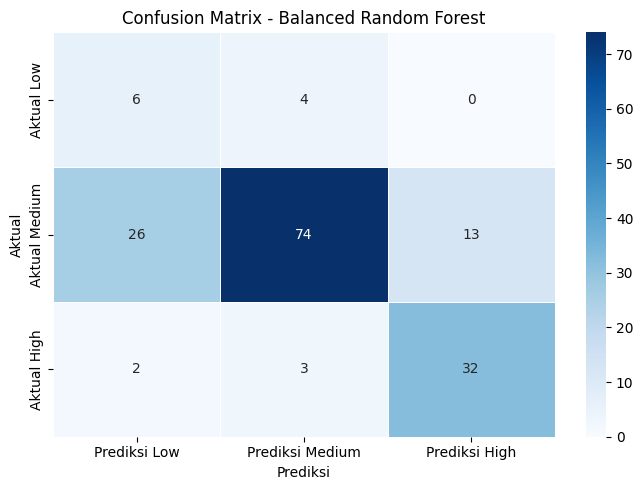

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Urutan kelas
labels = ["Low", "Medium", "High"]

# Hitung confusion matrix
cm = confusion_matrix(
    y_test,
    y_pred_brf,
    labels=labels
)

# Tampilkan dalam tabel
cm_df = pd.DataFrame(
    cm,
    index=[f"Aktual {x}" for x in labels],
    columns=[f"Prediksi {x}" for x in labels]
)

display(cm_df)

# Visualisasi confusion matrix
plt.figure(figsize=(7, 5))

sns.heatmap(
    cm_df,
    annot=True,
    fmt="d",
    cmap="Blues",
    linewidths=0.5,
    cbar=True
)

plt.title("Confusion Matrix - Balanced Random Forest")
plt.xlabel("Prediksi")
plt.ylabel("Aktual")
plt.tight_layout()
plt.show()


# Perbandingan RF Class Weight dengan Balanced RF Classifier

,Model,Accuracy,Macro F1,Recall Low,Precision Low,F1 Low,Recall Medium,Recall High
0,RF class_weight balanced,0.8125,0.5188,0.0,0.0000,0.0000,0.9646,0.5676
1,Balanced Random Forest,0.7000,0.6054,0.6,0.1765,0.2727,0.6549,0.8649


=== RANDOM FOREST: CLASS WEIGHT ===
              precision    recall  f1-score   support

         Low       0.00      0.00      0.00        10
      Medium       0.81      0.96      0.88       113
        High       0.84      0.57      0.68        37

    accuracy                           0.81       160
   macro avg       0.55      0.51      0.52       160
weighted avg       0.76      0.81      0.78       160

=== BALANCED RANDOM FOREST ===
              precision    recall  f1-score   support

         Low       0.18      0.60      0.27        10
      Medium       0.91      0.65      0.76       113
        High       0.71      0.86      0.78        37

    accuracy                           0.70       160
   macro avg       0.60      0.71      0.61       160
weighted avg       0.82      0.70      0.74       160



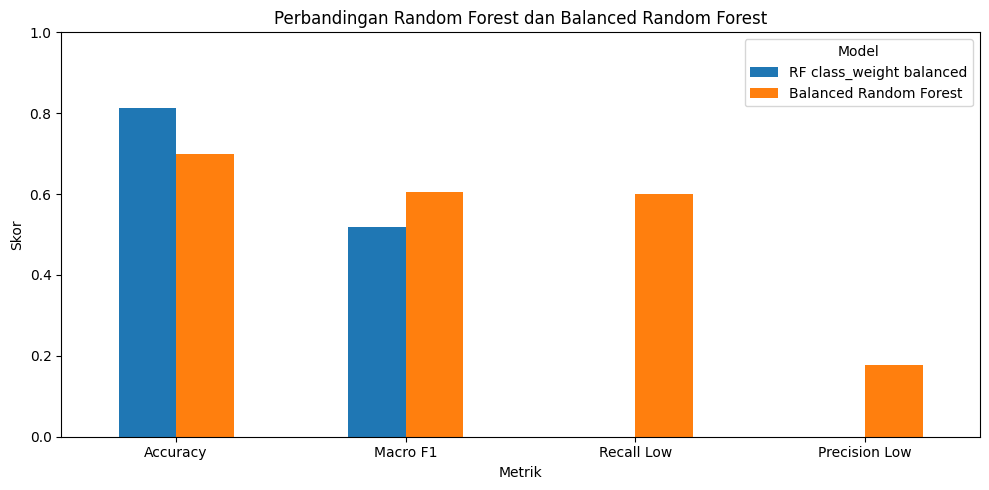

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    precision_score,
    recall_score,
    classification_report,
    confusion_matrix
)

labels = ["Low", "Medium", "High"]

# --------------------------------------
# 1. Prediksi kedua model
# --------------------------------------
y_pred_rf = model_rf.predict(X_test)
y_pred_brf = model_brf.predict(X_test)

# --------------------------------------
# 2. Fungsi evaluasi
# --------------------------------------
def evaluasi_model(nama, y_true, y_pred):
    report = classification_report(
        y_true,
        y_pred,
        labels=labels,
        output_dict=True,
        zero_division=0
    )

    return {
        "Model": nama,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Macro F1": f1_score(
            y_true, y_pred,
            labels=labels,
            average="macro",
            zero_division=0
        ),
        "Recall Low": report["Low"]["recall"],
        "Precision Low": report["Low"]["precision"],
        "F1 Low": report["Low"]["f1-score"],
        "Recall Medium": report["Medium"]["recall"],
        "Recall High": report["High"]["recall"]
    }

# --------------------------------------
# 3. Tabel perbandingan
# --------------------------------------
hasil_perbandingan = pd.DataFrame([
    evaluasi_model(
        "RF class_weight balanced",
        y_test, y_pred_rf
    ),
    evaluasi_model(
        "Balanced Random Forest",
        y_test, y_pred_brf
    )
])

display(hasil_perbandingan.round(4))

# --------------------------------------
# 4. Classification report
# --------------------------------------
print("=== RANDOM FOREST: CLASS WEIGHT ===")
print(classification_report(
    y_test, y_pred_rf,
    labels=labels,
    zero_division=0
))

print("=== BALANCED RANDOM FOREST ===")
print(classification_report(
    y_test, y_pred_brf,
    labels=labels,
    zero_division=0
))

metrik = [
    "Accuracy",
    "Macro F1",
    "Recall Low",
    "Precision Low"
]

plot_df = hasil_perbandingan.set_index("Model")[metrik]

ax = plot_df.T.plot(
    kind="bar",
    figsize=(10, 5)
)

ax.set_title("Perbandingan Random Forest dan Balanced Random Forest")
ax.set_ylabel("Skor")
ax.set_xlabel("Metrik")
ax.set_ylim(0, 1)
ax.legend(title="Model")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


In [ ]:
# ==========================================
# EVALUASI SUPPORT VECTOR MACHINE (SVM)
# ==========================================

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)
import pandas as pd

# Prediksi data testing
y_pred_svm = model_svm.predict(X_test)

# Hitung metrik evaluasi
akurasi_svm = accuracy_score(y_test, y_pred_svm)
presisi_svm = precision_score(
    y_test, y_pred_svm,
    average="macro", zero_division=0
)
recall_svm = recall_score(
    y_test, y_pred_svm,
    average="macro", zero_division=0
)
f1_svm = f1_score(
    y_test, y_pred_svm,
    average="macro", zero_division=0
)

print("=" * 50)
print("EVALUASI SUPPORT VECTOR MACHINE (SVM)")
print("=" * 50)

print(f"Akurasi         : {akurasi_svm:.4f} ({akurasi_svm*100:.2f}%)")
print(f"Macro Precision : {presisi_svm:.4f}")
print(f"Macro Recall    : {recall_svm:.4f}")
print(f"Macro F1-score  : {f1_svm:.4f}")

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_svm,
    labels=["Low", "Medium", "High"],
    zero_division=0
))

print("Confusion Matrix:")
display(pd.DataFrame(
    confusion_matrix(
        y_test,
        y_pred_svm,
        labels=["Low", "Medium", "High"]
    ),
    index=["Aktual Low", "Aktual Medium", "Aktual High"],
    columns=["Prediksi Low", "Prediksi Medium", "Prediksi High"]
))

EVALUASI SUPPORT VECTOR MACHINE (SVM)
Akurasi         : 0.7125 (71.25%)
Macro Precision : 0.5799
Macro Recall    : 0.6760
Macro F1-score  : 0.6016

Classification Report:
              precision    recall  f1-score   support

         Low       0.22      0.50      0.30        10
      Medium       0.88      0.69      0.77       113
        High       0.65      0.84      0.73        37

    accuracy                           0.71       160
   macro avg       0.58      0.68      0.60       160
weighted avg       0.78      0.71      0.73       160

Confusion Matrix:


,Prediksi Low,Prediksi Medium,Prediksi High
Aktual Low,5,5,0
Aktual Medium,18,78,17
Aktual High,0,6,31


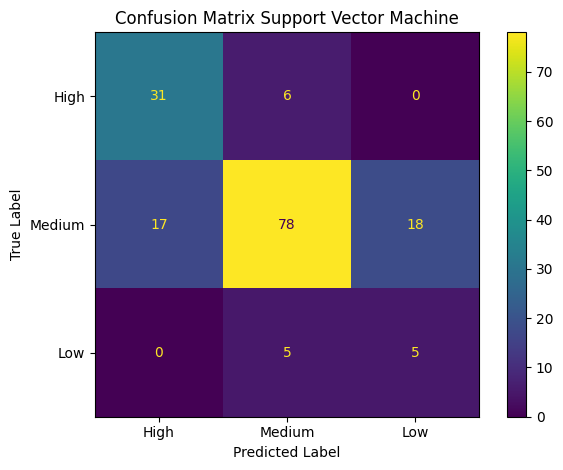

In [ ]:
# ==========================================
# CONFUSION MATRIX SUPPORT VECTOR MACHINE
# ==========================================

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Prediksi data testing
y_pred_svm = model_svm.predict(X_test)

label_urut = ["High", "Medium", "Low"]

cm_svm = confusion_matrix(
    y_test,
    y_pred_svm,
    labels=label_urut
)

disp_svm = ConfusionMatrixDisplay(
    confusion_matrix=cm_svm,
    display_labels=label_urut
)

disp_svm.plot()
plt.title("Confusion Matrix Support Vector Machine")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.tight_layout()
plt.show()

# Perbandingan Evaluasi Model

In [ ]:
import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report
)

labels = ["Low", "Medium", "High"]

# Pastikan variabel prediksi sudah tersedia:
# y_pred_rf  = prediksi RF class_weight balanced
# y_pred_brf = prediksi Balanced Random Forest
# y_pred_svm = prediksi SVM class_weight balanced

def evaluasi_model(nama, y_true, y_pred):
    report = classification_report(
        y_true,
        y_pred,
        labels=labels,
        output_dict=True,
        zero_division=0
    )

    return {
        "Model": nama,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Macro F1": f1_score(
            y_true,
            y_pred,
            labels=labels,
            average="macro",
            zero_division=0
        ),
        "Recall Low": report["Low"]["recall"],
        "Precision Low": report["Low"]["precision"],
        "F1 Low": report["Low"]["f1-score"],
        "Recall Medium": report["Medium"]["recall"],
        "Recall High": report["High"]["recall"]
    }

# Buat tabel perbandingan berdasarkan hasil aktual
tabel_perbandingan = pd.DataFrame([
    evaluasi_model(
        "RF class_weight balanced",
        y_test,
        y_pred_rf
    ),
    evaluasi_model(
        "Balanced Random Forest",
        y_test,
        y_pred_brf
    ),
    evaluasi_model(
        "SVM class_weight balanced",
        y_test,
        y_pred_svm
    )
])

# Format angka agar mudah dibaca
display(tabel_perbandingan.round(4))


,Model,Accuracy,Macro F1,Recall Low,Precision Low,F1 Low,Recall Medium,Recall High
0,RF class_weight balanced,0.8125,0.5188,0.0,0.0000,0.0000,0.9646,0.5676
1,Balanced Random Forest,0.7000,0.6054,0.6,0.1765,0.2727,0.6549,0.8649
2,SVM class_weight balanced,0.7125,0.6016,0.5,0.2174,0.3030,0.6903,0.8378
